# From Rising Tides to Broken Streets: Linking Flood Frequency & Pavement Cracking Under Projected Sea-Level Rise in The Hague, Norfolk, VA
## OEAS 805 Final Project Report Draft Notebook 1 (NB01
### Jupyter Notebook by Nick Carpenter for OEAS 805: Advanced Environmental Data Science (Fall 2026)

Chronic high-tide ("sunny-day") flooding is becoming more frequent in Norfolk, VA, as relative sea level (RSL) rises (Ezer, 2022). Water that saturates a road's foundation weakens it, and traffic then cracks the surface (Elseifi et al., 2022; Gaspard et al., 2007; Knott et al., 2017). This notebook performs the analysis and generates the figures for the final project report. It addresses two research questions:

1. **Present-day relationship (2025).** Does chronic tidal flood frequency significantly affect pavement crack density after controlling for traffic volume and surface type?
   - *H₀:* β₁ = 0; flood frequency is not associated with crack density after accounting for traffic/surface class.
   - *H₁:* β₁ > 0; cells that flood more often are more cracked.

   β₁ is the flood coefficient of the fractional logit model, eq. (2) below.
2. **Projections (2040–2080).** How could projected relative sea-level rise (RSLR) increase pavement cracking if all other conditions stay constant?

**Approach in brief.**

- A 2 cm uncrewed aircraft system (UAS) orthomosaic and a crack map classified from it give the crack density of every 5 m × 5 m pavement cell.
- A UAS digital elevation model (DEM), a tidal-datum surface, and an empirical tide-gauge equation (Ezer, 2022) give each cell's modeled flood frequency (days flooded per year) for 2025, 2040, 2060, and 2080 under the National Oceanic and Atmospheric Administration (NOAA) 2017 Intermediate-High scenario (Sweet et al., 2017).
- A fractional logistic regression ("fractional logit") relates crack density to flood frequency, with traffic/surface class as a control. Its standard errors (SEs) and its evaluation account for spatial autocorrelation, and four alternative models are compared with it.
- The fitted relationship is applied to each cell's projected flood frequency.

The projections stop at 2080 because, by then, about 98% of the pavement lies below that year's mean higher high water (MHHW) and floods almost daily (03.1).

The notebook includes only the loading and cleaning steps that the analysis needs, with short descriptions and summaries of each dataset.

---

### Note on the Maps in This Notebook

> **The maps in this notebook are basic, code-only ("hands-off") versions of the report maps.** The report versions were made by hand in ArcGIS Pro from the same data (the clean and result datasets that this notebook writes to `DATA`), because ArcGIS Pro offers better cartography (label placement, layout, and symbol control) than `matplotlib` and `geopandas`. The maps here therefore demonstrate and check the data, and a printed note starting with *** precedes each one. A second note marks every supplementary figure (FigS##) as not part of the main report. The non-map charts (e.g., the sea-level plot and the model plots) are the report versions.

---

**Notebook sections:**

| Section | Purpose |
|---|---|
| **00 Setup** | Packages, settings, folders, and shared helper functions |
| **01 Data Loading & Cleaning** | Every dataset loaded from its application programming interface (API) or from `DATA/01_Raw_Data_Custom`, described, cleaned onto one grid, and summarized |
| **02 Study Area & Sea-Level Context** | The observed and projected RSL at Sewells Point and the study-area map (Introduction figures) |
| **03 Projected Flood Frequency (2040–2080)** | Flood frequency for every projection year, with the same equation as for 2025 (2100 shown for context) |
| **04 Analysis Cells & Variables** | 5 m analysis cells with crack density, flood frequency, traffic, and surface class; Methods maps (Fig03 and Fig04) |
| **05 Crack Density vs. Flood Frequency (2025)** | Group comparisons, spatial autocorrelation, the regression models and their evaluation, and the fitted model (Fig05) |
| **06 Projected Crack Density (2040–2080)** | The fitted relationship applied to the projected flood frequency of every cell; the projection summary (Fig06) and the Results maps (Fig07 and Fig08) |
| **07 Summary & Conclusions** | Key numbers, saved outputs, and conclusions |

**Where each part of the report is in this notebook:**

| Report section | Notebook | Figures and tables |
|---|---|---|
| 1. Introduction | 01.8 (sea-level record and projections) and 02 | Fig01 and Fig02 |
| 2.1 Study Area, Data Collection, and Processing (eq. 1) | 01 (data, crack-map accuracy, and flood frequency), 03 (projected flood frequency), and 04 (analysis cells) | Fig03 and Fig04 |
| 2.2 Model Development (eqs. 2 and 3) | 05.3 (Steps A–D), 05.4, 06.1, and 06.2 | Fig05 and Fig06 |
| 2.3 Model Evaluation | 05.2 (spatial autocorrelation) and 05.3 (Steps B–I: spatially robust SEs, cross-validation (CV), and model comparison) | FigS09, TblS01, and TblS02 |
| 3.1 Model Performance | 05.3 (Steps F–H) | TblS02 |
| 3.2 Present-Day Crack Density vs. Flood Frequency (2025) | 05.3 (Steps D, G, and H) and 05.4 | Fig05 and TblS01 |
| 3.3 Projected Crack Density (2040–2080) | 03, 06.1, and 06.3 | Fig06, Fig07, Fig08, and TblS03 |
| 4. Conclusions | 07 | |

**Symbols (as in the report).**

Eq. (1), flood frequency (Ezer, 2022):

`F = 365·(P / 100) = 365·(10^A / 100);   A = 0.02·Y − 2.4·(Z_MHHW − RSLR_t) − 39.6`

- *F*: flood frequency, the number of days flooded per year (function `flood_days`; per cell, the geometric mean of its pixels, field `FloodDaysGeo_<year>`).
- *P*: percent of time flooded, 10^*A*, capped at 100%.
- *A*: exponent of the flood equation.
- *Y*: year.
- *Z*_MHHW: elevation above MHHW of each 0.5 m DEM pixel (m; field `ElevMHHW` per cell).
- *RSLR*_t: RSL of year *t* under the NOAA (2017) Intermediate-High scenario, in meters above the North American Vertical Datum of 1988 (NAVD88) (`RSLR_BY_YEAR`).

Eq. (2), fractional logit (primary model, M1):

`ŷ(F, γ_c) = 1 / [1 + e^(−(β₀ + β₁·log₁₀(F) + γ_c))]`

- *ŷ*: expected crack density, the share of a cell's pavement that is cracked.
- *β*₀: intercept (`BETA_0`).
- *β*₁: change in log-odds per tenfold increase in *F* (`BETA_1`).
- *γ*_c: log-odds shift of traffic/surface class *c* relative to the reference class, sidewalk/driveway (`GAMMA_C`).
- log₁₀(*F*): field `LogFloodDays_<year>`.

Eq. (3), delta-change projection (Hay et al., 2000):

`ŷ*_(i,t) = min(1, max(0, y_(i,2025) + [μ_(i,t) − μ_(i,2025)]))`

- *ŷ**_(i,t): projected crack density of cell *i* in year *t* (field `CrackProj_<year>`).
- *y*_(i,2025): observed 2025 crack density of cell *i* (field `CrackDens`).
- *μ*_(i,t) and *μ*_(i,2025): crack density from eq. (2) for cell *i* with the flood frequency of year *t* and of 2025 (`mu_t` and `MU_2025` in 06.1).
- min/max: keep the result between 0 and 1.

**Number formats.** Tables and figures use the report's precision: proportions and crack densities to 3 decimals (or percentages to 1), flood frequency to 1 decimal, sea level to 2, coefficients, SEs, and odds ratios to 2, R², root mean squared error (RMSE), and mean absolute error (MAE) to 3, and p-values as "< 0.001" or to 3 decimals.

**Code-cell labels.** Every code cell is one step, headed `NN.N (Step X) — what it does`. The letters restart in each subsection.

**Software.** Python with `numpy`, `pandas`, `geopandas`, `shapely`, `rasterio`, `scipy`, `statsmodels` (Seabold & Perktold, 2010), `scikit-learn` (Pedregosa et al., 2011), `libpysal` and `esda` (PySAL; Rey & Anselin, 2007), and `matplotlib` (Hunter, 2007), plus Esri's Limited Error Raster Compression (LERC) decoder (Esri, 2026b).

**Figures and tables of the report.** They are saved only when the switches in 00.2 are `True`. Each goes to the `FIGURES` folder of its report section. The supplementary figures (FigS##) check the outputs as the notebook progresses, and the supplementary tables (TblS##) are images of the main result tables; neither is part of the report's main text:

| Figure | Report section (folder) | Shows |
|---|---|---|
| Fig01 | Introduction (`FIGURES/01_Intro_Figures`) | Observed RSL at Sewells Point and the NOAA (2017) projections |
| Fig02 | Introduction (`FIGURES/01_Intro_Figures`) | Study area: UAS imagery and flight footprint, a regional-context map with the Sewells Point tide gauge, and a zoomed view of the Botetourt St & Mowbray Arch intersection |
| Fig03 | Methods (`FIGURES/02_Methods_Figures`) | Deep-learning (DL) crack classification workflow at the Botetourt St & Mowbray Arch intersection, with the classified cracks over the whole study area |
| Fig04 | Methods (`FIGURES/02_Methods_Figures`) | The 5 m analysis cells by traffic/surface class |
| Fig05 | Methods (`FIGURES/02_Methods_Figures`) | Fractional logit model: crack density vs. flood frequency, with the fitted curves and the model equation |
| Fig06 | Methods (`FIGURES/02_Methods_Figures`) | Projected flood frequency and mean crack density by year, with the uncertainty band |
| Fig07 | Results (`FIGURES/03_Results_Figures`) | Modeled flood frequency of the analysis cells: 2025, 2040, 2060, and 2080 |
| Fig08 | Results (`FIGURES/03_Results_Figures`) | Observed (2025) and projected (2040, 2060, and 2080) crack density of the analysis cells |
| FigS01 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Visual check: modeled flood frequency (2025) over the imagery |
| FigS02 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Visual check: annual average daily traffic (AADT) polygon and sidewalk/driveway surface over the imagery |
| FigS03 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Visual check: crack raster, pavement mask, and accuracy points |
| FigS04 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Confusion matrix of the crack map at the accuracy points |
| FigS05 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Visual check: distribution of the pavement's flood frequency, 2025–2100 |
| FigS06 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Visual check: the 5 m analysis cells |
| FigS07 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Visual check: distributions of the per-cell study variables |
| FigS08 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Mean crack density by traffic class and by flood-frequency class, with logistic fits |
| FigS09 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Model evaluation: spatial autocorrelation and spatial CV predictions |
| FigS10 | Supplementary (`FIGURES/04_Supplementary_Figures`) | Visual check: the 0.5 m flood-frequency rasters, 2025, 2040, 2060, and 2080 (for comparison with Fig07) |
| TblS01 | Supplementary (`FIGURES/05_Supplementary_Tbl_Figs`) | Coefficients of the primary model with independent-cell and spatially robust p-values (05.3 Step D) |
| TblS02 | Supplementary (`FIGURES/05_Supplementary_Tbl_Figs`) | The five models compared and their evaluation summary (05.3 Step F) |
| TblS03 | Supplementary (`FIGURES/05_Supplementary_Tbl_Figs`) | Projected flood frequency and mean crack density by year (06.1 Step A) |

**How to run.** Activate the `oes805_proj` environment, set the project folder in **00.2 (Step A)**, and run the cells from top to bottom. The slow steps (counting the 2 cm crack raster and building the imagery preview) and all API downloads are cached after the first run.

## Acronyms

| Acronym | Meaning |
|---|---|
| AADT | Annual average daily traffic (vehicles/day) |
| API | Application programming interface |
| CI | Confidence interval |
| CO-OPS | NOAA Center for Operational Oceanographic Products and Services |
| CRS | Coordinate reference system |
| CV | Cross-validation |
| DEM | Digital elevation model |
| DL | Deep learning |
| EPSG | European Petroleum Survey Group (coordinate-system codes) |
| GLM | Generalized linear model |
| HAC | Heteroskedasticity- and autocorrelation-consistent (standard errors) |
| HCDEM | Hydro-corrected DEM |
| HED | Holistically-Nested Edge Detection |
| LERC | Limited Error Raster Compression |
| LiDAR | Light Detection and Ranging |
| MAE | Mean absolute error |
| MHHW | Mean higher high water |
| MSL | Mean sea level |
| MTFCC | MAF/TIGER Feature Class Code (U.S. Census road type) |
| NAD83 | North American Datum of 1983 |
| NAVD88 | North American Vertical Datum of 1988 |
| NOAA | National Oceanic and Atmospheric Administration |
| OLS | Ordinary least squares |
| PAEK | Polynomial Approximation with Exponential Kernel (line smoothing) |
| RCL | Road centerlines |
| REST | Representational state transfer (web-service interface) |
| RGB | Red, green, and blue |
| RMSE | Root mean squared error |
| RSL | Relative sea level |
| RSLR | Relative sea-level rise |
| SAM3 | Segment Anything Model 3 |
| SE | Standard error |
| UAS | Uncrewed aircraft system |
| USACE | U.S. Army Corps of Engineers |
| VDOT | Virginia Department of Transportation |
| VGG-19 | 19-layer Visual Geometry Group network |
| VGIN | Virginia Geographic Information Network |

## Input Data Sources

**Project spatial reference:** the UAS orthomosaic (`Imagery_dry`). Every dataset is (1) filtered to the orthomosaic's extent, (2) reprojected to its coordinate reference system (CRS: NAD83(2011) / Virginia South, i.e., the North American Datum of 1983 (NAD83) State Plane zone, EPSG:6594, in meters; vertical datum NAVD88, EPSG:5703), and (3) for rasters, snapped to its 0.02 m pixel grid.

Full citations are in the **References** cell below.

**Primary data (project-collected, Old Dominion University).** Both are read through the Representational State Transfer (REST) endpoints of tiled image services, which return LERC-compressed tiles.

- **Hague 2025 Dry RGB Imagery** (Steiner, 2026b)
  - 3-band red, green, and blue (RGB; 8-bit) orthomosaic at **0.02 m** from a **low-tide UAS flight on October 3, 2025** (DJI Mavic 3 Multispectral).
  - Item: <https://www.arcgis.com/home/item.html?id=ac0a20f8293143c191a5039b6f161cbe>
  - REST: `https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/Hague_2025_Dry_RGB_Imagery/ImageServer`
- **Hague 2025 Digital Elevation Model** (Steiner, 2026a)
  - 1-band, 32-bit float elevations (m, NAVD88) at **0.5 m** from a Light Detection and Ranging (LiDAR) survey of the same day (Rock R3 Pro V2 on a DJI Matrice 350).
  - Item: <https://www.arcgis.com/home/item.html?id=c7e6e2c791fc4cc895db55a59be804a6>
  - REST: `https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/ESLRClip_hague2025_DEM_1/ImageServer`

**External data (downloaded through the APIs for the study-area extent only):**

- **NOAA VDatum Conversion** (NOAA et al., 2026)
  - Each pixel is the MHHW tidal datum expressed as an elevation in NAVD88 meters (pixels of about 40 m × 50 m).
  - REST: `https://tiledimageservices.arcgis.com/P3ePLMYs2RVChkJx/arcgis/rest/services/NOAA_VDatum_Conversion/ImageServer`
- **Virginia Road Centerlines (RCL), layer "< 50,000" (ID 5)** (Virginia Geographic Information Network [VGIN], 2026)
  - Road centerlines carrying the Virginia Department of Transportation (VDOT) traffic volume **`VDOT_AADT`** (vehicles/day).
  - REST: `https://vginmaps.vdem.virginia.gov/arcgis/rest/services/VA_Base_Layers/VBMP_RCL/FeatureServer/5`
- **City of Norfolk Driveways** (City of Norfolk, 2022a)
  - Polygons digitized from 2006/2008 aerial photography; part of the sidewalk/driveway surface.
  - REST: `https://gisshare.norfolk.gov/pubserver/rest/services/OpenData/Public_Works/FeatureServer/2`
- **Observed monthly mean sea level, Sewells Point (station 8638610)** (NOAA Center for Operational Oceanographic Products and Services [CO-OPS], 2026)
  - Verified monthly mean water levels (mean sea level [MSL] datum), 1927 to present, from the CO-OPS Data API. The seasonal cycle is removed, and the linear trend is fitted in this notebook.
  - API: `https://api.tidesandcurrents.noaa.gov/api/prod/datagetter?product=monthly_mean&station=8638610&datum=MSL&units=metric&format=csv`
  - NOAA's published trend, for comparison: `https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/sealvltrends.json?station=8638610&affil=US`
- **NOAA (2017) sea-level-rise scenarios, Sewells Point** (NOAA CO-OPS, 2026; Sweet et al., 2017)
  - Intermediate, Intermediate-High, and High scenarios with their likely ranges for the sea-level figure.
  - API: `https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/slr_projections.json?station=8638610&report_year=2017`
- **NOAA (2017) Intermediate-High scenario used in the flood model** (U.S. Army Corps of Engineers [USACE], 2022)
  - The 10-value table from the USACE Sea-Level Change Curve Calculator, including local subsidence in Norfolk. It is short, so it is coded in 00.5 (Step D).
- **Sewells Point station location and tidal datums** (NOAA CO-OPS, 2026)
  - Location (for the locator map): `https://api.tidesandcurrents.noaa.gov/mdapi/prod/webapi/stations/8638610.json`
  - Datums (MSL and NAVD88 on the station datum, to express the sea-level figure in meters above NAVD88): `https://api.tidesandcurrents.noaa.gov/mdapi/prod/webapi/stations/8638610/datums.json?units=metric`
- **Basemap** (Esri, 2026d): World Light Gray Canvas base and reference layers, requested as cached map tiles (`<service>/tile/<level>/<row>/<col>`) for the map extent only, with the MapServer `export` operation as a fallback. It is used for display only.

**Custom data (made by the author; provided in `DATA/01_Raw_Data_Custom` and never modified; Carpenter, 2026).** How each was made is described where it is loaded (Section 01).

- **`Road_Mask_Final_Shrunk3.tif`**: pavement (road and sidewalk/driveway) mask on the 0.02 m imagery grid (1 = pavement).
- **`Cracks_Classified_Combined_Shrunk.tif`**: crack map on the imagery grid (1 = crack; 0 = no crack).
- **`Training_masked_imagery_PaveCracksDetect_Edited.shp`** : the labeled training lines of the crack model, used only to draw the crack-detection workflow figure (Fig03) for the methods section.
- **`Custom_AccuracyPts_Labeled_2025Hague_20261003.shp`**: 150 accuracy points to assess the crack classification DL model output, labeled by eye on the imagery.
- **`Custom_Sidewalk_2025Hague.shp`**: sidewalk surface polygons digitized on the 2025 imagery, using City of Norfolk sidewalk lines as a base (City of Norfolk, 2022b).
- **`Custom_AddRCL_2025Hague.shp`**: centerlines for minor roads and parking-lot lanes that VGIN does not map.
- **`WaterSurface_Final.shp`**: open-water surface removed from the DEM.

## References 

### **Data Sets**

Carpenter, N. (2026). Hague 2025 road-cracking project: Custom data sets (Cracks_Classified_Combined_Shrunk, Road_Mask_Final_Shrunk3, Training_masked_imagery_PaveCracksDetect_Edited, Custom_AccuracyPts_Labeled_2025Hague_20261003, Custom_Sidewalk_2025Hague, Custom_AddRCL_2025Hague, and WaterSurface_Final) [Data set]. Old Dominion University. Unpublished.

Chen, Y.-H. (2023). HCDEM: Hydro-corrected DEM with 1 meter resolution [Data set]. *ESRI ArcGIS Online*. Retrieved from https://www.arcgis.com/home/item.html?id=f4fe88d43aa948fba1c0cae88e4a5376

City of Norfolk. (2022a). Driveway - City of Norfolk [Data set]. *Norfolk GIS Open Data*. Retrieved from https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::driveway-city-of-norfolk/about

City of Norfolk. (2022b). Sidewalk - City of Norfolk [Data set]. *Norfolk GIS Open Data*. Retrieved from https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::sidewalk-city-of-norfolk/about

Eagle Technology Group Ltd. (2026). Segment Anything Model 3 (SAM3) [Data set]. *ESRI ArcGIS Living Atlas of the World*. Retrieved from https://www.arcgis.com/home/item.html?id=37ef2e1ba0c042ce99501f56295ec0d4

Esri. (2026d). World Light Gray Canvas base and reference [Basemap service]. *ArcGIS Online*. Retrieved from https://services.arcgisonline.com/arcgis/rest/services/Canvas/World_Light_Gray_Base/MapServer

ESRI Analytics. (2026). Pavement Crack Detection [Data set]. *ESRI ArcGIS Living Atlas of the World*. Retrieved from https://www.arcgis.com/home/item.html?id=a9c3134e361e49a191efda169f5a337d

National Oceanic and Atmospheric Administration (NOAA) Center for Operational Oceanographic Products and Services (CO-OPS). (2026). CO-OPS Data API, Derived Product API, and Metadata API [Data set]. *Monthly Mean Water Levels, Sea Level Trends, Sea Level Rise Projections, & Metadata (Location and Datums): Station 8638610 Sewells Point, Virginia*. Retrieved from https://api.tidesandcurrents.noaa.gov/

National Oceanic and Atmospheric Administration (NOAA), National Ocean Service (NOS), & ESRI Oceans. (2026). NOAA VDatum Conversion [Data set]. *ESRI ArcGIS Living Atlas of the World*. Retrieved from https://www.arcgis.com/home/item.html?id=a7238c20bfc445be97b3d32a49e5b363

Steiner, B. (2026a). Hague 2025 Digital Elevation Model [Data set]. *ESRI ArcGIS Online*. Retrieved from https://www.arcgis.com/home/item.html?id=c7e6e2c791fc4cc895db55a59be804a6

Steiner, B. (2026b). Hague 2025 Dry RGB Imagery [Data set]. *ESRI ArcGIS Online*. Retrieved from https://www.arcgis.com/home/item.html?id=ac0a20f8293143c191a5039b6f161cbe

U.S. Army Corps of Engineers. (2022). Sea-Level Change Curve Calculator (Version 2022.72) [Data set]. Retrieved May 28, 2024, from https://cwbi-app.sec.usace.army.mil/rccslc/slcc_calc.html

Virginia Geographic Information Network (VGIN). (2026). Virginia Road Centerlines (RCL); VBMP_RCL feature service, layer 5 [Data set]. *Virginia GIS Clearinghouse*. Retrieved from https://vgin.vdem.virginia.gov/datasets/cd9bed71346d4476a0a08d3685cb36ae/about


### **Literature, Methods, & Software**

Breiman, L. (2001). Random Forests. *Machine Learning*, *45*(1), 5–32. https://doi.org/10.1023/a:1010933404324

Brewer, C. A., & Pickle, L. (2002). Evaluation of Methods for Classifying Epidemiological Data on Choropleth Maps in Series. *Annals of the Association of American Geographers*, *92*(4), 662–681. https://doi.org/10.1111/1467-8306.00310

Carion, N., Gustafson, L., Hu, Y.-T., Debnath, S., Hu, R., Suris, D., et al. (2025, November 20). SAM 3: Segment Anything with Concepts. Retrieved from https://arxiv.org/abs/2511.16719

Cattaneo, M. D., Crump, R. K., Farrell, M. H., & Feng, Y. (2024). On Binscatter. *American Economic Review*, *114*(5), 1488–1514. https://doi.org/10.1257/aer.20221576

Cliff, A. D., & Ord, J. K. (1981). *Spatial Processes*. Pion Ltd.

Cohen, J. (1960). A Coefficient of Agreement for Nominal Scales. *Educational and Psychological Measurement*, *20*(1), 37–46. https://doi.org/10.1177/001316446002000104

Conley, T. G. (1999). GMM estimation with cross sectional dependence. *Journal of Econometrics*, *92*(1), 1–45. https://doi.org/10.1016/s0304-4076(98)00084-0

Crameri, F., Shephard, G. E., & Heron, P. J. (2020). The misuse of color in science communication. *Nature Communications*, *11*(1), 5444. https://doi.org/10.1038/s41467-020-19160-7

Elseifi, M. A., Mousa, M. R., & Gaspard, K. (2022). Impact of the Great Flood of 2016 on the Asphaltic Concrete Road Infrastructure in Louisiana. *Transportation Research Record: Journal of the Transportation Research Board*, *2676*(8), 463–474. https://doi.org/10.1177/03611981221083924

Esri. (2026a). Image Tile. *ArcGIS REST APIs*. Retrieved from https://developers.arcgis.com/rest/services-reference/enterprise/image-tile/

Esri. (2026b). LERC: Limited Error Raster Compression [Software]. *GitHub*. Retrieved from https://github.com/Esri/lerc

Esri. (2026c). Query (Feature Service/Layer). *ArcGIS REST APIs*. Retrieved from https://developers.arcgis.com/rest/services-reference/enterprise/query-feature-service-layer/

Ezer, T. (2022). A Demonstration of a Simple Methodology of Flood Prediction for a Coastal City Under Threat of Sea Level Rise: The Case of Norfolk, VA, USA. *Earth's Future*, *10*(9). https://doi.org/10.1029/2022ef002786

Gaspard, K., Martinez, M., Zhang, Z., & Wu, Z. (2007). *Impact of Hurricane Katrina on Roadways in the New Orleans Area* (Technical Assistance Report No. 07-2TA). Louisiana Transportation Research Center. Retrieved from https://www.ltrc.lsu.edu/pdf/2007/07_2ta.pdf

Gill, S. K., & Schultz, J. R. (2001). *Tidal datums and their applications* (NOAA Special Publication NOS CO-OPS 1). Silver Spring, Maryland: National Oceanic and Atmospheric Administration. Retrieved from https://tidesandcurrents.noaa.gov/publications/tidal_datums_and_their_applications.pdf

Hay, L. E., Wilby, R. L., & Leavesley, G. H. (2000). A Comparison of Delta Change and Downscaled GCM Scenarios for Three Mountainous Basins in the United States. *JAWRA Journal of the American Water Resources Association*, *36*(2), 387–397. https://doi.org/10.1111/j.1752-1688.2000.tb04276.x

Hosmer, D. W., Jr., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied Logistic Regression*. Wiley. https://doi.org/10.1002/9781118548387

Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering*, *9*(3), 90–95. https://doi.org/10.1109/mcse.2007.55

Knott, J. F., Elshaer, M., Daniel, J. S., Jacobs, J. M., & Kirshen, P. (2017). Assessing the Effects of Rising Groundwater from Sea Level Rise on the Service Life of Pavements in Coastal Road Infrastructure. *Transportation Research Record: Journal of the Transportation Research Board*, *2639*(1), 1–10. https://doi.org/10.3141/2639-01

Kruskal, W. H., & Wallis, W. A. (1952). Use of Ranks in One-Criterion Variance Analysis. *Journal of the American Statistical Association*, *47*(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441

McCullagh, P., & Nelder, J. A. (1989). *Generalized Linear Models* (2nd ed.). Boston, MA: Springer US. https://doi.org/10.1007/978-1-4899-3242-6

Moran, P. A. P. (1950). Notes on Continuous Stochastic Phenomena. *Biometrika*, *37*(1/2), 17–23. https://doi.org/10.2307/2332142

Newey, W. K., & West, K. D. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix. *Econometrica*, *55*(3), 703–708. https://doi.org/10.2307/1913610

Olofsson, P., Foody, G. M., Herold, M., Stehman, S. V., Woodcock, C. E., & Wulder, M. A. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, *148*, 42–57. https://doi.org/10.1016/j.rse.2014.02.015

Papke, L. E., & Wooldridge, J. M. (1996). Econometric methods for fractional response variables with an application to 401(k) plan participation rates. *Journal of Applied Econometrics*, *11*(6), 619–632. https://doi.org/10.1002/(SICI)1099-1255(199611)11:6<619::AID-JAE418>3.0.CO;2-1

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, *12*, 2825–2830.

Rey, S. J., & Anselin, L. (2007). PySAL: A Python Library of Spatial Analytical Methods. *Review of Regional Studies*, *37*(1). https://doi.org/10.52324/001c.8285

Ritz, C., Baty, F., Streibig, J. C., & Gerhard, D. (2015). Dose-Response Analysis Using R. *PLOS ONE*, *10*(12), e0146021. https://doi.org/10.1371/journal.pone.0146021

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, *40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and Statistical Modeling with Python. In *Proceedings of the Python in Science Conference* (pp. 92–96). SciPy. https://doi.org/10.25080/majora-92bf1922-011

Simonyan, K., & Zisserman, A. (2014, September 4). Very Deep Convolutional Networks for Large-Scale Image Recognition. Retrieved from https://arxiv.org/abs/1409.1556

Spearman, C. (1904). The Proof and Measurement of Association between Two Things. *The American Journal of Psychology*, *15*(1), 72–101. https://doi.org/10.2307/1412159

Stehman, S. V. (2014). Estimating area and map accuracy for stratified random sampling when the strata are different from the map classes. *International Journal of Remote Sensing*, *35*(13), 4923–4939. https://doi.org/10.1080/01431161.2014.930207

Sweet, W. V., Kopp, R., Weaver, C. P., Obeysekera, J. T. B., Horton, R. M., Thieler, E. R., & Zervas, C. E. (2017). *Global and regional sea level rise scenarios for the United States* (NOAA Technical Report NOS CO-OPS 83). Silver Spring, Maryland: National Oceanic and Atmospheric Administration. https://doi.org/10.7289/v5/tr-nos-coops-083

U.S. Census Bureau. (2026, August 20). MAF/TIGER Feature Class Code Definitions. Retrieved September 8, 2026, from https://www.census.gov/library/reference/code-lists/mt-feature-class-codes.html

Wooldridge, J. M. (2010). *Econometric Analysis of Cross Section and Panel Data* (2nd ed.). MIT Press.

Xie, S., & Tu, Z. (2015). Holistically-Nested Edge Detection. In *2015 IEEE International Conference on Computer Vision (ICCV)* (pp. 1395–1403). IEEE. https://doi.org/10.1109/iccv.2015.164

Zervas, C. (2009). *Sea Level Variations of the United States* (NOAA Technical Report NOS CO-OPS 053). Silver Spring, Maryland: National Oceanic and Atmospheric Administration. Retrieved from https://tidesandcurrents.noaa.gov/publications/Tech_rpt_53.pdf

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 00) Setup

- **00.1** imports every package; nothing is imported further down.
- **00.2** holds the **only settings you need to edit**: the project folder and the run switches.
- **00.3** holds the map and figure style (optional to edit), including the map rotations.
- **00.4** holds the analysis settings. These are the defaults the analysis was designed with; change them only to test how sensitive the results are.
- **00.5** holds the data sources and data settings: the custom file names, the API links, the reference grid, the sea-level table, and the flood-model coefficients.
- **00.6** builds the folder paths and deletes this notebook's outputs from the previous run (the caches are kept).
- **00.7** defines the shared helper functions, which need no edits.

Outputs follow the project naming rules:

- Clean data, Section 01 only (rebuilt on every run, except the cached slow products) → `DATA/02_Clean_Data/OUT_DATA_NB01_Sec01/`
- Result data, Sections 03–07 (rebuilt on every run) → `DATA/03_Results_Data/OUT_DATA_NB01_Sec##_<Name>/`
- Figures and table images (only when the save switches are `True`) → `FIGURES/<report section folder>/Fig##_Name_YYYYMMDD_HHMMSS.png` (tables: `TblS##_...`)
- API download cache (kept between runs) → `CODE/scratch_temp/NB01/api_cache/`

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 00.1 Packages

Every package the notebook uses is imported here, once. The one package that is not in the `oes805_proj` environment (`lerc`) is installed automatically if it is missing.

In [1]:
# ---------------------------------------------------------------------
# 00.1 (Step A) — Install (if needed) and import every package used in this notebook
# ---------------------------------------------------------------------
# Every package is in the oes805_proj environment except `lerc` (Esri's decoder for the LERC-compressed tiles of the
# ArcGIS image services), which is pip-installed into the active environment the first time this cell runs.
# `import x` loads a package; `from x import y` loads only the name y from it; `import x as y` gives it a short alias.
import sys                       # sys.executable = the Python program running this notebook
import subprocess                # runs another program (here: pip)
import importlib.util            # find_spec() checks whether a package is installed WITHOUT importing it

AUTO_INSTALL_LERC = True         # True = pip-install the 'lerc' package if it is missing
if importlib.util.find_spec("lerc") is None and AUTO_INSTALL_LERC:
    print("[00.1 A] installing the 'lerc' Python package with pip (one time only) ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "lerc"])
    importlib.invalidate_caches()
# A "list comprehension" [expr for item in list if condition] builds a new list in one line: here, the packages
# that are NOT installed. Note that scikit-learn is imported under the name "sklearn".
_required = ["numpy", "pandas", "matplotlib", "scipy", "requests", "geopandas", "shapely", "pyproj", "rasterio",
             "pyogrio", "lerc", "statsmodels", "sklearn", "libpysal", "esda", "PIL"]
_missing = [p for p in _required if importlib.util.find_spec(p) is None]
if _missing:
    raise ImportError(f"Missing packages: {_missing}. Install them into the oes805_proj environment "
                      f"(conda install ... / pip install lerc) and restart the kernel.")

# Standard library: file paths, folder deletion, JSON, math, timing, run stamp, parallel downloads
import io                        # io.BytesIO wraps downloaded bytes so they can be read like a file
import os
import json                      # read/write JSON text (the format of the REST API responses)
import math
import time
import shutil                    # copy / delete files and folders
import warnings
import textwrap                  # wraps long text onto several lines (table images)
from pathlib import Path         # Path objects join folders with "/" and work on Windows and Linux alike
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor   # runs many downloads at the same time
from contextlib import contextmanager             # @contextmanager turns a function into a "with ...:" block

# numpy (arrays) and pandas (tables, "DataFrames")
import numpy as np
import pandas as pd

# matplotlib: every figure and map
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.patheffects as pe            # outlines ("halos") around lines and text
import matplotlib.font_manager as fm
from matplotlib.transforms import Affine2D      # rotation of rasters on the rotated maps
import matplotlib.text as mtext
import matplotlib.ticker as mticker      # tick spacing (e.g. a minor tick every 10 years)
import matplotlib.legend as mlegend            # legend objects (to measure the height of a legend)
from matplotlib.legend_handler import HandlerTuple  # legend entries made of several symbols side by side
# Offset boxes: small drawings packed together and anchored to a corner of the map (north arrow above scale bar)
from matplotlib.offsetbox import AnchoredOffsetbox, AuxTransformBox, DrawingArea, TextArea, VPacker

# scipy: statistics (rank tests, distributions), curve fitting, and fast neighbor searches
from scipy import stats
from scipy.optimize import curve_fit
from scipy.special import expit             # expit(x) = 1 / (1 + exp(-x)), the logistic function
from scipy.spatial import cKDTree

# requests: HTTP calls to the REST APIs, with automatic retries
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# geopandas / shapely / pyproj: vector data, geometry, and coordinate reference systems (CRS)
import geopandas as gpd
import shapely
from shapely.geometry import box, Point
from shapely import affinity                 # rotate / move geometries
import pyproj
from pyproj import CRS, Transformer

# rasterio: read/write rasters, reproject/resample them, burn polygons into rasters
import rasterio
from rasterio.transform import from_origin
from rasterio.windows import Window
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio import features
from rasterio.io import MemoryFile

# lerc: decodes the LERC-compressed tiles of the ArcGIS tiled image services
import lerc

# PIL (Pillow): decodes the basemap PNG images
from PIL import Image

# statsmodels: generalized linear models (the fractional logit) and their p-values
import statsmodels.api as sm

# scikit-learn: model evaluation (metrics, spatial cross-validation) and the comparison models
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, confusion_matrix,
                             cohen_kappa_score, precision_score, recall_score, f1_score, classification_report)
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# PySAL (libpysal + esda): spatial weights and Moran's I
from libpysal.weights import KNN
from esda.moran import Moran

# Display options: show every column of wide tables; silence harmless numerical notices
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message=".*'Memory' driver is deprecated.*")
import sklearn, statsmodels
print(f"[00.1 A] packages imported (numpy {np.__version__}, pandas {pd.__version__}, geopandas {gpd.__version__}, "
      f"rasterio {rasterio.__version__}, statsmodels {statsmodels.__version__}, scikit-learn {sklearn.__version__})")

[00.1 A] packages imported (numpy 2.4.6, pandas 3.0.6, geopandas 1.1.3, rasterio 1.4.4, statsmodels 0.15.0, scikit-learn 1.9.1)


### 00.2 User Settings

# \*\*\* EDIT THIS CELL BEFORE RUNNING \*\*\*

If you are running this notebook from the GitHub repository, edit only `PROJECT_ROOT` (the folder that holds `CODE`, `DATA`, and `FIGURES`) and leave every other setting as it is. The run switches control only what is re-downloaded, rebuilt, and saved; they don't change any results. With `SAVE_DATA_OUTPUTS = False`, nothing is written to `DATA`: the clean and result data go to the throwaway `CODE/scratch_temp/NB01/unsaved_outputs` folder instead, which still holds the notebook's slow caches (the imagery preview and the crack-pixel counts). `SAVE_SUPPLEMENTARY_FIGURES = True` also saves the table images (TblS01–TblS03).

In [2]:
# ---------------------------------------------------------------------
# 00.2 (Step A) — USER SETTINGS: project folder and run switches  <-- edit before running
# ---------------------------------------------------------------------

# ----- Project folder ----------------------------------------------------------------------------------------------
# Absolute path of the project folder (the one that holds CODE, DATA, and FIGURES). A string written r"..." is a "raw"
# string: backslashes in Windows paths are kept as they are. None = auto-detect (this notebook lives in <project>/CODE).
PROJECT_ROOT = r"C:\Users\..........\OEAS805_ncarp_finalproj"

# ----- Run switches --------------------------------------------------------------------------------------------------
SAVE_DATA_OUTPUTS          = False   # True = write the clean and result data to DATA; False = write nothing to DATA
                                     # (the outputs go to the throwaway CODE/scratch_temp/NB01/unsaved_outputs folder)
CLEAN_BEFORE_RUN           = False   # True = delete this notebook's previous data outputs (except the caches) first
REFRESH_API_DOWNLOADS      = False   # True = re-download from the APIs (otherwise the cached downloads are reused)
FORCE_REBUILD_HEAVY        = False   # True = redo the slow cached steps (imagery preview, crack/mask pixel counts)
SAVE_REPORT_FIGURES        = False   # True = save the report figures (Fig01-Fig08) to FIGURES/01_... to 03_...
SAVE_SUPPLEMENTARY_FIGURES = False   # True = save the supplementary figures (FigS##) to FIGURES/04_Supplementary_Figures
                                     # and the table images (TblS##) to FIGURES/05_Supplementary_Tbl_Figs
DELETE_OLD_FIGURE_VERSIONS = False   # True = when a figure is saved, delete its copies from earlier runs (same name,
                                     # older time stamp); False = keep every saved version
SHOW_WEB_BASEMAP           = True    # True = draw the gray basemap under the maps (needs internet)
HIDE_LOCAL_PATHS           = False   # True = never print this computer's folder paths: paths are shown relative to the
                                     # project folder ("<PROJECT_ROOT>/..."), and warnings omit the file they come from
print("[00.2 A] user settings loaded")

[00.2 A] user settings loaded


### 00.3 Map & Figure Style (Optional Configuration)

Colors, classes, zoom windows, map rotations, and chart font sizes. These change only how the figures look, never a result. The flood-frequency classes and colors match the conference maps.

In [3]:
# ---------------------------------------------------------------------
# 00.3 (Step A) — Map and figure style (optional to edit)
# ---------------------------------------------------------------------

FIG_DPI = 150
# Table images (TblS##, FIGURES/05_Supplementary_Tbl_Figs): resolution, font size (pt), and colors
TABLE_FIG_DPI      = 200
TABLE_FONT_PT      = 10
TABLE_HEAD_COLOR   = "#24466b"     # header row (white bold text)
TABLE_STRIPE_COLOR = "#eef2f7"     # every other body row
TABLE_LINE_COLOR   = "#c3ccd8"     # cell borders
TABLE_BOLD_COLOR   = "#fff6d6"     # highlighted row (the primary model)
# ----- Map rotation ---------------------------------------------------------------------------------------------------
# Maps are rotated counterclockwise by these angles, so north points up and to the left (west) and the long, curved
# study area fills a landscape frame (longer than it is tall). Distances are unchanged by a rotation.
MAP_ROTATION_DEG  = 30           # full study-area maps
ZOOM_ROTATION_DEG = 10           # zoomed views of the Botetourt St & Mowbray Arch intersection (Fig02 and Fig03)
SCALE_BAR_M       = None         # scale-bar length (m); None = a round length (1, 5, 10, 50, 100 ... never 2 or 20)
NORTH_ARROW_PT    = 20           # length of the north arrow (points); it always sits above the scale bar
PANEL_NORTH_ARROW_PT = 11        # smaller north arrow (points) on the 2 x 2 panel maps (Fig07, Fig08, and FigS10)
# ----- Zoom windows: center (x, y in EPSG:6594 m) and size (m, measured in the zoom's own rotated frame) --------------
STUDY_INSET   = dict(cx=3696537.36, cy=1060271.32, width_m=70, height_m=95)    # Botetourt St & Mowbray Arch
WORKFLOW_ZOOM = STUDY_INSET      # Fig03 workflow panels: the same intersection as the Fig02 zoomed view
STUDY_INSET_IMAGERY_RES_M, WORKFLOW_IMAGERY_RES_M = 0.08, 0.08     # imagery pixel size of the zoomed views (m)
WORKFLOW_CRACK_RES_M = 0.10      # Fig03 panels: crack and mask drawn as 0.10 m cells (any 2 cm crack pixel = crack)
# Locator map of Fig02 (longitude/latitude box: all of Norfolk, the study area, and the Sewells Point tide gauge)
LOCATOR_BOUNDS_LL = (-76.45, 36.78, -76.11, 37.00)
# ----- Flood days per year: class upper bounds (days/yr), colors, and labels, as on the conference maps -------------
FLOOD_CLASS_UPPER  = [0.5, 1.5, 3, 7, 14, 30, 60, 90, 180, 300, 365]
FLOOD_CLASS_COLORS = ["#E1E1E1", "#EBFEFE", "#B0DEE2", "#7ABFD1", "#589DC4", "#427BB8", "#3F57A4", "#383975",
                      "#4C0073", "#000000", "#00FFC5"]
FLOOD_LAST_LABEL   = "300 - 365\n(Permanently\nFlooded)"
FLOOD_BIN_UPPER_EDGES = [0.5, 1.5, 3, 7, 14, 30, 60, 90]   # flood-day classes of the bar chart (last = to the maximum)
MASK_COLOR, CRACK_COLOR, TRAINING_LINE_COLOR = "#5C5C5C", "#740e08", "white"   # crack color: dark red
EXCLUDED_ALPHA_ZOOM, CRACK_ALPHA_ZOOM = 0.6, 0.8   # semi-transparent masked imagery and cracks over the imagery
FOOTPRINT_COLOR = "#f4a6c1"      # drone-flight footprint outline (pink)
CELL_FILL_COLOR = "#f2b84b"      # fill of the 5 m analysis cells on the supplementary cell map (FigS06)
ZOOM_BOX_STYLE  = dict(color="black", linewidth=1.6, outline="white", extra=2.4)   # zoom-window box: black, white halo
# ----- Crack density maps (Fig08): classes on a reversed magma ramp (light = low, dark = high) ------------------------
CRACK_MAP_STYLE   = "classes"    # "classes" (one color per class, as below) or "stretch" (continuous color bar)
CRACK_CLASS_UPPER = [0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3, 0.4, 1.0]
CRACK_CLASS_CMAP  = "magma_r"
CRACK_CMAP_RANGE  = (0.04, 0.92) # part of the ramp used (avoids its near-white start and its near-black end)
CRACK_STRETCH_MAX = 0.4          # "stretch" only: crack density at the dark end of the color bar
# ----- Traffic / surface classes: colors (maps, bars, and scatter points) and scatter markers ------------------------
TRAFFIC_BASE_COLORS = {"Sidewalk/driveway": "#66c2a5", "Uncounted road": "#cc8d5e"}
TRAFFIC_AADT_CMAP   = "Purples"
TRAFFIC_AADT_RANGE  = (0.35, 1.0)  # part of the purple ramp spread over the AADT classes (wide = more contrast)
TRAFFIC_BASE_MARKER = "o"          # scatter marker of the sidewalk/driveway and uncounted road cells
TRAFFIC_AADT_MARKERS = ["^", "s", "D", "v", "P"]   # scatter markers of the AADT classes (lowest to highest)
# ----- Sea-level figure (Fig01) -----------------------------------------------------------------------------------------
PLOT_FONT_SCALE = 1.25           # charts (not maps): every font is this many times larger (gray notes excluded)
SLR_STAR_COLOR = "#d1ce39"        # fill of the Int-High stars of Fig01 (projection years)
SLR_MARKER_SIZE = 5               # marker size of the NOAA scenario points; the projection-year stars are 5 pt larger
SLR_SCENARIO_COLORS = {"Intermediate": "#13652d", "Intermediate-High": "#74721c", "High": "#985314"}
SLR_XLIM_YEARS = (1930, 2102)  # x-axis limits (years)
SLR_YLIM_M = (-0.5, 3.0)           # y-axis limits (m above NAVD88); the right axis shows the same range in feet
# ----- Years: one color each for 2025, 2040, 2060, 2080, and 2100 (color-blind friendly, teal to yellow) ----------
YEAR_COLORS = ["#097c8f", "#078966", "#298f49", "#629810", "#bca800"]
# ----- Charts -------------------------------------------------------------------------------------------------------
ACCENT_COLOR, REF_COLOR, GRID_COLOR = "#eb6834", "#6f6e69", "#e6e6e6"
MODEL_LINE_STYLE = dict(color="#f28e1c", alpha=0.9, linewidth=3.0)
CRACK_AXIS_SCALE = "sqrt"        # y axis of the crack-vs-flood scatter: "sqrt" (spreads the many low values) or "linear"
FIG05_YMAX, FIG05_CALLOUT_Y = 0.7, 0.62   # Fig05: top of the y axis and the lowest edge of the two callout boxes
print("[00.3 A] style settings loaded")

[00.3 A] style settings loaded


### 00.4 Analysis Settings (Defaults)

The values the analysis was designed with. Change them only to test how sensitive the results are to a choice.

In [4]:
# ---------------------------------------------------------------------
# 00.4 (Step A) — Processing settings (grids, cells, traffic assignment, downloads)
# ---------------------------------------------------------------------

AGG_FACTOR              = 25     # raster grid = 25 x 25 imagery pixels = 0.50 m (the drone DEM's cell size)
FISHNET_CELL_M          = 5      # analysis cells: 5 m x 5 m fishnet squares clipped to the pavement mask
SIDEWALK_FRAC_THRESHOLD = 0.5    # a cell whose pavement is >= 50 % sidewalk/driveway is a "Sidewalk" cell
SIDEWALK_AADT_VALUE     = 0      # AADT given to sidewalk/driveway cells (not loaded by road traffic)
UNCOUNTED_AADT_VALUE    = 0      # AADT given to road cells without a VDOT count (kept as their own class)
AADT_BUFFER_M           = 6      # traffic polygon: counted centerlines buffered this far on each side (m)
MIN_CLASS_CELLS         = 10     # traffic classes with fewer cells are pooled into "Other (small classes)"
IMAGERY_PREVIEW_FACTOR  = 16     # full-site imagery preview = 16 x 0.02 m = 0.32 m pixels
VECTOR_PAD_M            = 25     # vector downloads extend this far beyond the imagery extent (m)
VDATUM_PAD_M            = 1500   # VDatum download extends this far beyond the imagery extent (m)
STRIP_COARSE_ROWS       = 40     # rows of 0.5 m cells processed per strip when counting the 2 cm rasters
TILE_WORKERS            = 8      # simultaneous tile downloads
HTTP_CONNECT_TIMEOUT_S  = 20     # seconds to wait for a server to accept a connection
HTTP_TIMEOUT_S          = 60     # seconds to wait for a server's answer
MAX_TILES               = 2000   # safety limit on the tiles of one download
print("[00.4 A] processing settings loaded")

[00.4 A] processing settings loaded


In [5]:
# ---------------------------------------------------------------------
# 00.4 (Step B) — Statistics and model settings
# ---------------------------------------------------------------------

ALPHA                = 0.05      # significance level
WEIGHT_BY_CELL_AREA  = True      # weight each cell by its pavement area (bigger cells measure crack density better)
K_NEIGHBORS          = 8         # neighbors of each cell for Moran's I (k-nearest-neighbor spatial weights)
MORAN_PERMUTATIONS   = 999       # random permutations for the Moran's I p-value
CORRELOGRAM_BAND_M   = 10        # width of the distance bands of the Moran's I correlogram (m)
CORRELOGRAM_MAX_M    = 200       # largest distance of the correlogram (m)
HAC_CUTOFF_M         = None      # spatial-HAC distance cutoff (m); None = where the residual correlogram first reaches 0
HAC_MIN_CUTOFF_M, HAC_MAX_CUTOFF_M = 20, 200
CV_BLOCK_SIZE_M      = None      # spatial cross-validation block size (m); None = the HAC cutoff (range of dependence)
CV_FOLDS             = 5
RF_N_TREES, RF_MIN_LEAF = 500, 10          # random forest: number of trees and minimum cells per leaf
RANDOM_SEED          = 2025      # makes the random steps (permutations, random forest) repeat exactly
HEADLINE_FLOOD_DAYS  = (1, 10)   # model-expected cracking is reported at these two flood frequencies (days/yr)
print("[00.4 B] statistics and model settings loaded")

[00.4 B] statistics and model settings loaded


### 00.5 Data Sources & Data Settings

Where every dataset comes from: the custom file names (Step A), the API links (Step B), the reference grid read from the imagery service's REST page (Step C), and the sea-level table and flood-model coefficients (Step D).

In [6]:
# ---------------------------------------------------------------------
# 00.5 (Step A) — Data folders and custom input files (DATA/01_Raw_Data_Custom; never modified)
# ---------------------------------------------------------------------

# Names of the DATA sub-folders (the full paths are built in 00.6)
RAW_CUSTOM_DIR_NAME = "01_Raw_Data_Custom"      # DATA sub-folder with the custom files (read-only)
CLEAN_DIR_NAME      = "02_Clean_Data"           # DATA sub-folder for cleaned data
RESULTS_DIR_NAME    = "03_Results_Data"         # DATA sub-folder for result data (flood rasters, models, projected cells)
# File names of the custom inputs inside DATA/01_Raw_Data_Custom
CRACK_RASTER_FILE   = "Cracks_Classified_Combined_Shrunk.tif"
ROAD_MASK_FILE      = "Road_Mask_Final_Shrunk3.tif"
ACCURACY_PTS_FILE   = "Custom_AccuracyPts_Labeled_2025Hague_20261003.shp"
SIDEWALK_FILE       = "Custom_Sidewalk_2025Hague.shp"
ADD_RCL_FILE        = "Custom_AddRCL_2025Hague.shp"
WATER_FILE          = "WaterSurface_Final.shp"
TRAINING_LINES_FILE = "Training_masked_imagery_PaveCracksDetect_Edited.shp"   # optional (only for Fig03)
# Pixel values and attribute fields that the code looks for in the custom files
CRACK_VALUE         = 1             # crack raster: 1 = crack
ROAD_MASK_VALUE     = 1             # road mask: 1 = pavement
GRNDTRUTH_FIELD     = "GrndTruth"   # accuracy points: 1 = crack, 0 = no crack (label made by eye)
CLASSIFIED_FIELD    = "Classified"  # accuracy points: crack-raster value at the point
print("[00.5 A] custom input files set")

[00.5 A] custom input files set


In [7]:
# ---------------------------------------------------------------------
# 00.5 (Step B) — API links
# ---------------------------------------------------------------------

# Esri image services (REST endpoints) of the drone imagery, the drone DEM, and NOAA VDatum; only the tiles of the study
# area are downloaded from them
URL_IMAGERY = "https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/Hague_2025_Dry_RGB_Imagery/ImageServer"
URL_DEM     = "https://tiledimageservices.arcgis.com/2DbqGRRQS9wbBetw/arcgis/rest/services/ESLRClip_hague2025_DEM_1/ImageServer"
URL_VDATUM  = "https://tiledimageservices.arcgis.com/P3ePLMYs2RVChkJx/arcgis/rest/services/NOAA_VDatum_Conversion/ImageServer"
# Esri feature layers: VGIN road centerlines with VDOT traffic counts, and City of Norfolk driveways
URL_VGIN_RCL         = "https://vginmaps.vdem.virginia.gov/arcgis/rest/services/VA_Base_Layers/VBMP_RCL/FeatureServer/5"
URL_NORFOLK_DRIVEWAY = "https://gisshare.norfolk.gov/pubserver/rest/services/OpenData/Public_Works/FeatureServer/2"
# NOAA tide gauge used for the sea-level record and the datums
NOAA_STATION_ID    = "8638610"      # Sewells Point, Norfolk, VA
NOAA_FIRST_YEAR    = 1927           # first year requested from the monthly-mean record
# NOAA CO-OPS Data API (monthly mean water levels) and Derived Product / Metadata APIs
URL_NOAA_DATAGETTER = "https://api.tidesandcurrents.noaa.gov/api/prod/datagetter"
# f"...{NAME}..." is an f-string: the value of NAME is written into the text (here the station ID)
URL_NOAA_SLT_JSON   = f"https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/sealvltrends.json?station={NOAA_STATION_ID}&affil=US"
URL_NOAA_SLR_PROJ   = "https://api.tidesandcurrents.noaa.gov/dpapi/prod/webapi/product/slr_projections.json"
URL_NOAA_STATION    = f"https://api.tidesandcurrents.noaa.gov/mdapi/prod/webapi/stations/{NOAA_STATION_ID}.json"
URL_NOAA_DATUMS     = f"https://api.tidesandcurrents.noaa.gov/mdapi/prod/webapi/stations/{NOAA_STATION_ID}/datums.json"
# Esri basemap (display only; cached map tiles, MapServer export as a fallback)
URL_BASEMAP        = "https://services.arcgisonline.com/arcgis/rest/services/Canvas/World_Light_Gray_Base/MapServer"
URL_BASEMAP_LABELS = "https://services.arcgisonline.com/arcgis/rest/services/Canvas/World_Light_Gray_Reference/MapServer"
print("[00.5 B] API links set")

[00.5 B] API links set


In [8]:
# ---------------------------------------------------------------------
# 00.5 (Step C) — Reference grid = the Imagery_dry grid (from the imagery service's REST page)
# ---------------------------------------------------------------------

# dict(key=value, ...) makes a dictionary: the CRS (EPSG code), top-left corner (xmin, ymax), pixel size (m), and size
# in pixels of the 2 cm imagery grid; every raster of the notebook is aligned to it
REF_GRID = dict(epsg=6594, xmin=3696165.99155396, ymax=1060650.14758581, res=0.02, width=31205, height=26380)
# {value:,} prints a number with thousands separators
print(f"[00.5 C] reference grid: {REF_GRID['width']:,} x {REF_GRID['height']:,} px at {REF_GRID['res']} m (EPSG:{REF_GRID['epsg']})")

[00.5 C] reference grid: 31,205 x 26,380 px at 0.02 m (EPSG:6594)


In [9]:
# ---------------------------------------------------------------------
# 00.5 (Step D) — Sea-level table (m NAVD88) and flood-model coefficients
# ---------------------------------------------------------------------

# Projected mean sea level at Sewells Point, NOAA (2017) Intermediate-High scenario, in METERS ABOVE NAVD88 (USACE
# Sea-Level Change Curve Calculator, 2022: NOAA 2017 rates, the gauge's vertical land movement, and the NAVD88 datum
# adjustment of -0.08 m already applied). This value is the "RSLR" of the flood equation for each year; years in
# between the table's rows are interpolated linearly.
NOAA_SLR_TABLE = {2000: -0.05, 2010: 0.06, 2020: 0.19, 2030: 0.33, 2040: 0.49, 2050: 0.68,
                  2060: 0.90, 2070: 1.14, 2080: 1.42, 2090: 1.71, 2100: 2.04}
FLOOD_YEAR       = 2025                          # the imagery year (observed cracking)
PROJECTION_YEARS = [2040, 2060, 2080]            # years projected (inside the table's year range)
CONTEXT_YEARS    = [2100]                        # flood frequency only (03.1): shows the area under MHHW by 2100
# Flood model, eq. (1) of the report (Ezer, 2022, Eq. 3): A = 0.02 x Y - 2.4 x (Z_MHHW - RSLR_t) - 39.6;
# P = min(10**A, 100) = percent of time flooded; F = 365 x P / 100 = flood frequency (days flooded per year).
# Y = year, Z_MHHW = elevation above MHHW (m), RSLR_t = that year's value of NOAA_SLR_TABLE (m NAVD88).
EZER_A_YEAR, EZER_B_HEIGHT, EZER_C = 0.02, -2.4, -39.6
# Converts the percent of time flooded into days per year
DAYS_PER_YEAR      = 365
LOG_FD_OFFSET_DAYS = 1e-4        # per cell: mean of log10(flood days + offset) = log10 of the geometric-mean flood days
# Sea-level figure (Fig01): NOAA 2017 scenarios to draw, and the one shown with its likely (17th-83rd percentile) range
SLR_REPORT_YEAR    = 2017
SLR_PLOT_SCENARIOS = ["Intermediate", "Intermediate-High", "High"]
SLR_RANGE_SCENARIO = "Intermediate-High"
print(f"[00.5 D] flood model: A = {EZER_A_YEAR}*Y {EZER_B_HEIGHT:+}*(Z_MHHW - RSLR_t) {EZER_C:+}; years {FLOOD_YEAR} and {PROJECTION_YEARS} (+ {CONTEXT_YEARS} for context)")

[00.5 D] flood model: A = 0.02*Y -2.4*(Z_MHHW - RSLR_t) -39.6; years 2025 and [2040, 2060, 2080] (+ [2100] for context)


### 00.6 Folders, Run Stamp, & Clean-Up

Step A builds the folder paths and the run stamp, Step B checks that the custom input files are present, and Step C deletes this notebook's data outputs from the previous run. The caches and figures are kept; `DELETE_OLD_FIGURE_VERSIONS` (00.2) manages the figure folders.

In [10]:
# ---------------------------------------------------------------------
# 00.6 (Step A) — Folder paths and the run stamp
# ---------------------------------------------------------------------

# Path("a") / "b" joins folder names; .parent is the folder one level up.
# PROJECT_ROOT = None: the project is the folder above CODE (where the notebook runs); "A if condition else B" picks A
# or B in one line, and the backslash continues the line
PROJECT = (Path.cwd().parent if Path.cwd().name.upper() == "CODE" else Path.cwd()) if PROJECT_ROOT is None \
    else Path(PROJECT_ROOT)
# Short name of this notebook, used in its output-folder names
NB         = "NB01"
# DATA and its three sub-folders, and the FIGURES folder
DATA       = PROJECT / "DATA"
RAW_CUSTOM = DATA / RAW_CUSTOM_DIR_NAME
CLEAN      = DATA / CLEAN_DIR_NAME
RESULTS    = DATA / RESULTS_DIR_NAME
FIG_ROOT   = PROJECT / "FIGURES"
# One figure folder per section of the report (created when the first figure is saved there); "supp_tbl" holds the
# images of the main result tables (TblS##)
FIG_FOLDERS = {"intro": "01_Intro_Figures", "methods": "02_Methods_Figures", "results": "03_Results_Figures",
               "supp": "04_Supplementary_Figures", "supp_tbl": "05_Supplementary_Tbl_Figs"}
# Download cache (in CODE/scratch_temp, outside DATA)
API_CACHE  = PROJECT / "CODE" / "scratch_temp" / NB / "api_cache"       # download cache (safe to delete)
# Where this notebook writes its data: DATA (SAVE_DATA_OUTPUTS = True) or a throwaway folder (False), so DATA is untouched.
if SAVE_DATA_OUTPUTS:
    OUT_CLEAN_ROOT, OUT_RESULTS_ROOT = CLEAN, RESULTS
else:
    _unsaved = PROJECT / "CODE" / "scratch_temp" / NB / "unsaved_outputs"
    OUT_CLEAN_ROOT, OUT_RESULTS_ROOT = _unsaved / CLEAN_DIR_NAME, _unsaved / RESULTS_DIR_NAME
# Where earlier runs saved the caches of the slow steps in DATA; reused if present (also when SAVE_DATA_OUTPUTS = False)
HEAVY_CACHE_DIRS = [CLEAN / f"OUT_DATA_{NB}_Sec01"]
API_CACHE.mkdir(parents=True, exist_ok=True)       # parents=True also creates missing parent folders


# out_dir(): returns (and creates) the output folder of a notebook section
def out_dir(sec, name=None, results=False):
    """Output folder of a notebook section, created if missing: <clean root>/OUT_DATA_NB01_Sec## (clean data) or
    <results root>/OUT_DATA_NB01_Sec##_<name> (results); the roots are DATA/02_... and DATA/03_... when SAVE_DATA_OUTPUTS."""
    d = (OUT_RESULTS_ROOT if results else OUT_CLEAN_ROOT) / (f"OUT_DATA_{NB}_Sec{sec:02d}" + (f"_{name}" if name else ""))
    d.mkdir(parents=True, exist_ok=True)
    return d


# One date-and-time stamp (YYYYMMDD_HHMMSS) for every figure of this run.
# datetime.now() is the current date and time; strftime() writes it in the given format
STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")


# show_path(): how a path is printed: relative to the project folder when HIDE_LOCAL_PATHS is True, in full otherwise
def show_path(p):
    """Text of a path for printed output. With HIDE_LOCAL_PATHS, a path inside the project folder is written as
    "<PROJECT_ROOT>/sub/folders" (forward slashes on every system) and any other path as "<outside project>/<name>",
    so no output reveals the folders of the computer the notebook ran on."""
    p = Path(p)
    if not HIDE_LOCAL_PATHS:
        return str(p)
    try:
        # .relative_to() raises ValueError when p is not inside PROJECT; .as_posix() writes "/" instead of "\"
        rel = p.resolve().relative_to(PROJECT.resolve()).as_posix()
        return "<PROJECT_ROOT>" + ("" if rel == "." else "/" + rel)
    except ValueError:
        return f"<outside project>/{p.name}"


# With HIDE_LOCAL_PATHS, warnings are printed as "Category: message" only. By default Python also prints the full path
# of the library file that raised the warning (e.g., C:\Users\<name>\...\site-packages\...), which reveals the user name
if HIDE_LOCAL_PATHS:
    warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

print(f"[00.6 A] project folder: {show_path(PROJECT)}\n[00.6 A] run stamp: {STAMP}\n[00.6 A] data outputs -> "
      f"{OUT_CLEAN_ROOT.parent.relative_to(PROJECT) if not SAVE_DATA_OUTPUTS else 'DATA'}"
      + ("" if SAVE_DATA_OUTPUTS else " (SAVE_DATA_OUTPUTS = False: nothing is written to DATA)"))

[00.6 A] project folder: <PROJECT_ROOT>
[00.6 A] run stamp: 20261122_154219
[00.6 A] data outputs -> DATA


In [11]:
# ---------------------------------------------------------------------
# 00.6 (Step B) — Custom input paths and a check that they exist
# ---------------------------------------------------------------------

# Full path of every custom input file
crack_path    = RAW_CUSTOM / CRACK_RASTER_FILE
mask_path     = RAW_CUSTOM / ROAD_MASK_FILE
accpts_path   = RAW_CUSTOM / ACCURACY_PTS_FILE
sidewalk_path = RAW_CUSTOM / SIDEWALK_FILE
addrcl_path   = RAW_CUSTOM / ADD_RCL_FILE
water_path    = RAW_CUSTOM / WATER_FILE
train_path    = RAW_CUSTOM / TRAINING_LINES_FILE
# Table of the custom inputs (one row each): name and path
_inputs = pd.DataFrame({
    "Custom input": ["Crack raster", "Road mask (Shrunk3)", "Accuracy points", "Custom sidewalk", "Custom AddRCL",
                     "Water surface", "Training lines (optional, Fig03)"],
    "Path": [crack_path, mask_path, accpts_path, sidewalk_path, addrcl_path, water_path, train_path]})
# .apply(function) runs the function on every value of a column; "lambda p: ..." is a short unnamed function.
_inputs["Found"] = _inputs["Path"].apply(lambda p: Path(p).exists())
_inputs["Path"] = _inputs["Path"].apply(lambda p: str(Path(p).relative_to(PROJECT)))
# display() shows a table as a formatted table in the notebook
display(_inputs)
# Required inputs: every row except the optional training lines
_req = ~_inputs["Custom input"].str.contains("optional")         # ~ means "not"
if not _inputs.loc[_req, "Found"].all():          # .loc[rows, column] selects rows by a condition
    raise FileNotFoundError("Custom file(s) missing:\n  " + "\n  ".join(_inputs.loc[_req & ~_inputs["Found"], "Path"]))
# True if the optional training lines exist (.iloc[-1] = last row); Fig03 draws them if so
HAS_TRAINING_LINES = bool(_inputs["Found"].iloc[-1])

,Custom input,Path,Found
0,Crack raster,DATA\01_Raw_Data_Custom\Cracks_Classified_Comb...,True
1,Road mask (Shrunk3),DATA\01_Raw_Data_Custom\Road_Mask_Final_Shrunk...,True
2,Accuracy points,DATA\01_Raw_Data_Custom\Custom_AccuracyPts_Lab...,True
3,Custom sidewalk,DATA\01_Raw_Data_Custom\Custom_Sidewalk_2025Ha...,True
4,Custom AddRCL,DATA\01_Raw_Data_Custom\Custom_AddRCL_2025Hagu...,True
5,Water surface,DATA\01_Raw_Data_Custom\WaterSurface_Final.shp,True
6,"Training lines (optional, Fig03)",DATA\01_Raw_Data_Custom\Training_masked_imager...,True


In [12]:
# ---------------------------------------------------------------------
# 00.6 (Step C) — Delete this notebook's data outputs from the previous run; start the dataset registry
# ---------------------------------------------------------------------

# The slow cached products are kept (unless FORCE_REBUILD_HEAVY); everything else NB01 wrote to DATA is deleted.
# {a, b, ...} is a set: a collection of unique names (here, the cached files that are kept)
CACHE_KEEP = {"Imagery_dry_Preview_0p32m.tif", "RoadMask_Count_0p5m.tif", "Crack_Count_0p5m.tif",
              "CrackValid_Count_0p5m.tif"}
if CLEAN_BEFORE_RUN:
    n_del = 0
    # Every OUT_DATA_NB01_Sec* folder of the earlier run (glob = files/folders matching a pattern)
    for d in list(OUT_CLEAN_ROOT.glob(f"OUT_DATA_{NB}_Sec*")) + list(OUT_RESULTS_ROOT.glob(f"OUT_DATA_{NB}_Sec*")):
        # iterdir() lists everything inside a folder
        for f in d.iterdir():
            if f.name in CACHE_KEEP and not FORCE_REBUILD_HEAVY:
                continue
            try:
                # Delete a sub-folder with everything in it (rmtree), or a single file (unlink)
                shutil.rmtree(f) if f.is_dir() else f.unlink()
                n_del += 1
            # A file open in another program (e.g. ArcGIS Pro) cannot be deleted: warn and go on
            except PermissionError:
                print(f"[WARN] could not delete {f.name} (open in another program?)")
    print(f"[00.6 C] clean-up: {n_del} previous output(s) deleted")

# Registry of the datasets (filled in Section 01 and summarized in 01.9).
DATASETS = []


# register(): adds one dataset to the summary table of 01.9
def register(name, role, source, resolution, date):
    """Record one dataset for the summary table in 01.9."""
    DATASETS.append(dict(Dataset=name, Role=role, Access=source, Resolution=resolution, Date=date))

[00.6 C] clean-up: 19 previous output(s) deleted


### 00.7 Helper Functions

Shared functions used throughout the notebook: figures, table images, and the notes printed above figures (Step A); rotated maps with the north arrow and scale bar (Step B); legends and color classes (Step C); API requests and caching (Step D); raster utilities (Step E); downloads from tiled image services and feature layers (Step F); and the basemap (Step G).

In [13]:
# ---------------------------------------------------------------------
# 00.7 (Step A) — Helper functions: saving and styling figures
# ---------------------------------------------------------------------
# A function is defined with "def name(arguments):" and its indented body; "return" hands back the result.
# The text in triple quotes right under the def line is its "docstring": a short description of what it does.
# save_fig(): saves a figure (time-stamped PNG) to its FIGURES folder when saving is switched on
def save_fig(fig, name, section, dpi=None):
    """Save a figure as FIGURES/<section folder>/<name>_<stamp>.png. section = "intro", "methods", or "results"
    (report figures, saved when SAVE_REPORT_FIGURES is True) or "supp" / "supp_tbl" (supplementary figures and
    table images, saved when SAVE_SUPPLEMENTARY_FIGURES is True). dpi = resolution (default FIG_DPI). With
    DELETE_OLD_FIGURE_VERSIONS, earlier copies of the same figure are deleted first, so the folder keeps only the
    newest version."""
    # Do nothing (return None) when this kind of figure is not being saved
    if not (SAVE_SUPPLEMENTARY_FIGURES if section in ("supp", "supp_tbl") else SAVE_REPORT_FIGURES):
        return None
    # The figure's section folder, created if it does not exist yet
    folder = FIG_ROOT / FIG_FOLDERS[section]
    folder.mkdir(parents=True, exist_ok=True)
    if DELETE_OLD_FIGURE_VERSIONS:
        # glob() lists the files matching a pattern; ? stands for any one character (here: the old time stamps).
        for old in folder.glob(f"{name}_????????_??????.png"):
            old.unlink()
    # File name with this run's time stamp
    path = folder / f"{name}_{STAMP}.png"
    fig.savefig(path, dpi=dpi or FIG_DPI, bbox_inches="tight")      # bbox_inches="tight" trims empty margins
    print(f"[saved] {path.relative_to(PROJECT)}")
    return path


# table_text(): turns a table into wrapped text (header row + body rows), the index as the first column
def table_text(df, wrap=None, head_wrap=14, body_wrap=28):
    """Header and body text of a table for table_figure(). df = a table whose cells are already formatted as text
    (its index becomes the first column); wrap = {column name: characters per line} for columns that need another
    width; head_wrap / body_wrap = characters per line of the header / body cells otherwise."""
    wrap = wrap or {}
    # reset_index() turns the index into the first column; fillna("") leaves missing values empty
    df = df.reset_index().fillna("")
    cols = [str(c) for c in df.columns]
    # textwrap.fill() breaks a text into lines of at most "width" characters, only at spaces (whole words kept)
    def _fill(s, width):
        return "\n".join(textwrap.fill(part, width, break_long_words=False, break_on_hyphens=False) or ""
                         for part in str(s).split("\n"))
    header = [_fill(c, max(head_wrap, wrap.get(c, 0) if c in wrap else head_wrap)) for c in cols]
    # Negative numbers get a true minus sign (−) instead of a hyphen
    def _minus(v):
        v = str(v)
        return "−" + v[1:] if v.startswith("-") and _is_number_text(v) else v
    body = [[_fill(_minus(v), wrap.get(c, body_wrap)) for c, v in zip(cols, row)]
            for row in df.itertuples(index=False)]
    return header, body


# _is_number_text(): True when a table cell holds a number ("0.334", "< 0.001", "+1.24", "47.3", or empty)
def _is_number_text(s):
    """True for numeric table text (these columns are centered; text columns are left-aligned)."""
    s = str(s).replace("<", "").replace(">", "").replace(",", "").replace("%", "").replace("−", "-").strip()
    if s == "":
        return True
    try:
        float(s)
        return True
    except ValueError:
        return False


# table_figure(): draws one or more tables (stacked, each with a bold subtitle) as one image; every column and row is
# sized to its own wrapped text, so no text is cut off
def table_figure(blocks, title, note=None, font_pt=None):
    """Image of one or more tables, stacked top to bottom. blocks = list of dicts with "header" and "body" (from
    table_text()), and optionally "subtitle" (bold text above the table), "note" (gray text under it), and
    "bold_rows" (row numbers drawn bold on a highlight color). title = bold title of the image; note = gray text at
    the bottom. Returns the figure."""
    pt = font_pt or TABLE_FONT_PT
    pad_x, pad_y, margin, gap = 0.09, 0.06, 0.3, 0.28                 # cell padding, page margin, gap (inches)
    # 1) Measure every text with a throwaway figure: get_window_extent() gives its size in pixels (/ dpi = inches)
    meas = plt.figure(dpi=100)
    rend = meas.canvas.get_renderer()

    # _size(): width and height (inches) of a text at a given size and weight
    def _size(s, size, bold=False, italic=False):
        t = meas.text(0, 0, s if str(s).strip() else " ", fontsize=size, fontweight="bold" if bold else "normal",
                      style="italic" if italic else "normal", linespacing=1.3)
        bb = t.get_window_extent(rend)
        t.remove()
        return bb.width / meas.dpi, bb.height / meas.dpi

    # _wrap_to(): wraps a note so that it is no wider than a given width (inches)
    def _wrap_to(s, width_in, size):
        chars = max(int(width_in * 72 / (0.5 * size)), 20)
        while True:
            txt = "\n".join(textwrap.fill(part, chars) for part in s.split("\n"))
            if _size(txt, size, italic=True)[0] <= width_in or chars <= 20:
                return txt
            chars = int(chars * 0.92)

    # 2) Column widths and row heights of each table (the widest / tallest text of each column / row)
    for b in blocks:
        n_col = len(b["header"])
        heads = [_size(h, pt, bold=True) for h in b["header"]]
        # Highlighted rows are bold everywhere, so they are measured bold
        cells = [[_size(v, pt, bold=(j == 0 or r in b.get("bold_rows", ()))) for j, v in enumerate(row)]
                 for r, row in enumerate(b["body"])]
        b["col_w"] = [max([heads[j][0]] + [r[j][0] for r in cells]) + 2 * pad_x for j in range(n_col)]
        b["head_h"] = max(h[1] for h in heads) + 2 * pad_y
        b["row_h"] = [max(c[1] for c in r) + 2 * pad_y for r in cells]
        b["width"] = sum(b["col_w"])
        # Numeric columns are centered, text columns left-aligned (the first column always left)
        b["align"] = ["left"] + ["center" if all(_is_number_text(r[j]) for r in b["body"]) else "left"
                                 for j in range(1, n_col)]
    width = max([b["width"] for b in blocks] + [_size(title, pt + 4, bold=True)[0]])
    # Wrapped notes, now that the width is known
    for b in blocks:
        b["note_txt"] = _wrap_to(b["note"], b["width"], pt - 1) if b.get("note") else ""
    note_txt = _wrap_to(note, width, pt - 1) if note else ""
    # 3) Page height: title, then per table its subtitle, header, rows, and note, then the final note
    title_h = _size(title, pt + 4, bold=True)[1]
    height = margin + title_h + gap
    for b in blocks:
        b["sub_h"] = _size(b["subtitle"], pt + 2, bold=True)[1] + 0.08 if b.get("subtitle") else 0
        b["note_h"] = _size(b["note_txt"], pt - 1, italic=True)[1] + 0.12 if b["note_txt"] else 0
        height += b["sub_h"] + b["head_h"] + sum(b["row_h"]) + b["note_h"] + gap
    height += (_size(note_txt, pt - 1, italic=True)[1] if note_txt else 0) + margin
    plt.close(meas)
    # 4) Draw on one axes in inches (x to the right, y downward from the top)
    W, H = width + 2 * margin, height
    fig = plt.figure(figsize=(W, H), dpi=TABLE_FIG_DPI)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.axis("off")
    y = margin
    ax.text(margin, y, title, fontsize=pt + 4, fontweight="bold", va="top", ha="left")
    y += title_h + gap
    for b in blocks:
        if b.get("subtitle"):
            ax.text(margin, y, b["subtitle"], fontsize=pt + 2, fontweight="bold", va="top", ha="left",
                    color=TABLE_HEAD_COLOR)
            y += b["sub_h"]
        # Column edges (x of each column's left side)
        xs = margin + np.concatenate([[0], np.cumsum(b["col_w"])])
        # _cell(): one cell: background rectangle with a thin border, and its text
        def _cell(j, top, h, s, face, color="black", bold=False, align="left"):
            ax.add_patch(mpatches.Rectangle((xs[j], top), b["col_w"][j], h, facecolor=face,
                                            edgecolor=TABLE_LINE_COLOR, linewidth=0.6))
            x = xs[j] + pad_x if align == "left" else (xs[j] + xs[j + 1]) / 2
            ax.text(x, top + h / 2, s, fontsize=pt, va="center", ha=align, multialignment=align, color=color,
                    fontweight="bold" if bold else "normal", linespacing=1.3)
        # Header row: white bold text on the header color
        for j, h in enumerate(b["header"]):
            _cell(j, y, b["head_h"], h, TABLE_HEAD_COLOR, color="white", bold=True,
                  align="left" if b["align"][j] == "left" else "center")
        y += b["head_h"]
        # Body rows: alternating stripes; highlighted rows bold on the highlight color
        for r, (row, h) in enumerate(zip(b["body"], b["row_h"])):
            hi = r in b.get("bold_rows", ())
            face = TABLE_BOLD_COLOR if hi else (TABLE_STRIPE_COLOR if r % 2 else "white")
            for j, v in enumerate(row):
                _cell(j, y, h, v, face, bold=(j == 0 or hi), align=b["align"][j])
            y += h
        # Frame around the table
        ax.add_patch(mpatches.Rectangle((margin, y - b["head_h"] - sum(b["row_h"])), b["width"],
                                        b["head_h"] + sum(b["row_h"]), fill=False, edgecolor=TABLE_HEAD_COLOR,
                                        linewidth=1.2))
        if b["note_txt"]:
            ax.text(margin, y + 0.1, b["note_txt"], fontsize=pt - 1, style="italic", color="dimgray", va="top")
            y += b["note_h"]
        y += gap
    if note_txt:
        ax.text(margin, y, note_txt, fontsize=pt - 1, style="italic", color="dimgray", va="top")
    return fig


# save_table_fig(): saves a table image (TblS##) to FIGURES/05_Supplementary_Tbl_Figs when supplementary figures are saved
def save_table_fig(blocks, name, title, note=None):
    """Draw table_figure() and save it with save_fig() (section "supp_tbl"); nothing is drawn when
    SAVE_SUPPLEMENTARY_FIGURES is False. The image is saved, not shown (the table itself is displayed above it)."""
    if not SAVE_SUPPLEMENTARY_FIGURES:
        print(f"[table image] {name} not saved (SAVE_SUPPLEMENTARY_FIGURES = False)")
        return None
    fig = table_figure(blocks, title, note)
    path = save_fig(fig, name, "supp_tbl", dpi=TABLE_FIG_DPI)
    plt.close(fig)
    return path


# fig_banner(): prints the all-caps notes shown above a figure (report map, or supplementary figure)
def fig_banner(fig_id, is_map=True):
    """All-caps notes printed above a figure. fig_id = "Fig01", "Fig02" ... (report figure) or "FigS01" ...
    (supplementary figure); is_map = True for maps, whose report versions were made by hand in ArcGIS Pro."""
    if fig_id.startswith("FigS"):                  # supplementary figure: not part of the main report
        print(f"*** THIS IS SUPPLEMENTARY FIGURE {fig_id[3:]}. IT IS NOT IN THE MAIN PROJECT REPORT.")
        if is_map:
            print("*** THIS IS A BASIC MAP FOR A VISUAL CHECK OF THE OUTPUTS SO FAR.")
    elif is_map:                                   # report map: its final version is the ArcGIS Pro map
        # fig_id[3:] drops the first 3 characters ("Fig"); int("05") = 5
        print(f"*** THIS IS A BASIC MAP FOR DEMONSTRATIVE PURPOSES. THE FINAL FIGURE {int(fig_id[3:])} MAP IN THE "
              f"PROJECT REPORT WILL LOOK DIFFERENT THAN BELOW.")


# fs(): font size of chart text, scaled by PLOT_FONT_SCALE (maps keep their own sizes)
def fs(size):
    """Chart font size: size x PLOT_FONT_SCALE."""
    return size * PLOT_FONT_SCALE


_RC_SAVED = {}


# chart_fonts(): switches the larger default chart fonts on (start of a chart cell) or back off (end of the cell)
def chart_fonts(on=True):
    """on=True: default font size x PLOT_FONT_SCALE for the text that has no explicit size (tick labels, axis labels,
    legends); on=False: back to the earlier default, so the maps are not affected."""
    if on:
        _RC_SAVED["font.size"] = plt.rcParams["font.size"]
        plt.rcParams["font.size"] = _RC_SAVED["font.size"] * PLOT_FONT_SCALE
    elif "font.size" in _RC_SAVED:
        plt.rcParams["font.size"] = _RC_SAVED.pop("font.size")


# style_ax(): gives a chart the notebook's look (light grid behind the data, no top/right frame)
def style_ax(ax, grid_axis="both"):
    """Charts: light-gray grid drawn behind the data, no top/right frame lines."""
    # Grid lines behind the bars / points, not on top of them
    ax.set_axisbelow(True)
    ax.grid(True, axis=grid_axis, color="lightgray", linewidth=0.6)
    # spines are the four frame lines of a chart; hide the top and right ones
    ax.spines[["top", "right"]].set_visible(False)


# fmt_p(): writes a p-value as short text ("p < 0.001" or "p = 0.012")
# p_text(): p-value for a table cell ("< 0.001" or "0.012")
def p_text(p):
    """p-value as table text, with the same rule as fmt_p()."""
    return "" if not np.isfinite(p) else ("< 0.001" if p < 0.001 else f"{p:.3f}")


def fmt_p(p):
    """p-value as text for figures and tables."""
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

In [14]:
# ---------------------------------------------------------------------
# 00.7 (Step B) — Helper functions: rotated maps (rotation, zoom windows, north arrow, scale bar)
# ---------------------------------------------------------------------
# ---- Rotated maps --------------------------------------------------------------------------------------------
# The maps are rotated so the long, curved study area fills a landscape frame (north points up and to the left).
# A map is rotated by MAP_ROT degrees counterclockwise about MAP_C (the center of the flight footprint, set in 01.2):
#  - vector layers are rotated with GeoSeries.rotate() before plotting;
#  - rasters keep their extent in the project CRS and are drawn through a rotation "transform" (Affine2D), which
#    matplotlib applies to the image before placing it on the axes.
# Full study-area maps use MAP_ROTATION_DEG (30 deg); the zoomed views are drawn inside a "with map_rotation(10):"
# block, which changes MAP_ROT for the lines inside the block only.
# The axis numbers of a rotated map are not eastings/northings, so they are hidden; a north arrow and a scale bar
# (distances are unchanged by a rotation) are drawn instead.
MAP_ROT, MAP_C = 0.0, (0.0, 0.0)          # replaced in 01.2


# map_rotation(): lets a with-block draw its maps at another rotation (used for the zoomed views)
@contextmanager
def map_rotation(deg):
    """Use inside a with-block: `with map_rotation(10): ...` draws that block's maps rotated by 10 degrees, then the
    previous rotation comes back. ("global" lets a function change a variable defined outside it.)"""
    global MAP_ROT
    old = MAP_ROT
    MAP_ROT = float(deg)
    try:
        yield                              # the lines inside the with-block run here
    finally:                               # runs even if those lines fail
        MAP_ROT = old


# rot_transform(): matplotlib transform that rotates a raster into the rotated map frame
def rot_transform(ax):
    """matplotlib transform: rotate data coordinates by MAP_ROT about MAP_C, then place them on the axes."""
    # Affine2D().rotate_deg_around(x, y, deg) rotates about the point (x, y); "+ ax.transData" then applies the axes'
    # usual data-to-screen transform
    return Affine2D().rotate_deg_around(MAP_C[0], MAP_C[1], MAP_ROT) + ax.transData


# rot_geoms(): rotates vector data (GeoDataFrame, GeoSeries, or one geometry) into the map frame
def rot_geoms(obj):
    """Rotate a GeoDataFrame, GeoSeries, or single shapely geometry into the map frame."""
    # isinstance(obj, type) checks what kind of object was passed
    if isinstance(obj, gpd.GeoDataFrame):
        return obj.set_geometry(obj.geometry.rotate(MAP_ROT, origin=MAP_C))   # returns a rotated copy
    if isinstance(obj, gpd.GeoSeries):
        return obj.rotate(MAP_ROT, origin=MAP_C)
    return affinity.rotate(obj, MAP_ROT, origin=MAP_C)


# rot_xy(): rotates x/y coordinate arrays into the map frame
def rot_xy(x, y):
    """Rotate coordinate arrays (x, y) into the map frame."""
    # Rotation by angle a about the center MAP_C: x' = cx + dx cos a - dy sin a, y' = cy + dx sin a + dy cos a
    a = math.radians(MAP_ROT)
    dx, dy = np.asarray(x) - MAP_C[0], np.asarray(y) - MAP_C[1]
    return MAP_C[0] + dx * math.cos(a) - dy * math.sin(a), MAP_C[1] + dx * math.sin(a) + dy * math.cos(a)


# unrot_xy(): the reverse of rot_xy() (map frame back to the project CRS)
def unrot_xy(x, y):
    """Inverse of rot_xy: map-frame coordinates back to the project CRS."""
    a = math.radians(-MAP_ROT)
    dx, dy = np.asarray(x) - MAP_C[0], np.asarray(y) - MAP_C[1]
    return MAP_C[0] + dx * math.cos(a) - dy * math.sin(a), MAP_C[1] + dx * math.sin(a) + dy * math.cos(a)


# map_imshow(): draws a north-up raster on a rotated map
def map_imshow(ax, arr, extent, **kw):
    """Draw a north-up raster (extent = left, right, bottom, top in the project CRS) on a rotated map."""
    # **kw collects any extra keyword arguments; setdefault() adds one only if it was not given
    kw.setdefault("interpolation", "nearest")
    return ax.imshow(arr, extent=extent, transform=rot_transform(ax), **kw)


# window_polygon(): outline (polygon, project CRS) of a zoom window that is upright in the map frame
def window_polygon(win):
    """Project-CRS polygon of a window dict(cx, cy, width_m, height_m): an upright rectangle in the CURRENT rotated
    map frame, whose four corners are rotated back into the project CRS."""
    # Window center in the rotated frame, then its four corners there, rotated back
    rcx, rcy = rot_xy(win["cx"], win["cy"])
    hx, hy = win["width_m"] / 2, win["height_m"] / 2
    xs, ys = unrot_xy(np.array([rcx - hx, rcx + hx, rcx + hx, rcx - hx]), np.array([rcy - hy, rcy - hy, rcy + hy, rcy + hy]))
    # zip(xs, ys) pairs the x and y values into (x, y) corner points
    return shapely.Polygon(zip(xs, ys))


# window_bounds(): bounding box of a zoom window (used to read only that part of a raster)
def window_bounds(win):
    """Project-CRS bounding box (left, right, bottom, top) of a window (see window_polygon)."""
    x0, y0, x1, y1 = window_polygon(win).bounds
    return dict(left=x0, right=x1, bottom=y0, top=y1)


# site_view(): x/y limits of the full-site map in the rotated frame
def site_view(pad_m=10):
    """(xmin, xmax, ymin, ymax) of the full-site map in the rotated frame: the rotated footprint's box + pad."""
    # .bounds = (xmin, ymin, xmax, ymax) of a geometry
    x0, y0, x1, y1 = rot_geoms(FOOTPRINT).bounds
    return x0 - pad_m, x1 + pad_m, y0 - pad_m, y1 + pad_m


# site_aspect(): width / height of the full-site map, used to size the map figures
def site_aspect(pad_m=10):
    """Width / height of the full-site map frame (used to size the map figures so the map fills them)."""
    x0, x1, y0, y1 = site_view(pad_m)
    return (x1 - x0) / (y1 - y0)


# site_map_figure(): new figure with one full-site map axes of exactly the map's shape
def site_map_figure(map_w_in=10.0, right_in=0.0, title_in=0.5, pad_m=10):
    """Figure with ONE full-site map whose axes have exactly the shape of the rotated study area (so the map fills
    them), plus right_in inches of free space to the right of the map for a legend. Returns (fig, ax)."""
    # Map height from its width and shape; the figure adds a margin and room for the title
    map_h = map_w_in / site_aspect(pad_m)
    W, H = map_w_in + right_in + 0.2, map_h + title_in + 0.2
    fig = plt.figure(figsize=(W, H), dpi=FIG_DPI)
    ax = fig.add_axes([0.1 / W, 0.1 / H, map_w_in / W, map_h / H])     # [left, bottom, width, height] (fractions)
    return fig, ax


# set_map_view(): zooms a map to the footprint or a window and hides the axis numbers
def set_map_view(ax, geom=None, pad_m=10, win=None):
    """Zoom a rotated map to the flight footprint (geom = FOOTPRINT, + pad) or to a window dict; hide axis numbers."""
    # Zoom to a window: center +/- half its width and height (rotated frame)
    if win is not None:
        rcx, rcy = rot_xy(win["cx"], win["cy"])
        ax.set_xlim(rcx - win["width_m"] / 2, rcx + win["width_m"] / 2)
        ax.set_ylim(rcy - win["height_m"] / 2, rcy + win["height_m"] / 2)
    else:
        x0, y0, x1, y1 = rot_geoms(geom).bounds
        ax.set_xlim(x0 - pad_m, x1 + pad_m)
        ax.set_ylim(y0 - pad_m, y1 + pad_m)
    # 1 m across = 1 m up, so the map is not stretched
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(""); ax.set_ylabel("")          # geopandas adds CRS axis labels; they do not apply to a rotated map


# nice_length(): picks a round scale-bar length (1, 5, 10, 50, 100 ...)
def nice_length(max_len):
    """Largest 'round' length that is <= max_len: 1, 5, 10, 50, 100, 500, 1000 ... (never 2, 20, 200 ...)."""
    k = 10 ** math.floor(math.log10(max_len))      # the power of ten just below max_len
    return 5 * k if 5 * k <= max_len else k


# add_north_arrow_and_scale(): draws the north arrow above the scale bar in one box
def add_north_arrow_and_scale(ax, rotated=True, units_per_m=1.0, loc="lower right", fontsize=8, max_frac=0.22,
                              arrow_pt=None, pad=0.35):
    """North arrow ABOVE a round-numbered scale bar, packed in one white box in a corner of the map.
    - The arrow is drawn in a small box measured in points (DrawingArea), so it has the same short length on every map;
      on a rotated map it points MAP_ROT degrees left of straight up, i.e. towards true north.
    - The scale bar is drawn in data units (AuxTransformBox follows the map scale). Its length is the largest round
      length (nice_length) up to max_frac of the map width; units_per_m converts meters to the axis units.
    - VPacker stacks the two vertically; AnchoredOffsetbox pins the stack to a corner (loc) of the axes.
    - arrow_pt = arrow length (points; default NORTH_ARROW_PT) and pad = padding inside the box (font sizes)."""
    # Arrow direction: straight up, turned left by the map's rotation
    a = math.radians(MAP_ROT if rotated else 0.0)
    L = arrow_pt or NORTH_ARROW_PT
    k = L / NORTH_ARROW_PT                              # size factor: the arrow head and spacing shrink with the arrow
    dx, dy = -L * math.sin(a), L * math.cos(a)          # arrow vector (points), pointing to true north
    w, h = abs(dx) + 18 * k, abs(dy) + 20 * k
    # DrawingArea = small canvas measured in points (independent of the map's scale)
    da = DrawingArea(w, h)
    x0, y0 = w / 2 - dx / 2, (h - 10 * k) / 2 - dy / 2  # arrow tail, so the arrow is centered below the "N"
    # The arrow and the bold "N" just beyond its tip
    da.add_artist(mpatches.FancyArrow(x0, y0, dx, dy, width=1.6 * k, head_width=7 * k, head_length=7 * k,
                                      length_includes_head=True, color="black"))
    da.add_artist(mtext.Text(x0 + dx * 1.18, y0 + dy * 1.18 + 2, "N", ha="center", va="bottom", fontsize=fontsize + 1,
                             fontweight="bold"))
    # Scale bar: map width in meters, then a round length (SCALE_BAR_M if set)
    xr = abs(ax.get_xlim()[1] - ax.get_xlim()[0]) / units_per_m       # map width (m)
    bar_m = SCALE_BAR_M or nice_length(max_frac * xr)
    # AuxTransformBox draws in map (data) units, so the bar has the true length
    bar = AuxTransformBox(ax.transData)
    bar.add_artist(mpatches.Rectangle((0, 0), bar_m * units_per_m, abs(ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.012,
                                      facecolor="black", edgecolor="black"))
    # {x:g} prints a number without trailing zeros (e.g. 50 m, 0.5 km)
    label = TextArea(f"{bar_m / 1000:g} km" if bar_m >= 1000 else f"{bar_m:g} m", textprops=dict(fontsize=fontsize))
    # Stack arrow, bar, and label (VPacker) and pin the stack to a corner of the map
    box_ = AnchoredOffsetbox(loc=loc, child=VPacker(children=[da, bar, label], align="center", pad=0, sep=3 * k),
                             pad=pad, borderpad=0.5, frameon=True)
    box_.patch.set(facecolor="white", alpha=0.9, edgecolor="#555555", linewidth=0.6)
    # zorder = drawing order: higher numbers are drawn on top
    box_.set_zorder(40)
    ax.add_artist(box_)
    return bar_m


# finish_map(): adds the title, north arrow, and scale bar to a map
def finish_map(ax, title=None, loc="lower right", fontsize=9, title_size=None, **kw):
    """Title, then the north arrow above the scale bar (one box in the corner `loc`) of a rotated map. Extra keyword
    arguments (**kw, e.g. arrow_pt or max_frac) are passed on to add_north_arrow_and_scale."""
    if title:
        ax.set_title(title, fontweight="bold", fontsize=title_size)
    ax.set_xlabel(""); ax.set_ylabel("")
    add_north_arrow_and_scale(ax, loc=loc, fontsize=fontsize - 1, **kw)


# draw_window_box(): outlines a zoom window (black line, white halo) on a map
def draw_window_box(ax, win, rot_deg, label=None):
    """Outline (black line with a white halo) of a zoom window that is upright in a frame rotated by rot_deg, drawn on
    the current map (which may use a different rotation)."""
    # Build the window's polygon in the frame of the map it belongs to
    with map_rotation(rot_deg):
        poly = window_polygon(win)                          # project-CRS polygon of the window
    s = ZOOM_BOX_STYLE
    # poly.exterior = the polygon's outline (a line); rotate it into this map's frame and draw it with a white halo
    # (outlined())
    rot_geoms(gpd.GeoSeries([poly.exterior], crs=REF_CRS)).plot(
        ax=ax, zorder=9, **outlined(s["color"], s["linewidth"], outline=s["outline"], extra=s["extra"]))

In [15]:
# ---------------------------------------------------------------------
# 00.7 (Step C) — Helper functions: legends with square swatches; flood-day and crack-density classes
# ---------------------------------------------------------------------
# square_legend(): legend with square color swatches (or line symbols)
def square_legend(ax, items, title=None, ncol=1, loc="center", fontsize=10, title_fontsize=11, **kw):
    """Legend with SQUARE color swatches: items = list of (color, label) or (color, label, 'line')."""
    # One legend symbol ("handle") per item: a line, or a square marker with no line
    handles = []
    for it in items:
        if len(it) == 3 and it[2] == "line":
            handles.append(mlines.Line2D([], [], **it[0], label=it[1]))
        else:
            handles.append(mlines.Line2D([], [], marker="s", linestyle="none", markersize=14, markerfacecolor=it[0],
                                         markeredgecolor="#555555", markeredgewidth=0.6, label=it[1]))
    # frameon=False: no box; handlelength / labelspacing set the symbol width and the gap between rows
    leg = ax.legend(handles=handles, title=title, ncol=ncol, loc=loc, fontsize=fontsize, title_fontsize=title_fontsize,
                    frameon=False, handlelength=1.2, handletextpad=0.6, labelspacing=0.9, **kw)
    # Left-align the legend title over its entries
    leg._legend_box.align = "left"
    return leg


# wide_legend(): poster-style legend in its own axes, longer than it is tall
def wide_legend(ax, groups, fontsize=9.5, title_fontsize=11):
    """Poster-style legend that is longer than it is tall, drawn in its own axes `ax` (light-gray box). groups = list of
    (title, items, ncol, width share); items as in square_legend. Groups are separated by a dashed line."""
    ax.set_xticks([]); ax.set_yticks([])
    # Light-gray background, no frame lines
    ax.set_facecolor("#ececec")
    for sp in ax.spines.values():
        sp.set_visible(False)
    # Split the box width between the groups: cumsum() gives the left/right edge of each group
    shares = np.array([g[3] for g in groups], float)
    edges = np.concatenate([[0], np.cumsum(shares / shares.sum())])
    # enumerate() gives the position k with each group; _ is a value that is not used
    for k, (title, items, ncol, _) in enumerate(groups):
        if k > 0:
            ax.axvline(edges[k], ymin=0.06, ymax=0.94, color="#555555", linestyle="--", linewidth=1.2)
        if not items:                         # an empty group keeps its space (e.g. for a color bar drawn there)
            continue
        # A list comprehension: [expression for item in list] builds the list of handles in one statement
        handles = [mlines.Line2D([], [], **it[0], label=it[1]) if (len(it) == 3 and it[2] == "line") else
                   mlines.Line2D([], [], marker="s", linestyle="none", markersize=15, markerfacecolor=it[0],
                                 markeredgecolor="#555555", markeredgewidth=0.6, label=it[1]) for it in items]
        # bbox_to_anchor places the top center of this group's legend at the middle of its share of the box
        leg = ax.legend(handles=handles, title=title, ncol=ncol, loc="upper center",
                        bbox_to_anchor=((edges[k] + edges[k + 1]) / 2, 0.98), fontsize=fontsize,
                        title_fontsize=title_fontsize, frameon=False, handlelength=1.3, handletextpad=0.6,
                        labelspacing=0.7, columnspacing=1.6)
        leg.get_title().set_fontweight("bold")
        ax.add_artist(leg)                    # add_artist keeps this legend when the next one is drawn


# outlined(): line style with a halo (a wider line of another color drawn underneath)
def outlined(color, width, outline="black", extra=1.4):
    """Line style with a thin outline, e.g. white lines with black edges."""
    # pe.Stroke draws a wider line in the outline color first, pe.Normal the line on top
    return dict(color=color, linewidth=width, path_effects=[pe.Stroke(linewidth=width + extra, foreground=outline),
                                                            pe.Normal()])


# Flood-day classes: color map + normalization (BoundaryNorm assigns each value to the class whose bounds hold it)
FLOOD_BOUNDS = [0] + FLOOD_CLASS_UPPER
FLOOD_CMAP = mcolors.ListedColormap(FLOOD_CLASS_COLORS)
FLOOD_NORM = mcolors.BoundaryNorm(FLOOD_BOUNDS, FLOOD_CMAP.N)
# Class labels: "<= first bound", then "low - high" pairs (zip pairs each bound with the next), then the last class;
# \u2264 is the <= sign
FLOOD_LABELS = [f"\u2264 {FLOOD_CLASS_UPPER[0]:g}"] + [f"{lo:g} - {hi:g}" for lo, hi in
                                                       zip(FLOOD_CLASS_UPPER[:-2], FLOOD_CLASS_UPPER[1:-1])] + [FLOOD_LAST_LABEL]
# Crack-density classes for the crack-density maps (Fig08), on the part CRACK_CMAP_RANGE of the color ramp
CRACK_BOUNDS = [0] + CRACK_CLASS_UPPER
# Sample len(CRACK_CLASS_UPPER) evenly spaced colors (np.linspace) from part of the color ramp
CRACK_COLORS = [mcolors.to_hex(c) for c in plt.get_cmap(CRACK_CLASS_CMAP)(np.linspace(*CRACK_CMAP_RANGE, len(CRACK_CLASS_UPPER)))]
CRACK_CMAP = mcolors.ListedColormap(CRACK_COLORS)
CRACK_NORM = mcolors.BoundaryNorm(CRACK_BOUNDS, CRACK_CMAP.N)
CRACK_LABELS = [f"\u2264 {CRACK_CLASS_UPPER[0]:g}"] + [f"{lo:g} - {hi:g}" for lo, hi in
                                                       zip(CRACK_CLASS_UPPER[:-1], CRACK_CLASS_UPPER[1:])]
# "stretch" alternative: one continuous ramp from 0 to CRACK_STRETCH_MAX (values above it get the darkest color)
CRACK_STRETCH_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "crack_stretch", plt.get_cmap(CRACK_CLASS_CMAP)(np.linspace(*CRACK_CMAP_RANGE, 256)))
CRACK_STRETCH_NORM = mcolors.Normalize(0, CRACK_STRETCH_MAX, clip=True)

In [16]:
# ---------------------------------------------------------------------
# 00.7 (Step D) — Helper functions: HTTP session, download cache, and JSON requests
# ---------------------------------------------------------------------
# One HTTP "session" reused for every request; it retries automatically on temporary server errors.
_session = requests.Session()
# Retry up to 3 times, waiting longer each time (backoff), when the server is busy (429) or failing (5xx)
_session.mount("https://", HTTPAdapter(pool_maxsize=TILE_WORKERS * 2, max_retries=Retry(
    total=3, backoff_factor=1.0, status_forcelist=(429, 500, 502, 503, 504), allowed_methods=("GET",))))
_session.mount("http://", HTTPAdapter(pool_maxsize=TILE_WORKERS * 2))
# Name this program in its requests (good practice for public APIs)
_session.headers.update({"User-Agent": "OEAS805-NB01 (python-requests)"})


# cache_file(): path of a file in the download cache
def cache_file(name):
    """Path of a file in this notebook's API cache (CODE/scratch_temp/NB01/api_cache)."""
    return API_CACHE / name


# get_json(): downloads a web resource and reads it as JSON
def get_json(url, params=None, arcgis=True):
    """GET a REST resource as JSON (ArcGIS services: f=json unless params says otherwise); raise on an error message."""
    p = {"f": "json"} if arcgis else {}
    p.update(params or {})                       # dict.update() adds/overwrites keys from another dict
    # timeout = (seconds to connect, seconds to wait for the answer)
    r = _session.get(url, params=p, timeout=(HTTP_CONNECT_TIMEOUT_S, HTTP_TIMEOUT_S))
    r.raise_for_status()                         # stop with an error if the server answered 4xx / 5xx
    # ArcGIS services report errors inside a normal answer, as an "error" key
    d = r.json()
    if isinstance(d, dict) and "error" in d:
        raise RuntimeError(f"ArcGIS error from {url}: {d['error']}")
    return d


# cached_json(): like get_json(), but saves the answer so later runs work offline
def cached_json(url, name, params=None, arcgis=True):
    """A JSON response, cached in the API cache so later runs work offline."""
    p = cache_file(f"{name}.json")
    # Cached: read the saved text back into Python lists/dicts
    if p.exists() and not REFRESH_API_DOWNLOADS:
        return json.loads(p.read_text())
    # Not cached: download, then save as text (json.dumps) for the next run
    d = get_json(url, params, arcgis)
    p.write_text(json.dumps(d))
    return d

In [17]:
# ---------------------------------------------------------------------
# 00.7 (Step E) — Helper functions: raster utilities (CRS, metadata, writing GeoTIFFs)
# ---------------------------------------------------------------------
# horiz_crs(): keeps only the horizontal part of a coordinate reference system
def horiz_crs(crs_like):
    """Horizontal part of a CRS (drops a vertical datum such as NAVD88 from a compound CRS)."""
    # hasattr(obj, "name") checks whether an object has that attribute (here, a rasterio CRS that can be written as WKT
    # text)
    c = CRS.from_user_input(crs_like.to_wkt() if hasattr(crs_like, "to_wkt") else crs_like)
    # A compound CRS = horizontal CRS + vertical datum: keep the first (horizontal) part
    return c.sub_crs_list[0] if c.is_compound else c


# raster_meta(): reads the basic metadata (CRS, size, extent ...) of a raster file
def raster_meta(path):
    """Basic metadata of a raster file as a dict."""
    with rasterio.open(path) as s:               # "with" opens the file and closes it again at the end of the block
        return dict(crs=horiz_crs(s.crs), res_x=s.res[0], width=s.width, height=s.height, dtype=s.dtypes[0],
                    nodata=s.nodata, bounds=tuple(s.bounds), transform=s.transform)


# write_tif(): writes an array as a compressed GeoTIFF
def write_tif(arr, path, transform, nodata=np.nan, crs=None):
    """Write a 2-D (or band-first 3-D) array as a compressed GeoTIFF in the project CRS (overwrites)."""
    arr3 = arr[None] if arr.ndim == 2 else arr   # arr[None] adds a leading "band" axis
    with rasterio.open(path, "w", driver="GTiff", height=arr3.shape[1], width=arr3.shape[2], count=arr3.shape[0],
                       dtype=arr3.dtype, crs=crs or REF_CRS.to_wkt(), transform=transform, nodata=nodata,
                       compress="deflate", tiled=True) as dst:
        # Write all bands at once
        dst.write(arr3)
    return Path(path)

In [18]:
# ---------------------------------------------------------------------
# 00.7 (Step F) — Helper functions: tiled image services (LERC tiles) and feature layers (query)
# ---------------------------------------------------------------------
# esri_sr_to_crs(): turns an Esri spatial-reference description into a pyproj CRS
def esri_sr_to_crs(sr):
    """Esri spatialReference dict -> pyproj CRS (latestWkid first: 103175 -> 6594, 102100 -> 3857)."""
    # Try the EPSG codes the service gives (newest first), then its WKT text
    for k in ("latestWkid", "wkid"):
        if sr.get(k):
            try:
                return CRS.from_epsg(int(sr[k]))
            except Exception:                    # try/except: if the line above fails, carry on instead of stopping
                pass
    if sr.get("wkt"):
        return CRS.from_wkt(sr["wkt"])
    raise ValueError(f"Cannot interpret spatial reference {sr}")


# decode_tile(): decodes one downloaded image tile (LERC, PNG, or JPEG) into an array
def decode_tile(content, th, tw):
    """Decode one service tile (LERC, or PNG/JPEG) into a float32 (bands, rows, cols) array, NaN = no data."""
    # The first bytes of a file tell its format: b"..." is raw bytes (LERC = Esri's compressed raster format)
    if content[:6] == b"Lerc2 " or content[:9] == b"CntZImage":
        # lerc.decode returns (error code, pixel values, valid-pixel mask)
        res, arr, mask = lerc.decode(content)
        if res != 0:
            raise RuntimeError(f"LERC decode failed (code {res})")
        arr = np.asarray(arr)
        if arr.ndim == 2:
            arr = arr[None]
        elif arr.shape[0] == th and arr.shape[1] == tw:     # (rows, cols, bands) -> (bands, rows, cols)
            arr = np.moveaxis(arr, -1, 0)
        arr = arr.astype("float32")
        # Pixels outside the mask are no data (NaN); ~mask means "not valid"
        if mask is not None:
            mask = np.asarray(mask).astype(bool)
            if mask.ndim == 2:
                arr[:, ~mask] = np.nan
            else:
                arr[~mask] = np.nan
        return arr
    with MemoryFile(content) as mf, mf.open() as ds:          # PNG / JPEG tiles
        arr = ds.read().astype("float32")
    if arr.shape[0] in (2, 4):                                  # last band = alpha -> no data where transparent
        arr[:, arr[-1] == 0] = np.nan
        arr = arr[:-1]
    return arr


# fetch_tiled_raster(): downloads and mosaics the tiles of an image service that cover an area
def fetch_tiled_raster(service_url, bounds, bounds_crs, cache_name, target_res=None, label=""):
    """Download ONLY the cached tiles of an ArcGIS tiled image service that cover `bounds` (xmin, ymin, xmax, ymax),
    mosaic them and save a GeoTIFF in the service's own CRS (tile URL: <service>/tile/<level>/<row>/<col>).
    target_res picks the zoom level whose pixel size is closest. Reused from the cache unless REFRESH_API_DOWNLOADS."""
    # Already downloaded: reuse the cached GeoTIFF
    out_tif = cache_file(cache_name)
    if out_tif.exists() and not REFRESH_API_DOWNLOADS:
        return out_tif
    t0 = time.time()
    # Service description: tiling scheme (tileInfo), CRS, zoom levels (lods), extent
    info = get_json(service_url)
    ti = info.get("tileInfo")
    if not ti:
        raise RuntimeError(f"{service_url} has no tileInfo (not a tiled service)")
    crs = esri_sr_to_crs(ti.get("spatialReference") or info["spatialReference"])
    lods = ti["lods"]
    target = target_res or info.get("pixelSizeX") or lods[-1]["resolution"]
    # min(list, key=function) returns the item for which the function is smallest: the level closest to the target.
    lod = min(lods, key=lambda l: abs(l["resolution"] - target))
    lvl, res = lod["level"], lod["resolution"]
    # Tiling origin (top-left corner) and tile size in pixels
    ox, oy = ti["origin"]["x"], ti["origin"]["y"]
    tw, th = ti["cols"], ti["rows"]
    xmin, ymin, xmax, ymax = transform_bounds(bounds_crs, crs, *bounds, densify_pts=21)   # *bounds unpacks the 4 values
    # Clip the requested box to the service's extent
    fe = info.get("fullExtent") or info.get("extent")
    if fe:
        xmin, ymin = max(xmin, fe["xmin"]), max(ymin, fe["ymin"])
        xmax, ymax = min(xmax, fe["xmax"]), min(ymax, fe["ymax"])
    if xmin >= xmax or ymin >= ymax:
        raise RuntimeError(f"{label}: the requested area is outside the service extent")
    # First/last tile column and row covering the box: distance from the origin divided by the tile size on the ground
    # (pixels per tile x meters per pixel)
    c0, c1 = int(math.floor((xmin - ox) / (tw * res))), int(math.floor((xmax - ox) / (tw * res)))
    r0, r1 = int(math.floor((oy - ymax) / (th * res))), int(math.floor((oy - ymin) / (th * res)))
    # Every (row, column) tile to download
    jobs = [(r, c) for r in range(r0, r1 + 1) for c in range(c0, c1 + 1)]
    if len(jobs) > MAX_TILES:
        raise RuntimeError(f"{label}: {len(jobs)} tiles needed (> MAX_TILES = {MAX_TILES}); use a coarser target_res")
    nb = int(info.get("bandCount", 1))
    # Empty mosaic (NaN) with room for all tiles
    mosaic = np.full((nb, (r1 - r0 + 1) * th, (c1 - c0 + 1) * tw), np.nan, dtype="float32")

    # _get(): downloads one tile (run for many tiles at the same time by ThreadPoolExecutor)
    def _get(rc):
        r, c = rc
        # 404 or an empty answer = no tile there (outside the data)
        resp = _session.get(f"{service_url}/tile/{lvl}/{r}/{c}", timeout=(HTTP_CONNECT_TIMEOUT_S, HTTP_TIMEOUT_S))
        if resp.status_code == 404 or not resp.content:
            return rc, None
        resp.raise_for_status()
        return rc, decode_tile(resp.content, th, tw)

    with ThreadPoolExecutor(TILE_WORKERS) as ex:               # TILE_WORKERS downloads at the same time
        # ex.map(_get, jobs) runs _get on every tile in parallel; each tile is pasted into its place in the mosaic by
        # array slicing [rows, cols]
        for (r, c), arr in ex.map(_get, jobs):
            if arr is not None:
                b = min(nb, arr.shape[0])
                mosaic[:b, (r - r0) * th:(r - r0 + 1) * th, (c - c0) * tw:(c - c0 + 1) * tw] = arr[:b, :th, :tw]
    # Crop the mosaic to the requested box and save it with its georeferencing (from_origin = top-left corner + pixel
    # size)
    tx, ty = ox + c0 * tw * res, oy - r0 * th * res
    ca, cb = max(0, int(math.floor((xmin - tx) / res))), min(mosaic.shape[2], int(math.ceil((xmax - tx) / res)))
    ra, rb = max(0, int(math.floor((ty - ymax) / res))), min(mosaic.shape[1], int(math.ceil((ty - ymin) / res)))
    write_tif(mosaic[:, ra:rb, ca:cb], out_tif, from_origin(tx + ca * res, ty - ra * res, res, res), crs=crs.to_wkt())
    print(f"[api] {label}: {len(jobs)} tiles at level {lvl} ({res:g} pixels) -> {out_tif.name} ({time.time() - t0:.1f} s)")
    return out_tif


# query_features(): downloads the features of a feature layer that intersect a box
def query_features(layer_url, bbox_ll, cache_name, where="1=1"):
    """Download the features of an ArcGIS feature layer that intersect bbox_ll (lon/lat), page by page, as GeoJSON in
    WGS84; cached as a GeoPackage. Esri date fields become datetimes."""
    # Already downloaded: read the cached GeoPackage
    cache = cache_file(f"{cache_name}.gpkg")
    if cache.exists() and not REFRESH_API_DOWNLOADS:
        return gpd.read_file(cache)
    # Page size = the most records the server returns per request
    meta = get_json(layer_url)
    page = int(meta.get("maxRecordCount") or 1000)
    # Query: features intersecting the lon/lat box, all fields, as GeoJSON in WGS84
    params = dict(where=where, geometry=",".join(f"{v:.7f}" for v in bbox_ll), geometryType="esriGeometryEnvelope",
                  inSR=4326, spatialRel="esriSpatialRelIntersects", outFields="*", outSR=4326,
                  returnGeometry="true", resultRecordCount=page, f="geojson")
    # Request page after page (resultOffset) until the server says there is no more
    feats, offset, seen = [], 0, set()
    for _ in range(500):                                          # hard stop: 500 pages
        # {**params, key: value} copies the params dict and adds one key
        d = get_json(f"{layer_url}/query", {**params, "resultOffset": offset})
        fs = d.get("features", [])
        key = json.dumps(fs[0].get("properties"), sort_keys=True, default=str) if fs else None
        if not fs or key in seen:                                 # no more pages (or the server ignores paging)
            break
        seen.add(key)
        feats += fs
        if not (d.get("exceededTransferLimit") or (d.get("properties") or {}).get("exceededTransferLimit")):
            break
        offset += len(fs)
    # GeoJSON features -> GeoDataFrame (an empty one if nothing was found)
    gdf = gpd.GeoDataFrame.from_features(feats, crs="EPSG:4326") if feats else \
        gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs="EPSG:4326")
    # Esri dates are milliseconds since 1970: convert them to datetimes
    for f in meta.get("fields", []):
        if f.get("type") == "esriFieldTypeDate" and f["name"] in gdf.columns:
            gdf[f["name"]] = pd.to_datetime(gdf[f["name"]], unit="ms", errors="coerce")
    gdf.to_file(cache, driver="GPKG")
    print(f"[api] {cache_name}: {len(gdf)} features downloaded")
    return gdf

In [19]:
# ---------------------------------------------------------------------
# 00.7 (Step G) — Helper functions: basemap pictures (cached map tiles; MapServer export as a fallback)
# ---------------------------------------------------------------------
# Esri's basemaps are cached as 256 x 256-pixel tiles in web mercator (EPSG:3857), the same tiling scheme as most web
# maps: at zoom level z the world is 2**z x 2**z tiles, and tile (row, col) is requested as <service>/tile/z/row/col.
WEB_MERC_HALF = 20037508.342789244          # half the width of the web-mercator world (m)
BASEMAP_MAX_ZOOM = 16                       # finest level used (the gray canvas has no finer detail)


# _basemap_tiles(): downloads and mosaics the web-map tiles of a basemap that cover a box
def _basemap_tiles(service_url, bb):
    """Mosaic of the tiles that cover the web-mercator box bb = (xmin, ymin, xmax, ymax), at the zoom level whose
    pixel size is closest to (box width / 1500 px). Returns (RGBA array, extent dict in EPSG:3857)."""
    want = (bb[2] - bb[0]) / 1500                                         # wanted meters per pixel
    # Zoom level whose pixel size is closest to the wanted one: at level z a 256-px tile is (world width / 2**z) meters
    # wide; np.clip keeps z between 0 and BASEMAP_MAX_ZOOM
    z = int(np.clip(round(math.log2(2 * WEB_MERC_HALF / 256 / want)), 0, BASEMAP_MAX_ZOOM))
    size = 2 * WEB_MERC_HALF / 2 ** z                                     # tile width (m) at level z
    # First/last tile column and row covering the box (// = whole-number division)
    c0, c1 = int((bb[0] + WEB_MERC_HALF) // size), int((bb[2] + WEB_MERC_HALF) // size)
    r0, r1 = int((WEB_MERC_HALF - bb[3]) // size), int((WEB_MERC_HALF - bb[1]) // size)
    if (c1 - c0 + 1) * (r1 - r0 + 1) > 400:
        raise RuntimeError("too many basemap tiles")
    # Empty RGBA picture (rows, cols, 4 color channels) with room for all tiles
    mosaic = np.zeros(((r1 - r0 + 1) * 256, (c1 - c0 + 1) * 256, 4), dtype="uint8")

    # _get(): downloads one tile (run for many tiles at the same time by ThreadPoolExecutor)
    def _get(rc):
        r, c = rc
        resp = _session.get(f"{service_url}/tile/{z}/{r}/{c}", timeout=(HTTP_CONNECT_TIMEOUT_S, HTTP_TIMEOUT_S))
        resp.raise_for_status()
        # Read the downloaded PNG/JPEG bytes as a picture (io.BytesIO turns bytes into a file-like object)
        return rc, np.asarray(Image.open(io.BytesIO(resp.content)).convert("RGBA").resize((256, 256)))

    with ThreadPoolExecutor(TILE_WORKERS) as ex:
        for (r, c), arr in ex.map(_get, [(r, c) for r in range(r0, r1 + 1) for c in range(c0, c1 + 1)]):
            mosaic[(r - r0) * 256:(r - r0 + 1) * 256, (c - c0) * 256:(c - c0 + 1) * 256] = arr
    # Ground extent of the mosaic (web mercator meters)
    ext = dict(xmin=-WEB_MERC_HALF + c0 * size, xmax=-WEB_MERC_HALF + (c1 + 1) * size,
               ymax=WEB_MERC_HALF - r0 * size, ymin=WEB_MERC_HALF - (r1 + 1) * size)
    return mosaic, ext


# _basemap_export(): fallback, asks the map service for one picture of a box
def _basemap_export(service_url, bb, px):
    """Fallback: one picture from the MapServer `export` operation (f=image returns the PNG itself)."""
    # Picture height in proportion to the box's shape
    w = px; h = max(1, int(round(px * (bb[3] - bb[1]) / (bb[2] - bb[0]))))
    resp = _session.get(f"{service_url}/export", params=dict(bbox=",".join(f"{v:.3f}" for v in bb), bboxSR=3857,
                        imageSR=3857, size=f"{w},{h}", format="png32", transparent="true", f="image"),
                        timeout=(HTTP_CONNECT_TIMEOUT_S, HTTP_TIMEOUT_S))
    resp.raise_for_status()
    return np.asarray(Image.open(io.BytesIO(resp.content)).convert("RGBA")), dict(xmin=bb[0], ymin=bb[1], xmax=bb[2], ymax=bb[3])


# get_basemap(): basemap picture of an area, cached and warped to the map's CRS
def get_basemap(service_url, bounds, bounds_crs, dst_crs, name, px=1800):
    """Basemap picture for `bounds` (xmin, ymin, xmax, ymax in bounds_crs), warped to dst_crs. Returns (RGBA uint8
    array, imshow extent) or None when it cannot be fetched. The web-mercator picture is cached as PNG + JSON."""
    # Basemap switched off in the settings: draw no basemap
    if not SHOW_WEB_BASEMAP:
        return None
    png, meta = cache_file(f"Basemap_{name}.png"), cache_file(f"Basemap_{name}.json")
    try:
        if not (png.exists() and meta.exists()) or REFRESH_API_DOWNLOADS:
            # The box in web mercator (the basemap's CRS)
            bb = transform_bounds(bounds_crs, "EPSG:3857", *bounds, densify_pts=21)
            try:
                arr, e = _basemap_tiles(service_url, bb)
            except Exception as ex_tiles:                  # some services are not cached: ask for one picture instead
                print(f"[info] basemap '{name}': tiles not available ({type(ex_tiles).__name__}); trying export")
                arr, e = _basemap_export(service_url, bb, px)
            Image.fromarray(arr).save(png)
            meta.write_text(json.dumps(e))
        # Warp the cached web-mercator picture onto the map's CRS (reproject)
        e = json.loads(meta.read_text())
        src = np.asarray(Image.open(png).convert("RGBA")).transpose(2, 0, 1)    # (rows, cols, 4) -> (4, rows, cols)
        # Georeferencing of the cached picture: top-left corner and pixel size
        src_t = from_origin(e["xmin"], e["ymax"], (e["xmax"] - e["xmin"]) / src.shape[2], (e["ymax"] - e["ymin"]) / src.shape[1])
        # Output grid: the area in the map's CRS, px pixels wide
        l, b_, r_, t = transform_bounds(bounds_crs, dst_crs, *bounds, densify_pts=21)
        dres = (r_ - l) / px
        dw, dh = px, max(1, int(round((t - b_) / dres)))
        dst = np.zeros((4, dh, dw), dtype="uint8")
        reproject(src, dst, src_transform=src_t, src_crs="EPSG:3857", dst_transform=from_origin(l, t, dres, dres),
                  dst_crs=dst_crs, resampling=Resampling.bilinear)
        # Back to (rows, cols, 4) for imshow, with its extent (left, right, bottom, top)
        return dst.transpose(1, 2, 0), (l, l + dw * dres, t - dh * dres, t)
    except Exception as ex:
        print(f"[info] basemap '{name}' not drawn ({type(ex).__name__}: {ex})")
        return None


print("[00.7] helper functions ready")

[00.7] helper functions ready


--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 01) Data Loading & Cleaning

Every dataset is loaded, described, and cleaned the same way.

**Access.** External datasets come from their API links, and only the study area is requested:

- **Image services (imagery, DEM, and VDatum).** These are *tiled*: their REST pages list no `exportImage` operation, only cached tiles. The notebook therefore requests only the 256 × 256-pixel tiles that cover the study area (`<service>/tile/<level>/<row>/<col>`) and decodes their LERC-compressed values (Esri, 2026a, 2026b).
- **Feature services (VGIN and City of Norfolk).** These use the `query` operation with an envelope (bounding-box) filter and paging (`resultOffset`), returned as GeoJSON (Esri, 2026c).
- **NOAA CO-OPS APIs (sea level).** JSON or CSV tables requested by station number.

Every download is cached in `CODE/scratch_temp/NB01/api_cache`. The custom datasets are read from `DATA/01_Raw_Data_Custom`.

**Cleaning.** In this project, a "clean" dataset is:

1. **Filtered** to the `Imagery_dry` extent.
2. **Reprojected** to the imagery's CRS (EPSG:6594, meters; vertical datum NAVD88).
3. **Snapped** to the imagery grid. Rasters go onto a **0.5 m raster grid** that shares the imagery's origin: each 0.5 m cell holds exactly 25 × 25 imagery pixels, and 0.5 m is the cell size of the UAS DEM.
4. **Joined** where needed (the road centerlines carry the traffic counts).

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 01.1 Reference Grid & Study Area (`Imagery_dry`)

`Imagery_dry` defines the project's coordinate system, extent, and pixel grid; every cleaned raster uses the **0.5 m raster grid** snapped to it.

In [20]:
# ---------------------------------------------------------------------
# 01.1 (Step A) — Reference grid (Imagery_dry) and the 0.5 m raster grid
# ---------------------------------------------------------------------
# Short names for the imagery grid: CRS, pixel size, top-left corner, and size in pixels
G = REF_GRID
REF_CRS = CRS.from_epsg(G["epsg"])
REF_RES, REF_X0, REF_Y0, REF_W, REF_H = G["res"], G["xmin"], G["ymax"], G["width"], G["height"]
try:                                       # compare with the live imagery service, so a re-published service is noticed
    _info = cached_json(URL_IMAGERY, "Imagery_dry_info")
    _fe, _px = _info.get("fullExtent", {}), _info.get("pixelSizeX")
    # Largest distance between the service's corner and REF_GRID's corner (m)
    _d = max(abs(_fe.get("xmin", REF_X0) - REF_X0), abs(_fe.get("ymax", REF_Y0) - REF_Y0))
    print(f"[01.1 A] imagery service check: corner offset {_d:.4f} m, pixel {_px} m "
          + ("(matches REF_GRID)" if _d < REF_RES / 2 else "-> WARNING: differs from REF_GRID in 00.5 Step C"))
except Exception as e:
    print(f"[01.1 A] imagery service not reachable for the grid check ({type(e).__name__}); REF_GRID used as is")
# Study area = the extent of the imagery grid, as a one-row GeoDataFrame (box() makes a rectangle)
REF_BOUNDS = (REF_X0, REF_Y0 - REF_H * REF_RES, REF_X0 + REF_W * REF_RES, REF_Y0)   # xmin, ymin, xmax, ymax
AOI = gpd.GeoDataFrame({"Name": ["Imagery_dry extent"]}, geometry=[box(*REF_BOUNDS)], crs=REF_CRS)
aoi_geom = AOI.geometry.iloc[0]

# 0.5 m raster grid: AGG_FACTOR x AGG_FACTOR imagery pixels per cell, same upper-left corner as the imagery.
# 0.5 m grid: pixel size and size in cells (math.ceil rounds up, so the edge is covered)
G_RES = REF_RES * AGG_FACTOR
G_W, G_H = math.ceil(REF_W / AGG_FACTOR), math.ceil(REF_H / AGG_FACTOR)
G_T = from_origin(REF_X0, REF_Y0, G_RES, G_RES)          # affine transform: column/row -> x/y of the grid
G_EXTENT = (REF_X0, REF_X0 + G_W * G_RES, REF_Y0 - G_H * G_RES, REF_Y0)      # imshow extent (left, right, bottom, top)
# The study area in longitude/latitude, for the web services; the vector box is padded by VECTOR_PAD_M so roads crossing
# the edge are kept
AOI_LL = transform_bounds(REF_CRS, "EPSG:4326", *REF_BOUNDS, densify_pts=21)
_pb = (REF_BOUNDS[0] - VECTOR_PAD_M, REF_BOUNDS[1] - VECTOR_PAD_M, REF_BOUNDS[2] + VECTOR_PAD_M, REF_BOUNDS[3] + VECTOR_PAD_M)
VEC_BBOX_LL = transform_bounds(REF_CRS, "EPSG:4326", *_pb, densify_pts=21)
print(f"[01.1 A] imagery grid {REF_W:,} x {REF_H:,} px at {REF_RES} m ({REF_CRS.name}); raster grid {G_W} x {G_H} cells "
      f"at {G_RES} m; study area {aoi_geom.area:,.0f} m2")

[01.1 A] imagery service check: corner offset 0.0000 m, pixel 0.0200000000000035 m (matches REF_GRID)
[01.1 A] imagery grid 31,205 x 26,380 px at 0.02 m (NAD83(2011) / Virginia South); raster grid 1249 x 1056 cells at 0.5 m; study area 329,275 m2


### 01.2 UAS Imagery (`Imagery_dry`): Primary Data

The full image is 31,205 × 26,380 pixels × 3 bands, about 2.5 GB uncompressed, which would take forever to run every time and could crash with a poor connection. The notebook therefore builds a **downsampled imagery preview with 0.32 m pixels** (each preview pixel covers 16 × 16 of the original 0.02 m pixels) for the full-site maps. The preview comes from the service's 0.32 m tile level (about 70 tiles), is resampled onto the snapped grid, and is cached. Zoomed maps use finer pixels (00.3).

The flight followed the streets around the inlet, so the image is a C-shaped corridor (Mowbray Arch and its side streets) rather than a full rectangle; pixels outside the corridor are no-data by design. The outline of the corridor, the **flight footprint**, is traced from the preview's valid pixels. It sets the extent of every full-site map, which is rotated `MAP_ROTATION_DEG` = 30° counterclockwise (00.3) so that the long, curved corridor fills a wide frame.

In [21]:
# ---------------------------------------------------------------------
# 01.2 (Step A) — Build (or reuse) the 0.32 m imagery preview on the snapped grid
# ---------------------------------------------------------------------
# Start a timer (seconds) to report how long this step takes
t0 = time.time()
OUT01 = out_dir(1)
# Preview grid: PF x PF imagery pixels per preview pixel, same top-left corner
PF = IMAGERY_PREVIEW_FACTOR
P_RES = REF_RES * PF
P_W, P_H = math.ceil(REF_W / PF), math.ceil(REF_H / PF)
P_T = from_origin(REF_X0, REF_Y0, P_RES, P_RES)
P_EXTENT = (REF_X0, REF_X0 + P_W * P_RES, REF_Y0 - P_H * P_RES, REF_Y0)
preview_path = OUT01 / "Imagery_dry_Preview_0p32m.tif"
for _d in HEAVY_CACHE_DIRS:                         # reuse a cached preview saved by an earlier run
    if not preview_path.exists() and (_d / preview_path.name).exists() and not FORCE_REBUILD_HEAVY:
        shutil.copy2(_d / preview_path.name, preview_path)
# Not cached: download the imagery tiles at about the preview's pixel size
if not preview_path.exists() or FORCE_REBUILD_HEAVY:
    tif = fetch_tiled_raster(URL_IMAGERY, REF_BOUNDS, REF_CRS, "Imagery_dry_tiles.tif", target_res=P_RES,
                             label="Imagery_dry")
    # Empty 3-band (red, green, blue) array for the preview, filled by reproject()
    rgb = np.full((3, P_H, P_W), np.nan, dtype="float32")
    with rasterio.open(tif) as s:
        # reproject() resamples the source pixels onto the destination grid (here: the snapped preview grid)
        reproject(s.read([1, 2, 3]), rgb, src_transform=s.transform, src_crs=s.crs, dst_transform=P_T,
                  dst_crs=REF_CRS.to_wkt(), resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    # 8-bit RGB with 0 = no data (np.where(condition, a, b) picks a where the condition is true, otherwise b)
    write_tif(np.where(np.isfinite(rgb), np.clip(np.round(rgb), 1, 255), 0).astype("uint8"), preview_path, P_T, nodata=0)
# Read the preview back: s.read() gives (bands, rows, cols)
with rasterio.open(preview_path) as s:
    rgb_u8 = s.read()
img_valid = rgb_u8.max(axis=0) > 0                     # True where the preview has imagery
# transpose(1, 2, 0) reorders to (rows, cols, bands) for imshow; np.dstack adds the transparency (alpha) band: 255 =
# imagery, 0 = transparent
IMG_DISPLAY = np.dstack([rgb_u8.transpose(1, 2, 0), (img_valid * 255).astype("uint8")])   # RGBA image for imshow
print(f"[01.2 A] imagery preview {P_W} x {P_H} px ({time.time() - t0:.1f} s)")

[01.2 A] imagery preview 1951 x 1649 px (0.1 s)


In [22]:
# ---------------------------------------------------------------------
# 01.2 (Step B) — Flight footprint (outline of the imagery) and the map rotation
# ---------------------------------------------------------------------
# Flight footprint: polygons of the valid preview pixels (features.shapes), merged, smoothed by +/- 1 m buffers.
_parts = [shapely.geometry.shape(g) for g, _ in features.shapes(img_valid.astype("uint8"), mask=img_valid, transform=P_T)]
# union_all merges the pieces; buffer(+1) then buffer(-1) closes small gaps; simplify(0.5) removes needless vertices
FOOTPRINT = shapely.union_all(_parts).buffer(1.0).buffer(-1.0).simplify(0.5)
if FOOTPRINT.geom_type == "MultiPolygon":            # keep only the main pieces (drop specks < 1 % of the largest)
    # max(... for p in ...) is a generator expression: the largest area of the pieces
    _big = max(p.area for p in FOOTPRINT.geoms)
    FOOTPRINT = shapely.MultiPolygon([p for p in FOOTPRINT.geoms if p.area >= 0.01 * _big])

# Every map rotates about the footprint's center; the full-site maps by MAP_ROTATION_DEG (the zoomed views change it
# temporarily with map_rotation(ZOOM_ROTATION_DEG), 00.7 Step B).
MAP_C = (FOOTPRINT.centroid.x, FOOTPRINT.centroid.y)
MAP_ROT = float(MAP_ROTATION_DEG)
print(f"[01.2 B] footprint {FOOTPRINT.area:,.0f} m2 ({100 * FOOTPRINT.area / aoi_geom.area:.1f} % of the extent); "
      f"full-site maps rotated {MAP_ROT:.0f} deg counterclockwise (frame {site_aspect():.2f} x as wide as tall), "
      f"zoomed views {ZOOM_ROTATION_DEG:.0f} deg")

[01.2 B] footprint 56,476 m2 (17.2 % of the extent); full-site maps rotated 30 deg counterclockwise (frame 1.77 x as wide as tall), zoomed views 10 deg


In [23]:
# ---------------------------------------------------------------------
# 01.2 (Step C) — Imagery helpers for the maps (full-site preview and zoom windows)
# ---------------------------------------------------------------------
# Zoom imagery already built in this run, so a window is fetched only once
_zoom_cache = {}


# get_zoom_imagery(): sharper imagery for a zoom window (finer tile level), cached
def get_zoom_imagery(ext, res):
    """Imagery for a window ext (dict left/right/bottom/top) at `res` m pixels from the service tiles (cached),
    resampled onto a grid snapped to the imagery grid. Returns (RGBA uint8 array, imshow extent)."""
    # Dictionary key of a window: its rounded bounds and pixel size
    key = (tuple(round(ext[k], 2) for k in ("left", "right", "bottom", "top")), res)
    if key not in _zoom_cache:
        # Window snapped outward to whole pixels of the imagery grid
        c0 = math.floor((ext["left"] - REF_X0) / res); c1 = math.ceil((ext["right"] - REF_X0) / res)
        r0 = math.floor((REF_Y0 - ext["top"]) / res); r1 = math.ceil((REF_Y0 - ext["bottom"]) / res)
        zt = from_origin(REF_X0 + c0 * res, REF_Y0 - r0 * res, res, res)
        zext = (REF_X0 + c0 * res, REF_X0 + c1 * res, REF_Y0 - r1 * res, REF_Y0 - r0 * res)
        # Download the tiles of the window; .replace("0.", "0p") keeps dots out of the file name
        tif = fetch_tiled_raster(URL_IMAGERY, (zext[0], zext[2], zext[1], zext[3]), REF_CRS,
                                 f"Imagery_zoom_{int(zext[0])}_{int(zext[2])}_{res:g}m.tif".replace("0.", "0p"),
                                 target_res=res, label="Imagery zoom")
        arr = np.full((3, r1 - r0, c1 - c0), np.nan, dtype="float32")
        with rasterio.open(tif) as s:
            reproject(s.read([1, 2, 3]), arr, src_transform=s.transform, src_crs=s.crs, dst_transform=zt,
                      dst_crs=REF_CRS.to_wkt(), resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
        # Valid where all three bands have data; np.nan_to_num turns NaN into 0 before the conversion to 8-bit
        valid = np.isfinite(arr).all(axis=0)
        _zoom_cache[key] = (np.dstack([np.nan_to_num(arr).clip(0, 255).astype("uint8").transpose(1, 2, 0),
                                       (valid * 255).astype("uint8")]), zext)
    return _zoom_cache[key]


# draw_imagery(): draws the imagery (full-site preview or a zoom window) on a map
def draw_imagery(ax, alpha=1.0, win=None, res=None):
    """Imagery as the bottom layer of a rotated map: the 0.32 m preview (win=None) or a zoom window at `res` m."""
    # No window: the full-site preview; otherwise the zoom window's sharper imagery
    if win is None:
        return map_imshow(ax, IMG_DISPLAY, P_EXTENT, alpha=alpha, zorder=1, interpolation="bilinear")
    rgba, zext = get_zoom_imagery(window_bounds(win), res)
    return map_imshow(ax, rgba, zext, alpha=alpha, zorder=1, interpolation="bilinear")


# Add the imagery to the dataset summary (01.9)
register("Drone imagery (Imagery_dry)", "Crack mapping; map background", "ODU tiled image service (LERC tiles)",
         f"{REF_RES} m (preview {P_RES:.2f} m)", "2025-10-03")
print("[01.2 C] imagery helpers ready")

[01.2 C] imagery helpers ready


### 01.3 Derived Dataset: Elevation Above MHHW & Flood Frequency (DEM, VDatum, Water Surface, and Ezer, 2022)

The flooding variable for this project is not downloaded. It is a **derived dataset**, built from three inputs that are cleaned first and then combined:

1. **Step A: UAS DEM** (m, NAVD88), downloaded and bilinearly resampled onto the 0.5 m raster grid. Its own 0.5 m grid is a fraction of a cell off the imagery grid, so it must be resampled to be snapped.
2. **Step B: NOAA VDatum** (MHHW in NAVD88, m), downloaded for a padded box, reprojected, and bilinearly resampled onto the same grid.
3. **Step C: water surface** (`WaterSurface_Final`), reprojected and burned into the grid (cell centers).
4. **Step D: elevation above MHHW.**
   - *Z*_MHHW = DEM (NAVD88) − VDatum (MHHW in NAVD88); open-water cells are then removed (the water-surface hydrocorrection, "WtrHC").
   - MHHW is the average height of each day's higher high tide (Gill & Schultz, 2001), so *Z*_MHHW is how high each cell sits above an ordinary high tide.
5. **Step E: flood frequency.** Ezer's (2022) empirical equation for Norfolk, based on the Sewells Point tide gauge (eq. (1); see **Symbols** above), gives every cell's days flooded per year (*F*) for the imagery year.
   - *RSLR*_t for 2025 is 0.26 m NAVD88, interpolated from the USACE (2022) table of the NOAA (2017) Intermediate-High scenario (00.5 Step D).
   - The year term and the *RSLR*_t term may both carry RSLR, so absolute flood frequencies can run high. 01.8 also shows that the projected 2025 value is well above the observed 2025 sea level at Sewells Point (about 0.09 m NAVD88). The relative differences between cells that drive the analysis are unaffected.
6. **Step F: visual check (FigS01).** A supplementary map of the 2025 flood frequency over the imagery checks the derived layer before it is used.

The clean rasters go to `DATA/02_Clean_Data/OUT_DATA_NB01_Sec01/` and are rebuilt on every run (a few seconds). Section 03 applies the same equation to the projection years.

**The three inputs.**

- **UAS DEM (primary data; Steiner, 2026a).** Elevations in meters above **NAVD88** (EPSG:5703) at 0.5 m, from a LiDAR survey flown the same day as the imagery. The service's tile grid starts exactly at the DEM's corner, so the downloaded tiles reproduce the original pixels.
- **NOAA VDatum conversion surface (MHHW in NAVD88; NOAA et al., 2026).** Each pixel holds the elevation of MHHW in NAVD88 meters. Its pixels are 0.00045° (about 40 m east–west × 50 m north–south), far coarser than the study area's features, so a padded box (`VDATUM_PAD_M`) is downloaded and resampled bilinearly. The UAS DEM is referenced to the land-survey datum NAVD88, but eq. (1) needs each cell's height above **MHHW**, the tidal datum of the Sewells Point flood statistics. Over the study area, the surface varies by only about a millimeter (≈ 0.386 m NAVD88), so it sets the level of flood exposure, not its pattern.
- **Open-water surface (`WaterSurface_Final`; Carpenter, 2026).** The UAS DEM records the water surface of the Hague inlet as very low ground. Left in, those cells would appear as the most flooded land and distort every elevation and flood statistic. The water surface merges and dissolves two sources:
  1. the cells ≤ 0 m of the 1 m hydro-corrected DEM (HCDEM; Chen, 2023), in which water = 0 m, converted to polygons and smoothed with Polynomial Approximation with Exponential Kernel (PAEK);
  2. Segment Anything Model 3 (SAM3; Carion et al., 2025; Eagle Technology Group Ltd., 2026) "Water" detections on `Imagery_dry`, which capture the shoreline at 2 cm detail.

  I provided it as a file because the public HCDEM service provides only map images, not elevation values. Its single multipolygon has one invalid (self-intersecting) geometry, a common result of dissolving smoothed polygons, which `make_valid` repairs before clipping.

In [24]:
# ---------------------------------------------------------------------
# 01.3 (Step A) — Drone DEM: download (cached) and resample onto the 0.5 m raster grid
# ---------------------------------------------------------------------
# to_grid(): resamples a downloaded raster onto the notebook's 0.5 m grid
def to_grid(path, resampling=Resampling.bilinear, band=1):
    """Reproject/resample one raster band onto the 0.5 m raster grid (float32, NaN = no data)."""
    # Empty 0.5 m grid (NaN) that reproject() fills
    out = np.full((G_H, G_W), np.nan, dtype="float32")
    with rasterio.open(path) as s:
        # rasterio.band(s, band) = one band of the open file; its own no-data value (or NaN) marks empty pixels
        reproject(rasterio.band(s, band), out, src_crs=horiz_crs(s.crs).to_wkt(), dst_transform=G_T,
                  dst_crs=REF_CRS.to_wkt(), resampling=resampling,
                  src_nodata=s.nodata if s.nodata is not None else np.nan, dst_nodata=np.nan)
    return out


# Download the DEM tiles (about 0.5 m) and put them on the 0.5 m grid (bilinear resampling)
dem_g = to_grid(fetch_tiled_raster(URL_DEM, REF_BOUNDS, REF_CRS, "DroneDEM_tiles.tif", target_res=0.5, label="Drone DEM"))
register("Drone DEM", "Elevation (flood model)", "ODU tiled image service (LERC tiles)", "0.5 m", "2025-10-03")
print(f"[01.3 A] drone DEM: {np.isfinite(dem_g).sum():,} valid 0.5 m cells, {np.nanmin(dem_g):.2f} to {np.nanmax(dem_g):.2f} m NAVD88")

[01.3 A] drone DEM: 286,856 valid 0.5 m cells, -0.07 to 3.72 m NAVD88


In [25]:
# ---------------------------------------------------------------------
# 01.3 (Step B) — NOAA VDatum: download a padded box (cached) and resample onto the 0.5 m raster grid
# ---------------------------------------------------------------------
# Padded box: VDatum's cells are about 40 x 50 m, so the box is enlarged to cover the edge
_vb = (REF_BOUNDS[0] - VDATUM_PAD_M, REF_BOUNDS[1] - VDATUM_PAD_M, REF_BOUNDS[2] + VDATUM_PAD_M, REF_BOUNDS[3] + VDATUM_PAD_M)
# Download the VDatum tiles (MHHW height above NAVD88) and resample them (bilinear) onto the 0.5 m grid
vdatum_g = to_grid(fetch_tiled_raster(URL_VDATUM, _vb, REF_CRS, "VDatum_tiles.tif", label="NOAA VDatum"))
register("NOAA VDatum (MHHW in NAVD88)", "NAVD88 -> MHHW conversion", "Esri Living Atlas tiled image service",
         "~40 x 50 m", "1983-2001 tidal epoch")
print(f"[01.3 B] VDatum over the study area: {np.nanmin(vdatum_g):.4f} to {np.nanmax(vdatum_g):.4f} m NAVD88")

[01.3 B] VDatum over the study area: 0.3859 to 0.3870 m NAVD88


In [26]:
# ---------------------------------------------------------------------
# 01.3 (Step C) — Water surface: reproject, repair, clip, and burn onto the 0.5 m raster grid
# ---------------------------------------------------------------------
# Read the water polygons and put them in the project CRS
water_raw = gpd.read_file(water_path).to_crs(REF_CRS)
water_raw["geometry"] = water_raw.geometry.make_valid()          # repair self-intersections before clipping
# Keep only the part inside the study area
water_c = gpd.clip(water_raw, aoi_geom)
# features.rasterize burns (geometry, value) pairs into a grid: 1 inside the water polygon, 0 elsewhere.
water_g = (features.rasterize(((g, 1) for g in water_c.geometry), out_shape=(G_H, G_W), transform=G_T, fill=0,
                              dtype="uint8") if len(water_c) else np.zeros((G_H, G_W), "uint8"))
register("WaterSurface_Final", "Open water removed from the DEM", "custom file", "vector", "2023-2025")
print(f"[01.3 C] open water: {int(water_g.sum()):,} cells of the 0.5 m grid ({water_c.area.sum():,.0f} m2 in the study area)")

[01.3 C] open water: 245,800 cells of the 0.5 m grid (61,469 m2 in the study area)


In [27]:
# ---------------------------------------------------------------------
# 01.3 (Step D) — Elevation above MHHW and the water-surface hydrocorrection (WtrHC); write the clean raster
# ---------------------------------------------------------------------

OUT01 = out_dir(1)
mhhw_g = dem_g - vdatum_g                                        # m above MHHW
wtrhc_g = np.where(water_g == 1, np.nan, mhhw_g).astype("float32")   # open water removed
# Save the cleaned elevation raster (m above MHHW, water removed)
write_tif(wtrhc_g, OUT01 / "DEM_MHHW_WtrHC_0p5m.tif", G_T)
print(f"[01.3 D] elevation above MHHW (water removed): {np.nanmin(wtrhc_g):.2f} to {np.nanmax(wtrhc_g):.2f} m, "
      f"median {np.nanmedian(wtrhc_g):.2f} m -> {(OUT01 / 'DEM_MHHW_WtrHC_0p5m.tif').relative_to(PROJECT)}")

[01.3 D] elevation above MHHW (water removed): -0.42 to 3.33 m, median 0.97 m -> DATA\02_Clean_Data\OUT_DATA_NB01_Sec01\DEM_MHHW_WtrHC_0p5m.tif


In [28]:
# ---------------------------------------------------------------------
# 01.3 (Step E) — Flood days per year (Ezer, 2022, Eq. 3) for FLOOD_YEAR; write the raster
# ---------------------------------------------------------------------

# Relative sea-level rise of every modeled year (2025 and the projection years), interpolated linearly from the
# USACE / NOAA 2017 Intermediate-High table (np.interp(x, xp, fp) reads the straight line through the table points).
# Sea-level table as a DataFrame: list(dict) gives the keys (years), .values() the values
noaa = pd.DataFrame({"Year": list(NOAA_SLR_TABLE), "RSLR_m": list(NOAA_SLR_TABLE.values())})
FLOOD_YEARS = [FLOOD_YEAR] + list(PROJECTION_YEARS)                          # years of the analysis
ALL_FLOOD_YEARS = FLOOD_YEARS + [y for y in CONTEXT_YEARS if y not in FLOOD_YEARS]   # + 2100 (03.1 only)
# Interpolation needs every modeled year inside the table's year range
if min(ALL_FLOOD_YEARS) < noaa["Year"].min() or max(ALL_FLOOD_YEARS) > noaa["Year"].max():
    raise ValueError("A modeled year lies outside NOAA_SLR_TABLE -- adjust FLOOD_YEAR / PROJECTION_YEARS / CONTEXT_YEARS.")
# Dictionary comprehension: {key: value for item in list} -> {year: sea level (m NAVD88)}
RSLR_BY_YEAR = {y: float(np.interp(y, noaa["Year"], noaa["RSLR_m"])) for y in ALL_FLOOD_YEARS}


# flood_days(): flood days per year F of every 0.5 m cell for one year Y (eq. 1 of the report; Ezer, 2022)
def flood_days(Y):
    """F = 365 x P / 100, P = min(10**A, 100), A = 0.02 x Y - 2.4 x (Z_MHHW - RSLR_t) - 39.6 for every 0.5 m cell.
    np.minimum(A, 2) caps the percent of time flooded P at 10**2 = 100 %."""
    Z_MHHW = wtrhc_g                                   # height above MHHW of every cell (m; water removed), 01.3 D
    RSLR_t = RSLR_BY_YEAR[Y]                           # the year's relative sea level (m NAVD88)
    A = EZER_A_YEAR * Y + EZER_B_HEIGHT * (Z_MHHW - RSLR_t) + EZER_C
    P = 10 ** np.minimum(A, 2.0)                       # percent of time flooded (capped at 100 %)
    F = P / 100 * DAYS_PER_YEAR                        # flood days per year
    return F.astype("float32")


FLOOD = {FLOOD_YEAR: flood_days(FLOOD_YEAR)}       # {year: flood-days array}; Section 03 adds the projection years
write_tif(FLOOD[FLOOD_YEAR], OUT01 / f"FloodDays_{FLOOD_YEAR}_0p5m.tif", G_T)
# Short name for the printed summary
_fd = FLOOD[FLOOD_YEAR]
print(f"[01.3 E] flood days {FLOOD_YEAR} (RSLR {RSLR_BY_YEAR[FLOOD_YEAR]:.3f} m): {np.isfinite(_fd).sum():,} land cells, "
      f"median {np.nanmedian(_fd):.2f} days/yr, max {np.nanmax(_fd):.0f} days/yr")
# Add the flood-days raster to the dataset summary (01.9)
register(f"Flood days per year ({FLOOD_YEAR})", "Predictor: flood frequency", "derived (DEM, VDatum, water, Ezer 2022)",
         "0.5 m", f"{FLOOD_YEAR}")

[01.3 E] flood days 2025 (RSLR 0.260 m): 260,510 land cells, median 0.58 days/yr, max 365 days/yr


*** THIS IS SUPPLEMENTARY FIGURE S01. IT IS NOT IN THE MAIN PROJECT REPORT.
*** THIS IS A BASIC MAP FOR A VISUAL CHECK OF THE OUTPUTS SO FAR.
Map: modeled flood days per year (2025) over the imagery (supplementary visual check)


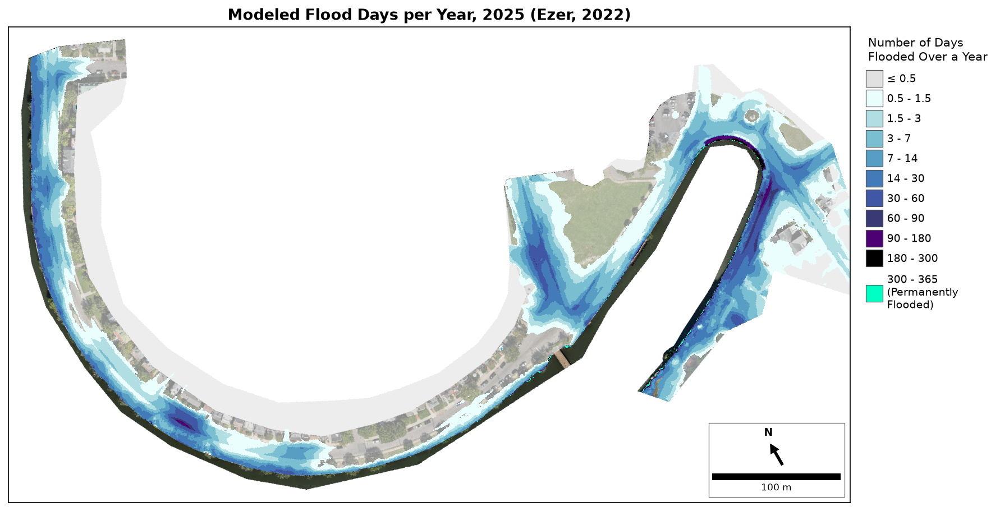

In [29]:
# ---------------------------------------------------------------------
# 01.3 (Step F) — FigS01 (supplementary visual check): modeled flood days per year (2025) over the imagery
# ---------------------------------------------------------------------
fig_banner("FigS01")                                 # printed notes first, then the figure's title
print(f"Map: modeled flood days per year ({FLOOD_YEAR}) over the imagery (supplementary visual check)")
# Full-site map with 2.4 in of space on the right for the legend; imagery first
fig, ax = site_map_figure(right_in=2.4)
draw_imagery(ax)
# The 0.5 m flood-days raster, colored by the flood-day classes (BoundaryNorm puts each value in its class)
# (the first, near-white class is drawn 60 % opaque so the imagery shows through where flooding is rare)
_fc = mcolors.ListedColormap([mcolors.to_rgba(FLOOD_CLASS_COLORS[0], 0.6)] + FLOOD_CLASS_COLORS[1:])
map_imshow(ax, FLOOD[FLOOD_YEAR], G_EXTENT, cmap=_fc, norm=FLOOD_NORM, zorder=2)
# Zoom to the flight footprint, then add the title, north arrow, and scale bar
set_map_view(ax, FOOTPRINT, pad_m=10)
finish_map(ax, f"Modeled Flood Days per Year, {FLOOD_YEAR} (Ezer, 2022)", title_size=13)
# Legend outside the map: bbox_to_anchor=(1.01, 1.0) = just right of the map's top-right corner (axes fractions)
square_legend(ax, list(zip(FLOOD_CLASS_COLORS, FLOOD_LABELS)), title="Number of Days\nFlooded Over a Year",
              loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9, title_fontsize=10)
# Save (if switched on) and show the figure
save_fig(fig, "FigS01_FloodDays_2025_FullSite", "supp")
plt.show()

**What the output shows.** The UAS DEM ranges from about −0.1 to 3.7 m NAVD88 over the street corridor, and VDatum is nearly constant over the site (≈ 0.386 m NAVD88), so *Z*_MHHW keeps the DEM's pattern. Open water (about 19% of the study area) is removed. The 2025 flood frequency is extremely skewed: most land floods less than once a year, while a few low cells reach 365 days. Because eq. (1) is exponential in elevation, a few centimeters of elevation change *F* by a large factor, so the maps use the flood-frequency classes of 00.3. The visual check (FigS01) shows the expected pattern: the highest flood frequencies are on Botetourt St along the west side of the field near Mowbray Arch, around the Memorial Pl loop at the east end, and at a low spot on the western arc of Mowbray Arch, while most of the southern arc and the northern ends of the corridor are high ground (≤ 0.5 days/yr).

### 01.4 Road Centerlines, Sidewalks, & Driveways

**Road centerlines: VGIN RCL with VDOT traffic, plus `Custom_AddRCL`.** VGIN layer 5 ("< 50,000", all other centerlines) is downloaded for the padded study area (VGIN, 2026). `MTFCC` (MAF/TIGER Feature Class Code) is the U.S. Census road type. **Attribute of interest: `VDOT_AADT`**, the VDOT AADT in vehicles/day (both directions combined). It is the traffic control of the analysis; a value of 0 or blank means no count. `Custom_AddRCL` adds hand-drawn centerlines for minor roads and parking-lot lanes that VGIN does not include (Carpenter, 2026) that will eventually become the uncounted road class; they have no traffic counts.

**Sidewalks and driveways.** These layers build the **pavement mask** and mark the **non-road paved areas**. Pavement cells inside these polygons are later labeled `Sidewalk/driveway`, and every other pavement cell `Road`.

- **`Custom_Sidewalk_2025Hague`** (Carpenter, 2026): sidewalk/driveway *surface polygons* digitized on the 2025 imagery, with the City of Norfolk sidewalk lines (City of Norfolk, 2022b) as a guide.
- **City of Norfolk Driveways** (City of Norfolk, 2022a) & **City of Norfolk Sidewalks** (City of Norfolk, 2022a-b): polygons & polylines (respectively) digitized from 2006/2008 aerial photography.

**Cleaning.** Every layer is reprojected to EPSG:6594, repaired, and clipped to the study area (Step A). `VDOT_AADT` is already an attribute of the VGIN centerlines in the REST API, so no table join is needed. The VGIN lines are merged with `Custom_AddRCL`, and `AADT` is standardized (0/blank → missing). The sidewalk layers are dissolved into one sidewalk/driveway surface (Step C).

In [30]:
# ---------------------------------------------------------------------
# 01.4 (Step A) — Cleaning function; road centerlines: VGIN download (with VDOT_AADT) and Custom_AddRCL
# ---------------------------------------------------------------------
# clean_vector(): filters a vector layer to the study area and puts it in the project CRS
def clean_vector(gdf, name):
    """Reproject to the project CRS, repair geometries, and clip to the study area (keeping the geometry type)."""
    # Nothing to clean: return the empty layer as it is
    if gdf is None or len(gdf) == 0:
        return gdf
    # No CRS stored: assume the project CRS; otherwise reproject to it
    g = gdf.set_crs(REF_CRS) if gdf.crs is None else gdf.to_crs(REF_CRS)
    # Drop empty geometries, repair invalid ones (make_valid), clip to the study area
    g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
    g["geometry"] = g.geometry.make_valid()
    g = gpd.clip(g, aoi_geom, keep_geom_type=True)
    # reset_index(drop=True) renumbers the rows 0, 1, 2 ...
    return g[~g.geometry.is_empty].reset_index(drop=True)


# Names of the U.S. Census road-type codes (MTFCC) used in the VGIN centerlines
MTFCC_DESC = {"S1100": "Primary roads", "S1200": "Secondary roads", "S1400": "Local roads", "S1730": "Alleys",
              "S1740": "Private drives", "S1780": "Parking lot roads", "S1200PRI": "Secondary roads (VDOT primary route)",
              "S1200LOC": "Secondary roads (local route)"}
# VGIN centerlines (API, padded box) and the custom extra centerlines, both cleaned
rcl_c = clean_vector(query_features(URL_VGIN_RCL, VEC_BBOX_LL, "VGIN_RCL_layer5"), "VGIN RCL")
add_c = clean_vector(gpd.read_file(addrcl_path), "Custom_AddRCL")
print(f"[01.4 A] centerlines in the study area: {len(rcl_c)} VGIN segments, {len(add_c)} custom lines")

[01.4 A] centerlines in the study area: 85 VGIN segments, 9 custom lines


In [31]:
# ---------------------------------------------------------------------
# 01.4 (Step B) — Sidewalks & driveways: Custom_Sidewalk polygons and City of Norfolk driveways (API)
# ---------------------------------------------------------------------
# Custom sidewalk polygons (file) and City of Norfolk driveways (API), both cleaned
sidewalk_c = clean_vector(gpd.read_file(sidewalk_path), "Custom_Sidewalk")
driveway_c = clean_vector(query_features(URL_NORFOLK_DRIVEWAY, VEC_BBOX_LL, "Norfolk_Driveway"), "Norfolk Driveways")
print(f"[01.4 B] {len(sidewalk_c)} custom sidewalk polygons ({sidewalk_c.area.sum():,.0f} m2), {len(driveway_c)} City driveways ({driveway_c.area.sum():,.0f} m2)")

[01.4 B] 14 custom sidewalk polygons (5,295 m2), 100 City driveways (6,542 m2)


In [32]:
# ---------------------------------------------------------------------
# 01.4 (Step C) — Merge the centerlines (standardize AADT) and dissolve the sidewalk/driveway surface
# ---------------------------------------------------------------------
# Merge the centerlines (pd.concat stacks tables) and standardize the traffic count: 0 / blank = no count (NaN).
rcl_c["Source"], add_c["Source"] = "VGIN_RCL", "Custom_AddRCL"
centerlines = gpd.GeoDataFrame(pd.concat([rcl_c, add_c], ignore_index=True), geometry="geometry", crs=REF_CRS)
# Road-type name from its MTFCC code (.map looks each code up in the dictionary); lines without a code are custom ones
centerlines["MTFCC_Desc"] = centerlines.get("MTFCC", pd.Series(index=centerlines.index, dtype=object)).map(MTFCC_DESC) \
    .fillna("Unclassified (custom)")
# Traffic counts as numbers (text that is not a number becomes NaN)
_aadt = pd.to_numeric(centerlines["VDOT_AADT"], errors="coerce") if "VDOT_AADT" in centerlines.columns else \
    pd.Series(np.nan, index=centerlines.index)
centerlines["AADT"] = _aadt.where(_aadt > 0)              # .where(cond) keeps values where cond is True, else NaN
# Sidewalk/driveway SURFACE: one dissolved polygon (shapely.union_all merges many geometries into one).
# Only the layers that exist and have features
_swd = [g for g in (sidewalk_c, driveway_c) if g is not None and len(g)]
sw_surface = shapely.union_all(pd.concat(_swd).geometry.values) if _swd else shapely.Polygon()

# Add the vector layers to the dataset summary (01.9)
register("VGIN RCL + VDOT AADT", "Traffic control (AADT)", "VGIN feature service (query)", "vector", "2024 release")
register("Custom_AddRCL", "Extra centerlines (no counts)", "custom file", "vector", "2025 imagery")
register("Custom_Sidewalk + Norfolk Driveways", "Sidewalk/driveway surface", "custom file + City of Norfolk feature service",
         "vector", "2025 imagery / 2006-2008")
print(f"[01.4 C] merged centerlines: {len(centerlines)} segments ({centerlines.length.sum():,.0f} m), {int(centerlines['AADT'].notna().sum())} with an AADT count; sidewalk/driveway surface {sw_surface.area:,.0f} m2")

[01.4 C] merged centerlines: 94 segments (6,352 m), 85 with an AADT count; sidewalk/driveway surface 11,767 m2


**What the output shows.** The VGIN query returns the local and secondary roads of the padded box; those inside the study area all carry a VDOT count (220 to 9,500 vehicles/day). The 9 `Custom_AddRCL` lines (≈ 507 m) have no count by design. Together, the custom sidewalk polygons and the City driveways total ~11,800 m² non-road paved surface.

### 01.5 Traffic (AADT) Polygon

A plain "nearest centerline" join can give a cell the wrong street's count near an intersection. A **polygon** of traffic counts is therefore built, and each road cell later takes the AADT of the polygon that covers **most** of it (04.2).

1. **Buffer.** Every centerline segment with a VDOT count (AADT > 0) is buffered `AADT_BUFFER_M` = 6 m on each side, with flat ends and mitered corners. Uncounted segments are left out because there is no count to carry forward.
2. **Erase.** The sidewalk/driveway surface is cut out of the buffers, so sidewalk pavement never inherits a road's traffic.
3. **Remove overlaps by priority.** Where buffers overlap (intersections), the **higher AADT wins**: each buffer keeps only the area that no busier road already claims, because the busier road dominates the pavement stress of a shared intersection.

*Road surface outside the buffers has no traffic count, so its cells are labeled "Uncounted road".*

The clean vector layers are written to one **GeoPackage** (Step B), a single open-source file with many layers that keeps full field names (shapefiles truncate them to 10 characters). The supplementary map of the traffic polygon (FigS02) is drawn at the end of 01.6 (Step E), because it also shows the masked/excluded imagery from the pavement mask counted in 01.6.

In [33]:
# ---------------------------------------------------------------------
# 01.5 (Step A) — Buffer the counted centerlines, erase the sidewalk/driveway surface, and remove overlaps
# ---------------------------------------------------------------------
_counted = centerlines[centerlines["AADT"].notna()].sort_values("AADT", ascending=False)   # busiest first
# Attributes copied onto each traffic polygon (those that exist)
_keep_cols = [c for c in ("AADT", "MTFCC_Desc", "ST_FULL", "Source") if c in _counted.columns]
# Polygons made so far, and the area already claimed by busier roads
_pieces, _claimed = [], None
for _, r in _counted.iterrows():                          # .iterrows() loops over the rows of a table
    # Buffer the centerline by AADT_BUFFER_M on each side (flat ends, sharp corners), then erase the sidewalk/driveway
    # surface
    g = r.geometry.buffer(AADT_BUFFER_M, cap_style="flat", join_style="mitre").difference(sw_surface)
    piece = g if _claimed is None else g.difference(_claimed)        # area not already claimed by a busier road
    _claimed = g if _claimed is None else _claimed.union(g)
    # {**dict_a, "geometry": piece} merges the copied attributes and the new geometry into one row
    if not piece.is_empty and piece.area > 1e-6:
        _pieces.append({**{c: r[c] for c in _keep_cols}, "geometry": piece})
# The pieces as a GeoDataFrame (an empty one if there are none)
aadt_poly = gpd.GeoDataFrame(_pieces, geometry="geometry", crs=REF_CRS) if _pieces else \
    gpd.GeoDataFrame({"AADT": [], "geometry": []}, geometry="geometry", crs=REF_CRS)
aadt_poly = gpd.clip(aadt_poly, aoi_geom).reset_index(drop=True)
# np.arange(n) = 0, 1, ..., n-1: an ID per polygon
aadt_poly["PolyID"] = np.arange(len(aadt_poly))
print(f"[01.5 A] traffic polygon: {len(_counted)} counted segments -> {len(aadt_poly)} non-overlapping polygons ({aadt_poly.area.sum():,.0f} m2); AADT values {sorted(aadt_poly['AADT'].astype(int).unique().tolist())}")

[01.5 A] traffic polygon: 85 counted segments -> 84 non-overlapping polygons (63,656 m2); AADT values [220, 260, 440, 1200, 4500, 6300, 9500]


In [34]:
# ---------------------------------------------------------------------
# 01.5 (Step B) — Write the clean vector layers to one GeoPackage
# ---------------------------------------------------------------------
clean_gpkg = OUT01 / "Clean_Hague2025_NB01.gpkg"
# One GeoPackage file, one layer per dataset (empty layers are skipped)
for layer, g in (("Centerlines", centerlines), ("SidewalkDriveway_Surface", gpd.GeoDataFrame(geometry=[sw_surface], crs=REF_CRS)),
                 ("AADT_Polygon", aadt_poly), ("WaterSurface", water_c)):
    if g is not None and len(g) and not g.geometry.iloc[0].is_empty:
        g.to_file(clean_gpkg, layer=layer, driver="GPKG")
print(f"[01.5 B] clean vector layers -> {clean_gpkg.relative_to(PROJECT)}")

[01.5 B] clean vector layers -> DATA\02_Clean_Data\OUT_DATA_NB01_Sec01\Clean_Hague2025_NB01.gpkg


**What the output shows.** The counted segments become non-overlapping traffic polygons with seven distinct counts (220, 260, 440, 1,200, 4,500, 6,300, and 9,500 vehicles/day). Much of the polygon lies over streets outside the UAS flight; Section 04.2 shows which counts reach the analysis cells.

### 01.6 Crack-Mapping Datasets (Custom): Pavement Mask & Crack Raster

These custom datasets measure the response variable: the **pavement (road) mask** is the surface over which each crack density is measured, and the **crack raster** marks the cracks within it. The author made both in ArcGIS Pro (Carpenter, 2026).

**Pavement (road) mask: `Road_Mask_Final_Shrunk3.tif`.** Cracks can be counted only on pavement. The mask defines that surface, and therefore the denominator of crack density, and keeps grass, roofs, cars, and shadows from being classified as cracks.

1. **Allowed area.** The road centerlines (VGIN RCL + `Custom_AddRCL`) were buffered 6 m (square ends, mitered corners), and the sidewalk/driveway surface (`Custom_Sidewalk` merged with the City driveways) was added to the buffer.
2. **Pavement detection.** SAM3 (Carion et al., 2025; Eagle Technology Group Ltd., 2026) was run on the full imagery with the prompts "Concrete, Impervious Surface, Pavement, Road". Its polygons were clipped to the allowed area, and hand-drawn polygons of missed pavement were added.
3. **Exclusions.** The following were cut out:
   - SAM3 detections of "power line shadow, gravel, shadow", grown 5 cm;
   - hand-drawn lines along shadows and thin features such as power lines and parking-lot paint, buffered 10 cm;
   - hand-drawn lines along sidewalk control-joint grooves, buffered 5 cm, because they look like cracks;
   - hand-drawn exclusion polygons (curb/gutter strips and extra shadow).
4. **Rasterize and shrink.** The final polygon was converted to the 0.02 m imagery grid (a pixel is pavement if its center is inside) and shrunk inward by 3 pixels (6 cm), which removes the edge where the crack model mistakes the mask boundary for a crack.

**Crack raster: `Cracks_Classified_Combined_Shrunk.tif`.** The pixel-level crack map from which crack density, the share of each cell's pavement that is cracked, is computed.

1. **Base lines.** Esri's pretrained Pavement Crack Detection model (ESRI Analytics, 2026) was run on the road-masked imagery.
2. **Hand-edited lines.** The base lines were edited into a full **crack inventory**: false lines were deleted, and missed cracks, especially darker ones, were added. A **training subset** (`Training_masked_imagery_PaveCracksDetect_Edited.shp`) was kept without the lines that taught the model to see cracks in plain pavement.
3. **Training.** A Holistically-Nested Edge Detection (HED) model (Xie & Tu, 2015) with a 19-layer Visual Geometry Group (VGG-19) backbone (Simonyan & Zisserman, 2014) was trained in `arcgis.learn` on the masked RGB imagery (256 × 256-pixel chips with a 128-pixel stride, crack lines buffered 2 cm, and up to 50 epochs with early stopping) and then classified every pixel.
4. **Post-processing.**
   - The inventory lines (buffered 6 cm) were forced into the result.
   - Isolated specks under 4 connected pixels were removed (region grouping rather than a majority filter, so thin cracks survive).
   - The result was clipped to the shrunk mask (1 = crack; 0 = no crack).

*The hand-drawn include/exclude layers, the SAM3 detection layers, the base lines, the full inventory, and the trained model are not part of this package.*

**Counting.** Both 0.02 m rasters (about 820 million pixels each) are **counted** onto the 0.5 m raster grid (Step B), which gives each 0.5 m cell:

- `MaskCount`: its pavement pixels;
- `CrackCount`: its crack pixels inside the pavement;
- `ValidCount`: its pavement pixels with a crack/no-crack value.

The counting is lossless and runs strip by strip to keep memory low; it is slow only on the first run because the counts are cached. Step C totals the counts and builds the masked/excluded imagery layer of the maps; Step D reads the optional training lines; and Step E draws the supplementary map of the traffic polygon (FigS02).

In [35]:
# ---------------------------------------------------------------------
# 01.6 (Step A) — Raster metadata and the grid-alignment helpers
# ---------------------------------------------------------------------
# Metadata of the road mask (mm) and the crack raster (cm)
mm, cm = raster_meta(mask_path), raster_meta(crack_path)


# grid_offset(): how many pixels a custom raster is shifted from the reference grid
def grid_offset(meta):
    """Offset of a raster's upper-left corner from the imagery grid, in imagery pixels (whole numbers = snapped)."""
    return ((meta["bounds"][0] - REF_X0) / REF_RES, (REF_Y0 - meta["bounds"][3]) / REF_RES)


# read_aligned(): reads a strip of a raster lined up with the reference grid
def read_aligned(src, ox, oy, ref_row0, nrows, ncols, fill):
    """Rows [ref_row0, ref_row0 + nrows) x columns [0, ncols) of the IMAGERY grid, read from a raster whose upper-left
    pixel sits at imagery pixel (ox, oy); pixels outside the raster get `fill`."""
    # Output strip, pre-filled for pixels the raster does not cover
    buf = np.full((nrows, ncols), fill, dtype=src.dtypes[0])
    # Rows (a0:a1) and columns (c0:c1) of the source raster that overlap the strip
    sr0 = ref_row0 - oy
    a0, a1 = max(0, sr0), min(src.height, sr0 + nrows)
    c0, c1 = max(0, -ox), min(src.width, ncols - ox)
    # Read only that block (Window(col, row, width, height)) into its place in the strip
    if a1 > a0 and c1 > c0:
        buf[a0 - sr0:a1 - sr0, c0 + ox:c1 + ox] = src.read(1, window=Window(c0, a0, c1 - c0, a1 - a0))
    return buf
print(f"[01.6 A] road mask {mm['width']:,} x {mm['height']:,} px, offset {grid_offset(mm)} imagery px; crack raster {cm['width']:,} x {cm['height']:,} px, offset {grid_offset(cm)} imagery px")

[01.6 A] road mask 28,664 x 22,960 px, offset (1644.9999999022111, 1189.0000001294538) imagery px; crack raster 28,664 x 22,960 px, offset (1644.9999999022111, 1189.0000001294538) imagery px


In [36]:
# ---------------------------------------------------------------------
# 01.6 (Step B) — Count pavement, crack, and classified pixels per 0.5 m cell (strip by strip), or reuse the cache
# ---------------------------------------------------------------------
t0 = time.time()
count_paths = {k: OUT01 / f"{k}_Count_0p5m.tif" for k in ("RoadMask", "Crack", "CrackValid")}   # dict comprehension
for p in count_paths.values():                   # reuse cached counts saved by an earlier run
    for _d in HEAVY_CACHE_DIRS:
        if not p.exists() and (_d / p.name).exists() and not FORCE_REBUILD_HEAVY:
            shutil.copy2(_d / p.name, p)
# All three counts cached: read them
if all(p.exists() for p in count_paths.values()) and not FORCE_REBUILD_HEAVY:
    counts = {}
    # Save the counts so later runs skip this slow step
    for k, p in count_paths.items():
        with rasterio.open(p) as s:
            counts[k] = s.read(1)
    _src = "cached counts"
else:
    f = AGG_FACTOR
    # Both custom rasters must sit exactly on the imagery grid (whole-pixel offsets, same pixel size)
    offs = {}
    for _name, _m in (("crack", cm), ("mask", mm)):
        _ox, _oy = grid_offset(_m)
        if abs(_m["res_x"] - REF_RES) > 1e-9 or abs(_ox - round(_ox)) > 1e-3 or abs(_oy - round(_oy)) > 1e-3:
            raise ValueError(f"The {_name} raster is not on the imagery grid (offset {_ox:.3f}, {_oy:.3f} px)")
        offs[_name] = (int(round(_ox)), int(round(_oy)))
    # One empty count grid per kind (uint16 = whole numbers up to 65,535)
    counts = {k: np.zeros((G_H, G_W), dtype="uint16") for k in count_paths}
    _nod = 255 if cm["nodata"] is None else cm["nodata"]
    # Read the 2 cm rasters STRIP_COARSE_ROWS cells at a time, so the whole raster never has to fit in memory
    with rasterio.open(crack_path) as sc, rasterio.open(mask_path) as sm_:
        for R0 in range(0, G_H, STRIP_COARSE_ROWS):
            R1 = min(G_H, R0 + STRIP_COARSE_ROWS)
            nrows, ncols = (R1 - R0) * f, G_W * f
            # Pavement pixels (mask), and the raw crack values, of this strip; *offs[...] unpacks the (x, y) offset into
            # two arguments
            m_buf = read_aligned(sm_, *offs["mask"], R0 * f, nrows, ncols, 0) == ROAD_MASK_VALUE
            c_raw = read_aligned(sc, *offs["crack"], R0 * f, nrows, ncols, _nod)
            # reshape(rows, f, cols, f).sum(axis=(1, 3)) adds up every f x f block of pixels -> one 0.5 m cell
            for k, arr in (("RoadMask", m_buf), ("Crack", (c_raw == CRACK_VALUE) & m_buf),
                           ("CrackValid", (c_raw != _nod) & m_buf)):
                counts[k][R0:R1] = arr.reshape(R1 - R0, f, G_W, f).sum(axis=(1, 3), dtype="uint16")
    for k, p in count_paths.items():
        write_tif(counts[k], p, G_T, nodata=None)
    _src = "computed from the 0.02 m rasters"
print(f"[01.6 B] pixel counts: {_src} ({time.time() - t0:.1f} s)")

[01.6 B] pixel counts: cached counts (0.0 s)


In [37]:
# ---------------------------------------------------------------------
# 01.6 (Step C) — Count totals and the masked / excluded imagery layer of the maps
# ---------------------------------------------------------------------
# Pavement, crack, and classified pixels in every 0.5 m cell
mask_cnt, crack_cnt, valid_cnt = counts["RoadMask"], counts["Crack"], counts["CrackValid"]
road_g = mask_cnt > 0                                            # 0.5 m cells that contain pavement
# Share of each 0.5 m cell covered by pavement (AGG_FACTOR**2 = 625 imagery pixels per cell)
mask_frac_g = (mask_cnt / AGG_FACTOR ** 2).astype("float32")
# Totals over the study area (int64 so the sums cannot overflow)
TOTAL_MASK_PX, TOTAL_CRACK_PX = int(mask_cnt.sum(dtype="int64")), int(crack_cnt.sum(dtype="int64"))
TOTAL_VALID_PX = int(valid_cnt.sum(dtype="int64"))

# "Masked / excluded imagery": inside the imagery footprint but outside the pavement mask (drawn dark gray on maps).
# Imagery footprint on the 0.5 m grid (nearest-neighbor resampling of the preview's valid pixels)
_img_valid_g = np.zeros((G_H, G_W), dtype="uint8")
reproject(img_valid.astype("uint8"), _img_valid_g, src_transform=P_T, src_crs=REF_CRS.to_wkt(), dst_transform=G_T,
          dst_crs=REF_CRS.to_wkt(), resampling=Resampling.nearest)
EXCLUDED_G = (_img_valid_g == 1) & (mask_frac_g < 0.5)
# Add the custom rasters to the dataset summary (01.9)
register("Pavement mask (Road_Mask_Final_Shrunk3)", "Denominator of crack density", "custom file", "0.02 m", "2025 imagery")
register("Crack raster (Cracks_Classified_Combined_Shrunk)", "Response: crack density", "custom file", "0.02 m", "2025 imagery")
print(f"[01.6 C] pavement {TOTAL_MASK_PX * REF_RES ** 2:,.0f} m2; cracks {TOTAL_CRACK_PX * REF_RES ** 2:,.0f} m2 (overall crack fraction {TOTAL_CRACK_PX / max(TOTAL_VALID_PX, 1):.4f}); {100 * (1 - TOTAL_VALID_PX / max(TOTAL_MASK_PX, 1)):.2f} % of pavement pixels unclassified")

[01.6 C] pavement 12,293 m2; cracks 1,588 m2 (overall crack fraction 0.1313); 1.61 % of pavement pixels unclassified


In [38]:
# ---------------------------------------------------------------------
# 01.6 (Step D) — Crack-model training lines (optional; used only for the workflow figure)
# ---------------------------------------------------------------------

# Read and clean the training lines only if the file exists (None otherwise)
train_c = clean_vector(gpd.read_file(train_path), "Training lines") if HAS_TRAINING_LINES else None
if train_c is not None:
    register("Crack-model training lines", "Workflow figure only", "custom file", "vector", "2026")
print("[01.6 D] training lines: " + (f"{len(train_c)} lines ({train_c.length.sum():,.0f} m)" if train_c is not None
                                     else "not provided (optional; add the shapefile to DATA/01_Raw_Data_Custom)"))

[01.6 D] training lines: 796 lines (2,426 m)


*** THIS IS SUPPLEMENTARY FIGURE S02. IT IS NOT IN THE MAIN PROJECT REPORT.
*** THIS IS A BASIC MAP FOR A VISUAL CHECK OF THE OUTPUTS SO FAR.
Map: traffic (AADT) polygon, uncounted roads, and the sidewalk/driveway surface over the imagery (supplementary visual check)


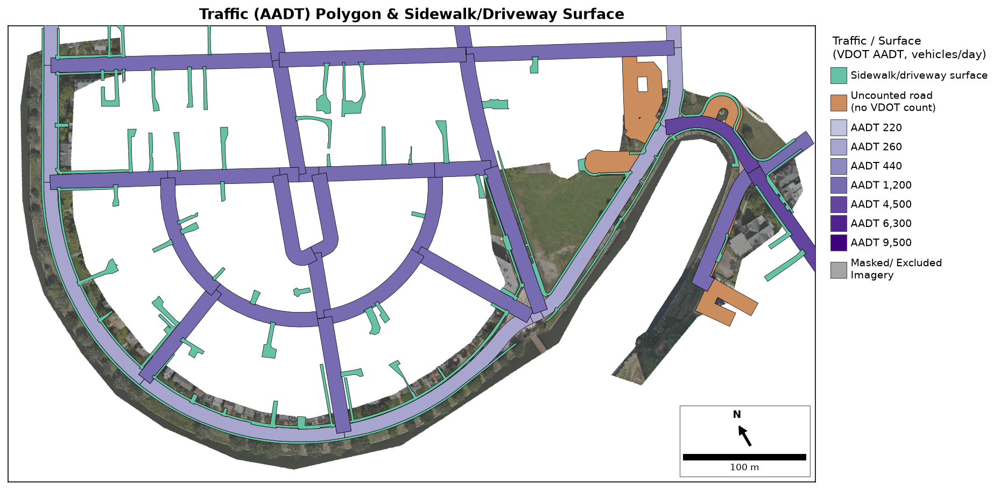

In [39]:
# ---------------------------------------------------------------------
# 01.6 (Step E) — FigS02 (supplementary visual check): traffic (AADT) polygon and sidewalk/driveway surface
# ---------------------------------------------------------------------
# "Uncounted road" surface for this check: centerlines WITHOUT a VDOT count (mostly Custom_AddRCL), buffered like the
# counted ones, minus the sidewalk/driveway surface and the counted (AADT) polygon. (The analysis itself labels the
# cells in 04.2; this layer only shows where no count reaches.)
# Centerlines without a count, buffered, merged into one polygon (an empty one if none)
_unc = centerlines[centerlines["AADT"].isna()]
_unc_poly = shapely.union_all(_unc.geometry.buffer(AADT_BUFFER_M, cap_style="flat", join_style="mitre").values) \
    if len(_unc) else shapely.Polygon()
_unc_poly = _unc_poly.difference(sw_surface)
if len(aadt_poly):
    _unc_poly = _unc_poly.difference(shapely.union_all(aadt_poly.geometry.values))
# Keep only the part inside the study area
_unc_poly = _unc_poly.intersection(aoi_geom)
# One purple per distinct AADT value of the polygon (light = low traffic, dark = high traffic)
_vals = sorted(aadt_poly["AADT"].unique())
_aadt_col = dict(zip(_vals, [mcolors.to_hex(c) for c in plt.get_cmap(TRAFFIC_AADT_CMAP)(np.linspace(*TRAFFIC_AADT_RANGE, len(_vals)))]))
_excl_rgba = mcolors.to_rgba(MASK_COLOR, 0.55)                    # semi-transparent masked / excluded imagery

fig_banner("FigS02")
print("Map: traffic (AADT) polygon, uncounted roads, and the sidewalk/driveway surface over the imagery "
      "(supplementary visual check)")
# Imagery first, then the masked / excluded imagery (one-color colormap; NaN is transparent)
fig, ax = site_map_figure(right_in=3.0)
draw_imagery(ax)
map_imshow(ax, np.where(EXCLUDED_G, 1, np.nan), G_EXTENT, cmap=mcolors.ListedColormap([_excl_rgba]), zorder=2)
# Sidewalk/driveway surface and uncounted roads, each as one polygon
for geom, col in ((sw_surface, TRAFFIC_BASE_COLORS["Sidewalk/driveway"]), (_unc_poly, TRAFFIC_BASE_COLORS["Uncounted road"])):
    if not geom.is_empty:
        rot_geoms(gpd.GeoSeries([geom], crs=REF_CRS)).plot(ax=ax, facecolor=col, edgecolor="black", linewidth=0.35, zorder=3)
# Traffic polygons, one AADT value (color) at a time
for v in _vals:
    rot_geoms(aadt_poly[aadt_poly["AADT"] == v]).plot(ax=ax, facecolor=_aadt_col[v], edgecolor="black", linewidth=0.35,
                                                      zorder=4)
set_map_view(ax, FOOTPRINT, pad_m=10)
finish_map(ax, "Traffic (AADT) Polygon & Sidewalk/Driveway Surface", title_size=13)
# Legend items: the two surfaces, one per AADT value (list + list joins lists), and the masked imagery
square_legend(ax, [(TRAFFIC_BASE_COLORS["Sidewalk/driveway"], "Sidewalk/driveway surface"),
                   (TRAFFIC_BASE_COLORS["Uncounted road"], "Uncounted road\n(no VDOT count)")]
              + [(_aadt_col[v], f"AADT {int(v):,}") for v in _vals] + [(_excl_rgba, "Masked/ Excluded\nImagery")],
              title="Traffic / Surface\n(VDOT AADT, vehicles/day)", loc="upper left", bbox_to_anchor=(1.01, 1.0),
              fontsize=9, title_fontsize=10)
save_fig(fig, "FigS02_TrafficPolygon_FullSite", "supp")
plt.show()

**What the counts show.** In the author's run, the mask marks about 30.7 million 0.02 m pixels (≈ 12,300 m²) as pavement, 3.7% of the imagery extent; the other 96.3% is no-data by design. About 1,590 m² are cracks, an overall crack fraction of ≈ 0.13. About 1.6% of the pavement pixels have neither a crack nor a no-crack value; crack density uses only classified pixels as its denominator (`ValidCount`), so they do not bias it. In the traffic map (FigS02), the counted polygons cover the main streets: the long arc of Mowbray Arch carries a low count (260 vehicles/day), and Memorial Pl and Yarmouth St at the east end carry the highest count that reaches the imaged pavement (4,500). The other counts (220, 440, 6,300, and 9,500) lie on streets outside the UAS flight, so no analysis cell takes them (04.2). The uncounted road surface is mostly the parking-lot lanes and drives at the east end.

### 01.7 Crack-Map Accuracy: `Custom_AccuracyPts_Labeled_2025Hague_20261003.shp`

**Purpose.** To measure how well the crack raster matches the cracks visible in the imagery. The crack map was built to (1) capture more cracks than Esri's pretrained model and (2) capture as many obvious cracks as possible without many false positives, so precision (few false cracks) matters most here.

**How the points were made:**

1. ArcGIS Pro's *Create Accuracy Assessment Points* drew an **equalized stratified random** sample from the crack raster: about 75 points on crack pixels and 75 on no-crack pixels. Equal numbers are needed because cracks are a small share of the pavement.
2. Before sampling, a 1 m buffer around the model's training lines was blanked out, so no point lands on the training data.
3. Each point was labeled by eye on the 2 cm imagery (`GrndTruth`: 1 = crack, 0 = no crack). `Classified` holds the raster's value at the point.

**Map (Step A).** The points are drawn over the crack raster and the pavement mask (supplementary visual check FigS03) to show their spread over the pavement.

**Metrics.** Each label is compared with the crack raster (Step B), which gives four outcomes: crack correctly mapped, no crack correctly mapped, crack missed, and false crack. Step C turns them into overall accuracy, Cohen's (1960) kappa (κ), and the precision, recall, and F1 score of both classes (scikit-learn, including its `classification_report`). Step D draws the confusion matrix (supplementary figure FigS04).

**Area weighting (Olofsson et al., 2014).** Because the points were drawn in equal numbers per map class, each crack point represents far less pavement than each no-crack point. Good practice for a stratified sample weights each stratum by its mapped share of the area (Olofsson et al., 2014; Stehman, 2014); otherwise, overall accuracy and recall describe the sample rather than the pavement. Step C therefore also gives the **area-weighted** overall accuracy and the area-weighted precision, recall, and F1 score of both classes. Area-weighted precision equals the plain precision, because precision is computed within one map class, where every point has the same weight.

*** THIS IS SUPPLEMENTARY FIGURE S03. IT IS NOT IN THE MAIN PROJECT REPORT.
*** THIS IS A BASIC MAP FOR A VISUAL CHECK OF THE OUTPUTS SO FAR.
Map: crack raster, pavement mask, and accuracy points (full site; supplementary visual check)


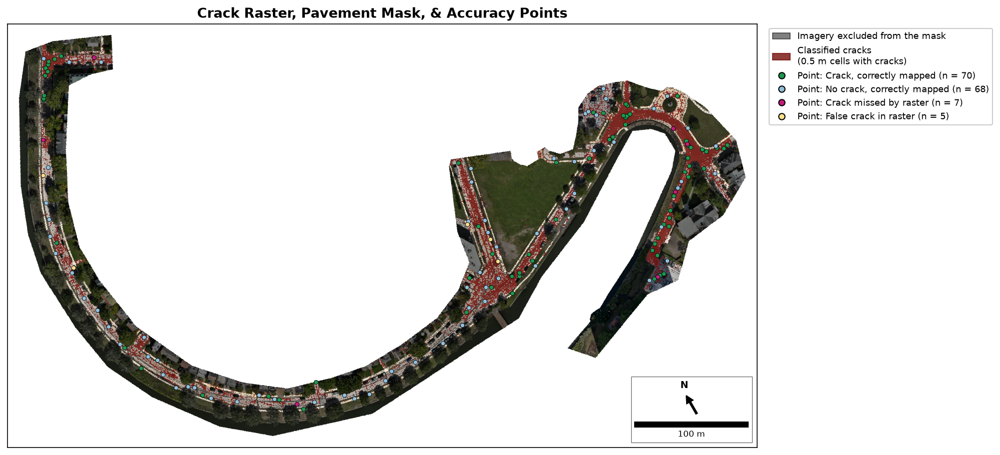

In [40]:
# ---------------------------------------------------------------------
# 01.7 (Step A) — Accuracy points: read; FigS03 (supplementary visual check): crack raster, pavement mask, and points
# ---------------------------------------------------------------------
# Read and clean the accuracy points; acc is the working copy
accpts_c = clean_vector(gpd.read_file(accpts_path), "Accuracy points")
acc = accpts_c.copy()
acc["y_true"] = pd.to_numeric(acc[GRNDTRUTH_FIELD], errors="coerce")        # label made by eye: 1 = crack, 0 = no crack
if CLASSIFIED_FIELD in acc.columns:
    acc["y_pred"] = pd.to_numeric(acc[CLASSIFIED_FIELD], errors="coerce")  # crack-raster value stored at the point
else:                                                    # sample the crack raster at the points instead
    # s.sample() reads the raster value at each (x, y) point
    with rasterio.open(crack_path) as s:
        acc["y_pred"] = [v[0] for v in s.sample(zip(acc.geometry.x, acc.geometry.y))]
# Keep only points with a valid label and a valid map value (0 or 1)
acc = acc[acc["y_true"].isin([0, 1]) & acc["y_pred"].isin([0, 1])].copy()
# Outcome of each point: np.select(conditions, choices) takes the choice of the first condition that is True.
_t, _p = acc["y_true"].astype(int), (acc["y_pred"] == CRACK_VALUE).astype(int)
acc["Outcome"] = np.select([(_t == 1) & (_p == 1), (_t == 0) & (_p == 0), (_t == 1) & (_p == 0), (_t == 0) & (_p == 1)],
                           ["TP", "TN", "FN", "FP"], default="other")
ACC_STYLE = {   # outcome -> (marker color, legend label)
    "TP": ("#1a9850", "Crack, correctly mapped"), "TN": ("#91bfdb", "No crack, correctly mapped"),
    "FN": ("#c51b7d", "Crack missed by raster"), "FP": ("#fee08b", "False crack in raster")}

fig_banner("FigS03")
print("Map: crack raster, pavement mask, and accuracy points (full site; supplementary visual check)")
# Imagery, then the masked imagery (black, 50 %) and the 0.5 m cells that contain cracks
fig, ax = site_map_figure(right_in=3.3)
draw_imagery(ax)
_excl_k, _crack_r = (0, 0, 0, 0.5), mcolors.to_rgba(CRACK_COLOR, CRACK_ALPHA_ZOOM)    # RGBA: semi-transparent
map_imshow(ax, np.where(EXCLUDED_G, 1, np.nan), G_EXTENT, cmap=mcolors.ListedColormap([_excl_k]), zorder=2)
map_imshow(ax, np.where(crack_cnt > 0, 1, np.nan), G_EXTENT, cmap=mcolors.ListedColormap([_crack_r]), zorder=3)
# Points rotated into the map frame; legend handles start with the two raster layers
_acc_r = rot_geoms(acc)
_handles = [mpatches.Patch(color=_excl_k, label="Imagery excluded from the mask"),
            mpatches.Patch(color=_crack_r, label="Classified cracks\n(0.5 m cells with cracks)")]
# One color per outcome (TP, TN, FN, FP), with its count in the legend
for k, (colr, lab) in ACC_STYLE.items():
    _a = _acc_r[acc["Outcome"].values == k]
    ax.scatter(_a.geometry.x, _a.geometry.y, s=16, color=colr, edgecolor="black", linewidth=0.4, zorder=5)
    _handles.append(mlines.Line2D([], [], marker="o", linestyle="", markerfacecolor=colr, markeredgecolor="black",
                                  markersize=6, label=f"Point: {lab} (n = {len(_a)})"))
set_map_view(ax, FOOTPRINT, pad_m=10)
finish_map(ax, "Crack Raster, Pavement Mask, & Accuracy Points", title_size=13)
ax.legend(handles=_handles, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8.5, framealpha=1)
save_fig(fig, "FigS03_CrackMask_AccuracyPoints_FullSite", "supp")
plt.show()

In [41]:
# ---------------------------------------------------------------------
# 01.7 (Step B) — Compare each label with the crack raster: the confusion matrix
# ---------------------------------------------------------------------
# Labels (truth) and map values as 0/1 arrays (.values = NumPy array of a column)
y_true, y_pred = acc["y_true"].astype(int).values, (acc["y_pred"] == CRACK_VALUE).astype(int).values
cmat = confusion_matrix(y_true, y_pred, labels=[1, 0])          # rows = truth (crack, no crack), columns = map
register("Accuracy points (labeled)", "Crack-map accuracy", "custom file", f"{len(acc)} points", "labeled Oct 2026")
print(f"[01.7 B] {len(acc)} labeled points")
print("Confusion matrix (rows = label from the imagery, columns = crack map):")
display(pd.DataFrame(cmat, index=["Truth: crack", "Truth: no crack"], columns=["Map: crack", "Map: no crack"]))

[01.7 B] 150 labeled points
Confusion matrix (rows = label from the imagery, columns = crack map):


,Map: crack,Map: no crack
Truth: crack,70,7
Truth: no crack,5,68


In [42]:
# ---------------------------------------------------------------------
# 01.7 (Step C) — Accuracy metrics of both classes (scikit-learn) and area-weighted estimates (Olofsson et al., 2014)
# ---------------------------------------------------------------------
# Why area weighting: the points were drawn in EQUAL numbers per map class (stratified random sampling), but cracks are a
# small share of the pavement, so each crack point stands for far less pavement than each no-crack point. Olofsson et al.
# (2014) weight each map class (stratum) by its share of the map: with n[i, j] = points MAPPED as class i whose truth is
# j, and W_i = mapped share of class i on the pavement, p_ij = W_i * n_ij / n_i estimates the share of the pavement in
# each (map, truth) cell. From p_ij (rows = map class, columns = truth):
#   area-weighted precision of class k = p_kk / (row sum of k)    = share of the pavement MAPPED as k that truly is k
#   area-weighted recall of class k    = p_kk / (column sum of k) = share of the pavement that truly is k and is mapped k
#   area-weighted F1 score             = 2 x precision x recall / (precision + recall)
# Precision is the same with or without the weighting, because it is computed within one map class, where every point
# has the same weight; recall, F1, and overall accuracy change.
# W_crack = share of the classified pavement that the crack map calls crack
W_crack = TOTAL_CRACK_PX / max(TOTAL_VALID_PX, 1)
# n_map[i, j] = points mapped as class i whose truth is j (nested list comprehension)
n_map = np.array([[np.sum((y_pred == i) & (y_true == j)) for j in (1, 0)] for i in (1, 0)], dtype=float)
# [:, None] turns the weights into a column so each row (map class) gets its own W_i; keepdims=True keeps the row sums
# as a column; clip(min=1) avoids dividing by 0
p_ij = np.array([W_crack, 1 - W_crack])[:, None] * n_map / n_map.sum(axis=1, keepdims=True).clip(min=1)
# p_ij rows = map (crack, no crack), columns = truth (crack, no crack)

# 1) Whole-map measures
acc_metrics = pd.Series({
    "Points labeled": len(acc),
    "Overall accuracy": float((y_true == y_pred).mean()),
    "Area-weighted overall accuracy": float(p_ij[0, 0] + p_ij[1, 1]),
    "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
    # per-class values kept here too, for the figure note and the key numbers of Section 07
    "Precision (crack)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
    "Recall (crack)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
    "Area-weighted precision (crack)": float(p_ij[0, 0] / max(p_ij[0].sum(), 1e-12)),
    "Area-weighted recall (crack)": float(p_ij[0, 0] / max(p_ij[:, 0].sum(), 1e-12)),
}, name="value")
# Area-weighted F1 score of the crack class (harmonic mean of the area-weighted precision and recall)
_P, _R = acc_metrics["Area-weighted precision (crack)"], acc_metrics["Area-weighted recall (crack)"]
acc_metrics["Area-weighted F1 (crack)"] = 2 * _P * _R / max(_P + _R, 1e-12)
# Kappa is reused in the figure note of FigS04
KAPPA = acc_metrics["Cohen's kappa"]
print("Whole-map accuracy:")
display(acc_metrics[["Points labeled", "Overall accuracy", "Area-weighted overall accuracy", "Cohen's kappa"]]
        .to_frame().round(2))

# 2) Per-class measures: pos_label tells scikit-learn which class counts as "positive" (1 = crack, 0 = no crack)
class_metrics = pd.DataFrame({
    "Precision": [precision_score(y_true, y_pred, pos_label=k, zero_division=0) for k in (1, 0)],
    "Recall": [recall_score(y_true, y_pred, pos_label=k, zero_division=0) for k in (1, 0)],
    "F1 score": [f1_score(y_true, y_pred, pos_label=k, zero_division=0) for k in (1, 0)],
    # Area-weighted values (Olofsson et al., 2014): row k of p_ij for precision, column k for recall
    "Area-weighted precision": [p_ij[k, k] / max(p_ij[k].sum(), 1e-12) for k in (0, 1)],
    "Area-weighted recall": [p_ij[k, k] / max(p_ij[:, k].sum(), 1e-12) for k in (0, 1)],
    "Points (truth)": [int((y_true == 1).sum()), int((y_true == 0).sum())]}, index=["Crack", "No crack"])
# Area-weighted F1 score of each class
_PR = class_metrics["Area-weighted precision"] * class_metrics["Area-weighted recall"]
_SUM = (class_metrics["Area-weighted precision"] + class_metrics["Area-weighted recall"]).clip(lower=1e-12)
class_metrics.insert(5, "Area-weighted F1 score", 2 * _PR / _SUM)
print("Per-class accuracy:")
display(class_metrics.round(2))

# 3) scikit-learn's own summary of the same per-class values (support = number of points whose truth is that class)
print("scikit-learn classification_report:")
print(classification_report(y_true, y_pred, labels=[1, 0], target_names=["Crack", "No crack"], digits=3, zero_division=0))

Whole-map accuracy:


,value
Points labeled,150.00
Overall accuracy,0.92
Area-weighted overall accuracy,0.91
Cohen's kappa,0.84


Per-class accuracy:


,Precision,Recall,F1 score,Area-weighted precision,Area-weighted recall,Area-weighted F1 score,Points (truth)
Crack,0.93,0.91,0.92,0.93,0.60,0.73,77
No crack,0.91,0.93,0.92,0.91,0.99,0.95,73


scikit-learn classification_report:
              precision    recall  f1-score   support

       Crack      0.933     0.909     0.921        77
    No crack      0.907     0.932     0.919        73

    accuracy                          0.920       150
   macro avg      0.920     0.920     0.920       150
weighted avg      0.920     0.920     0.920       150



*** THIS IS SUPPLEMENTARY FIGURE S04. IT IS NOT IN THE MAIN PROJECT REPORT.
Figure: confusion matrix of the crack map at the labeled accuracy points (supplementary)


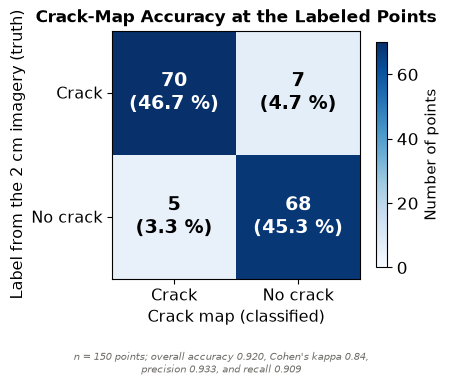

In [43]:
# ---------------------------------------------------------------------
# 01.7 (Step D) — FigS04 (supplementary): confusion matrix of the crack map
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
fig_banner("FigS04", is_map=False)
print("Figure: confusion matrix of the crack map at the labeled accuracy points (supplementary)")
fig, ax = plt.subplots(figsize=(4.6, 3.8), dpi=100)        # small and at 100 dpi, so it fits on screen
# Each cell's share of all points (%)
_pct = 100 * cmat / cmat.sum()
im_ = ax.imshow(cmat, cmap="Blues", vmin=0)          # color = number of points in each (truth, map) cell
# Write the count and percent in each cell (white text on the dark cells)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cmat[i, j]}\n({_pct[i, j]:.1f} %)", ha="center", va="center", fontsize=fs(11), fontweight="bold",
                color="white" if cmat[i, j] > cmat.max() / 2 else "black")
# Axis labels: columns = crack map, rows = label from the imagery (truth)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Crack", "No crack"], fontsize=fs(9))
ax.set_yticks([0, 1]); ax.set_yticklabels(["Crack", "No crack"], fontsize=fs(9))
ax.set_xlabel("Crack map (classified)", fontsize=fs(9))
ax.set_ylabel("Label from the 2 cm imagery (truth)", fontsize=fs(9))
ax.set_title("Crack-Map Accuracy at the Labeled Points", fontweight="bold", fontsize=fs(10))
# Color bar, then the note under the figure (y = -0.04 = just below it)
fig.colorbar(im_, ax=ax, shrink=0.8).set_label("Number of points", fontsize=fs(8.5))
fig.text(0.5, -0.04, f"n = {len(acc)} points; overall accuracy {acc_metrics['Overall accuracy']:.3f}, Cohen's kappa "
         f"{KAPPA:.2f},\nprecision {acc_metrics['Precision (crack)']:.3f}, and recall {acc_metrics['Recall (crack)']:.3f}",
         ha="center", fontsize=7.5, style="italic", color=REF_COLOR)
# tight_layout() fits the labels inside the figure without overlaps
plt.tight_layout()
save_fig(fig, "FigS04_CrackMap_ConfusionMatrix", "supp")
plt.show()
chart_fonts(False)                     # back to the default fonts

**What the map, tables, and figure show.** The accuracy points spread evenly over the pavement, and the few misses and false cracks show no geographic cluster (FigS03). In the author's run, the crack raster agreed with the labels at 92.0% of the 150 points (70 cracks and 68 no-cracks correctly mapped), with κ = 0.84 ("almost perfect" agreement beyond chance). For the crack class, precision was 0.933 (93% of mapped cracks are real), recall 0.909, and F1 0.92 at the sample points. Weighted by area, precision stays 0.933, but recall drops to about 0.60 and F1 to about 0.73: the many faint cracks spread over the large uncracked area are missed more often than the sample suggests. For the no-crack class, the area-weighted precision, recall, and F1 are about 0.91, 0.99, and 0.95. The map therefore meets its purpose (few false cracks, and the obvious cracks captured), and its crack densities are conservative (lower bounds). What matters most for this analysis is that the misses are not concentrated in either the flooded or the dry streets.

### 01.8 Relative Sea Level at Sewells Point: Observed Record & Projections

Two related datasets describe the sea level on which eq. (1) depends.

**Observed monthly mean sea level (NOAA CO-OPS, 2026)**

- **What it is.** Verified monthly MSL at the Sewells Point tide gauge (station 8638610, Norfolk), about 10 km northwest of the study area, from 1927 to the present.
- **Access.** The CO-OPS Data API (`datagetter`, product `monthly_mean`, MSL datum, meters, CSV). NOAA's `sltrends` CSV download redirects to its "Sea Level Trends and Extremes" site, which does not serve the file, so the monthly means are requested directly and processed as NOAA does (Step A).
- **Processing.** The seasonal cycle (the average departure of each calendar month) is removed, and a linear trend is fitted, as for NOAA's published trends (Zervas, 2009). The trend's 95% confidence interval (CI) is widened to account for month-to-month persistence in sea level (lag-1 autocorrelation of the residuals). NOAA's published trend (Derived Product API) is printed for comparison.
- **Units: meters above NAVD88.** The monthly means are relative to the station's MSL (1983–2001 tidal epoch). The CO-OPS Metadata API gives the station's MSL and NAVD88 levels on the same station datum; at Sewells Point, MSL lies about 0.08 m *below* NAVD88, so 0.079 m is *subtracted* from every MSL-relative value (Gill & Schultz, 2001). NAVD88 is also the datum of the DEM and of the USACE table, so the observed record, the projections, and the study area's elevations share one datum.

**Projections.**

- **NOAA (2017) scenarios (NOAA CO-OPS, 2026; Sweet et al., 2017).** The Intermediate, Intermediate-High, and High scenarios for Sewells Point, with the likely range (17th–83rd percentiles, a 66% range) of the Intermediate-High scenario, from the CO-OPS sea-level-rise projection API (for the sea-level figure, Step C).
- **Used in the flood model (USACE, 2022).** Projected MSL at Sewells Point **in meters above NAVD88** from the USACE Sea-Level Change Curve Calculator, for the NOAA (2017) Intermediate-High scenario, including local land subsidence (the calculator applies the gauge's vertical land movement and a −0.08 m adjustment from MSL to NAVD88; its 2000 value is −0.05 m NAVD88). The table is short, so its values are coded in 00.5 (Step D); years between its rows are interpolated linearly (Step D). The NOAA scenarios from the API are relative to 2000, so the figure places them on the table's 2000 value.

In [44]:
# ---------------------------------------------------------------------
# 01.8 (Step A) — Observed monthly mean sea level at Sewells Point (NOAA CO-OPS Data API, cached)
# ---------------------------------------------------------------------

# Request: verified monthly means relative to the station's MSL datum, in meters, as CSV, from NOAA_FIRST_YEAR to today.
slt_csv = cache_file(f"NOAA_MonthlyMean_{NOAA_STATION_ID}_MSL.csv")
slt = None
try:
    if not slt_csv.exists() or REFRESH_API_DOWNLOADS:
        # Not cached: request the record (NOAA_FIRST_YEAR to today) and save the CSV text
        _params = dict(product="monthly_mean", station=NOAA_STATION_ID, datum="MSL", units="metric", time_zone="gmt",
                       format="csv", application="OEAS805_NB01", begin_date=f"{NOAA_FIRST_YEAR}0101",
                       end_date=datetime.now().strftime("%Y%m%d"))
        _r = _session.get(URL_NOAA_DATAGETTER, params=_params, timeout=(HTTP_CONNECT_TIMEOUT_S, HTTP_TIMEOUT_S))
        _r.raise_for_status()
        if "error" in _r.text[:300].lower():               # the API reports problems as text instead of data
            raise RuntimeError(_r.text[:300].strip())
        slt_csv.write_text(_r.text)
    # Read the CSV and pick the Year, Month, and MSL columns (pd.to_numeric turns blanks into NaN; dropna() drops them)
    _raw = pd.read_csv(slt_csv, skipinitialspace=True)    # skipinitialspace: ignore the blanks after each comma
    _col = {c.strip().lower(): c for c in _raw.columns}    # column names, matched without case or spaces
    slt = pd.DataFrame({"Year": pd.to_numeric(_raw[_col["year"]], errors="coerce"),
                        "Month": pd.to_numeric(_raw[_col["month"]], errors="coerce"),
                        "MSL_raw_m": pd.to_numeric(_raw[_col["msl"]], errors="coerce")}).dropna().reset_index(drop=True)
    slt["DecYear"] = slt["Year"] + (slt["Month"] - 0.5) / 12            # decimal year at mid-month
    # Add the record to the dataset summary (01.9)
    register("NOAA monthly mean sea level, Sewells Point", "Observed relative sea level (figure)",
             "NOAA CO-OPS Data API", "1 gauge, monthly", f"{int(slt['Year'].min())}-{int(slt['Year'].max())}")
    print(f"[01.8 A] observed: {len(slt):,} monthly means, {int(slt['Year'].min())}/{int(slt['Month'].iloc[0]):02d} to "
          f"{int(slt['Year'].max())}/{int(slt['Month'].iloc[-1]):02d}")
# The record is only for the figure: if it cannot be downloaded, warn and go on
except Exception as e:
    print(f"[WARN] observed sea level not available ({type(e).__name__}: {e}).\n"
          f"       The analysis does not need it; the sea-level figure will show only the projections.")

[01.8 A] observed: 1,187 monthly means, 1927/08 to 2026/10


In [45]:
# ---------------------------------------------------------------------
# 01.8 (Step B) — Remove the seasonal cycle, fit the linear trend (95 % CI), and express the record in m NAVD88
# ---------------------------------------------------------------------
# Datums of the gauge (CO-OPS Metadata API): MSL and NAVD88 on the same station datum. MSL - NAVD88 converts values
# relative to MSL (the monthly means) into meters above NAVD88, the datum of the DEM and of the USACE table.
MSL_ABOVE_NAVD88 = None
try:
    _dat = cached_json(URL_NOAA_DATUMS, f"NOAA_Datums_{NOAA_STATION_ID}", dict(units="metric"), arcgis=False)
    # {datum name: value} of every datum; next((... for ...), None) takes the first name that exists (NAVD88 or NAVD),
    # else None
    _dv = {str(d.get("name", "")).upper(): d.get("value") for d in _dat.get("datums", [])}
    _navd = next((_dv[k] for k in ("NAVD88", "NAVD") if _dv.get(k) is not None), None)
    if _dv.get("MSL") is None or _navd is None:
        raise KeyError("MSL or NAVD88 not among the station's datums")
    MSL_ABOVE_NAVD88 = float(_dv["MSL"]) - float(_navd)
    register("NOAA tidal datums, Sewells Point", "MSL -> NAVD88 conversion (figure)", "NOAA CO-OPS Metadata API",
             "1 gauge", "1983-2001 tidal epoch")
except Exception as e:
    print(f"[info] station datums not available ({type(e).__name__}: {e}); the observed record is placed on the USACE "
          f"2000 level instead")

if slt is not None:
    # 1) Seasonal cycle: the mean departure of each calendar month from a straight line through all months.
    # linregress = straight-line fit (slope, intercept, standard error ...)
    _f0 = stats.linregress(slt["DecYear"], slt["MSL_raw_m"])
    _dep = slt["MSL_raw_m"] - (_f0.intercept + _f0.slope * slt["DecYear"])
    # groupby(Month).mean() averages the departures of all Januaries, all Februaries ...
    SEASONAL_CYCLE = _dep.groupby(slt["Month"]).mean()                  # one value per calendar month
    # Subtract each month's seasonal value (.map looks it up by month)
    slt["MSL_m"] = slt["MSL_raw_m"] - slt["Month"].map(SEASONAL_CYCLE)
    # 2) Linear trend of the deseasonalized months of the complete years (as NOAA, the current year is left out).
    _fit_rows = slt["Year"] < datetime.now().year
    _x, _y = slt.loc[_fit_rows, "DecYear"].values, slt.loc[_fit_rows, "MSL_m"].values
    _fit = stats.linregress(_x, _y)
    _res = _y - (_fit.intercept + _fit.slope * _x)
    # Persistence: neighboring months are correlated (lag-1 autocorrelation r1), so the data hold fewer independent
    # values than months; the standard errors are widened by sqrt((1 + r1) / (1 - r1)) (as in Zervas, 2009).
    # Correlation of each residual with the next month's (_res[:-1] vs _res[1:])
    _r1 = float(np.corrcoef(_res[:-1], _res[1:])[0, 1])
    _infl = math.sqrt((1 + _r1) / (1 - _r1))
    _se_slope = _fit.stderr * _infl
    # Standard error of the mean level (ddof=2: two fitted parameters), also widened
    _se_mean = np.std(_res, ddof=2) / math.sqrt(len(_x)) * _infl
    # Rate and its 95 % half-width in mm/yr
    SLT_RATE_MM, SLT_RATE_CI_MM = 1000 * _fit.slope, 1000 * 1.96 * _se_slope
    # Trend line and its 95 % band over the fitted years: center +/- 1.96 x SE of the line at each time.
    # Times of the fitted months only (others NaN, so the line stops there)
    _t = slt["DecYear"].where(_fit_rows)
    slt["Trend_m"] = _fit.intercept + _fit.slope * _t
    # Uncertainty of the line grows away from the middle of the record (the slope term)
    _se_line = np.sqrt(_se_mean ** 2 + (_se_slope * (_t - _x.mean())) ** 2)
    slt["TrendHi_m"], slt["TrendLo_m"] = slt["Trend_m"] + 1.96 * _se_line, slt["Trend_m"] - 1.96 * _se_line
    # 3) Relative to the trend's 2000 level (the reference year of the NOAA 2017 scenarios) ...
    TREND_2000 = _fit.intercept + _fit.slope * 2000.0
    # New columns: "MSL_m" -> "MSL_rel2000", etc.
    for c in ("MSL_m", "Trend_m", "TrendHi_m", "TrendLo_m"):
        slt[c.replace("_m", "_rel2000")] = slt[c] - TREND_2000
    # ... and in meters above NAVD88. Without the datums, the trend's 2000 level is set to the USACE 2000 value.
    _shift = MSL_ABOVE_NAVD88 if MSL_ABOVE_NAVD88 is not None else NOAA_SLR_TABLE[2000] - TREND_2000
    for c in ("MSL_m", "Trend_m", "TrendHi_m", "TrendLo_m"):
        slt[c.replace("_m", "_navd88")] = slt[c] + _shift
    # rolling(12, center=True) = moving average over the 12 months around each month
    slt["MSL_12mo_navd88"] = slt["MSL_navd88"].rolling(12, center=True, min_periods=9).mean()   # 12-month average
    # Levels compared in the printout: 2000 (trend) and 2025 (observed and trend)
    TREND_2000_NAVD88 = TREND_2000 + _shift
    OBS_2025_NAVD88 = slt.loc[slt["Year"] == FLOOD_YEAR, "MSL_navd88"].mean()
    TREND_2025_NAVD88 = _fit.intercept + _fit.slope * (FLOOD_YEAR + 0.5) + _shift
    try:                                                    # NOAA's own published trend, for comparison
        _recs = cached_json(URL_NOAA_SLT_JSON, f"NOAA_SLT_{NOAA_STATION_ID}_summary", arcgis=False)["SeaLvlTrends"]
        # The response can list many stations: keep the record of THIS station (next() = first match, else None).
        slt_info = next((r for r in _recs if str(r.get("stationId")) == NOAA_STATION_ID), None)
        if slt_info is None:
            raise KeyError(f"station {NOAA_STATION_ID} not in the response")
        # Unit of NOAA's trend, and the factor that converts it to mm/yr (None if unknown)
        _u = str(slt_info.get("trendUnits", "")).lower().replace(" ", "")
        _to_mm_yr = {"mm/yr": 1.0, "mm/year": 1.0, "inches/decade": 2.54, "in/decade": 2.54, "inches/year": 25.4,
                     "feet/century": 3.048, "ft/century": 3.048}.get(_u)
        _noaa = (f"; NOAA's published trend: {slt_info.get('trend')} +/- {slt_info.get('trendError')} "
                 f"{slt_info.get('trendUnits')}")
        if _to_mm_yr:
            _noaa += (f" (= {float(slt_info['trend']) * _to_mm_yr:.2f} +/- "
                      f"{float(slt_info['trendError']) * _to_mm_yr:.2f} mm/yr)")
    except Exception as e:
        _noaa = f"; NOAA's published trend not available ({type(e).__name__})"
    print(f"[01.8 B] seasonal cycle amplitude {1000 * (SEASONAL_CYCLE.max() - SEASONAL_CYCLE.min()):.0f} mm; linear trend "
          f"{SLT_RATE_MM:.2f} +/- {SLT_RATE_CI_MM:.2f} mm/yr (95 % CI, lag-1 autocorrelation {_r1:.2f}){_noaa}")
    # Print the datum offset only when it came from the API
    if MSL_ABOVE_NAVD88 is not None:
        print(f"[01.8 B] datums: the station's MSL (1983-2001 epoch) is {MSL_ABOVE_NAVD88:+.3f} m relative to NAVD88")
    print(f"[01.8 B] 2000 level (m NAVD88): linear trend {TREND_2000_NAVD88:+.3f} vs USACE table {NOAA_SLR_TABLE[2000]:+.3f}")
    print(f"[01.8 B] {FLOOD_YEAR} (m NAVD88): observed annual mean {OBS_2025_NAVD88:+.3f}, linear trend "
          f"{TREND_2025_NAVD88:+.3f}, Intermediate-High value used in the flood model {RSLR_BY_YEAR[FLOOD_YEAR]:+.3f}")

[01.8 B] seasonal cycle amplitude 194 mm; linear trend 4.83 +/- 0.21 mm/yr (95 % CI, lag-1 autocorrelation 0.37); NOAA's published trend not available (KeyError)
[01.8 B] datums: the station's MSL (1983-2001 epoch) is -0.079 m relative to NAVD88
[01.8 B] 2000 level (m NAVD88): linear trend -0.029 vs USACE table -0.050
[01.8 B] 2025 (m NAVD88): observed annual mean +0.092, linear trend +0.094, Intermediate-High value used in the flood model +0.260


In [46]:
# ---------------------------------------------------------------------
# 01.8 (Step C) — NOAA (2017) scenario projections for the sea-level figure (CO-OPS API, cached)
# ---------------------------------------------------------------------
# _norm(): lower-case text without spaces or punctuation, to match field and scenario names loosely
def _norm(s):
    """Lower-case text without spaces, hyphens, or underscores (to match field and scenario names loosely)."""
    return "".join(ch for ch in str(s).lower() if ch.isalnum())


# _records(): finds the list of records inside a JSON answer, whatever it is called
def _records(obj):
    """First list of dicts found anywhere in a JSON response (the table of records)."""
    if isinstance(obj, list) and obj and isinstance(obj[0], dict):
        return obj
    if isinstance(obj, dict):
        for v in obj.values():
            r = _records(v)
            if r:
                return r
    return []


# Empty table if the API fails; the figure then shows only the USACE table
slr_proj = pd.DataFrame()
try:
    _d = cached_json(URL_NOAA_SLR_PROJ, f"NOAA_SLR_Projections_{NOAA_STATION_ID}_{SLR_REPORT_YEAR}",
                     dict(station=NOAA_STATION_ID, affil="US", report_year=SLR_REPORT_YEAR, units="metric"), arcgis=False)
    # The response's records as a table
    _r = pd.DataFrame(_records(_d))
    _cols = {_norm(c): c for c in _r.columns}                       # normalized name -> real column name
    # pick("a", "b") returns the real name of the first of these columns that exists, else None
    pick = lambda *keys: next((_cols[k] for k in keys if k in _cols), None)
    c_scen, c_year, c_val = pick("scenario"), pick("projectionyear"), pick("projectionrsl")
    c_lo, c_hi, c_rep = pick("projectioncilow"), pick("projectioncihigh"), pick("reportyear")
    if None in (c_scen, c_year, c_val):
        raise KeyError(f"unexpected fields {list(_r.columns)}")
    # Keep only the records of the NOAA 2017 report
    if c_rep is not None:
        _r = _r[pd.to_numeric(_r[c_rep], errors="coerce") == SLR_REPORT_YEAR]
    # Scenario, year, sea level, and its likely range (17th-83rd percentiles), as numbers
    slr_proj = pd.DataFrame({"Scenario": _r[c_scen].astype(str), "Year": pd.to_numeric(_r[c_year], errors="coerce"),
                             "RSL_m": pd.to_numeric(_r[c_val], errors="coerce"),
                             "Lo_m": pd.to_numeric(_r[c_lo], errors="coerce") if c_lo else np.nan,
                             "Hi_m": pd.to_numeric(_r[c_hi], errors="coerce") if c_hi else np.nan}).dropna(subset=["Year", "RSL_m"])
    if len(slr_proj) and slr_proj["RSL_m"].abs().max() > 20:          # centimeters -> meters if needed
        slr_proj[["RSL_m", "Lo_m", "Hi_m"]] /= 100
    # Keep only the scenarios drawn in the figure
    slr_proj = slr_proj[slr_proj["Scenario"].map(_norm).isin([_norm(s) for s in SLR_PLOT_SCENARIOS])]
    # Use the scenario names as written in SLR_PLOT_SCENARIOS (next() returns the first match).
    slr_proj["Scenario"] = [next((s for s in SLR_PLOT_SCENARIOS if _norm(s) == _norm(x)), x) for x in slr_proj["Scenario"]]
    print(f"[01.8 C] NOAA {SLR_REPORT_YEAR} projections (API): {len(slr_proj)} values for "
          f"{sorted(slr_proj['Scenario'].unique())}")
except Exception as e:
    print(f"[info] NOAA {SLR_REPORT_YEAR} scenario projections not available from the API ({type(e).__name__}: {e}); "
          f"the sea-level figure shows only the Intermediate-High table used in the flood model")

[01.8 C] NOAA 2017 projections (API): 42 values for ['High', 'Intermediate', 'Intermediate-High']


In [47]:
# ---------------------------------------------------------------------
# 01.8 (Step D) — Projection table used in the flood model, and the tide-gauge location
# ---------------------------------------------------------------------

# Add the sea-level sources to the dataset summary (01.9)
register("NOAA 2017 Intermediate-High RSLR (USACE)", "Sea level in the flood model", "coded table (USACE, 2022)",
         "decadal", "2000-2100")
if len(slr_proj):
    register("NOAA 2017 SLR scenarios (CO-OPS API)", "Sea-level figure", "NOAA CO-OPS Derived Product API", "decadal",
             "2000-2100")
# Tide-gauge location for the locator map (NOAA CO-OPS metadata API).
try:
    _st = cached_json(URL_NOAA_STATION, f"NOAA_Station_{NOAA_STATION_ID}", arcgis=False)["stations"][0]
    GAUGE_LONLAT = (float(_st["lng"]), float(_st["lat"]))
except Exception as e:
    GAUGE_LONLAT = None
    print(f"[info] tide-gauge location not available ({type(e).__name__}); the locator map omits it")
# Table of the sea level of every modeled year; .T flips rows and columns so the years run across
display(pd.DataFrame({"Year": ALL_FLOOD_YEARS, "RSLR (m NAVD88; USACE Int-High)": [RSLR_BY_YEAR[y] for y in ALL_FLOOD_YEARS]})
        .set_index("Year").T.round(2))

Year,2025,2040,2060,2080,2100
RSLR (m NAVD88; USACE Int-High),0.26,0.49,0.9,1.42,2.04


**What the output shows.** In the author's run, the fitted trend was 4.83 ± 0.21 mm/yr (95% CI) over 1927–2025, about 0.47 m of RSLR at the gauge, including local land subsidence; it matches NOAA's published rate for Sewells Point (4.83 mm/yr, ≈ 1.9 in/decade). On NAVD88, the trend reaches about −0.03 m in 2000, close to the USACE table's 2000 value (−0.05 m), and about +0.09 m in 2025. The Intermediate-High value used in eq. (1) for 2025 is 0.26 m NAVD88, about 0.17 m above the observed level, because the NOAA (2017) Intermediate-High scenario rises faster after 2000 than the gauge has so far. In eq. (1), every 0.1 m of RSLR multiplies *F* by 10^0.24 ≈ 1.7, so the modeled 2025 flood frequencies are an upper-end estimate; the ranking of the cells, which drives the crack analysis, is unchanged. The 2100 row of the table is used only in 03.1.

### 01.9 Datasets Used

A one-table summary of every dataset loaded in Section 01: its role in the analysis, how it was accessed, its resolution, and its date. It is also written to `Datasets_Used.csv`.

In [48]:
# ---------------------------------------------------------------------
# 01.9 (Step A) — Summary table of the datasets used in this notebook
# ---------------------------------------------------------------------
# The registry (a list of dicts) as a table, one row per dataset, saved as CSV
datasets_tbl = pd.DataFrame(DATASETS).set_index("Dataset")
datasets_tbl.to_csv(OUT01 / "Datasets_Used.csv")
display(datasets_tbl)

,Role,Access,Resolution,Date
Dataset,,,,
Drone imagery (Imagery_dry),Crack mapping; map background,ODU tiled image service (LERC tiles),0.02 m (preview 0.32 m),2025-10-03
Drone DEM,Elevation (flood model),ODU tiled image service (LERC tiles),0.5 m,2025-10-03
NOAA VDatum (MHHW in NAVD88),NAVD88 -> MHHW conversion,Esri Living Atlas tiled image service,~40 x 50 m,1983-2001 tidal epoch
WaterSurface_Final,Open water removed from the DEM,custom file,vector,2023-2025
Flood days per year (2025),Predictor: flood frequency,"derived (DEM, VDatum, water, Ezer 2022)",0.5 m,2025
VGIN RCL + VDOT AADT,Traffic control (AADT),VGIN feature service (query),vector,2024 release
Custom_AddRCL,Extra centerlines (no counts),custom file,vector,2025 imagery
Custom_Sidewalk + Norfolk Driveways,Sidewalk/driveway surface,custom file + City of Norfolk feature service,vector,2025 imagery / 2006-2008
Pavement mask (Road_Mask_Final_Shrunk3),Denominator of crack density,custom file,0.02 m,2025 imagery


**Section 01 summary.** All rasters now share one 0.5 m grid with the origin of the 0.02 m imagery, and the crack information is exact pixel counts rather than resampled values. The vector layers share the same CRS and are clipped to the study area, and the traffic counts form a non-overlapping polygon layer. The sea-level record and projections are tables. Section 04 combines the data on the analysis cells.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 02) Study Area & Sea-Level Context (Introduction Figures)

- **02.1** prepares the basemap of the full-site maps.
- **02.2 (Fig01):** RSL at Sewells Point: the observed monthly record and linear trend up to 2000, followed by the NOAA (2017) projections to 2100, in meters (and feet) above NAVD88.
- **02.3 (Fig02):** The study area: the UAS imagery over a gray basemap with the flight footprint outlined, a regional-context map with the Sewells Point tide gauge, and a zoomed view of the Botetourt St & Mowbray Arch intersection.

Every full-site map is rotated `MAP_ROTATION_DEG` = 30° counterclockwise, so that the curved study area is wider than it is tall, and the zoomed views of the intersection `ZOOM_ROTATION_DEG` = 10° (00.3). The north arrow, always above the scale bar, points to true north.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 02.1 Basemap

The Esri World Light Gray Canvas (base and reference layers; Esri, 2026d) is downloaded once for the area of the rotated full-site maps and cached. It is a display background only.

In [49]:
# ---------------------------------------------------------------------
# 02.1 (Step A) — Basemap for the study-area maps (cached) and the shared map background
# ---------------------------------------------------------------------
# The area every full-site map shows: the corners of the rotated map frame, rotated back to the project CRS (+ 25 m).
_vx0, _vx1, _vy0, _vy1 = site_view(pad_m=20)
_cx, _cy = unrot_xy(np.array([_vx0, _vx1, _vx1, _vx0]), np.array([_vy0, _vy0, _vy1, _vy1]))
_fb = (_cx.min() - 25, _cy.min() - 25, _cx.max() + 25, _cy.max() + 25)
# Gray basemap and its labels (place names) for that area, in the project CRS
BASEMAP = get_basemap(URL_BASEMAP, _fb, REF_CRS, REF_CRS.to_wkt(), f"Site_rot{MAP_ROT:.0f}")
BASEMAP_LABELS = get_basemap(URL_BASEMAP_LABELS, _fb, REF_CRS, REF_CRS.to_wkt(), f"SiteLabels_rot{MAP_ROT:.0f}")
# One-color colormap for the masked / excluded imagery
EXCL_CMAP = mcolors.ListedColormap([MASK_COLOR])


# map_background(): basemap, imagery, and (optionally) the masked imagery layer of a map
def map_background(ax, imagery_alpha=1.0, excluded=False, labels=False, win=None, res=None):
    """Bottom layers of every map: gray basemap, drone imagery, and (optionally) the masked/excluded imagery in gray."""
    # The basemap only on full-site maps (a zoom window is all imagery)
    if BASEMAP is not None and win is None:
        map_imshow(ax, BASEMAP[0], BASEMAP[1], zorder=0, interpolation="bilinear")
    draw_imagery(ax, imagery_alpha, win, res)
    if excluded:
        map_imshow(ax, np.where(EXCLUDED_G, 1, np.nan), G_EXTENT, cmap=EXCL_CMAP, zorder=2)
    # Place-name labels on top of the other layers (zorder 8)
    if labels and BASEMAP_LABELS is not None and win is None:
        map_imshow(ax, BASEMAP_LABELS[0], BASEMAP_LABELS[1], zorder=8, interpolation="bilinear")


print("[02.1 A] basemap " + ("ready" if BASEMAP is not None else "not available -- maps are drawn without it"))

[02.1 A] basemap ready


### 02.2 Relative Sea Level: Observed & Projected (Fig01)

The observed sea level at Sewells Point up to 2000 and the NOAA (2017) scenarios from 2000 to 2100 on one vertical datum (NAVD88), with the Intermediate-High values of eq. (1) marked.

Figure: relative sea level at Sewells Point -- observed record (to 2000) and the NOAA (2017) projections (to 2100)


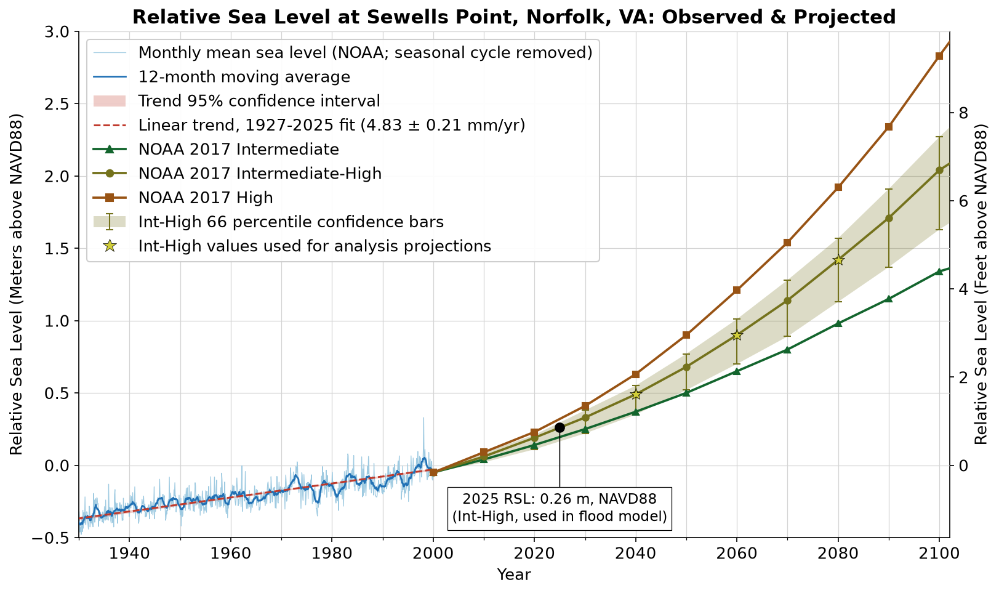

[02.2 A] USACE table vs NOAA API Intermediate-High (both relative to 2000): largest difference 0.000 m over [2040, 2060, 2080]


In [50]:
# ---------------------------------------------------------------------
# 02.2 (Step A) — Fig01: observed relative sea level at Sewells Point and the NOAA (2017) projections (m NAVD88)
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
print("Figure: relative sea level at Sewells Point -- observed record (to 2000) and the NOAA (2017) projections (to 2100)")
# Every series is in meters above NAVD88:
#  - observed record: MSL-relative values + the station's MSL - NAVD88 (01.8 Step B);
#  - NOAA scenarios from the API (relative to 2000): + the USACE table's 2000 value (Z_PROJ, m NAVD88);
#  - Intermediate-High values used in the analysis (USACE table): already in m NAVD88.
Z_PROJ = NOAA_SLR_TABLE[2000]
int_col = SLR_SCENARIO_COLORS.get(SLR_RANGE_SCENARIO, "gray")

# One chart; handles collects the legend entries in drawing order
fig, ax = plt.subplots(figsize=(11, 6.6), dpi=FIG_DPI)
handles = []
if slt is not None:                              # observed record up to 2000 (skipped if the NOAA API was unavailable)
    # Observed record up to 2000; "handles +=" adds the returned line(s) to the list
    _o = slt[slt["DecYear"] <= 2000.0]
    handles += ax.plot(_o["DecYear"], _o["MSL_navd88"], color="#9ecae1", linewidth=0.6, zorder=2,
                       label="Monthly mean sea level (NOAA; seasonal cycle removed)")
    handles += ax.plot(_o["DecYear"], _o["MSL_12mo_navd88"], color="#2171b5", linewidth=1.3, zorder=3,
                       label="12-month moving average")
    # Trend line and its 95 % band (fill_between shades between two curves)
    _t = _o.dropna(subset=["Trend_navd88"])
    handles.append(ax.fill_between(_t["DecYear"], _t["TrendLo_navd88"], _t["TrendHi_navd88"], color="#c0392b", alpha=0.25,
                                   linewidth=0, zorder=2, label="Trend 95% confidence interval"))
    handles += ax.plot(_t["DecYear"], _t["Trend_navd88"], color="#c0392b", linestyle="--", linewidth=1.4, zorder=4,
                       label=f"Linear trend, 1927-{datetime.now().year - 1} fit ({SLT_RATE_MM:.2f} ± {SLT_RATE_CI_MM:.2f} mm/yr)")
# Marker of each NOAA scenario
SCEN_MARKER = {"Intermediate": "^", "Intermediate-High": "o", "High": "s"}
ci_handle = None
# One curve per scenario (skipped if the API gave none)
for scen in SLR_PLOT_SCENARIOS:
    s = slr_proj[slr_proj["Scenario"] == scen].sort_values("Year") if len(slr_proj) else pd.DataFrame()
    if not len(s):
        continue
    col = SLR_SCENARIO_COLORS.get(scen, "gray")
    if scen == SLR_RANGE_SCENARIO and s["Lo_m"].notna().any():
        # likely range: a semi-transparent band over the whole projection period, behind every line, plus error bars
        band = ax.fill_between(s["Year"], s["Lo_m"] + Z_PROJ, s["Hi_m"] + Z_PROJ, color=int_col, alpha=0.25,
                               linewidth=0, zorder=1)          # alpha = 0.25: semi-transparent
        # Error bars from each point down to Lo and up to Hi (yerr = [below, above]); fmt="none" draws only the bars
        eb = ax.errorbar(s["Year"], s["RSL_m"] + Z_PROJ, yerr=[s["RSL_m"] - s["Lo_m"], s["Hi_m"] - s["RSL_m"]],
                         fmt="none", ecolor=col, capsize=3, linewidth=1, zorder=5)
        ci_handle = (band, eb)                      # one legend entry showing the band and a bar together
    handles += ax.plot(s["Year"], s["RSL_m"] + Z_PROJ, color=col, marker=SCEN_MARKER.get(scen, "o"), linewidth=1.8,
                       markersize=SLR_MARKER_SIZE, zorder=6, label=f"NOAA {SLR_REPORT_YEAR} {scen}")
if ci_handle is not None:
    handles.append(ci_handle)
# The Intermediate-High values used for the analysis years (USACE table, m NAVD88): stars around the NOAA points
# Projection years only (2040, 2060, and 2080): 2025 is marked separately below, and 2100 is not a projection year
_yrs = list(PROJECTION_YEARS)
handles += ax.plot(_yrs, [RSLR_BY_YEAR[y] for y in _yrs], linestyle="none", marker="*", markersize=SLR_MARKER_SIZE + 5,
                   markerfacecolor=SLR_STAR_COLOR, markeredgecolor="black", markeredgewidth=0.35, zorder=7,
                   label="Int-High values used for analysis projections")
# 2025, the sea level used for the 2025 flood frequencies. Its callout hangs straight down from the point into the
# empty area under the curves (the observed record stops at 2000): xytext has the same x as the point.
y25 = RSLR_BY_YEAR[FLOOD_YEAR]
ax.plot([FLOOD_YEAR], [y25], "o", markersize=7, color="black", zorder=10)
ax.annotate(f"{FLOOD_YEAR} RSL: {y25:.2f} m, NAVD88\n(Int-High, used in flood model)",
            xy=(FLOOD_YEAR, y25), xytext=(FLOOD_YEAR, SLR_YLIM_M[0] + 0.2), fontsize=fs(9), ha="center", va="center",
            arrowprops=dict(arrowstyle="-", color="black", linewidth=0.8, shrinkA=0, shrinkB=4),
            bbox=dict(boxstyle="square,pad=0.3", facecolor="white", edgecolor="black", linewidth=0.6), zorder=11)
# Legend labels: each line's own label; the (band, error bars) tuple gets one combined label.
labels = [h.get_label() if not isinstance(h, tuple) else "Int-High 66 percentile confidence bars" for h in handles]
# HandlerTuple(ndivide=1) draws the symbols of a tuple on top of each other in one legend entry.
ax.legend(handles, labels, handler_map={tuple: HandlerTuple(ndivide=1)}, loc="upper left", fontsize=fs(10),
          framealpha=0.95, markerscale=1.1)
# Axis ranges, labels, and title
ax.set_xlim(*SLR_XLIM_YEARS)
# Major (labeled) ticks every 20 years and minor (unlabeled) ticks every 10 years, each with a vertical grid line
ax.xaxis.set_major_locator(mticker.MultipleLocator(20))
ax.xaxis.set_minor_locator(mticker.MultipleLocator(10))
ax.set_ylim(*SLR_YLIM_M)
ax.set_xlabel("Year")
ax.set_ylabel("Relative Sea Level (Meters above NAVD88)")
# Right axis: the same range in feet (secondary_yaxis converts with the two functions m -> ft and ft -> m)
sec = ax.secondary_yaxis("right", functions=(lambda m: m / 0.3048, lambda f: f * 0.3048))
sec.set_ylabel("Relative Sea Level (Feet above NAVD88)")
ax.set_title("Relative Sea Level at Sewells Point, Norfolk, VA: Observed & Projected", fontweight="bold")
style_ax(ax)
ax.grid(which="minor", axis="x", color="lightgray", linewidth=0.6)     # vertical grid lines at the minor ticks too
plt.tight_layout()
save_fig(fig, "Fig01_SeaLevel_Observed_Projected", "intro")
plt.show()
if len(slr_proj):                # check: USACE table (minus its 2000 value) vs the API's Intermediate-High (relative to 2000)
    # Largest difference between the USACE table and the API's Intermediate-High, printed as a check
    _ih = slr_proj[slr_proj["Scenario"] == SLR_RANGE_SCENARIO].set_index("Year")["RSL_m"]
    _d = [abs((RSLR_BY_YEAR[y] - Z_PROJ) - _ih[y]) for y in _yrs if y in _ih.index]
    if _d:
        print(f"[02.2 A] USACE table vs NOAA API Intermediate-High (both relative to 2000): largest difference "
              f"{max(_d):.3f} m over {_yrs}")
chart_fonts(False)                     # back to the default fonts

**What the figure shows.** Everything is in meters (left) and feet (right) above NAVD88. The gauge record (blue) follows the linear trend (red, dashed) closely from 1927 to 2000, with no obvious acceleration over that period. The record is shown only up to 2000, the reference year of the projections, so the figure reads as "observed, then projected"; however, the trend was fitted to the full record. From 2000, the NOAA (2017) scenarios accelerate through the century, starting from the USACE table's 2000 level (−0.05 m NAVD88), within a few centimeters of the observed trend (01.8). The Intermediate-High scenario used in eq. (1) lies between the Intermediate and High scenarios; its semi-transparent band and bars show its likely range (17th–83rd percentiles, a 66% range; Sweet et al., 2017). The stars mark the USACE (2022) Intermediate-High values used for the projections (2040, 2060, and 2080) and sit on the NOAA points (the largest difference is printed under the figure). The 2025 value (black dot and callout, 0.26 m NAVD88) is the RSL used for the 2025 flood frequencies; by 2025, the Intermediate-High curve is already above the observed sea level (01.8).

### 02.3 Study Area Map (Fig02)

The study area at three scales: the whole UAS flight (top), its regional context in Norfolk with the Sewells Point tide gauge (bottom left), and a zoomed view of the Botetourt St & Mowbray Arch intersection (bottom right), outlined by the black-and-white box on the top map.

*** THIS IS A BASIC MAP FOR DEMONSTRATIVE PURPOSES. THE FINAL FIGURE 2 MAP IN THE PROJECT REPORT WILL LOOK DIFFERENT THAN BELOW.
Map: study area -- drone imagery and flight footprint, regional context with the Sewells Point tide gauge, and the zoomed view of the Botetourt St & Mowbray Arch intersection


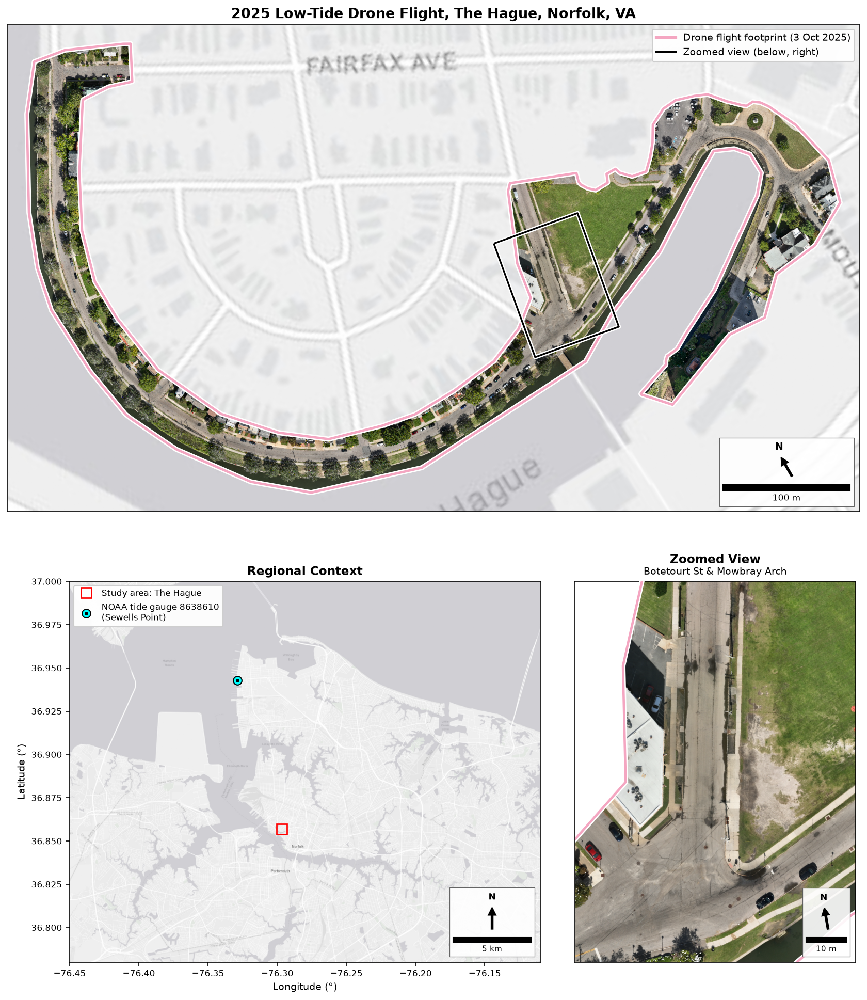

In [51]:
# ---------------------------------------------------------------------
# 02.3 (Step A) — Fig02: study area (imagery and flight footprint, regional context with the tide gauge, and zoomed view)
# ---------------------------------------------------------------------
fig_banner("Fig02")
print("Map: study area -- drone imagery and flight footprint, regional context with the Sewells Point tide gauge, and "
      "the zoomed view of the Botetourt St & Mowbray Arch intersection")
# ---- Layout (inches): the main map across the top; the regional-context map and the zoomed view side by side below.
# Every map axes gets exactly the shape of what it shows, so no map is squeezed or padded.
W = 11.0
# Shape of the regional map: one degree of longitude is cos(latitude) as long as one degree of latitude
lat0 = (LOCATOR_BOUNDS_LL[1] + LOCATOR_BOUNDS_LL[3]) / 2
loc_aspect = ((LOCATOR_BOUNDS_LL[2] - LOCATOR_BOUNDS_LL[0]) * math.cos(math.radians(lat0))
              / (LOCATOR_BOUNDS_LL[3] - LOCATOR_BOUNDS_LL[1]))          # width / height in ground distance
zoom_aspect = STUDY_INSET["width_m"] / STUDY_INSET["height_m"]
# Main-map height from the page width; the two lower maps share one height
main_h = W / site_aspect(15)
gap_l, gap_m, gap_r = 0.8, 0.45, 0.05            # left margin (latitude labels), gap between the two, right margin
bot_h = (W - gap_l - gap_m - gap_r) / (loc_aspect + zoom_aspect)
t_main, t_bot, x_lab, gap_v = 0.45, 0.65, 0.65, 0.25
# Figure height = title + main map + gap + titles + lower maps + axis labels
H = t_main + main_h + gap_v + t_bot + bot_h + x_lab
fig = plt.figure(figsize=(W, H), dpi=FIG_DPI)
# add_axes([left, bottom, width, height]) in fractions of the figure: main map on top, regional map lower left, zoomed
# view lower right
ax = fig.add_axes([0, (x_lab + bot_h + t_bot + gap_v) / H, 1, main_h / H])
ax_loc = fig.add_axes([gap_l / W, x_lab / H, loc_aspect * bot_h / W, bot_h / H])
ax_zoom = fig.add_axes([(gap_l + loc_aspect * bot_h + gap_m) / W, x_lab / H, zoom_aspect * bot_h / W, bot_h / H])

# (a) main map: basemap, imagery, flight footprint (pink with a white halo), and the zoomed-view box
map_background(ax, labels=True)
rot_geoms(gpd.GeoSeries([FOOTPRINT.boundary], crs=REF_CRS)).plot(ax=ax, zorder=5,
                                                                  **outlined(FOOTPRINT_COLOR, 2.2, outline="white", extra=2.5))
draw_window_box(ax, STUDY_INSET, ZOOM_ROTATION_DEG)          # the zoom window drawn in its own (10 deg) frame
set_map_view(ax, FOOTPRINT, pad_m=15)
finish_map(ax, "2025 Low-Tide Drone Flight, The Hague, Norfolk, VA", title_size=13)
# Legend of the main map: the footprint line and the zoom-window box
s = ZOOM_BOX_STYLE
ax.legend(handles=[mlines.Line2D([], [], **outlined(FOOTPRINT_COLOR, 2.5, outline="white", extra=2.5),
                                 label="Drone flight footprint (3 Oct 2025)"),
                   mlines.Line2D([], [], **outlined(s["color"], s["linewidth"], outline=s["outline"], extra=s["extra"]),
                                 label="Zoomed view (below, right)")],
          loc="upper right", fontsize=9, framealpha=0.95)

# (b) regional context in longitude/latitude: all of Norfolk, the study area, and the Sewells Point tide gauge
_lb = LOCATOR_BOUNDS_LL
# Basemap and labels in longitude/latitude for the regional map
_bm = get_basemap(URL_BASEMAP, _lb, "EPSG:4326", "EPSG:4326", "Locator", px=1400)
_bl = get_basemap(URL_BASEMAP_LABELS, _lb, "EPSG:4326", "EPSG:4326", "LocatorLabels", px=1400)
for b in (_bm, _bl):
    if b is not None:
        ax_loc.imshow(b[0], extent=b[1], interpolation="bilinear", zorder=0 if b is _bm else 3)
# Study area marked by a red open square at its center
aoi_ll_c = AOI.to_crs(4326).geometry.iloc[0].centroid
(h_sa,) = ax_loc.plot(aoi_ll_c.x, aoi_ll_c.y, marker="s", markersize=10, markerfacecolor="none", markeredgecolor="red",
                      markeredgewidth=1.3, linestyle="none", zorder=5)
loc_handles, loc_labels = [h_sa], ["Study area: The Hague"]
if GAUGE_LONLAT:
    # Tide gauge: a cyan circle with a black outline and a small black dot in its center (two markers on one point)
    (g1,) = ax_loc.plot(*GAUGE_LONLAT, marker="o", markersize=8, markerfacecolor="cyan", markeredgecolor="black",
                        markeredgewidth=1.0, linestyle="none", zorder=5)
    (g2,) = ax_loc.plot(*GAUGE_LONLAT, marker="o", markersize=2.2, color="black", linestyle="none", zorder=6)
    loc_handles.append((g1, g2))                       # a tuple of handles = one legend entry with both symbols
    loc_labels.append(f"NOAA tide gauge {NOAA_STATION_ID}\n(Sewells Point)")
# Show exactly the regional box
ax_loc.set_xlim(_lb[0], _lb[2]); ax_loc.set_ylim(_lb[1], _lb[3])
ax_loc.set_aspect(1 / math.cos(math.radians(lat0)))       # equal ground distance in x and y at this latitude
ax_loc.set_xlabel("Longitude (°)", fontsize=9); ax_loc.set_ylabel("Latitude (°)", fontsize=9)
ax_loc.tick_params(labelsize=8)
ax_loc.legend(loc_handles, loc_labels, handler_map={tuple: HandlerTuple(ndivide=1)}, loc="upper left", fontsize=8,
              framealpha=0.95)
# The regional map is in degrees: units_per_m converts meters to degrees of longitude (1 degree = 111,320 m x
# cos(latitude))
add_north_arrow_and_scale(ax_loc, rotated=False, units_per_m=1 / (111320 * math.cos(math.radians(lat0))), fontsize=7)
ax_loc.set_title("Regional Context", fontweight="bold", fontsize=11)

# (c) zoomed view: sharper imagery inside the zoom window, rotated by ZOOM_ROTATION_DEG
with map_rotation(ZOOM_ROTATION_DEG):
    map_background(ax_zoom, win=STUDY_INSET, res=STUDY_INSET_IMAGERY_RES_M)
    rot_geoms(gpd.GeoSeries([FOOTPRINT.boundary], crs=REF_CRS)).plot(
        ax=ax_zoom, zorder=5, **outlined(FOOTPRINT_COLOR, 2.2, outline="white", extra=2.5))
    set_map_view(ax_zoom, win=STUDY_INSET)
    finish_map(ax_zoom, fontsize=8)
ax_zoom.set_title("Zoomed View", fontweight="bold", fontsize=11, pad=17)
# Sub-title just above the zoomed view (transform=ax.transAxes: x/y as fractions of the axes)
ax_zoom.text(0.5, 1.012, "Botetourt St & Mowbray Arch", transform=ax_zoom.transAxes, ha="center", va="bottom", fontsize=9)
save_fig(fig, "Fig02_StudyArea", "intro")
plt.show()

**What the figure shows.** The study area (about 0.6 × 0.5 km) lies in central Norfolk on the Hague, a small tidal inlet of the Elizabeth River at the southern edge of the Ghent neighborhood, next to the Chrysler Museum of Art. The inlet connects directly to tidal water, so the surrounding streets flood at high tide. The UAS flight (top) followed the streets around the inlet: Mowbray Arch along the west and south shores, Botetourt St along the field at the south end, and the loop at the east end. The regional-context map (bottom left) places the study area within Norfolk relative to the Sewells Point tide gauge, whose record underlies both eq. (1) and the sea-level projections. The zoomed view (bottom right) shows the Botetourt St & Mowbray Arch intersection at 8 cm, the same window as the crack-workflow panels of Fig03.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 03) Projected Flood Frequency (2040–2080)

Eq. (1) (Ezer, 2022; see **Symbols**) is applied to every 0.5 m cell's *Z*_MHHW for each projection year, with that year's *RSLR*_t from the NOAA (2017) Intermediate-High scenario (USACE, 2022): 0.26 m NAVD88 in 2025, rising to 1.42 m NAVD88 in 2080.

- *F* is capped at 365 days/yr (flooded at every high tide).
- Eq. (1) is a "bathtub" model: it describes tides and surges at the gauge, not rainfall, storm-drain backflow, or future flood protection.
- *F* is exponential in elevation: every 0.1 m of RSLR multiplies it by 10^0.24 ≈ 1.7, and the year term adds a further ×10^0.02 ≈ 1.05 per year.
- **2100 is computed for context only** (`CONTEXT_YEARS`, 00.5 Step D; *RSLR*_t = 2.04 m NAVD88) and is not projected in Sections 04–06 (see the note after FigS05).

One flood-frequency raster per year (2025, every projection year, and 2100) is written to `DATA/03_Results_Data/OUT_DATA_NB01_Sec03_FloodDaysRasters/` (Step A). Step B summarizes the pavement's flood frequency by year, including the share of the pavement below that year's MHHW (*Z*_MHHW < *RSLR*_t), and Step C compares the years' distributions (supplementary visual check FigS05: overlaid histograms with kernel density curves, one color per year).

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 03.1 Flood Frequency for Every Projection Year

Eq. (1) is applied to the projection years, with the pavement's flood frequency summarized and compared year by year.

In [52]:
# ---------------------------------------------------------------------
# 03.1 (Step A) — Flood days per year for every projection year; write one raster per year (2025 included)
# ---------------------------------------------------------------------

OUT03 = out_dir(3, "FloodDaysRasters", results=True)
for y in ALL_FLOOD_YEARS:                           # 2025, the projection years, and 2100 (context)
    if y not in FLOOD:                                   # 2025 was computed in 01.3 (Step E)
        FLOOD[y] = flood_days(y)
    write_tif(FLOOD[y], OUT03 / f"FloodDays_{y}_0p5m.tif", G_T)
# map(str, list) turns each year into text; ", ".join() strings them together
print(f"[03.1 A] {len(ALL_FLOOD_YEARS)} flood-days rasters ({', '.join(map(str, ALL_FLOOD_YEARS))}) -> {OUT03.relative_to(PROJECT)}")

[03.1 A] 5 flood-days rasters (2025, 2040, 2060, 2080, 2100) -> DATA\03_Results_Data\OUT_DATA_NB01_Sec03_FloodDaysRasters


In [53]:
# ---------------------------------------------------------------------
# 03.1 (Step B) — Flood frequency of the pavement by year (pixel level, weighted by pavement area)
# ---------------------------------------------------------------------

_w = mask_cnt.astype("float64")                  # pavement pixels per 0.5 m cell = area weights for the summary
_rows = []
# One summary row per year: 0.5 m cells with pavement and a flood value
for y in ALL_FLOOD_YEARS:
    ok = np.isfinite(FLOOD[y]) & (_w > 0)
    v, w = FLOOD[y][ok], _w[ok]
    below = wtrhc_g[ok] < RSLR_BY_YEAR[y]       # pavement below that year's MHHW (elevation above MHHW < RSLR)
    # np.average(values, weights=w) = weighted mean; (v >= 30) is True/False, so its weighted mean is a share.
    _rows.append({"Year": y if y not in CONTEXT_YEARS else f"{y} (context)", "RSLR (m)": RSLR_BY_YEAR[y],
                  "Mean flood days/yr (pavement)": np.average(v, weights=w),
                  "% pavement >= 3 days/yr": 100 * np.average(v >= 3, weights=w),
                  "% pavement >= 30 days/yr": 100 * np.average(v >= 30, weights=w),
                  "% pavement >= half the year": 100 * np.average(v >= DAYS_PER_YEAR / 2, weights=w),
                  "% pavement flooded every day": 100 * np.average(v >= DAYS_PER_YEAR - 1e-6, weights=w),
                  "% pavement below that year's MHHW": 100 * np.average(below, weights=w)})
# Rows -> table (years as the index), saved as CSV
flood_summary = pd.DataFrame(_rows).set_index("Year")
flood_summary.to_csv(OUT03 / "FloodDays_Summary_Pavement.csv")
display(flood_summary.round(1).assign(**{"RSLR (m)": flood_summary["RSLR (m)"].round(2)}))

,RSLR (m),Mean flood days/yr (pavement),% pavement >= 3 days/yr,% pavement >= 30 days/yr,% pavement >= half the year,% pavement flooded every day,% pavement below that year's MHHW
Year,,,,,,,
2025,0.26,9.1,52.4,8.0,0.0,0.0,8.4
2040,0.49,60.9,79.5,46.3,10.1,2.3,31.2
2060,0.90,263.4,99.0,90.2,70.2,58.9,72.7
2080,1.42,360.7,100.0,99.9,98.8,97.8,97.8
2100 (context),2.04,365.0,100.0,100.0,100.0,100.0,99.9


*** THIS IS SUPPLEMENTARY FIGURE S05. IT IS NOT IN THE MAIN PROJECT REPORT.
Figure: distribution of the pavement's modeled flood days per year, 2025-2100 (supplementary visual check)


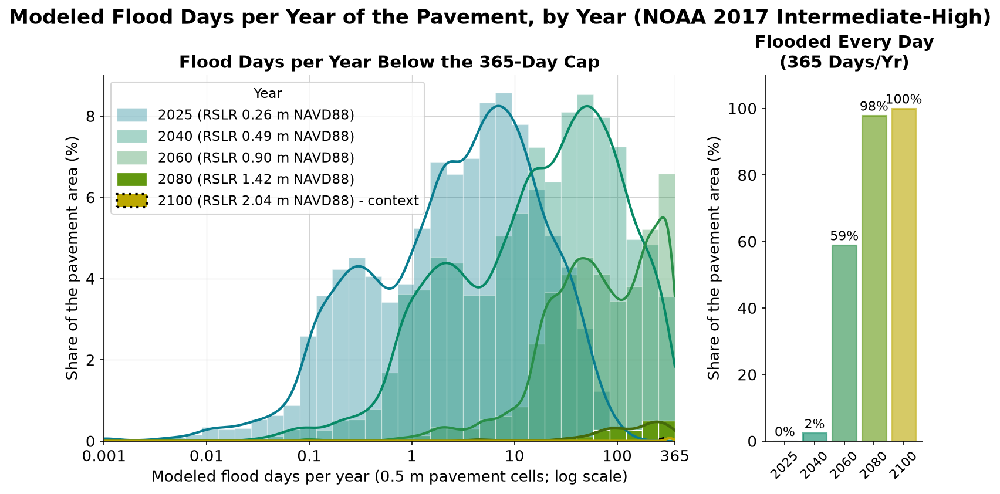

In [54]:
# ---------------------------------------------------------------------
# 03.1 (Step C) — FigS05 (supplementary visual check): distribution of the pavement's flood days per year by year
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
fig_banner("FigS05", is_map=False)
print("Figure: distribution of the pavement's modeled flood days per year, 2025-2100 (supplementary visual check)")
# Left: overlaid, semi-transparent histograms of log10(flood days) below the 365-day cap, one per year, each with a
# smooth density curve (Gaussian kernel density estimate, KDE) in the same color. Bar heights = share of ALL of the
# pavement (%), so the bars of a year add up to its share below the cap. Right: the share flooded EVERY day (365), which
# would dwarf the other bins if drawn on the same axis. The last two years (2080 and 2100) have little pavement below
# the cap, so their bars are drawn opaque, 2100 in front of 2080 (zorder); every curve is drawn over the bars. The 2080
# curve is a darker shade of its color, so it shows against its own opaque bars, and the 2100 curve has a thick dotted
# black outline (a wide dotted black line drawn under it).
# LOW = smallest value shown (0.001 days); CAP = 365 days (minus a tiny tolerance)
LOW, CAP = 1e-3, DAYS_PER_YEAR - 1e-6
edges = np.linspace(np.log10(LOW), np.log10(DAYS_PER_YEAR), 36)      # bins on the log10 scale
bin_w = edges[1] - edges[0]
xg = np.linspace(edges[0], edges[-1], 400)                            # where the density curves are drawn
# One color per year (i % n repeats the colors if there are more years than colors)
year_cols = {y: YEAR_COLORS[i % len(YEAR_COLORS)] for i, y in enumerate(ALL_FLOOD_YEARS)}
rng = np.random.default_rng(0)                                        # fixed seed: the same subsample every run
OPAQUE_YEARS = [PROJECTION_YEARS[-1]] + list(CONTEXT_YEARS)           # opaque bars: 2080 and 2100
ctx_handles = []                                                      # legend symbols drawn by hand (2100)
# Two panels side by side: width_ratios makes the left one about 4x wider
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5.4), dpi=FIG_DPI, gridspec_kw=dict(width_ratios=[4, 1.1], wspace=0.25))
# full[year] = % of the pavement flooded every day (right panel)
full = {}
for y in ALL_FLOOD_YEARS:
    ok = np.isfinite(FLOOD[y]) & (_w > 0)
    v, w = FLOOD[y][ok], _w[ok]
    # Split each year's pavement into "flooded every day" and the rest (left panel)
    every = v >= CAP
    full[y] = 100 * w[every].sum() / w.sum()
    lv = np.log10(np.clip(v[~every], LOW, None))                      # log10 flood days below the cap
    lw_ = 100 * w[~every] / w.sum()                                   # weights: % of all pavement
    col = year_cols[y]
    # Legend label: the year and its sea level
    lab = f"{y} (RSLR {RSLR_BY_YEAR[y]:.2f} m NAVD88)" + (" - context" if y in CONTEXT_YEARS else "")
    ctx = y in CONTEXT_YEARS                                          # True for 2100
    opq = y in OPAQUE_YEARS                                           # True for 2080 and 2100
    # Drawing order (zorder): semi-transparent bars 1, 2080 bars 3, 2100 bars 4, curves 6 and above
    z_bar = (4 if ctx else 3) if opq else 1
    # hist(..., weights=...) adds up the weights (here % of pavement) of the values in each bin instead of counting them.
    # The 2100 bars get no automatic legend entry ("_nolegend_"); their symbol is made by hand below.
    ax.hist(lv, bins=edges, weights=lw_, color=col, alpha=1.0 if opq else 0.35, edgecolor="white", linewidth=0.6,
            zorder=z_bar, label="_nolegend_" if ctx else lab)
    if ctx:      # legend symbol of 2100: its color with a thick dotted black outline, like its curve
        ctx_handles.append(mpatches.Patch(facecolor=col, edgecolor="black", linestyle=":", linewidth=2.0, label=lab))
    if len(lv) > 20:
        # KDE of the (pavement-weighted) values, scaled to the bar heights: density x share below the cap x bin width
        # rng.choice picks up to 20,000 values at random (no repeats), which keeps the KDE fast
        idx = rng.choice(len(lv), size=min(len(lv), 20000), replace=False)
        try:
            kde = stats.gaussian_kde(lv[idx], weights=lw_[idx])
            yk = kde(xg) * lw_.sum() * bin_w
            if ctx:          # 2100: thick dotted black line first, then the colored curve on top of it
                # (the outline is left out where the curve is flat at ~0, so no dotted line runs along the x axis)
                ax.plot(xg, np.where(yk > 0.01 * yk.max(), yk, np.nan), color="black", linewidth=5, linestyle=":",
                        zorder=7)
            # 2080 (opaque, not context): 30 % darker shade of its color (RGB values x 0.7), so it shows on its own bars
            lc = mcolors.to_hex(0.7 * np.array(mcolors.to_rgb(col))) if (opq and not ctx) else col
            ax.plot(xg, yk, color=lc, linewidth=2.2 if opq else 2, zorder=8 if ctx else 6)
        except np.linalg.LinAlgError:                                 # all values (almost) equal: no curve
            pass
# Tick labels in days, at their log10 positions
_ticks = [-3, -2, -1, 0, 1, 2, np.log10(DAYS_PER_YEAR)]
ax.set_xticks(_ticks)
ax.set_xticklabels(["0.001", "0.01", "0.1", "1", "10", "100", "365"])
ax.set_xlim(edges[0], edges[-1])
ax.set_ylim(bottom=0)
ax.set_xlabel("Modeled flood days per year (0.5 m pavement cells; log scale)")
ax.set_ylabel("Share of the pavement area (%)")
ax.set_title("Flood Days per Year Below the 365-Day Cap", fontweight="bold", fontsize=fs(11))
# Legend (the automatic entries, then the hand-made 2100 symbol), grid behind the bars, and the frame (style_ax)
_h, _l = ax.get_legend_handles_labels()
ax.legend(_h + ctx_handles, _l + [h.get_label() for h in ctx_handles], loc="upper left", fontsize=fs(9), title="Year",
          title_fontsize=fs(9), handlelength=2.2, handleheight=1.1)
style_ax(ax)
# Right panel: one bar per year, with its percentage written above it
ax2.bar(range(len(ALL_FLOOD_YEARS)), [full[y] for y in ALL_FLOOD_YEARS], color=[year_cols[y] for y in ALL_FLOOD_YEARS],
        alpha=0.6, edgecolor=[year_cols[y] for y in ALL_FLOOD_YEARS], linewidth=1.5)
for i, y in enumerate(ALL_FLOOD_YEARS):
    ax2.text(i, full[y] + 1.5, f"{full[y]:.0f}%", ha="center", fontsize=fs(8.5))
ax2.set_xticks(range(len(ALL_FLOOD_YEARS))); ax2.set_xticklabels(ALL_FLOOD_YEARS, rotation=45, fontsize=fs(8.5))
ax2.set_ylim(0, 110); ax2.set_ylabel("Share of the pavement area (%)")
ax2.set_title("Flooded Every Day\n(365 Days/Yr)", fontweight="bold", fontsize=fs(11))
for sp in ("top", "right"):
    ax2.spines[sp].set_visible(False)
# Title over both panels (y=1.02 = just above the figure)
fig.suptitle("Modeled Flood Days per Year of the Pavement, by Year (NOAA 2017 Intermediate-High)", fontweight="bold",
             fontsize=fs(13), y=1.02)
save_fig(fig, "FigS05_FloodDays_Distribution_byYear", "supp")
plt.show()
chart_fonts(False)                     # back to the default fonts

**What the table and figure show.** Under the Intermediate-High scenario, the pavement's modeled flood frequency rises steeply. In the author's run, the pavement-weighted mean rose from about 9 days/yr in 2025 to about 61 in 2040, 263 in 2060, and 361 in 2080. The share of pavement flooded at least 30 days/yr went from 8% (2025) to 46% (2040), 90% (2060), and nearly 100% (2080), and the share flooded *every* day went from 0% to 2%, 59%, and 98%. FigS05 shows the same shift: the whole distribution slides to the right decade by decade and piles up at the 365-day cap.

**Why the projections stop at 2080.** Under the Intermediate-High scenario, RSL at Sewells Point rises about 2 m between 2000 and 2100 (Sweet et al., 2017; USACE, 2022), while the study area's pavement sits only about 0.5–1 m above present-day MHHW. By 2100 (*RSLR*_t = 2.04 m), essentially all of the pavement (99.96% in the author's run) floods every day, and the last column of the table shows that nearly all of it lies *below* that year's MHHW. At that point *F* hits its 365-day cap everywhere and can no longer separate one cell from another; a road underwater at every high tide is an inundation problem rather than a cracking problem. The crack projections (Section 06) therefore stop at 2080. Even 2080 is close to the cap: for 2080, eq. (1) gives *A* = 2 − 2.4·(*Z*_MHHW − *RSLR*_t), so a cell floods every day (*A* ≥ 2) exactly when *Z*_MHHW ≤ *RSLR*_t. Thus, the 98% of pavement flooded every day in 2080 is also the share below that year's MHHW, and the 2080 projections mark the upper end of what the relationship can say.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 04) Analysis Cells & Variables

The analysis cells and their variables are built in five steps:

1. **Fishnet (04.1).** A fishnet of 5 m × 5 m squares starts at the lower-left corner of the shrunk road mask and is aligned to the 0.5 m raster grid (shifted by < 0.5 m), so each square holds exactly 10 × 10 raster cells or 250 × 250 imagery pixels.
2. **Per-cell values (04.1),** all over the cell's masked pavement pixels:
   - `CrackDens` (*y*): crack pixels ÷ classified pavement pixels, i.e., the zonal mean of the 0/1 crack raster;
   - `LogFloodDays_<year>`: the mean of log₁₀(*F* + 10⁻⁴), i.e., log₁₀ of the cell's **geometric-mean** flood frequency (`FloodDaysGeo_<year>`), for 2025 and every projection year. *F* is exponential in elevation, so an arithmetic mean would be dominated by a cell's lowest pixels;
   - `ElevMHHW`: the mean *Z*_MHHW.
3. **Clip (04.2).** Every square is clipped to the pavement, which gives the **analysis cells**. Every cell with pavement is kept, including small edge slivers. `CellArea_m2` and `AreaFrac` (share of a full square) record their size; the pavement area is the cell's weight in the models.
4. **Surface type and traffic (04.2).**
   - `SidewalkFrac` = the share of the cell's pavement inside the sidewalk/driveway surface.
   - Cells with `SidewalkFrac` ≥ 0.5 are **Sidewalk** cells and get AADT = 0.
   - The others are **Road** cells. Each takes the AADT of the traffic polygon (01.5) that covers most of it, or stays **Uncounted road** if none does (AADT = 0 where a number is needed, but kept as its own class).
5. **Traffic/surface class (04.2):** Sidewalk/driveway, Uncounted road, or each distinct AADT value present. It is the traffic control (class *c*) of the models.

**04.3** then summarizes the variables, and **04.4** makes the Methods maps (Fig03 and Fig04). Two supplementary visual checks are made along the way: a map of the analysis cells (FigS06, 04.2) and the distributions of the per-cell variables (FigS07, 04.3).

Outputs: `DATA/03_Results_Data/OUT_DATA_NB01_Sec04_AnalysisCells/` (GeoPackage layer and CSV, one row per cell).

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 04.1 Fishnet & Per-Cell Values

The 5 m fishnet is laid on the 0.5 m raster grid (Step A), and for each square's pixel counts, crack density, elevation, and flood frequency are summed or averaged over its pavement (Step B).

In [55]:
# ---------------------------------------------------------------------
# 04.1 (Step A) — Fishnet aligned to the 0.5 m grid (origin at the road mask's lower-left corner); summing helpers
# ---------------------------------------------------------------------
t0 = time.time()
K = int(round(FISHNET_CELL_M / G_RES))                    # 0.5 m cells per fishnet side (10)
if abs(K * G_RES - FISHNET_CELL_M) > 1e-9:
    raise ValueError(f"FISHNET_CELL_M must be a multiple of {G_RES} m")
fn_c0 = int(math.floor((mm["bounds"][0] - REF_X0) / G_RES + 1e-9))          # fishnet origin column (0.5 m grid)
fn_rb = int(math.ceil((REF_Y0 - mm["bounds"][1]) / G_RES - 1e-9))            # fishnet bottom-edge row (0.5 m grid)
_fr = (fn_rb - 1 - np.arange(G_H)) // K          # fishnet row of every 0.5 m row (counted up from the origin); // = floor division
_fc = (np.arange(G_W) - fn_c0) // K              # fishnet column of every 0.5 m column
# Number of fishnet columns; each square gets the ID row x FN_C + column
FN_C = int(_fc.max()) + 1
_FR, _FC = np.meshgrid(_fr, _fc, indexing="ij")  # 2-D arrays of the row / column numbers
# -1 = 0.5 m cells left of / below the fishnet origin (outside every square)
fish_id = np.where((_FR >= 0) & (_FC >= 0), _FR * FN_C + _FC, -1)           # fishnet square of every 0.5 m cell
_ids = fish_id.ravel()                           # .ravel() flattens a 2-D array into 1-D
# _sel = cells inside a square; _N = number of squares
_sel = _ids >= 0
_N = (int(_fr.max()) + 1) * FN_C


# fish_sum(): adds up a 0.5 m raster over each 5 m fishnet square
def fish_sum(arr):
    """Sum of a 0.5 m array within every fishnet square (np.bincount adds the weights that share an ID)."""
    return np.bincount(_ids[_sel], weights=arr.ravel()[_sel].astype("float64"), minlength=_N)


# fish_wmean(): pavement-weighted mean of a 0.5 m raster over each 5 m fishnet square
def fish_wmean(arr, w=mask_cnt):
    """Mean of a 0.5 m array within every fishnet square, weighted by the pavement pixels of each 0.5 m cell
    (= the mean over the square's pavement); NaN values are ignored."""
    # Values and weights of the cells inside squares; ok = valid value and some pavement
    v, ww = arr.ravel()[_sel].astype("float64"), w.ravel()[_sel].astype("float64")
    ok = np.isfinite(v) & (ww > 0)
    # Weighted sum and sum of weights per square; mean = num / den (NaN where no weight)
    num = np.bincount(_ids[_sel][ok], weights=(v * ww)[ok], minlength=_N)
    den = np.bincount(_ids[_sel][ok], weights=ww[ok], minlength=_N)
    return np.where(den > 0, num / np.maximum(den, 1e-12), np.nan)
print(f"[04.1 A] fishnet: {K} x {K} raster cells per {FISHNET_CELL_M} m square, {_N:,} squares over the grid")

[04.1 A] fishnet: 10 x 10 raster cells per 5 m square, 11,543 squares over the grid


In [56]:
# ---------------------------------------------------------------------
# 04.1 (Step B) — Per-cell values: pixel counts, crack density, elevation, and flood days for every year
# ---------------------------------------------------------------------
# Pavement, crack, and classified 2 cm pixels in every square
_maskpx, _crackpx, _validpx = fish_sum(mask_cnt), fish_sum(crack_cnt), fish_sum(valid_cnt)
# np.flatnonzero = positions of the True values: the IDs of squares with pavement
fid = np.flatnonzero(_maskpx > 0)                                # squares that contain pavement
# One row per analysis cell: its fishnet ID, row and column (// and % = whole-number division and remainder)
cells = pd.DataFrame({"FishnetID": fid, "FishRow": fid // FN_C, "FishCol": fid % FN_C})
cells["CellID"] = np.arange(1, len(cells) + 1)
cells["MaskPx"], cells["CrackPx"], cells["ValidPx"] = _maskpx[fid], _crackpx[fid], _validpx[fid]
# Pavement area of the cell (m2) and its share of the 5 m x 5 m square
cells["CellArea_m2"] = cells["MaskPx"] * REF_RES ** 2
cells["AreaFrac"] = cells["CellArea_m2"] / FISHNET_CELL_M ** 2
# Crack density = crack pixels / classified pavement pixels (0 if none are classified)
cells["CrackDens"] = np.where(cells["ValidPx"] > 0, cells["CrackPx"] / cells["ValidPx"].clip(lower=1), 0.0)
# Mean elevation above MHHW of the cell's pavement
cells["ElevMHHW"] = fish_wmean(wtrhc_g)[fid]
# Flood days of every year: mean of log10(days + offset) over the pavement, and its geometric mean in days
for y in FLOOD_YEARS:
    cells[f"LogFloodDays_{y}"] = fish_wmean(np.log10(FLOOD[y] + LOG_FD_OFFSET_DAYS))[fid]
    cells[f"FloodDaysGeo_{y}"] = (10 ** cells[f"LogFloodDays_{y}"] - LOG_FD_OFFSET_DAYS).clip(lower=0)
cells["LogFloodDays"] = cells[f"LogFloodDays_{FLOOD_YEAR}"]      # short names for the observed year
cells["FloodDaysGeo"] = cells[f"FloodDaysGeo_{FLOOD_YEAR}"]
print(f"[04.1 B] {len(cells):,} analysis cells contain pavement ({time.time() - t0:.1f} s)")

[04.1 B] 1,129 analysis cells contain pavement (0.3 s)


### 04.2 Cell Polygons, Surface Type, & Traffic Class

Each fishnet square is clipped to the pavement to give the analysis cells, which then receive their surface type and traffic class. The pavement inside each square is drawn at the 0.5 m resolution of the raster grid (Step A); pixel-based values (area and crack density) use the exact 0.02 m counts. Step B maps the cells as a supplementary visual check (FigS06) right after the cell polygons are made. Step C assigns the surface type and traffic count; Step D assigns the traffic/surface class with its display color and marker; and Step E writes the cells and keeps those used in the analysis.

In [57]:
# ---------------------------------------------------------------------
# 04.2 (Step A) — Cell polygons: each fishnet square clipped to the pavement (0.5 m outline)
# ---------------------------------------------------------------------
t0 = time.time()
_geoms = []
for fr_, fc_ in zip(cells["FishRow"], cells["FishCol"]):         # zip() walks through two lists side by side
    # Rows and columns of this square on the 0.5 m grid
    r0, r1 = max(0, fn_rb - K * (fr_ + 1)), max(0, fn_rb - K * fr_)
    c0, c1 = fn_c0 + K * fc_, min(G_W, fn_c0 + K * (fc_ + 1))
    blk = road_g[r0:r1, c0:c1]                                     # pavement 0.5 m cells inside this square
    # Georeferencing of the block (its top-left corner), so the polygons land in the right place
    t = from_origin(REF_X0 + c0 * G_RES, REF_Y0 - r0 * G_RES, G_RES, G_RES)
    # features.shapes() traces the outline of the pavement cells (mask=blk) as polygons; they are merged into one
    # geometry per cell
    parts = [shapely.geometry.shape(g) for g, _ in features.shapes(blk.astype("uint8"), mask=blk, transform=t)]
    _geoms.append(shapely.union_all(parts) if parts else shapely.Polygon())
# Cell polygons with their IDs, and the centroid (center point) of each
cells_gdf = gpd.GeoDataFrame(cells[["CellID"]].copy(), geometry=_geoms, crs=REF_CRS)
_cen = cells_gdf.geometry.centroid
cells["CentroidX"], cells["CentroidY"] = _cen.x.values, _cen.y.values
print(f"[04.2 A] {len(cells_gdf):,} cell polygons ({time.time() - t0:.1f} s)")

[04.2 A] 1,129 cell polygons (0.8 s)


*** THIS IS SUPPLEMENTARY FIGURE S06. IT IS NOT IN THE MAIN PROJECT REPORT.
*** THIS IS A BASIC MAP FOR A VISUAL CHECK OF THE OUTPUTS SO FAR.
Map: the 1,129 analysis cells (5 m fishnet clipped to the shrunk road mask; supplementary visual check)


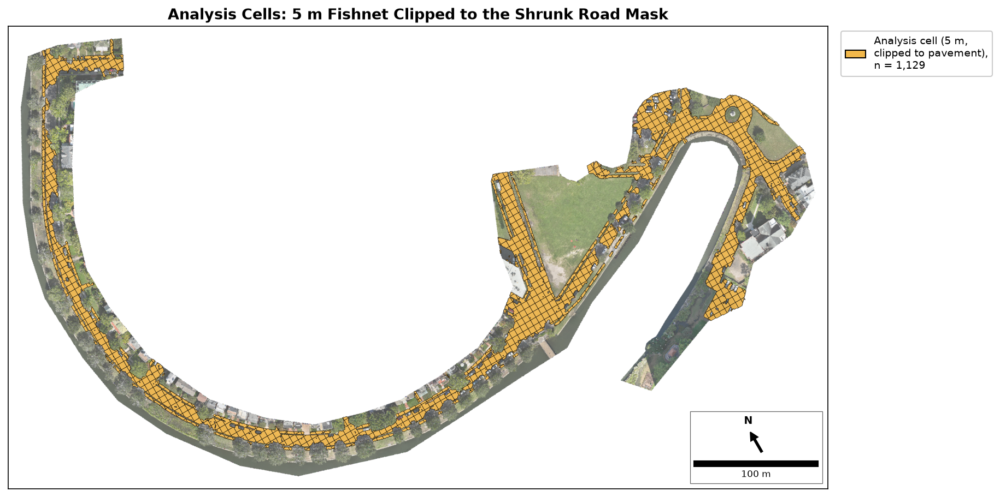

In [58]:
# ---------------------------------------------------------------------
# 04.2 (Step B) — FigS06 (supplementary visual check): map of the analysis cells (fishnet clipped to the shrunk road mask)
# ---------------------------------------------------------------------
fig_banner("FigS06")
print(f"Map: the {len(cells_gdf):,} analysis cells ({FISHNET_CELL_M} m fishnet clipped to the shrunk road mask; "
      f"supplementary visual check)")
# Imagery at 70 % opacity, then the cell polygons
fig, ax = site_map_figure(right_in=2.8)
draw_imagery(ax, alpha=0.7)
rot_geoms(cells_gdf).plot(ax=ax, facecolor=CELL_FILL_COLOR, edgecolor="black", linewidth=0.3, alpha=0.9, zorder=2)
set_map_view(ax, FOOTPRINT, pad_m=10)
finish_map(ax, f"Analysis Cells: {FISHNET_CELL_M} m Fishnet Clipped to the Shrunk Road Mask", title_size=13)
# One-entry legend (a Patch is a filled-box symbol) outside the map
ax.legend(handles=[mpatches.Patch(facecolor=CELL_FILL_COLOR, edgecolor="black",
                                  label=f"Analysis cell ({FISHNET_CELL_M} m,\nclipped to pavement),\nn = {len(cells_gdf):,}")],
          loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9, framealpha=1)
save_fig(fig, "FigS06_AnalysisCells_FullSite", "supp")
plt.show()

In [59]:
# ---------------------------------------------------------------------
# 04.2 (Step C) — Sidewalk share, surface type, and traffic (largest-overlap traffic polygon)
# ---------------------------------------------------------------------
# Surface type: share of each cell's pavement inside the sidewalk/driveway surface.
_area = cells_gdf.area.values
# Pavement area of each cell inside the sidewalk/driveway surface (vectorized shapely: all cells at once)
_sw_area = shapely.area(shapely.intersection(cells_gdf.geometry.values, sw_surface)) if not sw_surface.is_empty \
    else np.zeros(len(cells_gdf))
cells["SidewalkFrac"] = np.clip(_sw_area / np.maximum(_area, 1e-9), 0, 1)
# Sidewalk if at least SIDEWALK_FRAC_THRESHOLD of the cell is sidewalk/driveway
cells["SurfaceType"] = np.where(cells["SidewalkFrac"] >= SIDEWALK_FRAC_THRESHOLD, "Sidewalk", "Road")
# Traffic: the AADT of the traffic polygon that covers the largest part of each cell (gpd.overlay = intersection).
cells["AADT_Count"] = np.nan
if len(aadt_poly):
    ov = gpd.overlay(cells_gdf[["CellID", "geometry"]], aadt_poly[["PolyID", "AADT", "geometry"]], how="intersection",
                     keep_geom_type=True)
    # groupby(CellID)[OvArea].idxmax() = row of the largest overlap of each cell
    ov["OvArea"] = ov.area
    best = ov.loc[ov.groupby("CellID")["OvArea"].idxmax()].set_index("CellID")   # largest overlap per cell
    cells["AADT_Count"] = cells["CellID"].map(best["AADT"]).astype(float)
cells.loc[cells["SurfaceType"] == "Sidewalk", "AADT_Count"] = np.nan        # sidewalks never take a road's count


# traffic_class(): traffic / surface class of a cell from its surface type and AADT
def traffic_class(surface, aadt):
    """Traffic / surface class of one cell: Sidewalk/driveway, Uncounted road, or 'AADT <count>'."""
    if surface == "Sidewalk":
        return "Sidewalk/driveway"
    if pd.isna(aadt):
        return "Uncounted road"
    return f"AADT {int(aadt):,}"


# Class of every cell (list comprehension over surface type and AADT pairs)
cells["TrafficClass"] = [traffic_class(s, a) for s, a in zip(cells["SurfaceType"], cells["AADT_Count"])]
# Classes with fewer than MIN_CLASS_CELLS cells are merged into "Other (small classes)"
_small = [c for c, k in cells["TrafficClass"].value_counts().items() if k < MIN_CLASS_CELLS]
cells.loc[cells["TrafficClass"].isin(_small), "TrafficClass"] = "Other (small classes)"
# Numeric AADT (vehicles/day) for continuous uses: counted value, or 0 for sidewalks and uncounted roads.
cells["AADT"] = cells["AADT_Count"].fillna(-1)
cells.loc[cells["SurfaceType"] == "Sidewalk", "AADT"] = SIDEWALK_AADT_VALUE
cells.loc[(cells["SurfaceType"] == "Road") & cells["AADT_Count"].isna(), "AADT"] = UNCOUNTED_AADT_VALUE
print(f"[04.2 C] {int((cells['SurfaceType'] == 'Sidewalk').sum())} sidewalk/driveway cells; {int(cells['AADT_Count'].notna().sum())} road cells with a count; {int(((cells['SurfaceType'] == 'Road') & cells['AADT_Count'].isna()).sum())} uncounted road cells")

[04.2 C] 360 sidewalk/driveway cells; 628 road cells with a count; 141 uncounted road cells


In [60]:
# ---------------------------------------------------------------------
# 04.2 (Step D) — Display order, colors, and scatter markers of the traffic / surface classes
# ---------------------------------------------------------------------
# _class_rank(): sort key that puts the traffic / surface classes in display order
def _class_rank(c):
    """Display order: Uncounted road, Sidewalk/driveway, counted roads by AADT, then anything else."""
    if c == "Uncounted road":
        return (0, 0)
    if c == "Sidewalk/driveway":
        return (1, 0)
    if c.startswith("AADT "):
        # Counted roads sort by their AADT: c[5:] drops "AADT "; the comma is removed
        return (2, float(c[5:].replace(",", "")))
    return (3, 0)


# Classes in display order (key= sorts by _class_rank); then the counted (AADT) classes
TRAFFIC_ORDER = sorted(cells["TrafficClass"].unique(), key=_class_rank)
_aadt_cls = [c for c in TRAFFIC_ORDER if c.startswith("AADT")]
# AADT classes: spread over TRAFFIC_AADT_RANGE of the purple ramp (light = low traffic, dark = high traffic)
CLASS_COLORS = {**TRAFFIC_BASE_COLORS, "Other (small classes)": "#bdbdbd",
                **dict(zip(_aadt_cls, [mcolors.to_hex(c) for c in plt.get_cmap(TRAFFIC_AADT_CMAP)(
                    np.linspace(*TRAFFIC_AADT_RANGE, max(1, len(_aadt_cls))))]))}
# Scatter markers: one shared marker for sidewalks/uncounted roads, one per AADT class
CLASS_MARKERS = {c: TRAFFIC_BASE_MARKER for c in TRAFFIC_ORDER}
CLASS_MARKERS.update({c: TRAFFIC_AADT_MARKERS[i % len(TRAFFIC_AADT_MARKERS)] for i, c in enumerate(_aadt_cls)})
print(f"[04.2 D] classes: {TRAFFIC_ORDER}")

[04.2 D] classes: ['Uncounted road', 'Sidewalk/driveway', 'AADT 260', 'AADT 1,200', 'AADT 4,500']


In [61]:
# ---------------------------------------------------------------------
# 04.2 (Step E) — Write the analysis cells (GeoPackage layer + CSV) and keep the cells used in the analysis
# ---------------------------------------------------------------------
# Attach every per-cell value to the cell polygons and save them (GeoPackage) and the table (CSV)
cells_gdf = gpd.GeoDataFrame(cells.copy(), geometry=cells_gdf.geometry.values, crs=REF_CRS)
OUT04 = out_dir(4, "AnalysisCells", results=True)
cells_gdf.to_file(OUT04 / f"AnalysisCells_{FISHNET_CELL_M}m.gpkg", layer=f"AnalysisCells_{FISHNET_CELL_M}m", driver="GPKG")
cells.to_csv(OUT04 / f"AnalysisCells_{FISHNET_CELL_M}m.csv", index=False)
# Cells used in the analysis: those with a flood-days value (not entirely open water / outside the DEM).
cells_m = cells[cells["LogFloodDays"].notna()].reset_index(drop=True)
# Largest crack density of a cell (used for axis limits)
CRACK_MAX = float(cells_m["CrackDens"].max())
print(f"[04.2 E] cells written; {len(cells_m):,} of {len(cells):,} cells have a "
      f"flood-days value -> {OUT04.relative_to(PROJECT)}")
# Cells per class, in display order (reindex)
display(cells["TrafficClass"].value_counts().reindex(TRAFFIC_ORDER).to_frame("# cells"))

[04.2 E] cells written; 1,129 of 1,129 cells have a flood-days value -> DATA\03_Results_Data\OUT_DATA_NB01_Sec04_AnalysisCells


,# cells
TrafficClass,
Uncounted road,141
Sidewalk/driveway,360
AADT 260,354
"AADT 1,200",207
"AADT 4,500",67


**What the table shows.** In the author's run, 360 of the 1,129 cells were mostly sidewalk/driveway (Sidewalk, AADT = 0), and 769 were road cells. Of the road cells, 628 (81.7%) took an AADT from the traffic polygon, and 141 were on uncounted roads. 

Only three of the seven counts reach the cells: 260 (Mowbray Arch), 1,200 (Botetourt St, Fairfax Ave, and other side streets), and 4,500 (Memorial Pl and Yarmouth St). The uncounted roads are mostly the parking-lot lanes and drives at the east end (`Custom_AddRCL`), plus road pavement wider than the 6 m buffer. 

The supplementary map (FigS06) shows the cells tiling the pavement corridor continuously, with full 5 m × 5 m squares in the streets and clipped slivers along the curbs, sidewalks, and driveways.

*The report map of the cells by traffic/surface class (Fig04) is made in 04.4.*

### 04.3 Descriptive Statistics

The analysis variables are summarized before they are modeled: Step A gives their descriptive statistics; Step B gives their distributions (supplementary visual check FigS07); and Step C gives the Spearman (1904) rank correlation of each predictor with crack density. These p-values treat the cells as independent, which they are not (05.2), so they are optimistic.

In [62]:
# ---------------------------------------------------------------------
# 04.3 (Step A) — Descriptive statistics of the analysis variables
# ---------------------------------------------------------------------
# describe(): one row of descriptive statistics of a variable
def describe(v, name, units):
    """Count, mean, SD, quartiles, max, and skewness of one variable (NaN ignored)."""
    # Values as a float Series without NaN; quantile(0.25) = first quartile, etc.
    v = pd.Series(v, dtype="float64").dropna()
    return pd.Series({"Units": units, "n": len(v), "Mean": v.mean(), "SD": v.std(), "Min": v.min(),
                      "Q1": v.quantile(0.25), "Median": v.median(), "Q3": v.quantile(0.75), "Max": v.max(),
                      "Skewness": stats.skew(v) if len(v) > 2 else np.nan}, name=name)


# Road cells with a VDOT count (AADT is described for these only)
_road_counted = cells_m["AADT_Count"].notna()
# One row per variable (each describe() call returns one row)
desc_tbl = pd.DataFrame([
    describe(cells_m["CrackDens"], "Crack density", "fraction of pavement pixels"),
    describe(cells_m["FloodDaysGeo"], f"Flood days per year ({FLOOD_YEAR})", "days/yr, geometric cell mean"),
    describe(cells_m["LogFloodDays"], f"log10 flood days ({FLOOD_YEAR})", "log10 days/yr"),
    describe(cells_m["ElevMHHW"], "Elevation above MHHW", "m"),
    describe(cells_m.loc[_road_counted, "AADT_Count"], "AADT (counted road cells)", "vehicles/day"),
    describe(cells_m["CellArea_m2"], "Pavement area per cell", "m2")])
print(f"Analysis cells: n = {len(cells_m):,}; cells with no crack pixels: {100 * (cells_m['CrackDens'] == 0).mean():.1f} %")
display(desc_tbl.round(3))

Analysis cells: n = 1,129; cells with no crack pixels: 18.7 %


,Units,n,Mean,SD,Min,Q1,Median,Q3,Max,Skewness
Crack density,fraction of pavement pixels,1129,0.084,0.126,0.000,0.002,0.026,0.112,0.612,1.918
Flood days per year (2025),"days/yr, geometric cell mean",1129,7.703,14.155,0.001,0.456,2.440,8.455,152.413,4.018
log10 flood days (2025),log10 days/yr,1129,0.281,0.861,-3.221,-0.341,0.387,0.927,2.183,-0.560
Elevation above MHHW,m,1129,0.752,0.359,-0.040,0.483,0.708,1.011,2.244,0.573
AADT (counted road cells),vehicles/day,628,1022.197,1277.065,260.000,260.000,260.000,1200.000,4500.000,2.041
Pavement area per cell,m2,1129,10.888,8.208,0.000,3.376,9.384,18.255,25.000,0.306


*** THIS IS SUPPLEMENTARY FIGURE S07. IT IS NOT IN THE MAIN PROJECT REPORT.
Figure: distributions of the study variables (analysis cells; supplementary visual check)


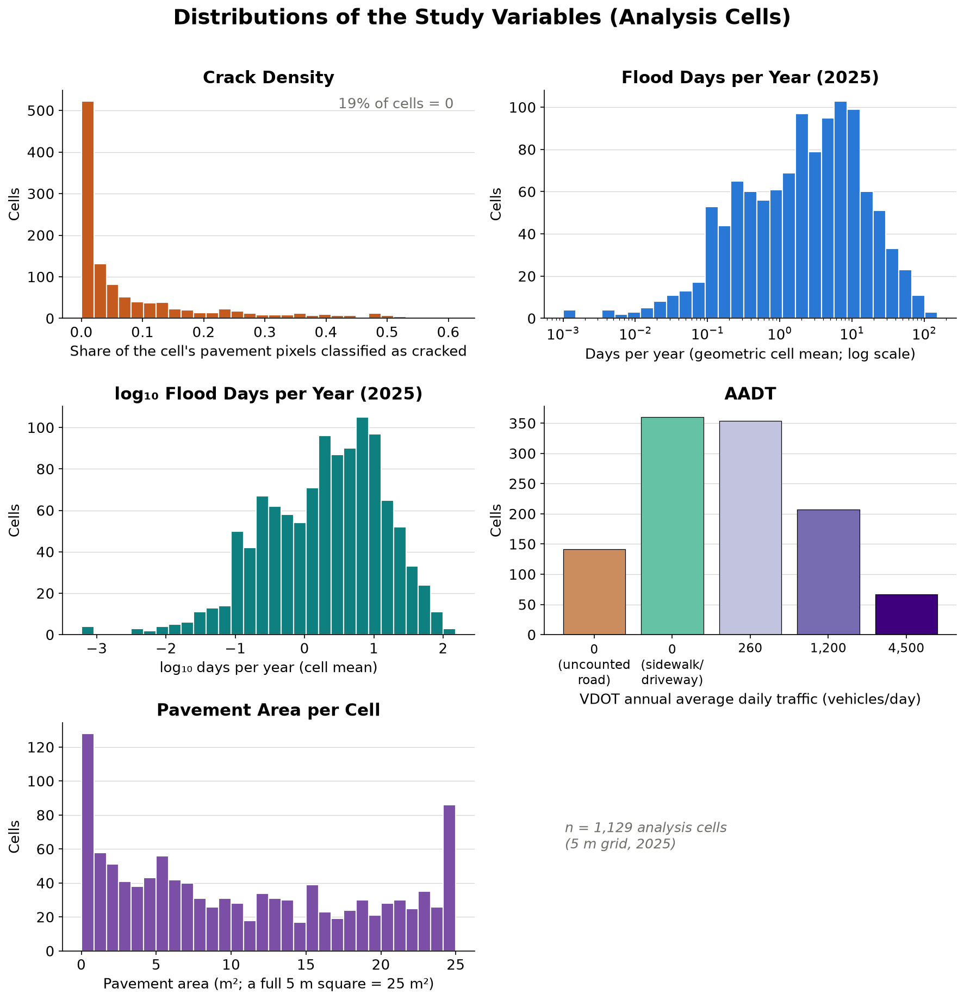

In [63]:
# ---------------------------------------------------------------------
# 04.3 (Step B) — FigS07 (supplementary visual check): distributions of the per-cell study variables
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
# _panel(): title, axis labels, and grid of one histogram panel
def _panel(ax, title, xlabel, ylabel="Cells"):
    """Title, axis labels, and the light grid of one histogram panel."""
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    style_ax(ax, "y")


fig_banner("FigS07", is_map=False)
print("Figure: distributions of the study variables (analysis cells; supplementary visual check)")
# 3 x 2 grid of panels; axes[row, column] picks one
fig, axes = plt.subplots(3, 2, figsize=(12, 12.5), dpi=FIG_DPI)
ax = axes[0, 0]                                              # crack density
ax.hist(cells_m["CrackDens"], bins=30, color="#c55a1e", edgecolor="white")
# Note in the panel's top-right corner (transform=ax.transAxes: axes fractions)
ax.text(0.95, 0.92, f"{(cells_m['CrackDens'] == 0).mean() * 100:.0f}% of cells = 0", transform=ax.transAxes, ha="right",
        color=REF_COLOR, fontsize=fs(10))
_panel(ax, "Crack Density", "Share of the cell's pavement pixels classified as cracked")
ax = axes[0, 1]                                              # flood days (log-spaced bins on a log axis)
# np.logspace = bin edges evenly spaced on a log scale
_fdg = cells_m["FloodDaysGeo"].clip(lower=1e-3)
ax.hist(_fdg, bins=np.logspace(np.log10(_fdg.min()), np.log10(max(_fdg.max(), 1)), 30), color="#2a78d6", edgecolor="white")
ax.set_xscale("log")
_panel(ax, f"Flood Days per Year ({FLOOD_YEAR})", "Days per year (geometric cell mean; log scale)")
ax = axes[1, 0]                                              # log10 flood days (the model's predictor)
ax.hist(cells_m["LogFloodDays"], bins=30, color="#0f8080", edgecolor="white")
_panel(ax, f"log₁₀ Flood Days per Year ({FLOOD_YEAR})", "log₁₀ days per year (cell mean)")
ax = axes[1, 1]                                              # AADT: cells per traffic value (0 = no road traffic)
# Cells per class in display order; x labels are the AADT values (0 for sidewalks/driveways and uncounted roads)
_tc = cells_m["TrafficClass"].value_counts().reindex(TRAFFIC_ORDER).fillna(0)
_lab = [("0\n(sidewalk/\ndriveway)" if c == "Sidewalk/driveway" else "0\n(uncounted\nroad)" if c == "Uncounted road"
         else c.replace("AADT ", "")) for c in _tc.index]
ax.bar(range(len(_tc)), _tc.values, color=[CLASS_COLORS[c] for c in _tc.index], edgecolor="black", linewidth=0.6)
ax.set_xticks(range(len(_tc))); ax.set_xticklabels(_lab, fontsize=fs(9))
_panel(ax, "AADT", "VDOT annual average daily traffic (vehicles/day)")
ax = axes[2, 0]                                              # pavement area per cell
ax.hist(cells_m["CellArea_m2"], bins=30, color="#7b4fa6", edgecolor="white")
_panel(ax, "Pavement Area per Cell", f"Pavement area (m²; a full {FISHNET_CELL_M} m square = {FISHNET_CELL_M ** 2} m²)")
# Last panel: no chart, just the number of cells
axes[2, 1].axis("off")
axes[2, 1].text(0.05, 0.5, f"n = {len(cells_m):,} analysis cells\n({FISHNET_CELL_M} m grid, {FLOOD_YEAR})",
                transform=axes[2, 1].transAxes, fontsize=12, color=REF_COLOR, style="italic", va="center")
fig.suptitle("Distributions of the Study Variables (Analysis Cells)", fontweight="bold", fontsize=fs(15))
# rect leaves the top 3 % of the figure free for the overall title
plt.tight_layout(rect=(0, 0, 1, 0.97))
save_fig(fig, "FigS07_StudyVariable_Distributions", "supp")
plt.show()
chart_fonts(False)                     # back to the default fonts

In [64]:
# ---------------------------------------------------------------------
# 04.3 (Step C) — Spearman rank correlation of each predictor with crack density
# ---------------------------------------------------------------------
# Spearman rank correlation with crack density (rank-based: suits skewed variables). These p-values treat cells as
# independent, which they are not (05.2), so they are optimistic.
_sp = []
for col, label in (("LogFloodDays", f"log10 flood days ({FLOOD_YEAR})"), ("ElevMHHW", "Elevation above MHHW"),
                   ("AADT", "AADT (sidewalk and uncounted = 0)")):
    # Spearman rank correlation (nan_policy="omit" skips missing values)
    r = stats.spearmanr(cells_m[col], cells_m["CrackDens"], nan_policy="omit")
    # dict(Variable=..., **{...}) builds one row: ** adds the keys of the inner dictionary
    _sp.append(dict(Variable=label, **{"Spearman rho with crack density": r.correlation,
                                       "p (cells independent)": r.pvalue}))
_sp_tbl = pd.DataFrame(_sp).set_index("Variable")
display(_sp_tbl.round(2).assign(**{"p (cells independent)": _sp_tbl["p (cells independent)"].map(p_text)}))

,Spearman rho with crack density,p (cells independent)
Variable,,
log10 flood days (2025),0.30,< 0.001
Elevation above MHHW,-0.30,< 0.001
AADT (sidewalk and uncounted = 0),0.59,< 0.001


**What the tables and figure show.** In the author's run, crack density was low for most cells (median 0.026, mean 0.084), 18.7% of the cells had no crack pixels, and the maximum was 0.61, showing that crack density is a bounded, zero-inflated, right-skewed fraction, which calls for the fractional logit of Section 05. 

*F* is extremely right-skewed (skewness 4.0), while log₁₀(*F*) is roughly symmetric (skewness −0.6), so log₁₀(*F*) is the predictor (FigS07). 

Traffic takes only five values in the cells (two zero-AADT classes and AADT 260, 1,200, and 4,500), so it enters the models as a class rather than a number. 

The pavement area per cell ranges from slivers to full 25 m² squares, which is why the cells are weighted by it. 

The rank correlations (Spearman ρ = 0.30 with log₁₀(*F*) and 0.59 with AADT) give an initial sense of the relationships: crack density rises with flood frequency (and falls with elevation) and with traffic. Traffic and flooding overlap in space, so the models of Section 05 separate them.

### 04.4 Methods Figures: Crack Detection & Traffic Classes

The two Methods maps in this section show how the cracks were detected and how the cells were classed by traffic. The cells' flood frequency is mapped with the Results figures (06.3).

- **Fig03 (Steps A–B):** (a) The classified cracks over the whole study area and (b) the DL crack classification workflow, stage by stage, at the Botetourt St & Mowbray Arch intersection (raw imagery → pavement mask → labeled training lines → model output with and without the lines). The training lines are drawn only if `Training_masked_imagery_PaveCracksDetect_Edited.shp` is in `DATA/01_Raw_Data_Custom`. The layers are, from bottom to top: the imagery, the **masked/excluded imagery** (everything outside the shrunk pavement mask; semi-transparent dark gray), the classified cracks (semi-transparent red), and the training lines (white). On the full-site map, cracks are drawn as the 0.5 m cells with at least one crack pixel; in the workflow panels, as the 0.10 m cells with at least one 2 cm crack pixel (`WORKFLOW_CRACK_RES_M`), so that thin cracks stay visible.
- **Fig04 (Step C):** The analysis cells by traffic/surface class.

In [65]:
# ---------------------------------------------------------------------
# 04.4 (Step A) — Helper: read a full-resolution window of a raster on the imagery grid
# ---------------------------------------------------------------------
# read_ref_window(): reads a window of a 2 cm custom raster, aggregated to coarser display cells
def read_ref_window(meta, path, ext, factor=1, mode="max", value=1):
    """Read the window `ext` (dict left/right/bottom/top) of a raster that is ON the imagery grid, reduced by
    factor x factor blocks ('max' = 1 if any pixel equals `value`; 'mean' = share of pixels equal to `value`).
    Returns (array, imshow extent)."""
    # First column/row of the window on the imagery grid, and its width/height in pixels
    c0, r0 = int(math.floor((ext["left"] - REF_X0) / REF_RES)), int(math.floor((REF_Y0 - ext["top"]) / REF_RES))
    w = int(math.ceil((ext["right"] - REF_X0) / REF_RES)) - c0
    h = int(math.ceil((REF_Y0 - ext["bottom"]) / REF_RES)) - r0
    # Round the size up to whole display cells
    w, h = int(math.ceil(w / factor) * factor), int(math.ceil(h / factor) * factor)
    # Offset of this raster from the imagery grid (whole pixels)
    ox, oy = (int(round(v)) for v in grid_offset(meta))
    with rasterio.open(path) as s:
        # boundless=True: pixels beyond the raster's edge are read as fill_value (0)
        a = s.read(1, window=Window(c0 - ox, r0 - oy, w, h), boundless=True, fill_value=0) == value
    # Group the pixels into factor x factor blocks; any() or mean() over each block
    blocks = a.reshape(h // factor, factor, w // factor, factor)
    out = blocks.any(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))
    x0, y0 = REF_X0 + c0 * REF_RES, REF_Y0 - r0 * REF_RES
    return out, (x0, x0 + w * REF_RES, y0 - h * REF_RES, y0)
print("[04.4 A] window reader ready")

[04.4 A] window reader ready


*** THIS IS A BASIC MAP FOR DEMONSTRATIVE PURPOSES. THE FINAL FIGURE 3 MAP IN THE PROJECT REPORT WILL LOOK DIFFERENT THAN BELOW.
Map: (a) classified pavement cracks of the whole study area and (b) the deep-learning (DL) crack classification workflow at the Botetourt St & Mowbray Arch intersection


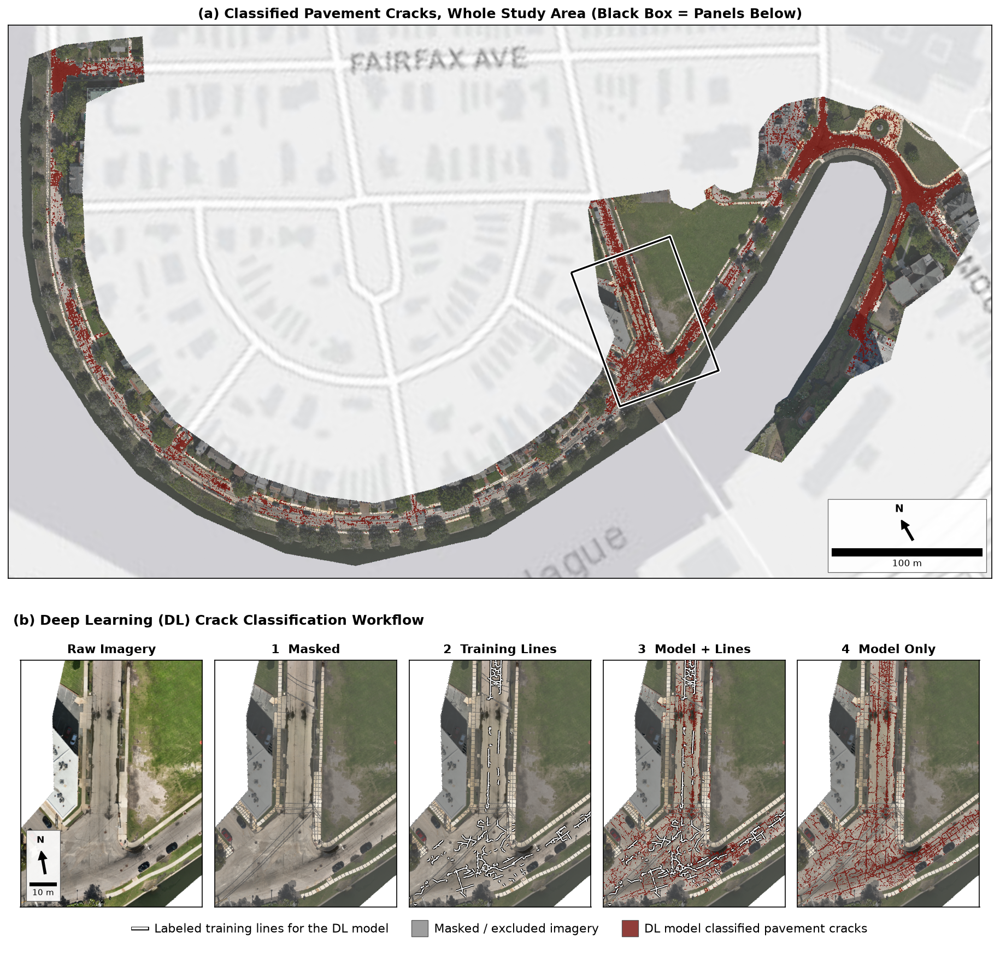

In [66]:
# ---------------------------------------------------------------------
# 04.4 (Step B) — Fig03: classified cracks of the whole site and the DL crack classification workflow (Botetourt St & Mowbray Arch)
# ---------------------------------------------------------------------
fig_banner("Fig03")
print("Map: (a) classified pavement cracks of the whole study area and (b) the deep-learning (DL) crack classification "
      "workflow at the Botetourt St & Mowbray Arch intersection")
_excl_z = mcolors.ListedColormap([mcolors.to_rgba(MASK_COLOR, EXCLUDED_ALPHA_ZOOM)])   # semi-transparent layers
_crack_z = mcolors.ListedColormap([mcolors.to_rgba(CRACK_COLOR, CRACK_ALPHA_ZOOM)])
# ---- Layout (inches): (a) across the top, (b) five panels below, the legend at the bottom
W = 12.0
# Heights: (a) from the page width; one workflow panel from its width and the window's shape; then the figure height
a_h = W / site_aspect(8)
pw = (W - 0.15 * 6) / 5                                         # width of one workflow panel
ph = pw * WORKFLOW_ZOOM["height_m"] / WORKFLOW_ZOOM["width_m"]
leg_h, t_stage, t_b, t_a, gap = 0.55, 0.35, 0.45, 0.45, 0.2
H = leg_h + ph + t_stage + t_b + gap + a_h + t_a
fig = plt.figure(figsize=(W, H), dpi=FIG_DPI)

# (a) whole site: imagery, masked/excluded imagery, classified cracks (0.5 m cells that contain cracks), the zoom box
# (a) across the top of the figure (add_axes uses fractions of the figure)
ax = fig.add_axes([0, (leg_h + ph + t_stage + t_b + gap) / H, 1, a_h / H])
map_background(ax)
map_imshow(ax, np.where(EXCLUDED_G, 1, np.nan), G_EXTENT, cmap=_excl_z, zorder=2)
map_imshow(ax, np.where(crack_cnt > 0, 1, np.nan), G_EXTENT, cmap=_crack_z, zorder=3)
draw_window_box(ax, WORKFLOW_ZOOM, ZOOM_ROTATION_DEG)
set_map_view(ax, FOOTPRINT, pad_m=8)
finish_map(ax, "(a) Classified Pavement Cracks, Whole Study Area (Black Box = Panels Below)", title_size=12)

# (b) the workflow, stage by stage, inside the black box (drawn in the zoom's own 10 deg frame)
# Cracks are drawn on a display grid of WORKFLOW_CRACK_RES_M cells
_f = max(1, int(round(WORKFLOW_CRACK_RES_M / REF_RES)))           # 2 cm pixels per side of a display cell (5)
stages = ["Raw Imagery", "1  Masked", "2  Training Lines", "3  Model + Lines", "4  Model Only"]
with map_rotation(ZOOM_ROTATION_DEG):
    # Read the window from the 2 cm mask and crack rasters
    wb = window_bounds(WORKFLOW_ZOOM)
    zmask, zext = read_ref_window(mm, mask_path, wb, _f, "mean", ROAD_MASK_VALUE)     # share of pavement pixels
    zcrack, _ = read_ref_window(cm, crack_path, wb, _f, "max", CRACK_VALUE)          # any crack pixel in the cell
    # imagery present at each display cell (from the 0.32 m preview), so the masked layer covers only real imagery
    # Row and column of the 0.32 m preview under each display cell's center
    _r = np.clip(((REF_Y0 - (zext[3] - (np.arange(zmask.shape[0]) + 0.5) * _f * REF_RES)) // P_RES).astype(int), 0, P_H - 1)
    _c = np.clip(((zext[0] + (np.arange(zmask.shape[1]) + 0.5) * _f * REF_RES - REF_X0) // P_RES).astype(int), 0, P_W - 1)
    # [_r[:, None], _c[None, :]] picks a 2-D block of the preview: rows x columns
    zimg = img_valid[_r[:, None], _c[None, :]]
    # Training lines inside the window (clipped to its box and rotated), if provided
    _train_w = None
    if train_c is not None and len(train_c):
        _train_w = rot_geoms(gpd.clip(train_c, box(wb["left"], wb["bottom"], wb["right"], wb["top"])))
    for i, title in enumerate(stages):              # enumerate() gives (0, first item), (1, second item), ...
        # Panel i of the row of five
        a = fig.add_axes([(0.15 + i * (pw + 0.15)) / W, leg_h / H, pw / W, ph / H])
        map_background(a, win=WORKFLOW_ZOOM, res=WORKFLOW_IMAGERY_RES_M)
        if i >= 1:                                   # stages 1-4: imagery outside the pavement mask, semi-transparent
            map_imshow(a, np.where((zmask < 0.5) & zimg, 1, np.nan), zext, cmap=_excl_z, zorder=2)
        if i >= 3:                                   # stages 3-4: the crack model's output, semi-transparent
            map_imshow(a, np.where(zcrack, 1, np.nan), zext, cmap=_crack_z, zorder=3)
        if i in (2, 3) and _train_w is not None and len(_train_w):
            _train_w.plot(ax=a, zorder=4, **outlined(TRAINING_LINE_COLOR, 0.9, extra=1.2))     # 0.9 pt line
        set_map_view(a, win=WORKFLOW_ZOOM)
        a.set_title(title, fontweight="bold", fontsize=10.5)
        if i == 0:
            add_north_arrow_and_scale(a, loc="lower left", fontsize=7)
# Label of the row of panels, and a three-column legend along the bottom of the figure
fig.text(0.005, (leg_h + ph + t_stage + 0.08) / H, "(b) Deep Learning (DL) Crack Classification Workflow",
         fontweight="bold", fontsize=12)
legend_items = [(dict(**outlined(TRAINING_LINE_COLOR, 1.8, extra=1.4)), "Labeled training lines for the DL model", "line"),
                (mcolors.to_rgba(MASK_COLOR, EXCLUDED_ALPHA_ZOOM), "Masked / excluded imagery"),
                (mcolors.to_rgba(CRACK_COLOR, CRACK_ALPHA_ZOOM), "DL model classified pavement cracks")]
square_legend(fig.add_axes([0.05, 0.0, 0.9, leg_h / H], frame_on=False, xticks=[], yticks=[]), legend_items, ncol=3,
              fontsize=10.5)
if _train_w is None:
    print("[info] training lines not provided: stages 2-3 show no lines (add the shapefile to DATA/01_Raw_Data_Custom)")
save_fig(fig, "Fig03_CrackDetection_Workflow", "methods")
plt.show()

**What the figure shows.** (a) Cracks are densest at the east end, around the Memorial Pl loop and the streets leading into it, with further dense patches at the Botetourt St & Mowbray Arch intersection south of the field (the black box) and at the Mowbray Arch/Fairfax Ave corner in the northwest; most of the long arc of Mowbray Arch has only scattered cracks. The mask keeps the model on the road and sidewalk surface: lawns, roofs, parked cars, and tree shadows are masked/excluded. 

(b) The stages of the DL workflow at the intersection: the pavement mask, the hand-corrected training lines, and the trained model's output, which shows the cracks as connected networks of thin lines. Because the mask and the cracks are semi-transparent, the classified cracks can be compared with the cracks in the imagery underneath.

*** THIS IS A BASIC MAP FOR DEMONSTRATIVE PURPOSES. THE FINAL FIGURE 4 MAP IN THE PROJECT REPORT WILL LOOK DIFFERENT THAN BELOW.
Map: 5 m x 5 m analysis cells by traffic / surface class


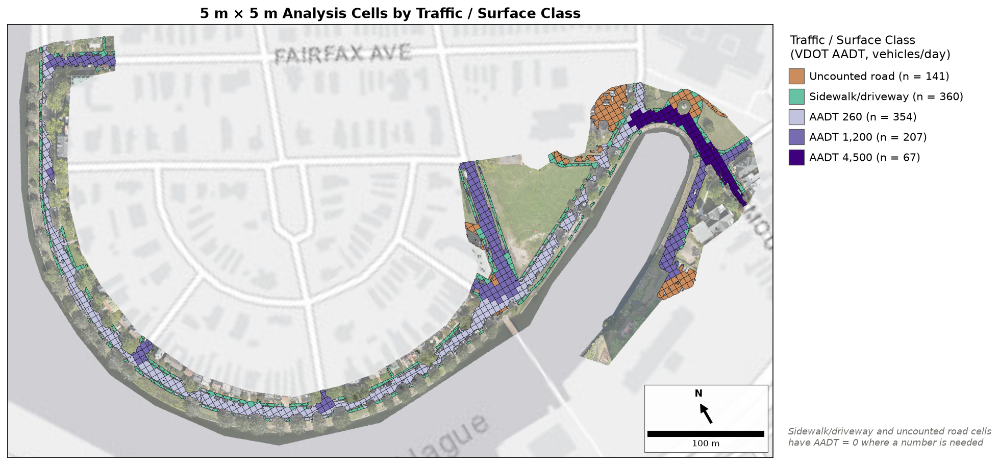

In [67]:
# ---------------------------------------------------------------------
# 04.4 (Step C) — Fig04: analysis cells by traffic / surface class
# ---------------------------------------------------------------------
fig_banner("Fig04")
print(f"Map: {FISHNET_CELL_M} m x {FISHNET_CELL_M} m analysis cells by traffic / surface class")
# Basemap and imagery (55 % opaque) under the cells
fig, ax = site_map_figure(right_in=3.3)
map_background(ax, imagery_alpha=0.55)
# Cells one class (color) at a time
for cls in TRAFFIC_ORDER:
    _g = cells_gdf[cells_gdf["TrafficClass"] == cls]
    if len(_g):
        rot_geoms(_g).plot(ax=ax, facecolor=CLASS_COLORS[cls], edgecolor="black", linewidth=0.25, zorder=4)
set_map_view(ax, FOOTPRINT, pad_m=10)
finish_map(ax, f"{FISHNET_CELL_M} m × {FISHNET_CELL_M} m Analysis Cells by Traffic / Surface Class", title_size=13)
# Legend with the number of cells per class (.get(c, 0): 0 if absent)
_n = cells["TrafficClass"].value_counts()
square_legend(ax, [(CLASS_COLORS[c], f"{c} (n = {_n.get(c, 0):,})") for c in TRAFFIC_ORDER],
              title="Traffic / Surface Class\n(VDOT AADT, vehicles/day)", loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.text(1.02, 0.02, "Sidewalk/driveway and uncounted road cells\nhave AADT = 0 where a number is needed",
        transform=ax.transAxes, fontsize=8.5, style="italic", color=REF_COLOR, va="bottom")
save_fig(fig, "Fig04_AnalysisCells_TrafficClass", "methods")
plt.show()

**What the map shows.**

- **AADT 260.** Mowbray Arch, the long arc.
- **AADT 1,200.** Botetourt St, Fairfax Ave, and the other side streets.
- **AADT 4,500.** Memorial Pl and Yarmouth St around the east-end loop.
- **Uncounted road.** Mostly parking-lot lanes and drives at the east end.
- **Sidewalk/driveway.** Thin strips along both sides of the streets.

The busiest class is concentrated in one small, low-lying area, so traffic and flood exposure may be confounded; the flood effect must therefore be tested with traffic controlled.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 05) Crack Density vs. Flood Frequency (2025)

This section answers the first research question in four subsections:

1. **05.1 Group Comparisons (FigS08):** mean crack density by traffic class and by flood-frequency class, with rank tests and simple logistic curves through the class means. This model-free first look shows that both traffic and flood frequency go with more cracking, and why a model must separate them.
2. **05.2 Spatial Autocorrelation:** how strongly neighboring cells resemble each other, and what that means for the statistics.
3. **05.3 Regression Models:** the primary model (fractional logit, eq. (2)) compared with simpler and more flexible models, with spatially robust p-values and spatial CV R², RMSE, and MAE (FigS09, TblS01, and TblS02).
4. **05.4 Fitted Relationship (Fig05):** crack density vs. flood frequency with the fitted model.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 05.1 Group Comparisons (FigS08, Supplementary)

The cells are grouped by traffic/surface class and by flood-frequency class, and the groups' mean crack densities are compared before any regression model is fitted.

- **(a) Traffic/surface class.** Mean crack density (± 1 SE) per class. A two-parameter logistic curve, `y = 1 / (1 + exp[−(b₀ + b₁·x)])` with *x* = AADT in thousand vehicles/day, is fitted to the means of the classes with a known traffic volume (*x* = 4.5 for AADT 4,500, so b₁ is the change in log-odds per 1,000 vehicles/day; Sidewalk/driveway = 0). "Uncounted road" has no known volume and is not used in the fit.
- **(b) Flood-frequency class.** Mean crack density per class of geometric-mean *F* (the map classes up to 90 days/yr; the last class runs to the maximum). A logistic curve with a ceiling, `y = L / (1 + exp[−(b₀ + b₁·x)])` with *x* = log₁₀(*F*) at each class's center, is fitted to the class means. On the log scale, this is the "dose–response" curve of toxicology and pharmacology (Ritz et al., 2015), `y = L / (1 + (F₅₀ / F)^(0.434·b₁))`, where *F*₅₀ is the flood frequency at which cracking reaches half its ceiling.
- **Tests.** Kruskal–Wallis rank tests (Kruskal & Wallis, 1952) ask whether the classes differ. They treat cells as independent, so their p-values are optimistic (05.2). The R² of the curves is computed on the class *means*, weighted by the cells per class: it describes how well each curve follows the averages, not how well it predicts single cells (05.3).
- **Colors.** The traffic bars use the class colors of Fig04, and the flood-frequency bars the classes of Fig07, so the same color means the same thing in every figure.

Step A defines the plotting helpers, Step B draws FigS08, and Step C prints the test results and the fitted curves.

In [68]:
# ---------------------------------------------------------------------
# 05.1 (Step A) — Helpers: weighted R2 of class means, bars with standard errors, and fitted curves over bars
# ---------------------------------------------------------------------
# wr2(): weighted R-squared of a curve fitted to class means
def wr2(y, yhat, w):
    """Weighted R2 of fitted vs observed class means (weights = cells per class)."""
    # R2 = 1 - (weighted squared error of the fit) / (weighted squared spread of the means)
    ybar = np.sum(w * y) / np.sum(w)
    return float(1 - np.sum(w * (y - yhat) ** 2) / np.sum(w * (y - ybar) ** 2))


# bar_with_se(): bar chart of group means with standard-error whiskers and labels
def bar_with_se(ax, labels, means, sems, counts, colors, width=0.8):
    """Bars of group means with +/- 1 SE whiskers and 'mean (n = ...)' labels above them."""
    # yerr = whisker length (1 SE); capsize = width of the whisker caps
    bars = ax.bar(range(len(means)), means, yerr=sems, capsize=4, color=colors, edgecolor="black", linewidth=0.6,
                  width=width, error_kw=dict(linewidth=1.0))
    ax.set_xticks(range(len(means)))
    ax.set_xticklabels(labels)
    # Label above each whisker: the mean and n
    for b, m, se, k in zip(bars, means, sems, counts):
        ax.text(b.get_x() + b.get_width() / 2, m + (se if np.isfinite(se) else 0) + 0.004, f"{m:.3f}\n(n={k})",
                ha="center", va="bottom", fontsize=fs(8.5))
    # Extra room above the tallest bar for its label
    ax.margins(y=0.18)
    style_ax(ax, "y")


# draw_curve(): draws a fitted curve over bars (x values mapped to bar positions)
def draw_curve(ax, pos_known, x_known, f, label):
    """Fitted curve over bars at positions 0, 1, 2 ...: x is mapped to a bar position by straight-line
    interpolation between the bars that have an x value (np.interp)."""
    # 300 x values along the fitted range; np.interp places each one between the bar positions
    xg = np.linspace(min(x_known), max(x_known), 300)
    (line,) = ax.plot(np.interp(xg, x_known, pos_known), f(xg), label=label or "_nolegend_", zorder=5, **MODEL_LINE_STYLE)
    # Mostly transparent gray halo (wide stroke, alpha 0.15) under the orange curve
    line.set_path_effects([pe.Stroke(linewidth=7, foreground="#2b2b2b", alpha=0.15), pe.Normal()])
print("[05.1 A] helpers ready")

[05.1 A] helpers ready


*** THIS IS SUPPLEMENTARY FIGURE S08. IT IS NOT IN THE MAIN PROJECT REPORT.
Figure: mean crack density by (a) traffic / surface class and (b) flood-day class, with logistic fits


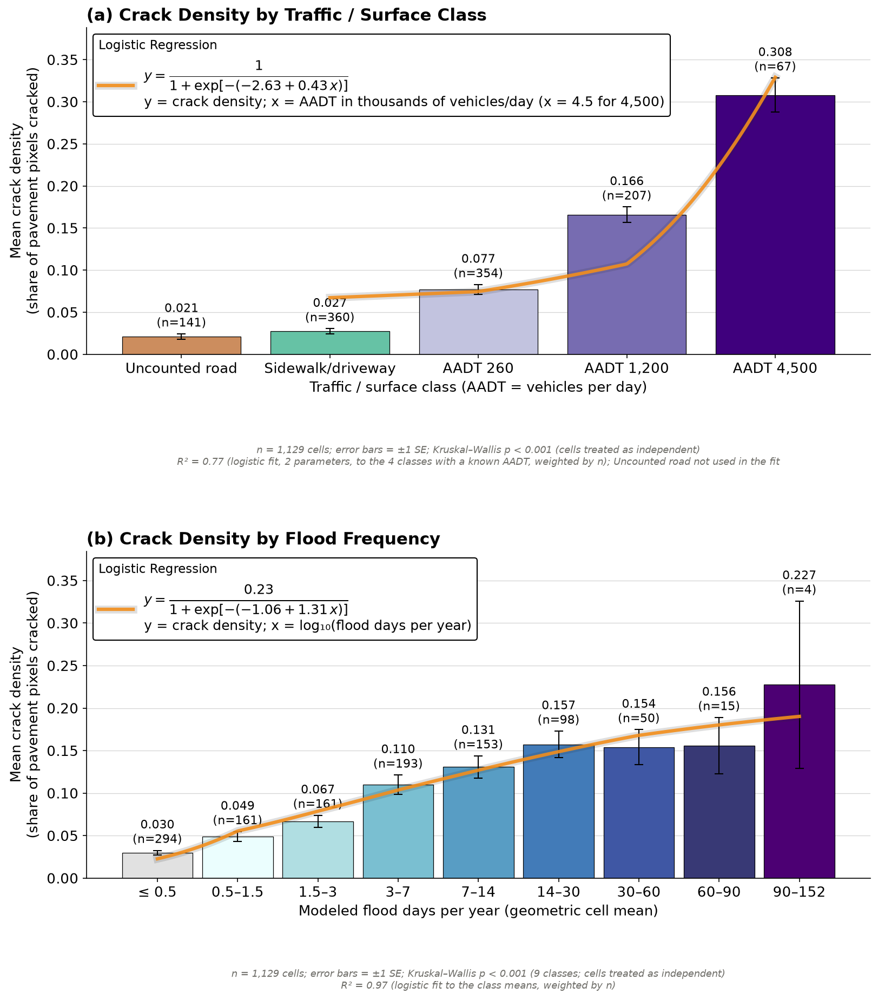

In [69]:
# ---------------------------------------------------------------------
# 05.1 (Step B) — FigS08 (supplementary): crack density by (a) traffic class and by (b) flood-day class, with logistic fits
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
fig_banner("FigS08", is_map=False)
print("Figure: mean crack density by (a) traffic / surface class and (b) flood-day class, with logistic fits")


# poster_legend(): conference-poster legend with the fitted equation as a fraction
def poster_legend(ax, label_eq, label_xy):
    """Legend in the style of the conference poster: title 'Logistic Regression', the orange curve, and the fitted
    equation written as a fraction (matplotlib "mathtext": text between $ signs is typeset like LaTeX)."""
    # Legend symbol: the orange curve with the same gray halo
    h = mlines.Line2D([], [], **MODEL_LINE_STYLE)
    h.set_path_effects([pe.Stroke(linewidth=7, foreground="#2b2b2b", alpha=0.15), pe.Normal()])
    leg = ax.legend([h], [label_eq + "\n" + label_xy], title="Logistic Regression", loc="upper left", fontsize=fs(9.5),
                    title_fontsize=fs(9), alignment="left", framealpha=1, edgecolor="black", handlelength=2.6)
    return leg


# caption(): gray note centered under a chart panel
def caption(ax, text, offset_pt=-80):
    """Gray note centered under a panel (offset in points below the bottom of the axes)."""
    # Anchor at the bottom center of the axes, moved offset_pt points down
    ax.annotate(text, xy=(0.5, 0), xycoords="axes fraction", xytext=(0, offset_pt), textcoords="offset points",
                ha="center", va="top", fontsize=8.5, style="italic", color=REF_COLOR)


# Two charts stacked: (a) on top, (b) below
fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(11, 12.5), dpi=FIG_DPI)
# ---- (a) traffic / surface class: bars in the class colors (thin black outlines) ----
# Classes present in the analysis cells, in display order
tc_order = [c for c in TRAFFIC_ORDER if c in set(cells_m["TrafficClass"])]
g = cells_m.groupby("TrafficClass")["CrackDens"]             # .groupby(col) splits the table by class
# Mean, standard error (sem), and count per class, in display order (reindex)
tc_mean, tc_se, tc_n = g.mean().reindex(tc_order), g.sem().reindex(tc_order), g.count().reindex(tc_order)
# Kruskal-Wallis test: do the classes differ? (*[...] passes one group per class)
kw_tc = stats.kruskal(*[cells_m.loc[cells_m["TrafficClass"] == c, "CrackDens"] for c in tc_order])
bar_with_se(ax_a, [c.replace(" (", "\n(") for c in tc_order], tc_mean.values, tc_se.values, tc_n.values,
            [CLASS_COLORS[c] for c in tc_order])
# Classes with a known AADT for the fit: (bar position, class, x = AADT in thousands; 0 for sidewalks/driveways)
known = [(i, c, 0.0 if c == "Sidewalk/driveway" else float(c[5:].replace(",", "")) / 1000)
         for i, c in enumerate(tc_order) if c == "Sidewalk/driveway" or c.startswith("AADT ")]
FIT_TC = None
if len(known) >= 3:
    # Bar positions, x values, class means, and class sizes of those classes
    pos_k, x_k = np.array([k[0] for k in known], float), np.array([k[2] for k in known])
    y_k, n_k = tc_mean[[k[1] for k in known]].values, tc_n[[k[1] for k in known]].values.astype(float)
    try:
        # Fit y = 1 / (1 + exp(-(b0 + b1 x))) (expit) to the class means; sigma = 1/sqrt(n) gives larger classes more
        # weight; p0 = starting guesses
        p_tc, _ = curve_fit(lambda x, b0, b1: expit(b0 + b1 * x), x_k, y_k, p0=(-2.0, 0.1), sigma=1 / np.sqrt(n_k),
                            maxfev=20000)
        FIT_TC = dict(b0=p_tc[0], b1=p_tc[1], r2=wr2(y_k, expit(p_tc[0] + p_tc[1] * x_k), n_k))
        draw_curve(ax_a, pos_k, x_k, lambda x: expit(p_tc[0] + p_tc[1] * x), None)
        # r"..." is a raw string: backslashes stay as typed, as mathtext needs
        poster_legend(ax_a, r"$y = \dfrac{1}{1 + \exp[-(" + f"{p_tc[0]:.2f} {p_tc[1]:+.2f}" + r"\,x)]}$",
                      "y = crack density; x = AADT in thousands of vehicles/day (x = 4.5 for 4,500)")
    except Exception as e:
        print(f"[warn] traffic-class logistic fit failed: {e}")
# Axis labels, title (loc="left": left-aligned), and the note under the panel
ax_a.set_xlabel("Traffic / surface class (AADT = vehicles per day)")
ax_a.set_ylabel("Mean crack density\n(share of pavement pixels cracked)")
ax_a.set_title("(a) Crack Density by Traffic / Surface Class", fontweight="bold", loc="left")
caption(ax_a, f"n = {len(cells_m):,} cells; error bars = ±1 SE; Kruskal–Wallis {fmt_p(kw_tc.pvalue)} (cells treated as "
        f"independent)\n" + (f"R² = {FIT_TC['r2']:.2f} (logistic fit, 2 parameters, to the {len(known)} classes with a "
                             f"known AADT, weighted by n); Uncounted road not used in the fit" if FIT_TC else ""))

# ---- (b) flood-day class: bars in the flood-day map colors ----
# Flood-day classes: the class bounds below the largest value, then the largest value
fd = cells_m.copy()
fd_max = float(fd["FloodDaysGeo"].max())
uppers = [e for e in FLOOD_BIN_UPPER_EDGES if e < fd_max] + [fd_max]
# pd.cut puts each cell in its class (labels=False: class number 0, 1, 2 ...)
fd["FloodBin"] = pd.cut(fd["FloodDaysGeo"], bins=[-np.inf] + uppers, labels=False, include_lowest=True)
# Per class: n, mean, SE, and the mean log10 flood days (the x of the fit); agg(name=(column, function)) names each
# result
summ = fd.groupby("FloodBin").agg(n=("CrackDens", "size"), mean=("CrackDens", "mean"), se=("CrackDens", "sem"),
                                  x_center=("LogFloodDays", "mean")).reset_index()
# Bar labels: "<= first bound", then "low-high" for each class
_edge = lambda v: f"{v:g}" if v < 10 else f"{v:.0f}"
_bin_labels = [f"≤ {_edge(uppers[0])}"] + [f"{_edge(uppers[i - 1])}–{_edge(uppers[i])}" for i in range(1, len(uppers))]
kw_fd = stats.kruskal(*[fd.loc[fd["FloodBin"] == b, "CrackDens"] for b in summ["FloodBin"]])
bar_with_se(ax_b, [_bin_labels[int(b)] for b in summ["FloodBin"]], summ["mean"].values, summ["se"].values,
            summ["n"].values, [FLOOD_CLASS_COLORS[min(int(b), len(FLOOD_CLASS_COLORS) - 1)] for b in summ["FloodBin"]],
            width=0.88)
FIT_FD = None
# x, y, and weights of the fit
xb, yb, nb = summ["x_center"].values, summ["mean"].values, summ["n"].values.astype(float)
try:
    # logistic3(): three-parameter logistic curve (ceiling L, steepness k, midpoint x0)
    def logistic3(x, L, k, x0):
        return L / (1 + np.exp(-k * (x - x0)))
    # bounds = ([lowest L, k, x0], [highest L, k, x0]) keep the fit realistic
    p_fd, _ = curve_fit(logistic3, xb, yb, p0=(min(1.0, 1.5 * yb.max()), 1.0, float(np.median(xb))), sigma=1 / np.sqrt(nb),
                        bounds=([1e-6, 0.01, -5], [1.0, 20.0, 5]), maxfev=20000)
    # Fitted values, also written as b0 = -k x0 and b1 = k; the ceiling L is "identified" only if the midpoint lies
    # inside the data and L < 1
    L, k, x0 = p_fd
    FIT_FD = dict(L=L, b0=-k * x0, b1=k, r2=wr2(yb, logistic3(xb, *p_fd), nb), F0=10 ** x0,
                  ceiling_identified=not (x0 >= xb.max() or L >= 0.999))
    draw_curve(ax_b, np.arange(len(summ)), xb, lambda x: logistic3(x, *p_fd), None)
    poster_legend(ax_b, r"$y = \dfrac{" + f"{L:.2f}" + r"}{1 + \exp[-(" + f"{-k * x0:.2f} {k:+.2f}" + r"\,x)]}$",
                  "y = crack density; x = log₁₀(flood days per year)")
except Exception as e:
    print(f"[warn] flood-class logistic fit failed: {e}")
# Axis labels, title, and the note under the panel
ax_b.set_xlabel("Modeled flood days per year (geometric cell mean)")
ax_b.set_ylabel("Mean crack density\n(share of pavement pixels cracked)")
ax_b.set_title("(b) Crack Density by Flood Frequency", fontweight="bold", loc="left")
caption(ax_b, f"n = {len(cells_m):,} cells; error bars = ±1 SE; Kruskal–Wallis {fmt_p(kw_fd.pvalue)} ({len(summ)} classes; "
        f"cells treated as independent)\n" + (f"R² = {FIT_FD['r2']:.2f} (logistic fit to the class means, weighted by n)"
                                               if FIT_FD else ""))
# h_pad = vertical space between the two panels (room for the notes)
plt.tight_layout(h_pad=4.5)
save_fig(fig, "FigS08_CrackDensity_by_Traffic_and_FloodClass", "supp")
plt.show()
chart_fonts(False)                     # back to the default fonts

In [70]:
# ---------------------------------------------------------------------
# 05.1 (Step C) — Rank tests and fitted curves of FigS08
# ---------------------------------------------------------------------
# Least flooded class (first row) and the class with the highest mean crack density (idxmax)
_lo, _hi = summ.iloc[0], summ.loc[summ["mean"].idxmax()]
# "A" + ("B" if condition else "") adds the fit's numbers only if the fit worked
print(f"Traffic classes: Kruskal-Wallis H = {kw_tc.statistic:.1f}, {fmt_p(kw_tc.pvalue)}; "
      + (f"logistic fit b0 = {FIT_TC['b0']:.3f}, b1 = {FIT_TC['b1']:.3f} per 1,000 vehicles/day, R2 = {FIT_TC['r2']:.3f}"
         if FIT_TC else "no fit"))
print(f"Flood classes:   Kruskal-Wallis H = {kw_fd.statistic:.1f}, {fmt_p(kw_fd.pvalue)}; most cracked class "
      f"{_bin_labels[int(_hi['FloodBin'])]} days/yr ({_hi['mean']:.3f}) vs {_bin_labels[int(_lo['FloodBin'])]} days/yr "
      f"({_lo['mean']:.3f}) = {_hi['mean'] / max(_lo['mean'], 1e-9):.1f} x"
      + (f"; logistic fit L = {FIT_FD['L']:.3f}, b0 = {FIT_FD['b0']:.3f}, b1 = {FIT_FD['b1']:.3f}, R2 = {FIT_FD['r2']:.3f}"
         + ("" if FIT_FD["ceiling_identified"] else " (the curve does not level off within the data: ceiling not identified)")
         if FIT_FD else ""))

Traffic classes: Kruskal-Wallis H = 409.5, p < 0.001; logistic fit b0 = -2.630, b1 = 0.426 per 1,000 vehicles/day, R2 = 0.775
Flood classes:   Kruskal-Wallis H = 106.6, p < 0.001; most cracked class 90–152 days/yr (0.227) vs ≤ 0.5 days/yr (0.030) = 7.6 x; logistic fit L = 0.226, b0 = -1.057, b1 = 1.312, R2 = 0.965


**What the supplementary figure (FigS08) shows.** (a) Crack density rises steeply with traffic: in the author's run, the busiest counted streets (AADT 4,500; 0.308) were about eleven times more cracked than sidewalks and driveways (0.027), and the logistic curve follows the means of the classes with a known volume closely (R² = 0.77 on the class means). Uncounted roads (mostly parking-lot lanes; 0.021) crack about as little as sidewalks. 

(b) Crack density also rises with flood frequency, from 0.030 for pavement that floods less than once every two years to about 0.15–0.16 for the classes from 14 to 90 days/yr (about five times more), following an S-shaped (logistic) curve on the log scale (R² = 0.97 on the class means). The last class (90–152 days/yr) holds only 4 cells, so its mean (0.227) is very uncertain. Because the busiest streets are also among the most flooded (Fig04 and Fig07), these panels cannot separate the two effects; the regression models of 05.3 do.

### 05.2 Spatial Autocorrelation

**Moran's I** (Moran, 1950) measures whether nearby cells have similar values. Each cell is compared with its `K_NEIGHBORS` = 8 nearest cells (row-standardized k-nearest-neighbor weights; PySAL; Rey & Anselin, 2007). I ≈ 0 means no spatial pattern, I > 0 means clustering (high next to high, low next to low), and the maximum is about 1. The p-value comes from 999 random permutations of the values over the cells. The **correlogram** repeats the calculation for cell pairs in successive 10 m distance bands, showing how far the similarity reaches.

Step A builds the spatial weights and the two Moran's I functions, and Step B applies them to the analysis variables.

In [71]:
# ---------------------------------------------------------------------
# 05.2 (Step A) — Cells used in the models, k-nearest-neighbor weights, and the Moran's I functions
# ---------------------------------------------------------------------
# Cells with every value the models need; XY = their centroids (x, y)
d_mod = cells_m.dropna(subset=["CrackDens", "LogFloodDays", "CentroidX", "CentroidY"]).reset_index(drop=True)
XY = d_mod[["CentroidX", "CentroidY"]].values
W_KNN = KNN.from_array(XY, k=K_NEIGHBORS)          # each cell's k nearest cells (centroid distance)
W_KNN.transform = "r"                               # row-standardize: each cell's neighbor weights sum to 1


# moran(): global Moran's I of a variable with its permutation p-value
def moran(values):
    """Global Moran's I with the k-nearest-neighbor weights; (I, permutation p-value)."""
    np.random.seed(RANDOM_SEED)                     # the permutations use numpy's random generator
    # Moran's I with MORAN_PERMUTATIONS random reshuffles of the values for the p-value (esda)
    mi = Moran(np.asarray(values, float), W_KNN, permutations=MORAN_PERMUTATIONS)
    return float(mi.I), float(mi.p_sim)


# moran_correlogram(): Moran's I in distance bands (how far the clustering reaches)
def moran_correlogram(values, coords, band_m=CORRELOGRAM_BAND_M, max_m=CORRELOGRAM_MAX_M):
    """Moran's I of `values` in successive distance bands (0-band, band-2*band, ...), with binary weights for the cell
    pairs in each band, and its z-score under normality (Cliff & Ord, 1981)."""
    coords = np.asarray(coords, float)
    # Deviations from the mean; n cells; denom = sum of squared deviations
    z = np.asarray(values, float) - np.mean(values)
    n, denom = len(z), float((z ** 2).sum())
    pairs = cKDTree(coords).query_pairs(max_m, output_type="ndarray")    # every pair of cells closer than max_m
    # The two cells of each pair and their distance (np.hypot = sqrt(dx2 + dy2); .T transposes so * unpacks dx and dy)
    i, j = pairs[:, 0], pairs[:, 1]
    dist = np.hypot(*(coords[i] - coords[j]).T)
    rows = []
    # One distance band at a time: pairs farther than lo and at most lo + band_m apart
    for lo in np.arange(0, max_m, band_m):
        sel = (dist > lo) & (dist <= lo + band_m)
        s0 = 2 * int(sel.sum())                     # number of ORDERED pairs in the band
        # Moran's I of the band: (n / S0) x sum over pairs of z_i z_j (each pair counted both ways) / sum of z2
        I = float((n / s0) * 2 * (z[i[sel]] * z[j[sel]]).sum() / denom) if s0 and denom > 0 else np.nan
        zI = np.nan
        if s0:
            # Expected value and variance of I under normality (Cliff & Ord, 1981) give its z-score; deg = number of
            # band neighbors of each cell
            deg = np.bincount(i[sel], minlength=n) + np.bincount(j[sel], minlength=n)
            S0, S1, S2 = float(s0), 2.0 * s0, 4.0 * float((deg.astype(float) ** 2).sum())
            EI = -1.0 / (n - 1)
            VI = (n * n * S1 - n * S2 + 3 * S0 * S0) / (S0 * S0 * (n * n - 1)) - EI * EI
            zI = float((I - EI) / np.sqrt(VI)) if VI > 0 else np.nan
        # One row per band
        rows.append(dict(band_lo_m=lo, band_hi_m=lo + band_m, n_pairs=s0, moran_I=I, z=zI))
    return pd.DataFrame(rows)
print(f"[05.2 A] {len(d_mod):,} cells; {K_NEIGHBORS}-nearest-neighbor weights ready")

[05.2 A] 1,129 cells; 8-nearest-neighbor weights ready


In [72]:
# ---------------------------------------------------------------------
# 05.2 (Step B) — Global Moran's I of the analysis variables and the crack-density correlogram
# ---------------------------------------------------------------------
# One row per variable: dict(zip(names, moran(...))) names the two values that moran() returns
moran_tbl = pd.DataFrame([dict(Variable=v, **dict(zip(["Moran's I", "p (999 permutations)"], moran(d_mod[c]))))
                          for v, c in (("Crack density", "CrackDens"), (f"log10 flood days ({FLOOD_YEAR})", "LogFloodDays"),
                                       ("AADT", "AADT"))]).set_index("Variable")
# Correlogram of crack density (Moran's I by distance band)
corr_crack = moran_correlogram(d_mod["CrackDens"], XY)
MORAN_CRACK = moran_tbl.loc["Crack density", "Moran's I"]
display(moran_tbl.round(3))
# Upper edge of the first band where I is 0 or below (how far the clustering reaches)
_first0 = corr_crack.loc[corr_crack["moran_I"] <= 0, "band_hi_m"]
print(f"Crack-density correlogram: I = {corr_crack['moran_I'].iloc[0]:.3f} for cells within {CORRELOGRAM_BAND_M} m; "
      + (f"first reaches 0 at {_first0.iloc[0]:.0f} m" if len(_first0) else f"still > 0 at {CORRELOGRAM_MAX_M} m"))

,Moran's I,p (999 permutations)
Variable,,
Crack density,0.545,0.001
log10 flood days (2025),0.909,0.001
AADT,0.627,0.001


Crack-density correlogram: I = 0.550 for cells within 10 m; first reaches 0 at 100 m


**What it means for the statistics.** Crack density, flood frequency, and traffic are all strongly clustered (Moran's I well above 0, p ≤ 0.001), because neighboring cells share a street, an elevation, and a traffic volume. In the author's run, Moran's I was 0.545 for crack density (moderate-to-strong clustering), 0.909 for log₁₀(*F*), and 0.627 for AADT, and the crack-density correlogram stayed above 0 up to about 100 m. This has three consequences:

1. **Fewer independent observations than cells.** Neighboring cells repeat much of the same information, so the *effective* sample size is far smaller than the number of cells. Tests that assume independent cells (the Kruskal–Wallis and Spearman p-values above, and ordinary regression p-values) give p-values that are too small and CIs that are too narrow. The coefficients themselves are not biased; only their uncertainty is understated.
2. **The remedy: spatially robust (Conley) SEs.** The models' p-values use Conley (1999) spatial heteroskedasticity- and autocorrelation-consistent (HAC) SEs, which allow the errors of cells closer than a cutoff distance to be correlated, with a weight that falls linearly with distance. The cutoff is where the correlogram of the *model residuals* first reaches zero, i.e., the range of the dependence that the model leaves unexplained. The models are evaluated by **spatial block CV** (Roberts et al., 2017): whole blocks of that size are held out together, so a cell is never predicted from its own neighbors.
3. **Residual clustering is a warning.** The residuals stay clustered (05.3) because unmeasured, spatially smooth factors, such as pavement age, repaving history, drainage, and tree roots, also shape cracking. The flood effect is therefore an **association** after controlling for traffic, not proof of cause.

### 05.3 Regression Models

The flood effect is tested with a regression model that controls for traffic, and that model is compared with simpler and more flexible alternatives.

**The primary model: a fractional logit** (Papke & Wooldridge, 1996). Crack density is a *share* (0–1) of a cell's pavement pixels, with many zeros. A fractional logit models the **expected share** with an S-shaped curve, eq. (2) (see **Symbols** for the variables):

`ŷ(F, γ_c) = 1 / [1 + e^(−(β₀ + β₁·log₁₀(F) + γ_c))]`

It is a logistic regression in which each cell is a bag of pavement pixels, and the outcome is the fraction of them that is cracked:

- predictions always stay between 0 and 1, and zeros are allowed (unlike a log or logit transform of the data);
- β₁ is the change in the **log-odds** that a pavement pixel is cracked per tenfold increase in *F*. The odds ratio per *doubling* of *F*, `exp(β₁·log₁₀2)`, reads as "each doubling multiplies the odds of cracking by …";
- **γ_c shifts the curve up or down for each traffic/surface class**, so the flood effect is the one *within* the same road type. The reference class (the most common class, Sidewalk/driveway) has γ = 0. In the author's run, γ was +1.24 (AADT 260), +1.74 (AADT 1,200), +2.55 (AADT 4,500), and −0.04 (Uncounted road), i.e., the odds that a pavement pixel is cracked are multiplied by e^γ = 3.4, 5.7, 12.8, and 0.96 relative to sidewalks at the same flood frequency (Hosmer et al., 2013). β₁ is the same in every class, so the class curves are parallel on the log-odds scale. On the crack-density scale, the same shift matters more where cracking is common, because the curve's slope there is `β₁·ŷ(1 − ŷ)`;
- it is fitted by quasi-likelihood (`statsmodels` generalized linear model [GLM], binomial family, logit link; McCullagh & Nelder, 1989), which assumes only that the mean follows the curve, not a particular distribution of the scatter around it (Papke & Wooldridge, 1996). Cells are weighted by pavement area because larger cells measure crack density more precisely.

**Why the scatter is wide although p < 0.001.** The p-value tests whether the *average* trend is real, not how tightly cells follow it. With many cells, a modest but consistent trend is detectable even when single cells vary a lot. R² measures the cell-to-cell agreement, and most of it comes from traffic, which is why the key numbers also give the R² gained by adding *F* to a traffic-only model.

**Models compared** (same cells, traffic/surface classes, and weights):

| ID | Model | Why |
|---|---|---|
| M1 | **Fractional logit, log₁₀ flood frequency + traffic/surface class (primary)** | Bounded between 0 and 1, handles the zeros, and is the model used for the projection |
| M2 | Fractional logit, traffic/surface class only | Baseline: how much does flood frequency add? |
| M3 | Linear regression (ordinary least squares [OLS], scikit-learn), log₁₀ flood frequency + traffic/surface class | The simplest model; can predict impossible values below 0 |
| M4 | Fractional logit + a quadratic term in log₁₀ flood frequency | Checks for curvature: a negative quadratic term gives bell-shaped log-odds, i.e., cracking that levels off or falls at high flood frequency |
| M5 | Random forest (Breiman, 2001; scikit-learn), log₁₀ flood frequency + traffic/surface class | Flexible machine-learning model with no assumed curve shape; it cannot extrapolate beyond the observed flood frequency, so it is not used for the projection |

**Evaluation metrics.**

- **R²** (share of the cell-to-cell variance in crack density reproduced), **RMSE** (typical prediction error, with large errors weighted more), and **MAE**, all in crack-density units (scikit-learn), computed both in-sample and from spatial block CV.
- **p-values of the flood coefficient**, computed two ways: treating cells as independent (robust to heteroskedasticity only) and with the Conley spatial HAC correction.
- **Moran's I of the residuals** (CV predictions): how much spatial clustering each model leaves unexplained.

**Why these choices.** log₁₀(*F*) is the predictor because *F* spans six orders of magnitude and is exponential in elevation (01.3), so a doubling of flood frequency should matter about equally anywhere on the scale. The p-values use spatial HAC SEs with Bartlett (linearly declining) weights, the same kernel as the Newey and West (1987) time-series estimator, because the cells are spatially autocorrelated (05.2). Spatial block CV is the recommended way to measure predictive skill on spatially structured data (Roberts et al., 2017).

**Steps.** A defines the design matrix, fitting, and prediction; B the robust SEs; C fits every model; D tabulates the primary model's coefficients (and saves its image, TblS01); E runs the spatial CV; F builds the evaluation table (and saves the image of the models compared over that table, TblS02); G computes the primary model's key numbers; H prints a plain-language reading of them; and I draws the model-evaluation figure (supplementary FigS09): the correlograms that set the spatial HAC cutoff and the block size, and the calibration of each model's predictions for held-out blocks.

In [73]:
# ---------------------------------------------------------------------
# 05.3 (Step A) — Model helpers: weights, model list, design matrix, fitting, and prediction
# ---------------------------------------------------------------------
# Response (crack fraction, kept within 0-1) and the cell weights (pavement area / mean area, or all 1)
y_all = d_mod["CrackDens"].clip(0, 1).values
w_all = (d_mod["CellArea_m2"] / d_mod["CellArea_m2"].mean()).values if WEIGHT_BY_CELL_AREA else np.ones(len(d_mod))
REF_CLASS = d_mod["TrafficClass"].value_counts().idxmax()          # reference class = the most common class
# One 0/1 column per traffic class except the reference class
CLASS_DUMMIES = [c for c in sorted(d_mod["TrafficClass"].unique()) if c != REF_CLASS]
X_MEAN = float(d_mod["LogFloodDays"].mean())                        # center of the quadratic term
# The models compared in 05.3: kind = how it is fitted; flood = how flood days enter it (none, straight, or curved)
MODELS = {
    "M1": dict(label="M1 Fractional logit (primary)", kind="logit", flood="linear"),
    "M2": dict(label="M2 Fractional logit: traffic class only", kind="logit", flood=None),
    "M3": dict(label="M3 Linear regression (OLS)", kind="ols", flood="linear"),
    "M4": dict(label="M4 Fractional logit + quadratic term", kind="logit", flood="quadratic"),
    "M5": dict(label="M5 Random forest", kind="rf", flood="linear"),
}


# design(): table of predictors (design matrix) of a model
def design(d, flood="linear"):
    """Design matrix: constant, log10 flood days (and its centered square), one 0/1 column per non-reference class."""
    # Constant column (the intercept), then the flood-days column(s)
    X = pd.DataFrame({"const": 1.0}, index=d.index)
    if flood in ("linear", "quadratic"):
        X["LogFloodDays"] = d["LogFloodDays"].values
    if flood == "quadratic":
        X["LogFloodDays_sq"] = (d["LogFloodDays"].values - X_MEAN) ** 2
    # 0/1 column of each non-reference traffic class
    for c in CLASS_DUMMIES:
        X[f"TC[{c}]"] = (d["TrafficClass"] == c).astype(float).values
    return X


# fit_model(): fits one model of the comparison (GLM, OLS, or random forest)
def fit_model(spec, d, y, w):
    """Fit one model to the cells d (crack fractions y, weights w). Columns that do not vary are dropped."""
    # Keep the constant and the columns that vary (nunique() > 1)
    X = design(d, spec["flood"])
    cols = [c for c in X.columns if c == "const" or X[c].nunique() > 1]
    if spec["kind"] == "logit":                       # fractional logit: binomial GLM, logit link, quasi-likelihood
        res = sm.GLM(y, X[cols], family=sm.families.Binomial(), var_weights=w).fit()
        return dict(spec=spec, cols=cols, params=np.asarray(res.params), res=res)
    if spec["kind"] == "ols":                         # weighted least squares (scikit-learn)
        lr = LinearRegression(fit_intercept=False).fit(X[cols].values, y, sample_weight=w)
        return dict(spec=spec, cols=cols, params=lr.coef_)
    cols = [c for c in cols if c != "const"]          # random forest: no constant needed
    # Random forest: RF_N_TREES trees, at least RF_MIN_LEAF cells per leaf, fixed seed, all processor cores (n_jobs=-1)
    rf = RandomForestRegressor(n_estimators=RF_N_TREES, min_samples_leaf=RF_MIN_LEAF, random_state=RANDOM_SEED, n_jobs=-1)
    rf.fit(X[cols].values, y, sample_weight=w)
    return dict(spec=spec, cols=cols, model=rf)


# predict(): predicted crack density of a fitted model
def predict(fit, d):
    """Predicted crack density of the cells d."""
    # Same columns as in the fit (a class missing from d is 0)
    X = design(d, fit["spec"]["flood"]).reindex(columns=fit["cols"], fill_value=0.0).values
    if fit["spec"]["kind"] == "logit":
        # @ is matrix multiplication: X @ b = the linear predictor; expit turns it into a fraction (0-1)
        return expit(X @ fit["params"])
    if fit["spec"]["kind"] == "ols":
        return X @ fit["params"]
    return fit["model"].predict(X)
print("[05.3 A] model helpers ready")

[05.3 A] model helpers ready


In [74]:
# ---------------------------------------------------------------------
# 05.3 (Step B) — Robust standard errors: independent cells (HC0) and Conley spatial HAC; HAC cutoff rule
# ---------------------------------------------------------------------
# sandwich_vcov(): robust (HC0 or spatial HAC) covariance matrix of the GLM coefficients
def sandwich_vcov(fit, d, y, w, cutoff_m):
    """Robust covariance of the coefficients (sandwich A^-1 M A^-1). cutoff_m = 0: cells independent (only
    heteroskedasticity-robust). cutoff_m > 0: Conley (1999) spatial HAC -- the score contributions of cells closer than
    cutoff_m are also multiplied together, with Bartlett weights 1 - distance / cutoff."""
    # Design matrix and fitted values of the cells
    X = design(d, fit["spec"]["flood"])[fit["cols"]].values
    mu = predict(fit, d)
    A = X.T @ (X * (w * mu * (1 - mu) if fit["spec"]["kind"] == "logit" else w)[:, None])   # the "bread"
    S = X * (w * (y - mu))[:, None]                  # per-cell score contributions
    # "Meat" of the sandwich: sum of each cell's score times itself (independent cells)
    meat = S.T @ S
    if cutoff_m > 0:
        # Conley HAC: also add the score products of every pair of cells closer than the cutoff, weighted by k = 1 -
        # distance / cutoff (Bartlett), in both orders (off + off.T)
        xy = d[["CentroidX", "CentroidY"]].values
        pairs = cKDTree(xy).query_pairs(cutoff_m, output_type="ndarray")
        if len(pairs):
            i, j = pairs[:, 0], pairs[:, 1]
            k = 1.0 - np.hypot(*(xy[i] - xy[j]).T) / cutoff_m
            off = (S[i] * k[:, None]).T @ S[j]
            meat = meat + off + off.T
    # Covariance = bread^-1 x meat x bread^-1
    A_inv = np.linalg.inv(A)
    return A_inv @ meat @ A_inv


# coef_test(): estimate, standard error, z, and p-value of one coefficient
def coef_test(fit, V, name):
    """Coefficient, robust SE, z, and two-sided p (normal reference) of one design column."""
    # Position of the coefficient; its SE = square root of its diagonal entry of V
    idx = fit["cols"].index(name)
    b, se = float(fit["params"][idx]), float(np.sqrt(max(V[idx, idx], 0)))
    z = b / se if se > 0 else np.nan
    return b, se, z, float(2 * stats.norm.sf(abs(z))) if np.isfinite(z) else np.nan


# choose_hac_cutoff(): HAC distance cutoff = where the residual correlogram first reaches 0
def choose_hac_cutoff(corr_df):
    """HAC cutoff = upper edge of the first distance band where the residual Moran's I reaches 0, within limits."""
    # First band with I <= 0 (or the maximum), kept between HAC_MIN_CUTOFF_M and HAC_MAX_CUTOFF_M
    below = corr_df[(corr_df["moran_I"] <= 0) & corr_df["moran_I"].notna()]
    cut = float(below["band_hi_m"].iloc[0]) if len(below) else float(HAC_MAX_CUTOFF_M)
    return float(min(max(cut, HAC_MIN_CUTOFF_M), HAC_MAX_CUTOFF_M))


print(f"[05.3 B] {len(d_mod):,} cells; reference traffic class = '{REF_CLASS}'; weights = "
      f"{'pavement area' if WEIGHT_BY_CELL_AREA else 'none'}")

[05.3 B] 1,129 cells; reference traffic class = 'Sidewalk/driveway'; weights = pavement area


In [75]:
# ---------------------------------------------------------------------
# 05.3 (Step C) — Fit every model on all cells; residual correlogram -> HAC cutoff; robust covariances
# ---------------------------------------------------------------------
FITS = {m: fit_model(spec, d_mod, y_all, w_all) for m, spec in MODELS.items()}     # dict comprehension: one fit per model
MU_IN = {m: predict(f, d_mod) for m, f in FITS.items()}                            # in-sample predictions
fit_p = FITS["M1"]                                                                  # the primary model
# Correlogram of the primary model's residuals (observed - fitted): the HAC cutoff is where it first reaches 0, unless
# HAC_CUTOFF_M is set
corr_res = moran_correlogram(y_all - MU_IN["M1"], XY)
HAC_CUT = float(HAC_CUTOFF_M) if HAC_CUTOFF_M else choose_hac_cutoff(corr_res)
# Robust covariance of every regression model (not the random forest): spatial HAC and independent cells (cutoff 0)
V_HAC = {m: sandwich_vcov(f, d_mod, y_all, w_all, HAC_CUT) for m, f in FITS.items() if MODELS[m]["kind"] != "rf"}
V_IND = {m: sandwich_vcov(f, d_mod, y_all, w_all, 0) for m, f in FITS.items() if MODELS[m]["kind"] != "rf"}
print(f"[05.3 C] {len(FITS)} models fitted; spatial-HAC cutoff {HAC_CUT:.0f} m ({'set by hand' if HAC_CUTOFF_M else 'first zero crossing of the residual correlogram'})")

[05.3 C] 5 models fitted; spatial-HAC cutoff 90 m (first zero crossing of the residual correlogram)


In [76]:
# ---------------------------------------------------------------------
# 05.3 (Step D) — Coefficient table of the primary model (independent-cell and spatial-HAC p-values)
# ---------------------------------------------------------------------
# Primary-model coefficient table (every term), with independent-cell and spatial-HAC p-values.
coef_rows = []
# Symbol of each term in the model equation (eq. of 05.4 / Fig05): intercept beta0, flood slope beta1, class shifts gamma_c
TERM_SYMBOL = {"const": "β₀", "LogFloodDays": "β₁"}
TERM_SYMBOL.update({f"TC[{c}]": f"γ ({c})" for c in CLASS_DUMMIES})
# For every term: estimate, SE, z, and p with spatial HAC, and SE and p with independent cells (_ = values not needed)
for nm in fit_p["cols"]:
    b, se, z, p = coef_test(fit_p, V_HAC["M1"], nm)
    _, se_i, _, p_i = coef_test(fit_p, V_IND["M1"], nm)
    coef_rows.append({"Term": nm, "Symbol": TERM_SYMBOL.get(nm, ""), "Coefficient (log-odds)": b, "Odds ratio (e^coefficient)": np.exp(b), "SE (cells independent)": se_i,
                      "p (cells independent)": p_i, "SE (spatial HAC)": se, "z (spatial HAC)": z, "p (spatial HAC)": p})
coef_tbl = pd.DataFrame(coef_rows).set_index("Term")
# The flood coefficient and its spatial-HAC test (used in 05.3 G and 06)
BETA_1, SE_BETA_1, Z_BETA_1, P_BETA_1 = coef_test(fit_p, V_HAC["M1"], "LogFloodDays")
print(f"Primary model (M1, eq. 2): logit(y_hat) = beta_0 + beta_1*log10(F) + gamma_c; reference class "
      f"'{REF_CLASS}'; spatial-HAC cutoff {HAC_CUT:.0f} m "
      f"({'set by hand' if HAC_CUTOFF_M else 'first zero crossing of the residual correlogram'})")
# Display: coefficients, odds ratios, SE, and z to 2 decimals; p-values as text
display(coef_tbl.round(2).assign(**{c: coef_tbl[c].map(p_text) for c in coef_tbl.columns if c.startswith("p (")}))
# Table image (TblS01): readable term names, numbers as text (2 decimals; p-values as "< 0.001" or 3 decimals)
TERM_NAME = {"const": "Intercept", "LogFloodDays": "log₁₀(F), flood frequency"}
TERM_NAME.update({f"TC[{c}]": f"Class: {c}" for c in CLASS_DUMMIES})
_img = coef_tbl.copy()
for c in _img.columns:
    if c.startswith("p ("):
        _img[c] = coef_tbl[c].map(p_text)
    elif c != "Symbol":
        _img[c] = coef_tbl[c].map(lambda v: f"{v:+.2f}" if c.startswith(("Coefficient", "z")) else f"{v:.2f}")
_img.index = [TERM_NAME.get(t, t) for t in _img.index]
_img.index.name = "Term"
_hdr, _body = table_text(_img, wrap={"Term": 30}, head_wrap=13)
_tbl_path = save_table_fig([dict(header=_hdr, body=_body, bold_rows=[list(coef_tbl.index).index("LogFloodDays")])],
               "TblS01_PrimaryModel_Coefficients",
               "Table S1. Coefficients of the Primary Model (M1, Fractional Logit, Eq. 2)",
               note=(f"Reference class: {REF_CLASS} (γ = 0). n = {len(d_mod):,} analysis cells, weighted by pavement area. "
                     f"Spatial HAC = Conley (1999) standard errors with Bartlett weights and a {HAC_CUT:.0f} m cutoff; "
                     f"'cells independent' = heteroskedasticity-robust standard errors that ignore spatial "
                     f"autocorrelation. Odds ratio = e^coefficient (per tenfold increase in F for β₁)."))

Primary model (M1, eq. 2): logit(y_hat) = beta_0 + beta_1*log10(F) + gamma_c; reference class 'Sidewalk/driveway'; spatial-HAC cutoff 90 m (first zero crossing of the residual correlogram)


,Symbol,Coefficient (log-odds),Odds ratio (e^coefficient),SE (cells independent),p (cells independent),SE (spatial HAC),z (spatial HAC),p (spatial HAC)
Term,,,,,,,,
const,β₀,-3.64,0.03,0.14,< 0.001,0.12,-31.61,< 0.001
LogFloodDays,β₁,0.51,1.67,0.05,< 0.001,0.12,4.19,< 0.001
"TC[AADT 1,200]","γ (AADT 1,200)",1.74,5.70,0.15,< 0.001,0.19,9.08,< 0.001
TC[AADT 260],γ (AADT 260),1.24,3.45,0.16,< 0.001,0.28,4.46,< 0.001
"TC[AADT 4,500]","γ (AADT 4,500)",2.55,12.84,0.16,< 0.001,0.21,12.42,< 0.001
TC[Uncounted road],γ (Uncounted road),-0.04,0.96,0.19,0.839,0.22,-0.17,0.861


[table image] TblS01_PrimaryModel_Coefficients not saved (SAVE_SUPPLEMENTARY_FIGURES = False)


In [77]:
# ---------------------------------------------------------------------
# 05.3 (Step E) — Spatial block cross-validation (scikit-learn GroupKFold) of every model
# ---------------------------------------------------------------------
# Block size: CV_BLOCK_SIZE_M if set, otherwise the HAC cutoff
CV_B = float(CV_BLOCK_SIZE_M or HAC_CUT)
# Each cell's block = the CV_B x CV_B square its centroid falls in. GroupKFold keeps every block entirely in the
# training part or entirely in the test part of each split, so test cells are never predicted from their neighbors.
blocks = (np.floor(d_mod["CentroidX"] / CV_B).astype(int).astype(str) + "_"
          + np.floor(d_mod["CentroidY"] / CV_B).astype(int).astype(str)).values
# No more folds than blocks
n_folds = int(min(CV_FOLDS, len(set(blocks))))
OOF = {m: np.full(len(d_mod), np.nan) for m in MODELS}             # out-of-fold ("held-out") predictions
# Each split gives the row numbers of the training and test cells; every model is refitted on the training cells and
# predicts the test cells
for train, test in GroupKFold(n_splits=n_folds).split(np.zeros(len(d_mod)), y_all, groups=blocks):
    for m, spec in MODELS.items():
        f = fit_model(spec, d_mod.iloc[train], y_all[train], w_all[train])
        OOF[m][test] = predict(f, d_mod.iloc[test])
print(f"[05.3 E] spatial cross-validation: {n_folds} folds of {len(set(blocks))} blocks ({CV_B:.0f} m x {CV_B:.0f} m)")

[05.3 E] spatial cross-validation: 5 folds of 21 blocks (90 m x 90 m)


In [78]:
# ---------------------------------------------------------------------
# 05.3 (Step F) — Model evaluation summary table (R2, RMSE, MAE, p-values, and Moran's I of the residuals)
# ---------------------------------------------------------------------
# log10(2): a doubling of flood days raises log10 flood days by 0.301
LOG10_2 = math.log10(2)


# metrics(): R2, RMSE, and MAE of predictions (scikit-learn)
def metrics(pred):
    """R2, RMSE, and MAE of predicted vs observed crack density (scikit-learn)."""
    return (r2_score(y_all, pred), math.sqrt(mean_squared_error(y_all, pred)), mean_absolute_error(y_all, pred))


# One row per model: fit, cross-validation, and residual clustering
rows = []
for m, spec in MODELS.items():
    # In-sample (fitted to all cells) and spatial-CV (held-out blocks) R2, RMSE, and MAE
    r2_in, rmse_in, mae_in = metrics(MU_IN[m])
    r2_cv, rmse_cv, mae_cv = metrics(OOF[m])
    # Moran's I of the held-out residuals: is there clustering left?
    I_res, p_res = moran(y_all - OOF[m])
    row = {"Model": spec["label"], "Flood coefficient (per 10x flood days)": np.nan, "p (cells independent)": np.nan,
           "p (spatial HAC)": np.nan, "R2 (in-sample)": r2_in, "RMSE (in-sample)": rmse_in, "MAE (in-sample)": mae_in,
           "R2 (spatial CV)": r2_cv, "RMSE (spatial CV)": rmse_cv, "MAE (spatial CV)": mae_cv,
           "Moran's I of CV residuals": I_res, "p (Moran)": p_res, "Note": ""}
    # Flood coefficient and its p-values (regression models with a flood term)
    f = FITS[m]
    if spec["kind"] != "rf" and "LogFloodDays" in f["cols"]:
        b, _, _, p_h = coef_test(f, V_HAC[m], "LogFloodDays")
        row.update({"Flood coefficient (per 10x flood days)": b, "p (spatial HAC)": p_h,
                    "p (cells independent)": coef_test(f, V_IND[m], "LogFloodDays")[3]})
    # A short note per model: units, odds ratio, curvature, or variable importance
    if m == "M3":
        row["Note"] = f"crack density per 10x flood days; {100 * (MU_IN[m] < 0).mean():.1f} % of predictions < 0"
    if m == "M1":
        row["Note"] = f"log-odds; odds ratio per doubling {np.exp(BETA_1 * LOG10_2):.3f}"
    if m == "M4":
        b2, _, _, p2 = coef_test(f, V_HAC[m], "LogFloodDays_sq")
        row["Note"] = f"quadratic term {b2:+.3f}, spatial-HAC p = {p2:.3g} ({'bell-shaped' if b2 < 0 else 'U-shaped'})"
    if m == "M5":
        imp = dict(zip(f["cols"], f["model"].feature_importances_))
        row["Note"] = f"flood days = {100 * imp.get('LogFloodDays', 0):.0f} % of the variable importance"
    rows.append(row)
# Table of all models, saved with the coefficient table as CSV
model_tbl = pd.DataFrame(rows).set_index("Model")
OUT05 = out_dir(5, "Models", results=True)
model_tbl.to_csv(OUT05 / "ModelEvaluation_Summary.csv")
coef_tbl.to_csv(OUT05 / "PrimaryModel_Coefficients.csv")
# Display: R2 / RMSE / MAE to 3 decimals, the flood coefficient to 3 significant figures, Moran's I to 2, p as text
_disp = model_tbl.copy()
for c in _disp.columns:
    if c.startswith("p ("):
        _disp[c] = model_tbl[c].map(p_text)
    elif c.startswith(("R2", "RMSE", "MAE")):
        _disp[c] = model_tbl[c].round(3)
    elif c.startswith("Moran"):
        _disp[c] = model_tbl[c].round(2)
    elif c.startswith("Flood coefficient"):
        _disp[c] = model_tbl[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
# option_context: show up to 80 characters per column, for this display only
with pd.option_context("display.max_colwidth", 80):
    display(_disp)

# Table image (TblS02): (a) the models compared (the "ID, Model, Why" table of the 05.3 markdown) over (b) the
# evaluation summary. Descriptions of the models (text, not results):
MODEL_WHY = pd.DataFrame({
    "ID": ["M1", "M2", "M3", "M4", "M5"],
    "Model": ["Fractional logit, log₁₀ flood frequency + traffic/surface class (primary)",
              "Fractional logit, traffic/surface class only",
              "Linear regression (OLS, scikit-learn), log₁₀ flood frequency + traffic/surface class",
              "Fractional logit + a quadratic term in log₁₀ flood frequency",
              "Random forest (Breiman, 2001; scikit-learn), log₁₀ flood frequency + traffic/surface class"],
    "Why": ["Bounded between 0 and 1, handles the zeros, and is the model used for the projection",
            "Baseline: how much does flood frequency add?",
            "The simplest model; can predict impossible values below 0",
            "Checks for curvature: a negative quadratic term gives bell-shaped log-odds, i.e. cracking that levels off "
            "or falls at high flood frequency",
            "Flexible machine-learning model with no assumed curve shape; it cannot extrapolate beyond the observed "
            "flood frequency, so it is not used for the projection"]}).set_index("ID")
_h1, _b1 = table_text(MODEL_WHY, wrap={"Model": 46, "Why": 60})
# Evaluation numbers as text: R2 / RMSE / MAE to 3 decimals, Moran's I to 2, flood coefficient to 2, p as text
_img = model_tbl.copy()
for c in _img.columns:
    if c.startswith("p ("):
        _img[c] = model_tbl[c].map(p_text)
    elif c.startswith(("R2", "RMSE", "MAE")):
        _img[c] = model_tbl[c].map(lambda v: f"{v:.3f}")
    elif c.startswith("Moran"):
        _img[c] = model_tbl[c].map(lambda v: f"{v:.2f}")
    elif c.startswith("Flood coefficient"):
        _img[c] = model_tbl[c].map(lambda v: "" if pd.isna(v) else f"{v:.2f}")
_img.columns = [c.replace("R2", "R²") for c in _img.columns]
_h2, _b2 = table_text(_img, wrap={"Model": 20, "Note": 30}, head_wrap=11)
_tbl_path = save_table_fig([dict(header=_h1, body=_b1, subtitle="(a) Models compared (same cells, traffic/surface classes, and weights)",
                     bold_rows=[0]),
                dict(header=_h2, body=_b2, subtitle="(b) Model evaluation summary", bold_rows=[0],
                     note=(f"Spatial CV = {n_folds}-fold spatial block cross-validation with {CV_B:.0f} m × {CV_B:.0f} m "
                           f"blocks (Roberts et al., 2017). Spatial HAC = Conley (1999) standard errors with a "
                           f"{HAC_CUT:.0f} m cutoff. The flood coefficient is in log-odds per tenfold increase in flood "
                           f"frequency (M3: crack density per tenfold increase); its p-values are two-sided. Moran's I "
                           f"of the held-out residuals uses the {K_NEIGHBORS} nearest cells ({MORAN_PERMUTATIONS} permutations)."))],
               "TblS02_Model_Comparison",
               "Table S2. Regression Models Compared and Their Evaluation")

,Flood coefficient (per 10x flood days),p (cells independent),p (spatial HAC),R2 (in-sample),RMSE (in-sample),MAE (in-sample),R2 (spatial CV),RMSE (spatial CV),MAE (spatial CV),Moran's I of CV residuals,p (Moran),Note
Model,,,,,,,,,,,,
M1 Fractional logit (primary),0.51,< 0.001,< 0.001,0.398,0.097,0.068,0.334,0.103,0.072,0.40,0.001,log-odds; odds ratio per doubling 1.166
M2 Fractional logit: traffic class only,,,,0.344,0.102,0.072,0.296,0.105,0.074,0.42,0.001,
M3 Linear regression (OLS),0.0419,< 0.001,< 0.001,0.361,0.100,0.073,0.292,0.106,0.078,0.42,0.001,crack density per 10x flood days; 10.5 % of predictions < 0
M4 Fractional logit + quadratic term,0.524,< 0.001,< 0.001,0.401,0.097,0.068,0.331,0.103,0.072,0.41,0.001,"quadratic term -0.044, spatial-HAC p = 0.701 (bell-shaped)"
M5 Random forest,,,,0.486,0.090,0.061,0.170,0.114,0.079,0.46,0.001,flood days = 37 % of the variable importance


[table image] TblS02_Model_Comparison not saved (SAVE_SUPPLEMENTARY_FIGURES = False)


In [79]:
# ---------------------------------------------------------------------
# 05.3 (Step G) — Key numbers of the primary model (odds ratio, marginal effect, R2, and spatial dependence)
# ---------------------------------------------------------------------
# Headline numbers of the primary model.
ETA_HAT = np.log(MU_IN["M1"] / (1 - MU_IN["M1"]))           # each cell's fitted linear predictor (log-odds)
# Each cell's observed log10 flood days
x_obs = d_mod["LogFloodDays"].values


# average_prediction(): model crack density averaged over all cells at one flood frequency
def average_prediction(x_log, b=None):
    """Mean model-expected crack density if every cell had log10 flood days = x_log (each keeps its traffic class)."""
    # Move every cell to x_log by changing its log-odds by beta_1 x (x_log - x_obs), then average the predicted fractions
    b = BETA_1 if b is None else b
    return float(np.mean(expit(ETA_HAT + b * (x_log - x_obs))))


# ame_and_se(): average marginal effect of a predictor and its standard error (delta method)
def ame_and_se(fit, V, var):
    """Average marginal effect of `var` on crack density (mean of b * mu * (1 - mu)) with a delta-method SE."""
    # AME = mean of b x mu x (1 - mu); grad = its derivative with respect to each coefficient, so SE = sqrt(grad' V
    # grad) (delta method)
    X = design(d_mod, fit["spec"]["flood"])[fit["cols"]].values
    idx = fit["cols"].index(var)
    b, mu = float(fit["params"][idx]), predict(fit, d_mod)
    g1 = mu * (1 - mu)
    grad = (b * (g1 * (1 - 2 * mu))[:, None] * X).mean(axis=0)
    grad[idx] += g1.mean()
    return float(b * g1.mean()), float(np.sqrt(max(grad @ V @ grad, 0)))


# Marginal effect, model expectations at the headline flood frequencies, and Moran's I of the in-sample residuals
AME, AME_SE = ame_and_se(fit_p, V_HAC["M1"], "LogFloodDays")
HEAD = {d_: average_prediction(math.log10(d_ + LOG_FD_OFFSET_DAYS)) for d_ in HEADLINE_FLOOD_DAYS}
I_RES_IN, P_RES_IN = moran(y_all - MU_IN["M1"])
# Key numbers (one Series, saved as CSV); the CI of an odds ratio is exp(log-odds CI); **{...} adds one entry per
# headline frequency
key_model = pd.Series({
    "Cells (n)": len(d_mod),
    "Flood coefficient β₁ (log-odds per 10× flood days)": BETA_1,
    "SE (spatial HAC)": SE_BETA_1, "z": Z_BETA_1, "p (spatial HAC)": P_BETA_1,
    "Odds ratio per doubling of flood days": np.exp(BETA_1 * LOG10_2),
    "Odds ratio per doubling, 95% CI low": np.exp((BETA_1 - 1.96 * SE_BETA_1) * LOG10_2),
    "Odds ratio per doubling, 95% CI high": np.exp((BETA_1 + 1.96 * SE_BETA_1) * LOG10_2),
    "Average marginal effect per doubling (percentage points)": 100 * AME * LOG10_2,
    "AME 95% CI low (pp)": 100 * (AME - 1.96 * AME_SE) * LOG10_2, "AME 95% CI high (pp)": 100 * (AME + 1.96 * AME_SE) * LOG10_2,
    **{f"Expected crack density at {d_:g} flood day(s)/yr (same road types)": v for d_, v in HEAD.items()},
    "R2 (in-sample, scikit-learn)": model_tbl.loc[MODELS["M1"]["label"], "R2 (in-sample)"],
    "R2 (squared correlation of fitted and observed)": float(np.corrcoef(y_all, MU_IN["M1"])[0, 1] ** 2),
    "R2 gained by flood days (in-sample, M1 - M2)": model_tbl.loc[MODELS["M1"]["label"], "R2 (in-sample)"] - model_tbl.loc[MODELS["M2"]["label"], "R2 (in-sample)"],
    "R2 gained by flood days (spatial CV, M1 - M2)": model_tbl.loc[MODELS["M1"]["label"], "R2 (spatial CV)"] - model_tbl.loc[MODELS["M2"]["label"], "R2 (spatial CV)"],
    "Spatial-HAC cutoff (m)": HAC_CUT,
    "Moran's I of crack density": MORAN_CRACK,
    "Moran's I of the primary-model residuals (in-sample)": I_RES_IN,
}, name="value")
key_model.to_csv(OUT05 / "PrimaryModel_KeyNumbers.csv")
display(key_model.to_frame().round(3))

,value
Cells (n),1129.000
Flood coefficient β₁ (log-odds per 10× flood days),0.510
SE (spatial HAC),0.122
z,4.185
p (spatial HAC),0.000
Odds ratio per doubling of flood days,1.166
"Odds ratio per doubling, 95% CI low",1.085
"Odds ratio per doubling, 95% CI high",1.253
Average marginal effect per doubling (percentage points),1.224
AME 95% CI low (pp),0.513


In [80]:
# ---------------------------------------------------------------------
# 05.3 (Step H) — Plain-language reading of the model results
# ---------------------------------------------------------------------
# Plain-language reading, written from the numbers above.
_m = model_tbl
# Model with the best spatial-CV R2; quadratic term of M4
_best_cv = _m["R2 (spatial CV)"].idxmax()
b2, _, _, p2 = coef_test(FITS["M4"], V_HAC["M4"], "LogFloodDays_sq")
# Each line is written from the numbers above, so it changes with them ("A" if condition else "B")
print("\nINTERPRETATION")
print(f"- Flood effect: {'significant' if P_BETA_1 < ALPHA else 'NOT significant'} after controlling for traffic and allowing "
      f"for spatial dependence (spatial-HAC {fmt_p(P_BETA_1)}; cells-independent p would be "
      f"{coef_tbl.loc['LogFloodDays', 'p (cells independent)']:.2g}). Each doubling of flood days multiplies the odds of "
      f"cracking by {np.exp(BETA_1 * LOG10_2):.2f} (95% CI {key_model.iloc[6]:.2f}-{key_model.iloc[7]:.2f}).")
print(f"- Same road types: expected crack density {HEAD[HEADLINE_FLOOD_DAYS[0]]:.3f} at {HEADLINE_FLOOD_DAYS[0]} flood day/yr vs "
      f"{HEAD[HEADLINE_FLOOD_DAYS[1]]:.3f} at {HEADLINE_FLOOD_DAYS[1]} flood days/yr.")
print(f"- Curvature (M4): quadratic term {b2:+.3f}, spatial-HAC p = {p2:.3g} -> "
      + ("no evidence that a curved (polynomial / Gaussian-shaped) relationship fits better than the primary model."
         if p2 >= ALPHA else "the relationship is detectably curved; compare the M1 and M4 rows before relying on M1."))
print(f"- Prediction: best spatial-CV R2 = {_m.loc[_best_cv, 'R2 (spatial CV)']:.3f} ({_best_cv}); primary model "
      f"{_m.loc[MODELS['M1']['label'], 'R2 (spatial CV)']:.3f}; random forest {_m.loc[MODELS['M5']['label'], 'R2 (spatial CV)']:.3f}; "
      f"traffic only {_m.loc[MODELS['M2']['label'], 'R2 (spatial CV)']:.3f}.")
print(f"- Spatial dependence: Moran's I falls from {MORAN_CRACK:.2f} (crack density) to {I_RES_IN:.2f} (primary-model "
      f"residuals): the model explains part of the clustering, and the rest is handled by the spatial-HAC errors.")


INTERPRETATION
- Flood effect: significant after controlling for traffic and allowing for spatial dependence (spatial-HAC p < 0.001; cells-independent p would be 4.3e-21). Each doubling of flood days multiplies the odds of cracking by 1.17 (95% CI 1.09-1.25).
- Same road types: expected crack density 0.076 at 1 flood day/yr vs 0.117 at 10 flood days/yr.
- Curvature (M4): quadratic term -0.044, spatial-HAC p = 0.701 -> no evidence that a curved (polynomial / Gaussian-shaped) relationship fits better than the primary model.
- Prediction: best spatial-CV R2 = 0.334 (M1 Fractional logit (primary)); primary model 0.334; random forest 0.170; traffic only 0.296.
- Spatial dependence: Moran's I falls from 0.54 (crack density) to 0.36 (primary-model residuals): the model explains part of the clustering, and the rest is handled by the spatial-HAC errors.


**How to read the table.**

- **Flood coefficient and p-values.** The p-value that assumes independent cells is much smaller than the spatial HAC p-value of the same coefficient: ignoring the clustering would overstate the evidence. The spatial HAC p-value is the one to report.
- **In-sample vs. spatial CV.** The CV R² is lower than the in-sample R², because held-out blocks are predicted without their neighbors' information. The gap tends to be largest for the most flexible model (the random forest), which fits the training cells most closely. CV values are the honest measure of predictive skill.
- **What flood frequency adds.** Comparing M2 (traffic only) with M1 shows how much *F* adds to traffic; the "R2 gained by flood days" rows of the key numbers give that difference in-sample and in spatial CV.
- **Curvature and flexibility.** If neither the quadratic model (M4) nor the random forest (M5) predicts held-out cells clearly better than M1, the simple S-shaped relationship is adequate, and the fractional logit remains the model of choice: it is interpretable, bounded between 0 and 1, and applicable to flood frequencies beyond those observed in 2025, which the random forest is not.
- **Residual Moran's I.** Clustering left in the residuals reflects the unmeasured factors of 05.2; a model that lowers it explains more of the spatial pattern.

**Results of the author's run.** M1 had the best spatial CV skill of the five models (CV R² 0.334, RMSE 0.1025, and MAE 0.0718), just ahead of M4 (0.331; its quadratic term was not significant, spatial HAC p = 0.70) and ahead of M2 (0.296), M3 (0.292, with 10.5% of its predictions below zero), and M5 (0.170). The random forest fitted the training cells best (in-sample R² 0.486) but predicted held-out blocks worst, the typical sign of a flexible model overfitting spatially clustered data (Roberts et al., 2017). *F* added 0.054 to the in-sample R² and 0.038 to the CV R² of the traffic-only model, and β₁ stayed significant with spatial HAC errors (β₁ = 0.51, SE 0.12, p < 0.001; odds ratio 1.17 per doubling of *F*, 95% CI 1.09–1.25). All five models leave similar clustering in their residuals (Moran's I of the CV residuals 0.40–0.46), so the limit on predictive skill is the unmeasured spatial factors, not the shape of the model. There is therefore no evidence that a curved or more flexible model would project better than M1.

*** THIS IS SUPPLEMENTARY FIGURE S09. IT IS NOT IN THE MAIN PROJECT REPORT.
Figure: model evaluation -- spatial autocorrelation (a) and spatially cross-validated predictions (b) (supplementary)


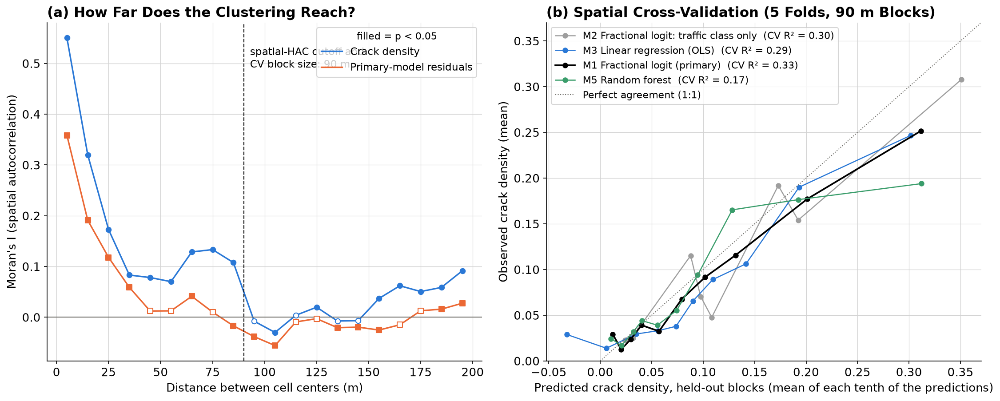

In [81]:
# ---------------------------------------------------------------------
# 05.3 (Step I) — FigS09 (supplementary): model evaluation, spatial autocorrelation (a) and spatially cross-validated predictions (b)
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
fig_banner("FigS09", is_map=False)
print("Figure: model evaluation -- spatial autocorrelation (a) and spatially cross-validated predictions (b) "
      "(supplementary)")
# Two panels side by side
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15, 6.2), dpi=FIG_DPI)
# (a) correlograms of crack density and of the primary-model residuals; filled markers = |z| > 1.96 (p < 0.05)
# x = middle of each distance band
mids = (corr_crack["band_lo_m"] + corr_crack["band_hi_m"]) / 2
for df_, lab, col, mk in ((corr_crack, "Crack density", "#2a78d6", "o"), (corr_res, "Primary-model residuals", ACCENT_COLOR, "s")):
    # Line through all bands; filled markers where significant, open (white) markers elsewhere (~sig = not significant)
    sig = df_["z"].abs() > 1.96
    ax_a.plot(mids, df_["moran_I"], color=col, linewidth=1.6, label=lab)
    ax_a.scatter(mids[sig], df_["moran_I"][sig], color=col, marker=mk, s=30, zorder=3)
    ax_a.scatter(mids[~sig], df_["moran_I"][~sig], facecolor="white", edgecolor=col, marker=mk, s=30, zorder=3)
# Zero line (no clustering) and the HAC cutoff (dashed), with its label near the top
ax_a.axhline(0, color=REF_COLOR, linewidth=1)
ax_a.axvline(HAC_CUT, color="black", linestyle="--", linewidth=1)
ax_a.text(HAC_CUT, ax_a.get_ylim()[1] * 0.92, f"  spatial-HAC cutoff and\n  CV block size: {HAC_CUT:.0f} m", fontsize=fs(9), va="top")
ax_a.set_xlabel("Distance between cell centers (m)")
ax_a.set_ylabel("Moran's I (spatial autocorrelation)")
ax_a.set_title("(a) How Far Does the Clustering Reach?", fontweight="bold", loc="left")
ax_a.legend(loc="upper right", fontsize=fs(9), title="filled = p < 0.05", title_fontsize=fs(8.5))
style_ax(ax_a)
# (b) spatial-CV calibration: mean observed vs mean predicted crack density in tenths of the predictions
# Models drawn in (b) and their colors
CAL_MODELS = {"M2": "#9e9e9e", "M3": "#2a78d6", "M1": "black", "M5": "#3a9d6b"}
for m, col in CAL_MODELS.items():
    # pd.qcut splits the predictions into 10 equal-count groups; mean prediction and mean observation of each group
    q = pd.qcut(OOF[m], 10, duplicates="drop")
    cal = pd.DataFrame({"p": OOF[m], "o": y_all}).groupby(q, observed=True).mean()
    ax_b.plot(cal["p"], cal["o"], "o-", color=col, linewidth=1.8 if m == "M1" else 1.2, markersize=5,
              label=f"{MODELS[m]['label']}  (CV R² = {model_tbl.loc[MODELS[m]['label'], 'R2 (spatial CV)']:.2f})")
# 1:1 line (perfect agreement) and equal axis ranges
_lim = max(ax_b.get_xlim()[1], ax_b.get_ylim()[1])
ax_b.plot([0, _lim], [0, _lim], color=REF_COLOR, linestyle=":", linewidth=1, label="Perfect agreement (1:1)")
ax_b.set_xlim(min(0, ax_b.get_xlim()[0]), _lim); ax_b.set_ylim(0, _lim)
ax_b.set_xlabel("Predicted crack density, held-out blocks (mean of each tenth of the predictions)")
ax_b.set_ylabel("Observed crack density (mean)")
ax_b.set_title(f"(b) Spatial Cross-Validation ({n_folds} Folds, {CV_B:.0f} m Blocks)", fontweight="bold", loc="left")
ax_b.legend(loc="upper left", fontsize=fs(8.5))
style_ax(ax_b)
plt.tight_layout()
save_fig(fig, "FigS09_Model_Evaluation", "supp")
plt.show()
chart_fonts(False)                     # back to the default fonts

**What the supplementary figure (FigS09) shows.** (a) Crack density is strongly clustered over short distances, and the clustering fades with distance. The primary model's residuals are less clustered but not independent; the distance at which their correlogram reaches zero sets both the spatial HAC cutoff and the CV block size (90 m in the author's run). (b) When whole blocks are held out, a model whose points rise along the 1:1 line ranks the cells correctly and is well calibrated; a flatter or more irregular curve means the model separates the most from the least cracked cells less well. M1 had the highest CV R² (0.33), and the random forest (0.17) was the least well calibrated on held-out blocks. The figure is supplementary because its numbers are in the evaluation table (Step F); it shows *why* the HAC cutoff and the block size were chosen.

### 05.4 Fitted Relationship (Fig05)

The primary model drawn over the cells it was fitted to: one curve per traffic/surface class, the curve averaged over all cells, and eq. (2) with its fitted coefficients under the legend.

**The "mean of each tenth of the cells" (orange diamonds).** The cells are sorted by log₁₀(*F*) and cut into ten groups of (nearly) equal count (`pd.qcut`); each diamond is a group's mean *F* (x) and mean crack density (y), with a 95% CI of ± 1.96 SE of that mean. They form a model-free check of the curve, a "binned scatter plot" (Cattaneo et al., 2024). **They are not used to fit the model:** the model is fitted to all cells individually (05.3), so its curve need not pass through the diamonds. The diamonds also mix traffic classes in different proportions from one tenth to the next, while the black curve keeps each cell's class fixed and changes only its flood frequency.

Figure: fractional logit model -- crack density vs. flood frequency (cells by traffic / surface class, model curves, and the model equation)


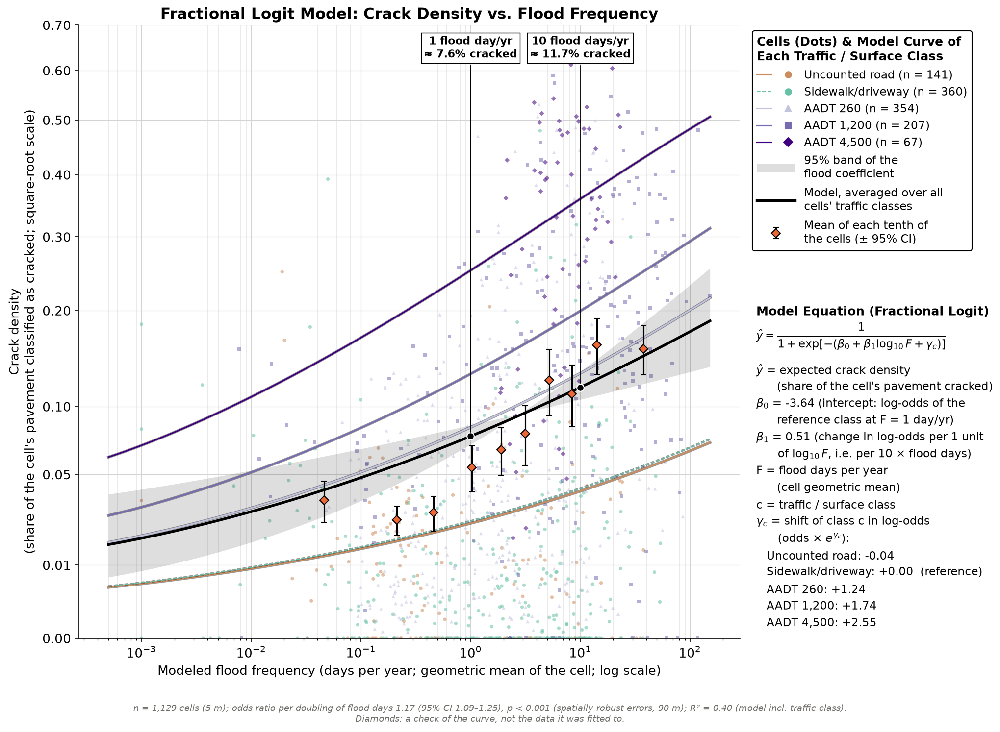

In [82]:
# ---------------------------------------------------------------------
# 05.4 (Step A) — Fig05: fractional logit model, crack density vs. flood frequency, with the model equation
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
print("Figure: fractional logit model -- crack density vs. flood frequency (cells by traffic / surface class, model "
      "curves, and the model equation)")
# One chart; flood days below 0.001 are drawn at 0.001 (log axis)
fig, ax = plt.subplots(figsize=(13.5, 10.0), dpi=FIG_DPI)
x_days = d_mod["FloodDaysGeo"].clip(lower=1e-3)
SCATTER_SIZE = 12                                       # marker area (points^2) of the cell dots
for cls in tc_order:                                   # cells: one color and marker shape per traffic class
    s = d_mod["TrafficClass"] == cls
    ax.scatter(x_days[s], d_mod.loc[s, "CrackDens"], s=SCATTER_SIZE, alpha=0.55, color=CLASS_COLORS[cls],
               marker=CLASS_MARKERS[cls], edgecolors="none", zorder=2)
# 120 log10 flood-day values across the data (grid_x) and the same in days (gd)
grid_x = np.linspace(x_obs.min(), x_obs.max(), 120)
gd = 10 ** grid_x - LOG_FD_OFFSET_DAYS
# Intercept of the primary model (beta_0 of eq. 2)
BETA_0 = float(fit_p["params"][fit_p["cols"].index("const")])
# gamma_c of each class = its traffic-class coefficient (eq. 2; 0 for the reference class)
GAMMA_C = {c: (float(fit_p["params"][fit_p["cols"].index(f"TC[{c}]")]) if f"TC[{c}]" in fit_p["cols"] else 0.0)
         for c in tc_order}
CLASS_LW = {c: (1.0 if c == "Sidewalk/driveway" else 1.5) for c in tc_order}     # sidewalk line thinnest ...
CLASS_LS = {c: ("--" if c == "Sidewalk/driveway" else "-") for c in tc_order}     # ... and dashed
for cls in tc_order:                                   # model curve of each traffic class
    (ln_,) = ax.plot(gd, expit(BETA_0 + GAMMA_C[cls] + BETA_1 * grid_x), color=CLASS_COLORS[cls], linewidth=CLASS_LW[cls],
                     linestyle=CLASS_LS[cls], zorder=4)
    ln_.set_path_effects([pe.Stroke(linewidth=CLASS_LW[cls] + 1.3, foreground="#333333", alpha=0.5), pe.Normal()])
# Average model curve, and the same with the flood coefficient at the ends of its 95 % CI (the band)
curve = np.array([average_prediction(g_) for g_ in grid_x])
lo = np.array([average_prediction(g_, BETA_1 - 1.96 * SE_BETA_1) for g_ in grid_x])
hi = np.array([average_prediction(g_, BETA_1 + 1.96 * SE_BETA_1) for g_ in grid_x])
ax.fill_between(gd, np.minimum(lo, hi), np.maximum(lo, hi), color="black", alpha=0.13, linewidth=0, zorder=3,
                label="95% band of the\nflood coefficient")
ax.plot(gd, curve, color="black", linewidth=2.6, zorder=5, label="Model, averaged over all\ncells' traffic classes")
# Decile means of the cells (ten equal-count groups of flood days) with 95% confidence intervals: a check, not the fit.
# pd.qcut: ten equal-count groups of cells by flood days; their mean flood days, mean crack density, and 95 % CI (1.96 x
# SE)
dec = d_mod.groupby(pd.qcut(d_mod["LogFloodDays"], 10, duplicates="drop"), observed=True)
ax.errorbar(10 ** dec["LogFloodDays"].mean() - LOG_FD_OFFSET_DAYS, dec["CrackDens"].mean(), yerr=1.96 * dec["CrackDens"].sem(),
            fmt="D", markersize=6, color=ACCENT_COLOR, markeredgecolor="black", ecolor="black", capsize=3, zorder=6,
            label="Mean of each tenth of\nthe cells (± 95% CI)")
# Top of the y axis: FIG05_YMAX, or higher if a cell is more cracked
y_top = max(FIG05_YMAX, CRACK_MAX * 1.02)
for d_ in HEADLINE_FLOOD_DAYS:                         # headline points on the average curve, callouts near the top
    v = HEAD[d_]
    ax.plot([d_], [v], "o", color="black", markersize=7, markeredgecolor="white", zorder=7)
    ax.annotate(f"{d_:g} flood day{'s' if d_ != 1 else ''}/yr\n≈ {100 * v:.1f}% cracked", xy=(d_, v),
                xytext=(d_, FIG05_CALLOUT_Y), textcoords="data", ha="center", va="bottom", fontsize=fs(8.5),
                fontweight="bold", zorder=8, arrowprops=dict(arrowstyle="-", color="black", linewidth=0.8, shrinkB=4),
                bbox=dict(boxstyle="square,pad=0.2", facecolor="white", edgecolor="black", linewidth=0.7))
# Log x axis; optional square-root y axis (set_yscale("function") takes the forward and inverse functions)
ax.set_xscale("log")
if CRACK_AXIS_SCALE == "sqrt":                         # square-root axis: spreads out the many low values
    ax.set_yscale("function", functions=(lambda v: np.sqrt(np.clip(v, 0, None)), lambda v: np.square(v)))
    ax.set_yticks([t for t in (0, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7) if t <= y_top])
# Axis labels and title
ax.set_ylim(0, y_top)
ax.set_xlabel("Modeled flood frequency (days per year; geometric mean of the cell; log scale)")
ax.set_ylabel("Crack density\n(share of the cell's pavement classified as cracked"
              + ("; square-root scale)" if CRACK_AXIS_SCALE == "sqrt" else ")"))
ax.set_title("Fractional Logit Model: Crack Density vs. Flood Frequency", fontweight="bold")
style_ax(ax)
# Light minor grid lines between the powers of ten on the x axis
ax.grid(which="minor", axis="x", color=GRID_COLOR, linewidth=0.4)
# Legend: a bold title, then each class as its line symbol NEXT TO its point symbol (tuple handles drawn side by side
# by HandlerTuple), then the band, the average curve, and the decile means.
_h, _l = ax.get_legend_handles_labels()
cls_h = [(mlines.Line2D([], [], color=CLASS_COLORS[c], linewidth=CLASS_LW[c], linestyle=CLASS_LS[c]),
          mlines.Line2D([], [], color=CLASS_COLORS[c], marker=CLASS_MARKERS[c], linestyle="none", markersize=6))
         for c in tc_order]
# Legend labels with the number of cells of each class
cls_l = [f"{c} (n = {int((d_mod['TrafficClass'] == c).sum())})" for c in tc_order]
# HandlerTuple(ndivide=None, pad=0.9) draws the two symbols of a tuple side by side
leg = ax.legend(cls_h + _h, cls_l + _l, title="Cells (Dots) & Model Curve of\nEach Traffic / Surface Class",
                handler_map={tuple: HandlerTuple(ndivide=None, pad=0.9)}, handlelength=3.4, loc="upper left",
                bbox_to_anchor=(1.01, 1.0), fontsize=fs(8.8), title_fontsize=fs(9.5), alignment="left", framealpha=1,
                edgecolor="black")
leg.get_title().set_fontweight("bold")
# Note centered at the bottom of the figure (multialignment centers both lines)
_note = fig.text(0.5, 0.005, f"n = {len(d_mod):,} cells ({FISHNET_CELL_M} m); odds ratio per doubling of flood days "
                 f"{np.exp(BETA_1 * LOG10_2):.2f} (95% CI {key_model.iloc[6]:.2f}–{key_model.iloc[7]:.2f}), {fmt_p(P_BETA_1)} "
                 f"(spatially robust errors, {HAC_CUT:.0f} m); R² = {key_model['R2 (in-sample, scikit-learn)']:.2f} "
                 f"(model incl. traffic class).\nDiamonds: a check of the curve, not the data it was fitted to.",
                 fontsize=8.5, style="italic", color=REF_COLOR, ha="center", va="bottom", multialignment="center")
plt.tight_layout(rect=[0, 0.05, 1, 1])                 # leaves room at the bottom for the centered note
# The model equation, written under the legend (its position is known only after the figure is drawn once).
fig.canvas.draw()
# transformed(fig.transFigure.inverted()) converts pixels into figure fractions
_bb = leg.get_window_extent().transformed(fig.transFigure.inverted())     # legend box in figure fractions
# Equation and its terms; rf"..." is a raw f-string (backslashes kept, {values} filled in; {{ }} = a literal brace)
# Long descriptions are wrapped onto an indented second line, so the text is no wider than the legend
_eq = [r"$\hat{y} = \dfrac{1}{1 + \exp[-(\beta_0 + \beta_1 \log_{10} F + \gamma_c)]}$", "",
       r"$\hat{y}$ = expected crack density",
       "      (share of the cell's pavement cracked)",
       rf"$\beta_0$ = {BETA_0:.2f} (intercept: log-odds of the",
       "      reference class at F = 1 day/yr)",
       rf"$\beta_1$ = {BETA_1:.2f} (change in log-odds per 1 unit",
       r"      of $\log_{10} F$, i.e. per 10 × flood days)",
       "F = flood days per year",
       "      (cell geometric mean)",
       "c = traffic / surface class",
       r"$\gamma_c$ = shift of class c in log-odds",
       r"      (odds × $e^{\gamma_c}$):"]
# One line per class with its gamma
_eq += [f"   {c}: {GAMMA_C[c]:+.2f}" + ("  (reference)" if c == REF_CLASS else "") for c in tc_order]
# Heading and equation lines just below the legend box
fig.text(_bb.x0 + 0.004, _bb.y0 - 0.075, "Model Equation (Fractional Logit)", fontsize=fs(9.5), fontweight="bold", va="top")
fig.text(_bb.x0 + 0.004, _bb.y0 - 0.105, "\n".join(_eq), fontsize=fs(8.8), va="top", linespacing=1.5)
save_fig(fig, "Fig05_CrackDensity_vs_FloodDays_Model", "methods")
plt.show()
chart_fonts(False)                     # back to the default fonts

**What the figure shows.** Each dot is a 5 m cell, colored (and shaped) by its traffic class. Each colored curve is the model of one class (the sidewalk/driveway curve is the thin dashed one), and the thick black curve is the model averaged over all cells' classes, with the 95% band of β₁. In the equation under the legend, β₀ and β₁ are shared by all cells, and each class adds its own γ_c to the log-odds, which moves the class curves up or down. In the author's run, the average curve rose from about 8% cracked at 1 flood day/yr to about 12% at 10 flood days/yr (the two callouts). The orange diamonds rise with flood frequency and lie close to the black curve, apart from the lowest tenths, which sit slightly below it. The scatter is wide because single cells vary a lot (and the square-root axis spreads out the low values), but the curve rises within every traffic class: more frequently flooded pavement is more cracked on the same road types. The busiest class sits highest, which is why the cells form color bands.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 06) Projected Crack Density (2040–2080)

**A thought experiment:** *If nothing about the roads changed except how often they flood, how much more cracking would the 2025 relationship imply in each cell?* The projection years are 2040, 2060, and 2080 (03.1 explains why 2100 is left out).

**From the fractional logit to the projected crack density** (eqs. (2) and (3); see **Symbols**). In eq. (3), *μ* denotes the model value of eq. (2), to keep it apart from the observed (*y*) and the projected (*ŷ**) crack density.

1. **The model gives an expected share.** The fractional logit (05.3) models the *expected* crack density of a cell, not a crack/no-crack outcome. For cell *i* with flood frequency *F*_i and traffic/surface class *c*(i):

   `μ_i = 1 / (1 + e^(−η_i))`, with the linear predictor `η_i = β₀ + β₁·log₁₀(F_i) + γ_c(i)` (eq. (2)).

   The logistic function is the inverse of the logit link, so *μ* always lies between 0 and 1 (McCullagh & Nelder, 1989). Because the model is fitted by quasi-likelihood, the only assumption is that this *mean* equation is right, so *μ*_i is exactly what the model estimates: the expected share of a cell's pavement that is cracked (Papke & Wooldridge, 1996; Wooldridge, 2010).
2. **Only flood frequency changes.** In year *t*, the cell's flood frequency becomes *F*_(i,t) (eq. (1) with that year's *RSLR*_t); its class, and everything else, stays as in 2025. Because η is linear in log₁₀(*F*), the new linear predictor is `η_i + β₁·Δ_(i,t)`, with `Δ_(i,t) = log₁₀(F_(i,t)) − log₁₀(F_(i,2025))`, and

   `μ_(i,t) = 1 / (1 + e^(−(η_i + β₁·Δ_(i,t))))`.

   Using each cell's fitted η_i automatically keeps its traffic class and its 2025 exposure.
3. **What it means in odds.** The odds `μ / (1 − μ)` are multiplied by `e^(β₁·Δ)`: each tenfold increase in *F* multiplies the odds of cracking by e^β₁ (Hosmer et al., 2013). On the crack-density scale, the change depends on the starting point, because the curve's slope is `β₁·μ(1 − μ)`: the same rise in *F* adds more cracking where cracking is already common (up to *μ* = 0.5).
4. **Anchoring on the observed value ("delta change", eq. (3)).** The model does not reproduce each cell's observed crack density exactly; the difference is the cell's residual (its unmeasured local factors). The projection therefore adds only the model-implied *change* to the observed value:

   `ŷ*_(i,t) = min(1, max(0, y_(i,2025) + [μ_(i,t) − μ_(i,2025)]))`.

   This is the "delta change" approach of climate-impact studies, in which the model supplies the change and the observations the baseline (Hay et al., 2000); it assumes that each cell's residual stays as it was in 2025.
5. **Worked example (author's run).** A Mowbray Arch cell (AADT 260, γ = +1.24) that floods 1 day/yr in 2025 (log₁₀(*F*) = 0) has η = −3.64 + 1.24 = −2.40 and *μ* = 0.083. If it floods 100 days/yr in 2060 (Δ = 2), η = −2.40 + 0.51 × 2 = −1.38 and *μ* = 0.20, so 0.12 is added to its observed 2025 crack density.
6. **Uncertainty band:** the same calculation with β₁ ± 1.96 SE (spatial HAC; Conley, 1999). It covers the flood coefficient only, not the DEM, eq. (1), or the sea-level scenario.
7. **Extrapolation flag:** cells whose projected log₁₀(*F*) exceeds the largest value in the 2025 data are flagged (`EX_<year>` = 1); their projection extends the relationship beyond anything observed.

**Assumptions** (state them with any figure of these results): no maintenance or repaving, no aging other than what flooding adds, constant traffic, the NOAA (2017) Intermediate-High scenario, and a 2025 flood–cracking association that is causal and keeps its shape.

**06.1** projects every cell, **06.2** draws the projection summary (Fig06, a Methods figure), and **06.3** maps the Results: the cells' flood frequency (Fig07, with the raster version FigS10 for comparison) and the observed and projected crack density (Fig08).

Outputs: the projected values on the cell polygons (one field per year, ready for choropleth maps) in `DATA/03_Results_Data/OUT_DATA_NB01_Sec06_ProjectedCrackCells/`, as a GeoPackage and a CSV.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 06.1 Projection per Cell

Step A applies the equations above to every cell and projection year, builds the summary by year, and saves its image (TblS03); Step B summarizes the projection by traffic class; and Step C writes the projected cells.

In [83]:
# ---------------------------------------------------------------------
# 06.1 (Step A) — Project crack density for every cell and projection year; summary by year
# ---------------------------------------------------------------------
# Working table: each cell's class, observed crack density, and flood days of every year
proj = d_mod[["CellID", "TrafficClass", "SurfaceType", "AADT", "CrackDens"]
             + [f"FloodDaysGeo_{y}" for y in FLOOD_YEARS] + [f"LogFloodDays_{y}" for y in FLOOD_YEARS]].copy()
MU_2025 = MU_IN["M1"]                                   # mu_(i,2025): crack density from eq. (2) with the 2025 flood frequency
y_obs = proj["CrackDens"].values                         # y_(i,2025): observed crack density
LFD_FIT_MAX = float(x_obs.max())                        # largest log10 flood days in the fitted data
# Flood coefficient at the ends of its 95 % CI (for the uncertainty band)
BETA_1_LO, BETA_1_HI = BETA_1 - 1.96 * SE_BETA_1, BETA_1 + 1.96 * SE_BETA_1
# First summary row: 2025 as observed (no change)
summary_rows = [dict(Year=FLOOD_YEAR, RSLR_m=RSLR_BY_YEAR[FLOOD_YEAR], MeanFloodDays=proj[f"FloodDaysGeo_{FLOOD_YEAR}"].mean(),
                     MedianFloodDays=proj[f"FloodDaysGeo_{FLOOD_YEAR}"].median(),
                     Pct_ge30days=100 * (proj[f"FloodDaysGeo_{FLOOD_YEAR}"] >= 30).mean(),
                     Pct_ge182days=100 * (proj[f"FloodDaysGeo_{FLOOD_YEAR}"] >= DAYS_PER_YEAR / 2).mean(),
                     MeanCrack=proj["CrackDens"].mean(), MeanCrack_lo=proj["CrackDens"].mean(),
                     MeanCrack_hi=proj["CrackDens"].mean(), PctChange=0.0, PctExtrapolated=0.0)]
for y in PROJECTION_YEARS:
    # delta = change in log10 flood days since 2025 (each cell)
    delta = (proj[f"LogFloodDays_{y}"] - proj[f"LogFloodDays_{FLOOD_YEAR}"]).values
    # Eq. (3), delta change: y-hat*_(i,t) = observed y_(i,2025) + (mu_(i,t) - mu_(i,2025)), kept within 0-1;
    # central (Proj), low (Lo), and high (Hi) flood coefficient beta_1
    for tag, beta_1 in (("Proj", BETA_1), ("Lo", BETA_1_LO), ("Hi", BETA_1_HI)):
        mu_t = expit(ETA_HAT + beta_1 * delta)                        # mu_(i,t): eq. (2) with year t's flood frequency
        proj[f"Crack{tag}_{y}"] = np.clip(y_obs + mu_t - MU_2025, 0, 1)    # y-hat*_(i,t), eq. (3)
    proj[f"dCrack_{y}"] = proj[f"CrackProj_{y}"] - proj["CrackDens"]
    # 1 = the cell's flood days lie beyond the largest value of the 2025 data (extrapolated)
    proj[f"EX_{y}"] = (proj[f"LogFloodDays_{y}"] > LFD_FIT_MAX).astype(int)
    fd_y = proj[f"FloodDaysGeo_{y}"]
    # sorted() so the band's low end is always the smaller mean
    lo_hi = sorted([proj[f"CrackLo_{y}"].mean(), proj[f"CrackHi_{y}"].mean()])
    # Summary row of the projection year
    summary_rows.append(dict(Year=y, RSLR_m=RSLR_BY_YEAR[y], MeanFloodDays=fd_y.mean(), MedianFloodDays=fd_y.median(),
                             Pct_ge30days=100 * (fd_y >= 30).mean(), Pct_ge182days=100 * (fd_y >= DAYS_PER_YEAR / 2).mean(),
                             MeanCrack=proj[f"CrackProj_{y}"].mean(), MeanCrack_lo=lo_hi[0], MeanCrack_hi=lo_hi[1],
                             PctChange=100 * (proj[f"CrackProj_{y}"].mean() / proj["CrackDens"].mean() - 1),
                             PctExtrapolated=100 * proj[f"EX_{y}"].mean()))
proj_summary = pd.DataFrame(summary_rows).set_index("Year")
# Readable column names
proj_summary.columns = ["RSLR (m)", "Mean flood days/yr (cells)", "Median flood days/yr (cells)", "% cells >= 30 days/yr",
                        "% cells >= half the year", "Mean crack density", "Mean crack density, band low",
                        "Mean crack density, band high", "Change in mean crack density (%)", "% cells extrapolated"]
# Display: sea level 2 decimals, flood days and percentages 1, crack density 3
display(proj_summary.round(1).assign(**{"RSLR (m)": proj_summary["RSLR (m)"].round(2),
                                        **{c: proj_summary[c].round(3) for c in proj_summary.columns
                                           if c.startswith("Mean crack density")}}))
# Table image (TblS03): the summary by year, with the display precision of the table above
_img = pd.DataFrame(index=proj_summary.index.astype(str))
for c in proj_summary.columns:
    _fmt = "{:.2f}" if c == "RSLR (m)" else ("{:.3f}" if c.startswith("Mean crack density") else "{:.1f}")
    _img[c.replace(">=", "≥")] = [_fmt.format(v) for v in proj_summary[c]]
_img = _img.rename(columns={"RSLR (m)": "RSLR (m above NAVD88)", "Change in mean crack density (%)":
                            "Change in mean crack density since 2025 (%)"})
_img.index.name = "Year"
_hdr, _body = table_text(_img, head_wrap=14)
_tbl_path = save_table_fig([dict(header=_hdr, body=_body)], "TblS03_Projection_Summary",
               "Table S3. Projected Flood Frequency and Mean Crack Density of the Analysis Cells by Year",
               note=(f"NOAA (2017) Intermediate-High scenario (USACE, 2022). {FLOOD_YEAR} is observed; "
                     f"{', '.join(map(str, PROJECTION_YEARS))} are projected with eq. (3). Flood frequency = each cell's "
                     f"geometric-mean flood days per year (eq. 1). Band = eq. (3) with β₁ ± 1.96 SE (spatial HAC). "
                     f"'% cells extrapolated' = cells whose log₁₀ flood frequency exceeds the largest value observed "
                     f"in {FLOOD_YEAR}. n = {len(proj):,} cells."))

,RSLR (m),Mean flood days/yr (cells),Median flood days/yr (cells),% cells >= 30 days/yr,% cells >= half the year,Mean crack density,"Mean crack density, band low","Mean crack density, band high",Change in mean crack density (%),% cells extrapolated
Year,,,,,,,,,,
2025,0.26,7.7,2.4,6.1,0.0,0.084,0.084,0.084,0.0,0.0
2040,0.49,50.5,17.4,39.9,7.5,0.124,0.104,0.146,46.9,9.8
2060,0.90,244.2,353.9,87.5,64.7,0.182,0.129,0.249,116.1,67.5
2080,1.42,357.3,365.0,99.5,97.8,0.201,0.135,0.290,139.2,98.2


[table image] TblS03_Projection_Summary not saved (SAVE_SUPPLEMENTARY_FIGURES = False)


In [84]:
# ---------------------------------------------------------------------
# 06.1 (Step B) — Mean projected crack density by traffic / surface class
# ---------------------------------------------------------------------
# Mean projected crack density per traffic class (for Fig06)
proj_by_class = pd.DataFrame({y: proj.groupby("TrafficClass")["CrackDens" if y == FLOOD_YEAR else f"CrackProj_{y}"].mean()
                              for y in FLOOD_YEARS}).reindex(tc_order)
# rename_axis() labels the table's index
display(proj_by_class.round(3).rename_axis("Mean crack density by traffic class"))

,2025,2040,2060,2080
Mean crack density by traffic class,,,,
Uncounted road,0.021,0.034,0.062,0.080
Sidewalk/driveway,0.027,0.043,0.072,0.084
AADT 260,0.077,0.120,0.203,0.233
"AADT 1,200",0.166,0.237,0.307,0.329
"AADT 4,500",0.308,0.410,0.523,0.524


In [85]:
# ---------------------------------------------------------------------
# 06.1 (Step C) — Write the projected cells (GeoPackage layer with one field per year + CSV) and the summary
# ---------------------------------------------------------------------
# Save: projected values on the cell polygons (one field per year) + CSV + the summary table.
OUT06 = out_dir(6, "ProjectedCrackCells", results=True)
# Projection columns: names starting with CrackProj, CrackLo, CrackHi, dCrack, or EX (c.split("_")[0] = text before the
# first _)
proj_cols = [c for c in proj.columns if c.split("_")[0] in ("CrackProj", "CrackLo", "CrackHi", "dCrack", "EX")]
# merge() joins the projection columns to the cell polygons by CellID
proj_gdf = cells_gdf[["CellID", "TrafficClass", "SurfaceType", "AADT", "CrackDens", "geometry"]].merge(
    proj[["CellID"] + [f"FloodDaysGeo_{y}" for y in FLOOD_YEARS] + proj_cols], on="CellID", how="inner")
# Save the GeoPackage, the table (CSV, without geometry), and the summary
proj_gdf.to_file(OUT06 / f"ProjectedCrackDensity_{FISHNET_CELL_M}m.gpkg", layer="ProjectedCrackDensity", driver="GPKG")
proj_gdf.drop(columns="geometry").to_csv(OUT06 / f"ProjectedCrackDensity_{FISHNET_CELL_M}m.csv", index=False)
proj_summary.to_csv(OUT06 / "Projection_Summary.csv")
# Add the projected values to cells_gdf for the maps (Fig08)
cells_gdf = cells_gdf.merge(proj[["CellID"] + [f"CrackProj_{y}" for y in PROJECTION_YEARS]], on="CellID", how="left")
print(f"[06.1 C] projected {len(proj):,} cells for {PROJECTION_YEARS} -> {OUT06.relative_to(PROJECT)}")

[06.1 C] projected 1,129 cells for [2040, 2060, 2080] -> DATA\03_Results_Data\OUT_DATA_NB01_Sec06_ProjectedCrackCells


**What the tables show.** As flood frequency rises with sea level, the projected mean crack density rises decade by decade. In the author's run, it went from 0.084 (observed, 2025) to 0.124 in 2040 (+47%), 0.182 in 2060 (+116%), and 0.201 in 2080 (+139%); the band from the uncertainty of β₁ was 0.104–0.146 in 2040 and 0.135–0.290 in 2080. The increase is largest in absolute terms on the busiest streets (AADT 4,500: 0.308 → 0.524 by 2080), because the same change in the odds adds more cracking where cracking is already common. The rise slows after 2060 as most cells reach the 365-day cap. The extrapolated share grows from 10% of the cells in 2040 to 67% in 2060 and 98% in 2080, so the later years are the least certain.

### 06.2 Methods Figure: Projection Summary (Fig06)

The projection summarized by year: (a) the distribution of the cells' flood frequency and (b) the projected mean crack density with its uncertainty band, for all cells and for each traffic/surface class. It closes the Methods by showing how the fitted model of Fig05 turns the projected flood frequency into projected cracking.

Figure: projected flood days and mean crack density by year, 2025-2080


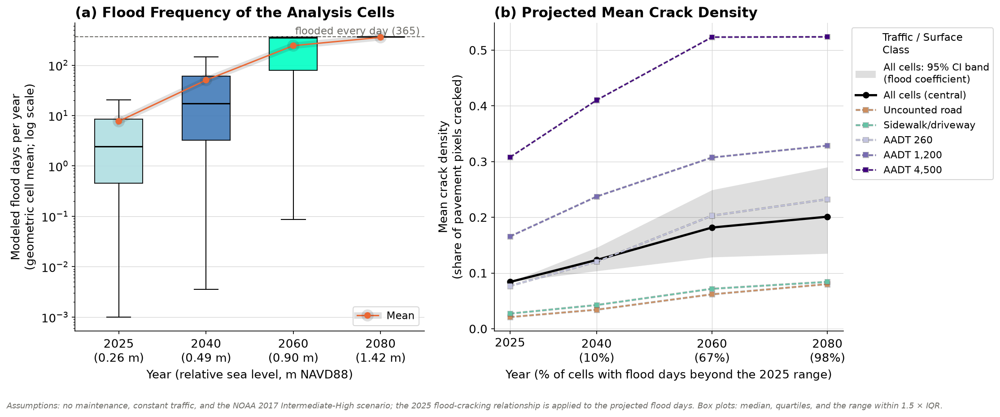

In [86]:
# ---------------------------------------------------------------------
# 06.2 (Step A) — Fig06: projected flood days (a) and mean crack density with its band (b), 2025-2080
# ---------------------------------------------------------------------
chart_fonts(True)                      # larger default fonts for this chart (maps unchanged)
print(f"Figure: projected flood days and mean crack density by year, {FLOOD_YEARS[0]}-{FLOOD_YEARS[-1]}")
# Two panels side by side
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15, 6.2), dpi=FIG_DPI)
# (a) distribution of the cell flood days per year (box plots; log axis), with the 365-day cap
_data = [proj[f"FloodDaysGeo_{y}"].clip(lower=1e-3).values for y in FLOOD_YEARS]
# Box plots without outliers (showfliers=False); patch_artist=True gives boxes that can be filled
bp = ax_a.boxplot(_data, showfliers=False, widths=0.55, patch_artist=True, medianprops=dict(color="black", linewidth=1.5))
# Fill each box with the flood-day class color of its median
for patch, y in zip(bp["boxes"], FLOOD_YEARS):
    patch.set_facecolor(FLOOD_CMAP(FLOOD_NORM(min(np.median(proj[f"FloodDaysGeo_{y}"]), DAYS_PER_YEAR - 1e-6))))
    patch.set_alpha(0.9)
# Mean of each year (orange points joined by a line), with a mostly transparent gray halo as in FigS08: the path
# effects draw a wide, faint gray stroke under the line and its markers (pe.Stroke), then the line itself (pe.Normal).
ax_a.plot(range(1, len(FLOOD_YEARS) + 1), [proj[f"FloodDaysGeo_{y}"].mean() for y in FLOOD_YEARS], "o-",
          color=ACCENT_COLOR, label="Mean", zorder=5,
          path_effects=[pe.Stroke(linewidth=7, foreground="#2b2b2b", alpha=0.15), pe.Normal()])
# 365-day cap: dashed line and label
ax_a.axhline(DAYS_PER_YEAR, color=REF_COLOR, linestyle="--", linewidth=1)
ax_a.text(len(FLOOD_YEARS) + 0.45, DAYS_PER_YEAR * 1.12, "flooded every day (365)", color=REF_COLOR, fontsize=fs(9), ha="right")
# Log y axis; x ticks = the years with their sea level
ax_a.set_yscale("log")
ax_a.set_xticks(range(1, len(FLOOD_YEARS) + 1))
ax_a.set_xticklabels([f"{y}\n({RSLR_BY_YEAR[y]:.2f} m)" for y in FLOOD_YEARS])
ax_a.set_xlabel("Year (relative sea level, m NAVD88)")
ax_a.set_ylabel("Modeled flood days per year\n(geometric cell mean; log scale)")
ax_a.set_title("(a) Flood Frequency of the Analysis Cells", fontweight="bold", loc="left")
ax_a.legend(loc="lower right", fontsize=fs(9))
style_ax(ax_a, "y")
# (b) mean projected crack density: all cells with the coefficient band, plus each traffic class
# All cells: 95 % band and central mean
ps = proj_summary
ax_b.fill_between(ps.index, ps["Mean crack density, band low"], ps["Mean crack density, band high"], color="black",
                  alpha=0.13, linewidth=0, label="All cells: 95% CI band\n(flood coefficient)")
ax_b.plot(ps.index, ps["Mean crack density"], "o-", color="black", linewidth=2.4, label="All cells (central)")
# One dashed line per traffic class, with a faint gray halo
for cls in tc_order:
    ax_b.plot(FLOOD_YEARS, proj_by_class.loc[cls].values, "s--", color=CLASS_COLORS[cls], linewidth=1.3, markersize=4,
              path_effects=[pe.Stroke(linewidth=2.4, foreground="#555555", alpha=0.4), pe.Normal()], label=cls)
# x tick labels: the year and the share of cells whose flood days are beyond the range observed in 2025
ax_b.set_xticks(FLOOD_YEARS)
ax_b.set_xticklabels([f"{FLOOD_YEAR}"] + [f"{y}\n({ps.loc[y, '% cells extrapolated']:.0f}%)" for y in PROJECTION_YEARS])
# Axis labels, title, and the legend outside the panel (right)
ax_b.set_xlabel("Year (% of cells with flood days beyond the 2025 range)")
ax_b.set_ylabel("Mean crack density\n(share of pavement pixels cracked)")
ax_b.set_title("(b) Projected Mean Crack Density", fontweight="bold", loc="left")
# The long band label is wrapped onto two lines (above), so the legend stays narrow and the charts stay wide
ax_b.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=fs(8.5), title="Traffic / Surface\nClass",
            title_fontsize=fs(9))
style_ax(ax_b)
# Assumptions note along the bottom; tight_layout leaves 4 % of the height for it
fig.text(0.01, 0.005, "Assumptions: no maintenance, constant traffic, and the NOAA 2017 Intermediate-High scenario; the 2025 "
         "flood-cracking relationship is applied to the projected flood days. Box plots: median, quartiles, and the "
         "range within 1.5 × IQR.", fontsize=8.5, style="italic", color=REF_COLOR)
plt.tight_layout(rect=[0, 0.04, 1, 1])
save_fig(fig, "Fig06_Projection_Summary", "methods")
plt.show()
chart_fonts(False)                     # back to the default fonts

**What the figure shows.** (a) The cells' flood frequency shifts upward by orders of magnitude between 2025 and 2080: in the author's run, the median cell goes from about 2 days/yr (2025) to about 17 (2040), 354 (2060), and the 365-day cap (2080). (b) The projected mean crack density rises with it; the band shows the uncertainty of β₁ alone. The busiest roads gain the most cracking in absolute terms. The percentages under the years give the share of cells beyond the flood frequency observed in 2025: the larger the share, the more the projection extrapolates.

### 06.3 Results Figures: Flood Frequency & Crack Density Maps (Fig07 & Fig08)

The two Results maps, both 2 × 2 panels of the analysis cells for 2025, 2040, 2060, and 2080, include a wide legend underneath: modeled flood frequency (Fig07; the classes and colors of the conference maps) and observed and projected crack density (Fig08). Fig08 uses crack-density *classes* on a reversed magma color ramp, a perceptually uniform ramp from light (little cracking) to dark (much cracking) that stays readable in grayscale and for color-blind readers (Crameri et al., 2020). Classes, rather than a continuous stretch, make the same breaks read identically on all four panels and in the report's ArcGIS Pro versions (Brewer & Pickle, 2002); `CRACK_MAP_STYLE = "stretch"` (00.3) draws a continuous color bar instead.

Step A defines the shared panel-map function; Step B draws the supplementary raster version of the flood-frequency maps (FigS10) for comparison; Step C draws Fig07; and Step D draws Fig08.

In [87]:
# ---------------------------------------------------------------------
# 06.3 (Step A) — Shared function for the 2 x 2 panel cell maps with a wide legend underneath (Fig07, Fig08, and FigS10)
# ---------------------------------------------------------------------
# _legend_box_height(): height (inches) the wide legend needs, measured on a throwaway figure of the same width
def _legend_box_height(legend_groups, cbar_label, width_in, pad_in=0.06):
    """Draw the wide legend in a tall temporary box, find the bottom of its lowest legend, and return the height from
    the top of the box to there (+ pad_in). With a color bar, at least 1.05 in (bar + its label)."""
    probe_h = 4.0
    tmp = plt.figure(figsize=(width_in, probe_h), dpi=100)
    ax = tmp.add_axes([0, 0, 1, 1])
    groups = legend_groups if cbar_label is None else [("", [], 1, legend_groups[0][3])] + list(legend_groups[1:])
    wide_legend(ax, groups)
    tmp.canvas.draw()
    r = tmp.canvas.get_renderer()
    # findobj() lists every Legend in the box; y0 = bottom edge of each in pixels (100 px per inch here)
    lows = [lg.get_window_extent(r).y0 for lg in ax.findobj(mlegend.Legend)]
    plt.close(tmp)
    need = (probe_h * 100 - min(lows)) / 100 + pad_in if lows else 1.0
    return max(need, 1.05) if cbar_label is not None else need


# cell_panel_maps(): 2 x 2 figure of cell maps (one per year) with a wide legend underneath
def cell_panel_maps(columns, titles, cmap, norm, legend_groups, fig_name, note=None, cbar_label=None, rasters=None):
    """2 x 2 figure, taller than wide: one rotated cell map per column (4 years), with the legend in a wide, short box
    underneath (as on the conference poster). legend_groups = list of (title, items, ncol, width share), see
    wide_legend. cbar_label = draw the first group as a continuous color bar with this label instead of class swatches.
    rasters = optional list of 0.5 m arrays (one per panel, on the G_EXTENT grid) drawn instead of the cells."""
    # Layout (inches): page width, side margins, and the gap between the two map columns; each map's height follows from
    # its width and the study area's shape
    a = site_aspect(5)
    W, side, gap_x = 9.0, 0.08, 0.12                         # inches
    col_w = (W - 2 * side - gap_x) / 2
    map_h = col_w / a
    t_h, gap_y, note_h = 0.34, 0.04, 0.3                       # title height, row gap (small), note
    leg_h = _legend_box_height(legend_groups, cbar_label, W - 2 * side)   # legend box: just tall enough
    # Figure height = two rows of (title + map) + gaps + legend + note
    H = 2 * (t_h + map_h) + gap_y + 0.12 + leg_h + note_h
    if H < 1.03 * W:                     # keep the figure taller than wide by narrowing it (slightly smaller maps)
        K = gap_y + 0.12 + leg_h + note_h
        W = max(8.0, (2 * t_h + K - (2 * side + gap_x) / a) / (1.03 - 1 / a)) if a > 1 / 1.03 else W
        col_w = (W - 2 * side - gap_x) / 2            # (a very wide study area could still end up slightly wider)
        map_h = col_w / a
        H = 2 * (t_h + map_h) + K
    # One map per column of cells_gdf (one per year)
    fig = plt.figure(figsize=(W, H), dpi=FIG_DPI)
    for k, (col, title) in enumerate(zip(columns, titles)):
        r, c = divmod(k, 2)                                  # divmod(k, 2) = (row, column) of panel k
        # Position of panel k: left edge from its column, bottom edge from its row (row 0 on top)
        left = side + c * (col_w + gap_x)
        bottom = note_h + leg_h + 0.12 + (1 - r) * (map_h + t_h + gap_y)
        ax = fig.add_axes([left / W, bottom / H, col_w / W, map_h / H])
        map_background(ax, imagery_alpha=0.95, excluded=True)
        if rasters is not None:          # raster panel: the 0.5 m array, colored by the same classes (NaN = transparent)
            map_imshow(ax, rasters[k], G_EXTENT, cmap=cmap, norm=norm, zorder=4)
        else:
            # Color of every cell: norm() puts the value in its class (or on the ramp), cmap() turns that into a color;
            # nan_to_num/clip keep it in range
            v = cells_gdf[col].values.astype(float)
            fc = cmap(norm(np.clip(np.nan_to_num(v, nan=0.0), norm.vmin, norm.vmax)))      # one RGBA color per cell
            fc[~np.isfinite(v)] = mcolors.to_rgba("#d9d9d9")                                 # no value -> light gray
            rot_geoms(cells_gdf[["geometry"]]).plot(ax=ax, color=fc, edgecolor="#3a3a3a", linewidth=0.12, zorder=4)
        set_map_view(ax, FOOTPRINT, pad_m=5)
        finish_map(ax, title, fontsize=7, title_size=11.5, arrow_pt=PANEL_NORTH_ARROW_PT, max_frac=0.14, pad=0.2)
    # Wide legend box under the maps
    ax_leg = fig.add_axes([side / W, note_h / H, (W - 2 * side) / W, leg_h / H])
    if cbar_label is None:
        wide_legend(ax_leg, legend_groups)
    else:                                                    # continuous ("stretch") colors: a color bar + the layers
        wide_legend(ax_leg, [("", [], 1, legend_groups[0][3])] + list(legend_groups[1:]))
        # Color bar in the first group's share of the legend box (inset_axes uses fractions of ax_leg)
        share = legend_groups[0][3] / sum(g[3] for g in legend_groups)
        cax = ax_leg.inset_axes([0.05 * share, 0.42, 0.9 * share, 0.18])
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal", extend="max")
        cb.set_label(cbar_label, fontsize=10.5, fontweight="bold", labelpad=6)
        cax.xaxis.set_label_position("top")
    # Optional italic note at the very bottom
    if note:
        fig.text(0.5, 0.06 / H, note, ha="center", va="bottom", fontsize=8.5, style="italic", color=REF_COLOR)
    save_fig(fig, *fig_name)           # fig_name = (name, report section)
    plt.show()
print("[06.3 A] panel-map function ready")

[06.3 A] panel-map function ready


*** THIS IS SUPPLEMENTARY FIGURE S10. IT IS NOT IN THE MAIN PROJECT REPORT.
*** THIS IS A BASIC MAP FOR A VISUAL CHECK OF THE OUTPUTS SO FAR.
Map: modeled flood days per year, 0.5 m rasters, 2025, 2040, 2060, 2080 (supplementary visual check; compare with Fig07)


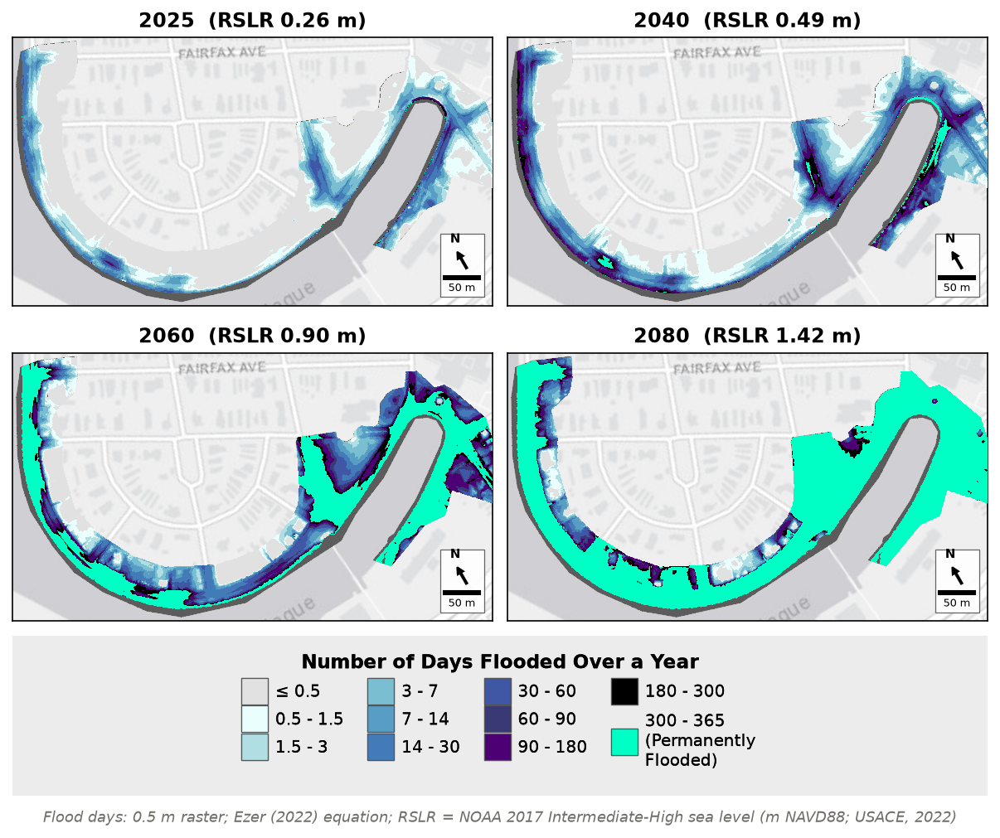

In [88]:
# ---------------------------------------------------------------------
# 06.3 (Step B) — FigS10 (supplementary visual check): the 0.5 m flood-days rasters, 2025, 2040, 2060, and 2080
# ---------------------------------------------------------------------
fig_banner("FigS10")
print(f"Map: modeled flood days per year, 0.5 m rasters, {', '.join(map(str, FLOOD_YEARS))} (supplementary visual check; "
      f"compare with Fig07)")
# Same layout, classes, and colors as Fig07, but each panel shows the year's 0.5 m flood-days raster (03.1) instead of
# the 5 m cells: every land pixel, not only the pavement. FLOOD[y] is the raster of year y (NaN = open water).
flood_items = [(c, l) for c, l in zip(FLOOD_CLASS_COLORS, FLOOD_LABELS)]
cell_panel_maps([None] * len(FLOOD_YEARS),
                [f"{y}  (RSLR {RSLR_BY_YEAR[y]:.2f} m)" for y in FLOOD_YEARS],
                FLOOD_CMAP, FLOOD_NORM,
                [("Number of Days Flooded Over a Year", flood_items, 4, 4.2)],     # (no map-layers entry)
                (f"FigS10_FloodDays_Rasters_{FLOOD_YEARS[0]}_{FLOOD_YEARS[-1]}", "supp"),
                note="Flood days: 0.5 m raster; Ezer (2022) equation; RSLR = NOAA 2017 Intermediate-High sea level (m NAVD88; USACE, 2022)",
                rasters=[FLOOD[y] for y in FLOOD_YEARS])

**What the supplementary maps (FigS10) show.** The 0.5 m flood-frequency rasters from which the cell values of Fig07 are averaged cover every land pixel of the study area, not only the pavement. The same low spots stand out on both, and the rasters show that the frequently flooded ground spreads from the shoreline and the low parts of the yards and the field, as well as along the streets. The cell maps (Fig07) are smoother because each cell is the geometric mean of only its pavement pixels. 

*** THIS IS A BASIC MAP FOR DEMONSTRATIVE PURPOSES. THE FINAL FIGURE 7 MAP IN THE PROJECT REPORT WILL LOOK DIFFERENT THAN BELOW.
Map: modeled flood days per year on the analysis cells, 2025, 2040, 2060, 2080


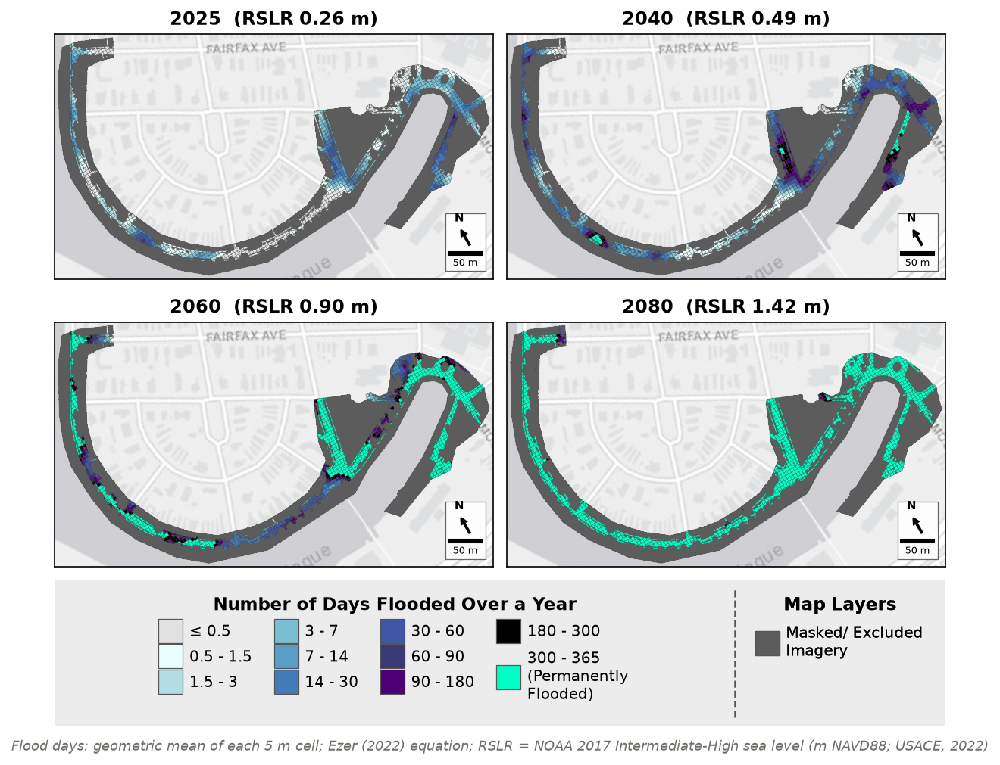

In [89]:
# ---------------------------------------------------------------------
# 06.3 (Step C) — Fig07: flood days per year on the analysis cells, 2025, 2040, 2060, and 2080
# ---------------------------------------------------------------------
fig_banner("Fig07")
print(f"Map: modeled flood days per year on the analysis cells, {', '.join(map(str, FLOOD_YEARS))}")
# Legend items: (color, label) of each flood-day class
flood_items = [(c, l) for c, l in zip(FLOOD_CLASS_COLORS, FLOOD_LABELS)]
# Arguments: the cell columns to map, the panel titles, the colors and classes, the legend groups (title, items,
# columns, width share), and the figure name and section
cell_panel_maps([f"FloodDaysGeo_{y}" for y in FLOOD_YEARS],
                [f"{y}  (RSLR {RSLR_BY_YEAR[y]:.2f} m)" for y in FLOOD_YEARS],
                FLOOD_CMAP, FLOOD_NORM,
                [("Number of Days Flooded Over a Year", flood_items, 4, 4.2),
                 ("Map Layers", [(MASK_COLOR, "Masked/ Excluded\nImagery")], 1, 1.3)],
                (f"Fig07_FloodDays_Cells_{FLOOD_YEARS[0]}_{FLOOD_YEARS[-1]}", "results"),
                note="Flood days: geometric mean of each 5 m cell; Ezer (2022) equation; RSLR = NOAA 2017 Intermediate-High sea level (m NAVD88; USACE, 2022)")

**What the maps show.** In 2025, the highest flood frequencies are in three places: Botetourt St along the west side of the field, near its intersection with Mowbray Arch; the streets around the Memorial Pl loop at the east end, including the southeastern street along the water; and a low spot on the western arc of Mowbray Arch. Most of the southern arc and the northern ends of the corridor are high ground (≤ 0.5 days/yr). As sea level rises, the same low spots flood first and most, and the frequently flooded area spreads outward along the streets. In the author's run, 40% of the cells flood at least 30 days/yr by 2040, 65% at least half the year by 2060, and almost every cell (98%) at least half the year by 2080, most of them in the top (300–365 days/yr) class. The cells' rankings stay the same; their flood frequencies shift upward together.

*** THIS IS A BASIC MAP FOR DEMONSTRATIVE PURPOSES. THE FINAL FIGURE 8 MAP IN THE PROJECT REPORT WILL LOOK DIFFERENT THAN BELOW.
Map: observed (2025) and projected (2040, 2060, 2080) crack density on the analysis cells


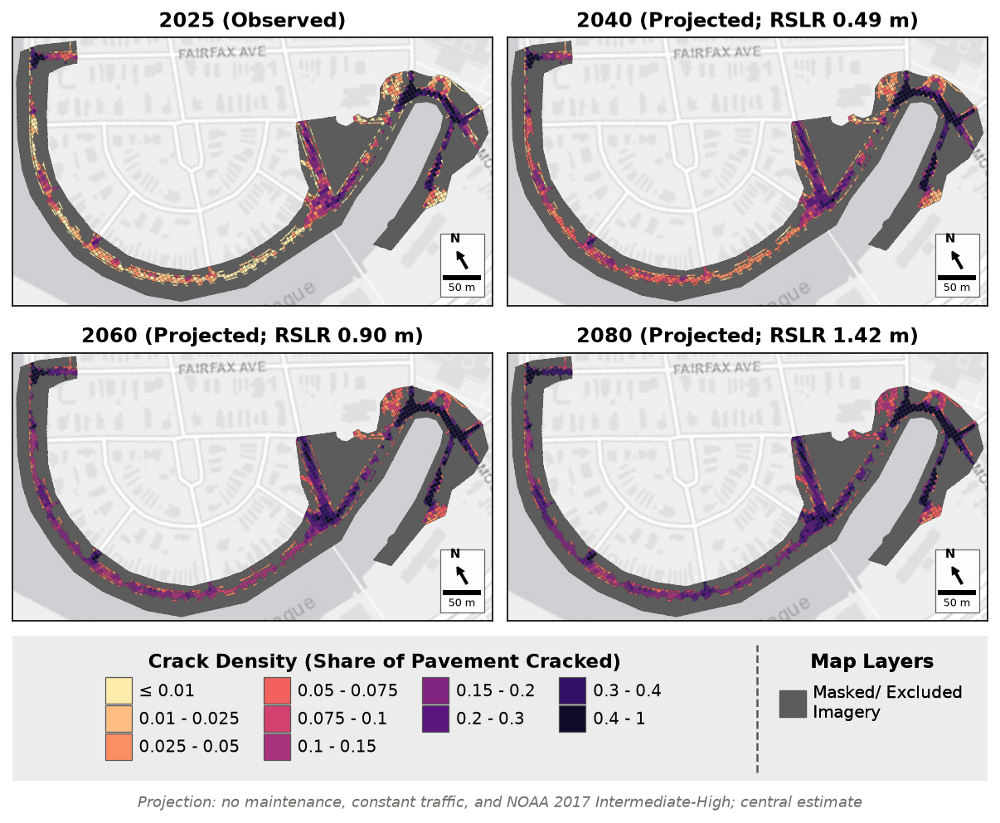

In [90]:
# ---------------------------------------------------------------------
# 06.3 (Step D) — Fig08: observed (2025) and projected (2040, 2060, and 2080) crack density on the analysis cells
# ---------------------------------------------------------------------
fig_banner("Fig08")
print(f"Map: observed ({FLOOD_YEAR}) and projected ({', '.join(map(str, PROJECTION_YEARS))}) crack density on the analysis cells")
cells_gdf[f"CrackProj_{FLOOD_YEAR}"] = cells_gdf["CrackDens"]          # 2025 panel = observed crack density
# Arguments shared by both color styles: the map-layers legend group, the figure name, and the note
_layers = ("Map Layers", [(MASK_COLOR, "Masked/ Excluded\nImagery")], 1, 1.3)
_args = dict(fig_name=("Fig08_CrackDensity_Observed_Projected", "results"),
             note="Projection: no maintenance, constant traffic, and NOAA 2017 Intermediate-High; central estimate")
# Cell columns and panel titles of the four years
_cols = [f"CrackProj_{y}" for y in FLOOD_YEARS]
_titles = [f"{FLOOD_YEAR} (Observed)"] + [f"{y} (Projected; RSLR {RSLR_BY_YEAR[y]:.2f} m)" for y in PROJECTION_YEARS]
if CRACK_MAP_STYLE == "stretch":                      # continuous colors with a color bar
    # **_args passes the shared keyword arguments of the dict
    cell_panel_maps(_cols, _titles, CRACK_STRETCH_CMAP, CRACK_STRETCH_NORM, [("", [], 1, 4.2), _layers],
                    cbar_label="Crack Density (Share of the Cell's Pavement Cracked)", **_args)
else:                                                 # classes (default)
    cell_panel_maps(_cols, _titles, CRACK_CMAP, CRACK_NORM,
                    [("Crack Density (Share of Pavement Cracked)", list(zip(CRACK_COLORS, CRACK_LABELS)), 4, 4.2),
                     _layers], **_args)

**What the maps show.** The 2025 panel (top left) is the observed crack density; 2040 (top right), 2060 (bottom left), and 2080 (bottom right) are projected. The projected maps keep the 2025 pattern because each cell starts from its own observed value. How much a cell changes depends on two things:

- **how much its flood frequency rises in relative terms** (the model works on log₁₀(*F*)): the low spots that already flood often gain little before they reach the 365-day cap, while higher ground that rarely floods today gains the most relative exposure by late century;
- **its starting crack density:** the same change in the odds adds more cracking where cracking is already common, i.e., on the busier streets.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 07) Summary & Conclusions

Step A collects the key numbers of this notebook, and Step B lists the files it wrote.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 07.1 Key Numbers & Outputs

The headline numbers of the analysis in one table, and a list of every data file this run wrote.

In [91]:
# ---------------------------------------------------------------------
# 07.1 (Step A) — Key numbers of this notebook
# ---------------------------------------------------------------------
KAPPA = acc_metrics["Cohen's kappa"]
# Key numbers as formatted text (one Series); key_model.iloc[k] = its k-th row (05.3 G); **{...} adds one entry per
# projection year
key = pd.Series({
    "Analysis cells (5 m, with flood days)": f"{len(d_mod):,}",
    "Pavement area (m2)": f"{TOTAL_MASK_PX * REF_RES ** 2:,.0f}",
    "Mean crack density, 2025 (observed)": f"{d_mod['CrackDens'].mean():.3f}",
    "Cells with no cracks (%)": f"{100 * (d_mod['CrackDens'] == 0).mean():.1f}",
    "Crack map: overall accuracy / Cohen's kappa": f"{acc_metrics['Overall accuracy']:.2f} / {KAPPA:.2f}",
    "Crack map: precision / recall / F1 (area-weighted)": (f"{acc_metrics['Area-weighted precision (crack)']:.2f} / "
                                                            f"{acc_metrics['Area-weighted recall (crack)']:.2f} / "
                                                            f"{acc_metrics['Area-weighted F1 (crack)']:.2f}"),
    f"Median flood days/yr per cell, {FLOOD_YEAR}": f"{d_mod['FloodDaysGeo'].median():.1f}",
    "Moran's I of crack density (k = 8)": f"{MORAN_CRACK:.2f}",
    "Flood coefficient β₁ (log-odds per 10× flood days)": f"{BETA_1:.2f} (SE {SE_BETA_1:.2f}, z = {Z_BETA_1:.1f}, {fmt_p(P_BETA_1)}, spatial HAC {HAC_CUT:.0f} m)",
    "Odds ratio per doubling of flood days (95% CI)": f"{key_model.iloc[5]:.2f} ({key_model.iloc[6]:.2f}–{key_model.iloc[7]:.2f})",
    "Average marginal effect per doubling (pp)": f"{key_model.iloc[8]:+.1f} ({key_model.iloc[9]:+.1f} to {key_model.iloc[10]:+.1f})",
    f"Expected crack density at {HEADLINE_FLOOD_DAYS[0]} vs {HEADLINE_FLOOD_DAYS[1]} flood days/yr":
        f"{HEAD[HEADLINE_FLOOD_DAYS[0]]:.3f} vs {HEAD[HEADLINE_FLOOD_DAYS[1]]:.3f}",
    # The primary model's row of the evaluation table, found by its label (M1)
    "Primary model R2: in-sample / spatial CV": f"{model_tbl.loc[MODELS['M1']['label'], 'R2 (in-sample)']:.3f} / "
                                                f"{model_tbl.loc[MODELS['M1']['label'], 'R2 (spatial CV)']:.3f}",
    "Primary model RMSE / MAE (spatial CV)": f"{model_tbl.loc[MODELS['M1']['label'], 'RMSE (spatial CV)']:.3f} / "
                                             f"{model_tbl.loc[MODELS['M1']['label'], 'MAE (spatial CV)']:.3f}",
    **{f"Mean crack density {y} (projected, band)":
       f"{proj_summary.loc[y, 'Mean crack density']:.3f} ({proj_summary.loc[y, 'Mean crack density, band low']:.3f}–"
       f"{proj_summary.loc[y, 'Mean crack density, band high']:.3f}); {proj_summary.loc[y, 'Change in mean crack density (%)']:+.1f} %"
       for y in PROJECTION_YEARS},
}, name="value")
# Save as CSV and show
OUT07 = out_dir(7, "Summary", results=True)
key.to_csv(OUT07 / "KeyNumbers.csv")
display(key.to_frame())

,value
"Analysis cells (5 m, with flood days)","1,129"
Pavement area (m2),"12,293"
"Mean crack density, 2025 (observed)",0.084
Cells with no cracks (%),18.7
Crack map: overall accuracy / Cohen's kappa,0.92 / 0.84
Crack map: precision / recall / F1 (area-weighted),0.93 / 0.60 / 0.73
"Median flood days/yr per cell, 2025",2.4
Moran's I of crack density (k = 8),0.54
Flood coefficient β₁ (log-odds per 10× flood days),"0.51 (SE 0.12, z = 4.2, p < 0.001, spatial HAC..."
Odds ratio per doubling of flood days (95% CI),1.17 (1.09–1.25)


In [92]:
# ---------------------------------------------------------------------
# 07.1 (Step B) — Files written by this run
# ---------------------------------------------------------------------
# Every file in this run's output folders: folder, file name, and size (st_size = bytes; / 1e6 = MB). Two "for" clauses
# in one list comprehension loop over the folders, then over the files of each
outputs = pd.DataFrame([(p.parent.name, p.name, f"{p.stat().st_size / 1e6:.2f} MB")
                        for d in sorted(list(OUT_CLEAN_ROOT.glob(f"OUT_DATA_{NB}_Sec*"))
                                        + list(OUT_RESULTS_ROOT.glob(f"OUT_DATA_{NB}_Sec*")))
                        for p in sorted(d.iterdir())], columns=["Folder", "File", "Size"])
print("Outputs of this run" + ("" if SAVE_DATA_OUTPUTS else " (NOT saved to DATA: SAVE_DATA_OUTPUTS = False)") + ":")
display(outputs)
# Where the figures went (or that they were not saved)
print("Report figures: " + ("saved to FIGURES/01_... to 03_..." if SAVE_REPORT_FIGURES else "not saved (SAVE_REPORT_FIGURES = False)")
      + "; supplementary figures: " + ("saved to FIGURES/04_Supplementary_Figures (table images: FIGURES/05_Supplementary_Tbl_Figs)"
                                        if SAVE_SUPPLEMENTARY_FIGURES
                                        else "not saved (SAVE_SUPPLEMENTARY_FIGURES = False)"))

Outputs of this run:


,Folder,File,Size
0,OUT_DATA_NB01_Sec01,Clean_Hague2025_NB01.gpkg,0.74 MB
1,OUT_DATA_NB01_Sec01,Crack_Count_0p5m.tif,0.05 MB
2,OUT_DATA_NB01_Sec01,CrackValid_Count_0p5m.tif,0.07 MB
3,OUT_DATA_NB01_Sec01,Datasets_Used.csv,0.00 MB
4,OUT_DATA_NB01_Sec01,DEM_MHHW_WtrHC_0p5m.tif,0.93 MB
5,OUT_DATA_NB01_Sec01,FloodDays_2025_0p5m.tif,0.99 MB
6,OUT_DATA_NB01_Sec01,Imagery_dry_Preview_0p32m.tif,1.54 MB
7,OUT_DATA_NB01_Sec01,RoadMask_Count_0p5m.tif,0.07 MB
8,OUT_DATA_NB01_Sec03_FloodDaysRasters,FloodDays_2025_0p5m.tif,0.99 MB
9,OUT_DATA_NB01_Sec03_FloodDaysRasters,FloodDays_2040_0p5m.tif,0.97 MB


Report figures: not saved (SAVE_REPORT_FIGURES = False); supplementary figures: not saved (SAVE_SUPPLEMENTARY_FIGURES = False)


**Conclusions.**

1. **Present-day relationship (2025).** After controlling for traffic/surface class, pavement that floods more often is more cracked. β₁ stays significant with spatially robust (Conley) SEs (in the author's run: odds ratio 1.17 per doubling of *F*, 95% CI 1.09–1.25, p < 0.001; expected crack density 0.076 at 1 vs. 0.117 at 10 flood days/yr on the same road types), so H₀ is rejected even without treating neighboring cells as independent. The effect per cell is modest next to traffic, the strongest single predictor of cracking.
2. **Model choice.** The model comparison (05.3; see the INTERPRETATION lines printed under the table) tests whether a curved (quadratic) term or a flexible random forest predicts held-out blocks better than the simple S-shaped relationship. In the author's run, neither did: M1 had the best CV R² (0.33), the quadratic term was not significant, and the random forest overfit (CV R² 0.17). I kept the fractional logit for the projection because it is interpretable, stays between 0 and 1, and, unlike the random forest, can be applied to higher future flood frequencies.
3. **Spatial autocorrelation.** Crack density is strongly clustered, which makes naive p-values overconfident; spatially robust errors and block CV address this. The clustering left in the residuals points to unmeasured, spatially smooth factors such as pavement age, repaving, and drainage, so the flood effect is an association, not proof of cause.
4. **Projections (2040–2080).** Under the NOAA (2017) Intermediate-High scenario, with no maintenance and constant traffic, the fitted relationship implies a steady rise in crack density as flood frequency increases (in the author's run, mean crack density 0.084 in 2025 → 0.124 in 2040, 0.182 in 2060, and 0.201 in 2080). The rise is largest on the busier streets, where cracking is already common, and on ground that rarely floods today but often by late century. Late-century values extrapolate beyond the 2025 data and approach the point where the streets flood most of the year (03.1), so they are an upper-end illustration, not a forecast.
   
- **Next steps:**
  - add measured confounders, if available (pavement age, repaving records, and tree canopy/ roots) 
  - compare other NOAA sea-level scenarios
  - include storm-drain backflow in the flood model/ improve DEM hydrocorrection
  - repeat the drone survey to measure change over time.
  - test crack classification DL + flood frequency workflow on other UAS-mapped sites

If you're reading this: Congrats! You made it to the end of the code. I'm very tired. -Nick